In [1]:
import pandas as pd
import numpy as np

file_11 = "11-Nov-2022_0900_1143.csv"
file_10 = "10-Nov-2022_1100_1200.csv"

df11 = pd.read_csv(file_11, low_memory=False)
df10 = pd.read_csv(file_10, low_memory=False)

df11.columns = df11.columns.str.strip()
df10.columns = df10.columns.str.strip()

df11["t_stamp"] = pd.to_datetime(df11["t_stamp"], format="%d-%b-%Y %H:%M:%S", errors="coerce")
df10["t_stamp"] = pd.to_datetime(df10["t_stamp"], format="%d-%b-%Y %H:%M:%S", errors="coerce")

print(df11.shape)
print(df10.shape)
print(df11.head())

(9829, 85)
(3601, 85)
              t_stamp   FIT101.Pv   LIT101.Pv  MV101.Status  P101.Status  \
0 2022-11-11 09:00:00  5.04115534    616.8178             2            2   
1 2022-11-11 09:00:01  5.04115534   617.83844             2            2   
2 2022-11-11 09:00:02  5.04115534   617.83844             2            2   
3 2022-11-11 09:00:03  5.04115534  618.466431             2            2   
4 2022-11-11 09:00:04  5.03090668  618.466431             2            2   

   P102.Status  P1_STATE   AIT201.Pv  AIT202.Pv   AIT203.Pv  ...  \
0            1         3  152.332733   7.031723  448.474762  ...   
1            1         3  152.332733   7.031723  448.474762  ...   
2            1         3  152.332733   7.031723  448.474762  ...   
3            1         3  152.332733   7.031723  448.628571  ...   
4            1         3  152.332733   7.031723  448.884900  ...   

   LSH601.Alarm LSH602.Alarm LSH603.Alarm LSL601.Alarm LSL602.Alarm  \
0      Inactive       Active     Inactive

In [2]:
def add_attack_labels(df, intervals):
    df = df.copy()
    df["attack_label"] = 0

    date = df["t_stamp"].dt.date.iloc[0]

    for start, end in intervals:
        start_dt = pd.to_datetime(f"{date} {start}")
        end_dt = pd.to_datetime(f"{date} {end}")

        mask = (df["t_stamp"] >= start_dt) & (df["t_stamp"] <= end_dt)
        df.loc[mask, "attack_label"] = 1

    return df


intervals_11 = [
    ("09:51:00", "09:55:00"),
    ("09:59:00", "10:01:00"),
    ("10:03:00", "10:05:00"),
    ("10:09:00", "10:12:00"),
    ("10:14:00", "10:17:00"),
    ("10:20:00", "10:22:00"),
    ("10:24:00", "10:26:00"),
    ("10:29:00", "10:32:00"),
    ("10:34:00", "10:37:00"),
    ("10:41:00", "10:44:00"),
    ("10:47:00", "10:50:00"),
    ("10:53:00", "10:56:00"),
    ("11:05:00", "11:08:00"),
    ("11:10:00", "11:13:00"),
    ("11:16:00", "11:19:00"),
    ("11:22:00", "11:25:00"),
    ("11:28:00", "11:31:00"),
]

intervals_10 = [
    ("11:03:00", "11:10:00"),
    ("11:25:00", "11:30:00"),
    ("11:34:00", "11:41:00"),
    ("11:45:00", "11:49:00"),
]

df11 = add_attack_labels(df11, intervals_11)
df10 = add_attack_labels(df10, intervals_10)

print(df11["attack_label"].value_counts())
print(df10["attack_label"].value_counts())

attack_label
0    6932
1    2897
Name: count, dtype: int64
attack_label
0    2217
1    1384
Name: count, dtype: int64


In [3]:
print("11 Nov time range:")
print(df11["t_stamp"].min(), "to", df11["t_stamp"].max())
percentage_11= df11["attack_label"].value_counts(normalize=True) * 100
print(percentage_11.map(lambda x: f"{x:.3f}%"))

print("\n10 Nov time range:")
print(df10["t_stamp"].min(), "to", df10["t_stamp"].max())
percentage_10= df10["attack_label"].value_counts(normalize=True) * 100
print(percentage_10.map(lambda x: f"{x:.3f}%"))

11 Nov time range:
2022-11-11 09:00:00 to 2022-11-11 11:43:48
attack_label
0    70.526%
1    29.474%
Name: proportion, dtype: object

10 Nov time range:
2022-11-10 11:00:00 to 2022-11-10 12:00:00
attack_label
0    61.566%
1    38.434%
Name: proportion, dtype: object


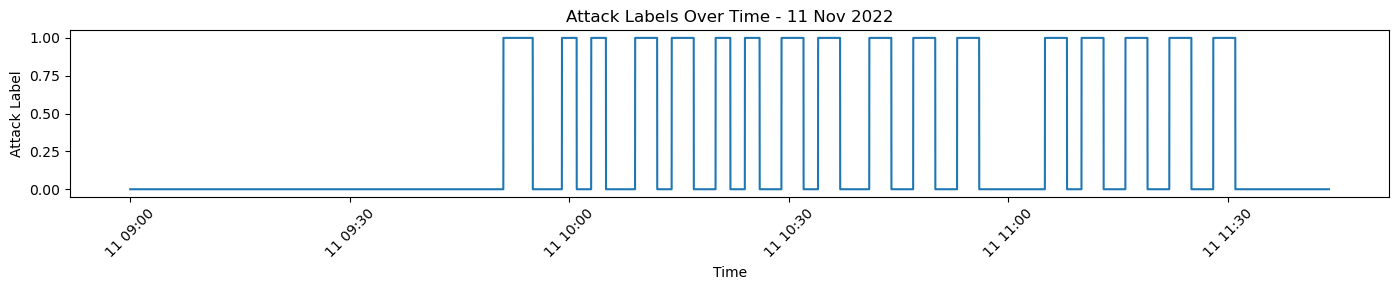

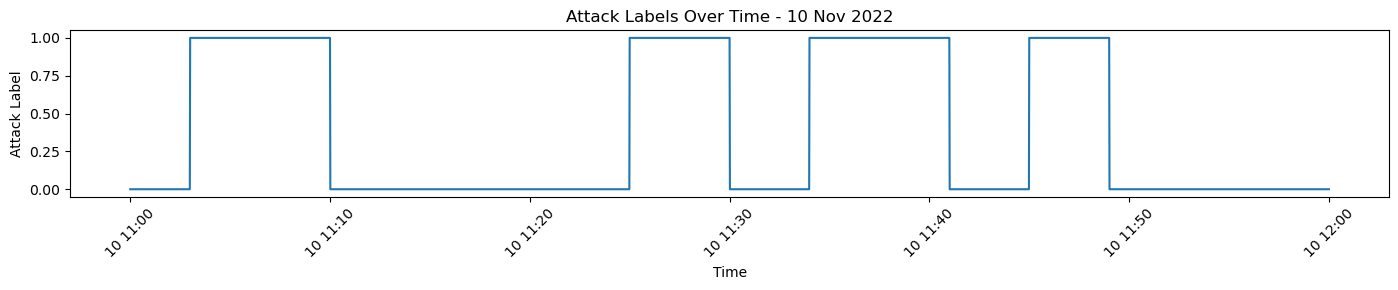

In [4]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 3))
plt.plot(df11["t_stamp"], df11["attack_label"])
plt.title("Attack Labels Over Time - 11 Nov 2022")
plt.xlabel("Time")
plt.ylabel("Attack Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 3))
plt.plot(df10["t_stamp"], df10["attack_label"])
plt.title("Attack Labels Over Time - 10 Nov 2022")
plt.xlabel("Time")
plt.ylabel("Attack Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [5]:
sensor_cols = [col for col in df11.columns if col.endswith(".Pv")]
status_cols = [col for col in df11.columns if col.endswith(".Status")]
alarm_cols = [col for col in df11.columns if col.endswith(".Alarm")]
state_cols = [col for col in df11.columns if "_STATE" in col]

print("Number of sensor columns:", len(sensor_cols))
print(sensor_cols)

print("\nNumber of status/actuator columns:", len(status_cols))
print(status_cols)

print("\nNumber of alarm columns:", len(alarm_cols))
print(alarm_cols)

print("\nNumber of state columns:", len(state_cols))
print(state_cols)

Number of sensor columns: 31
['FIT101.Pv', 'LIT101.Pv', 'AIT201.Pv', 'AIT202.Pv', 'AIT203.Pv', 'FIT201.Pv', 'AIT301.Pv', 'AIT302.Pv', 'AIT303.Pv', 'DPIT301.Pv', 'FIT301.Pv', 'LIT301.Pv', 'AIT401.Pv', 'AIT402.Pv', 'FIT401.Pv', 'LIT401.Pv', 'AIT501.Pv', 'AIT502.Pv', 'AIT503.Pv', 'AIT504.Pv', 'FIT501.Pv', 'FIT502.Pv', 'FIT503.Pv', 'FIT504.Pv', 'PIT501.Pv', 'PIT502.Pv', 'PIT503.Pv', 'FIT601.Pv', 'FIT602.Pv', 'LIT601.Pv', 'LIT602.Pv']

Number of status/actuator columns: 32
['MV101.Status', 'P101.Status', 'P102.Status', 'MV201.Status', 'P201.Status', 'P202.Status', 'P203.Status', 'P204.Status', 'P205.Status', 'P206.Status', 'P207.Status', 'P208.Status', 'MV301.Status', 'MV302.Status', 'MV303.Status', 'MV304.Status', 'P301.Status', 'P302.Status', 'P401.Status', 'P402.Status', 'P403.Status', 'P404.Status', 'UV401.Status', 'MV501.Status', 'MV502.Status', 'MV503.Status', 'MV504.Status', 'P501.Status', 'P502.Status', 'P601.Status', 'P602.Status', 'P603.Status']

Number of alarm columns: 15
['LS20

In [6]:
for col in sensor_cols:
    df11[col] = pd.to_numeric(df11[col], errors="coerce") 
    df10[col] = pd.to_numeric(df10[col], errors="coerce")

print("Missing values in 11 Nov sensor columns:")
print(df11[sensor_cols].isna().sum().sort_values(ascending=False).head(20)) 

print("\nMissing values in 10 Nov sensor columns:")
print(df10[sensor_cols].isna().sum().sort_values(ascending=False).head(20))

Missing values in 11 Nov sensor columns:
FIT101.Pv    2
LIT101.Pv    1
AIT501.Pv    0
LIT601.Pv    0
FIT602.Pv    0
FIT601.Pv    0
PIT503.Pv    0
PIT502.Pv    0
PIT501.Pv    0
FIT504.Pv    0
FIT503.Pv    0
FIT502.Pv    0
FIT501.Pv    0
AIT504.Pv    0
AIT503.Pv    0
AIT502.Pv    0
LIT401.Pv    0
FIT401.Pv    0
AIT402.Pv    0
AIT401.Pv    0
dtype: int64

Missing values in 10 Nov sensor columns:
FIT101.Pv    0
AIT501.Pv    0
LIT601.Pv    0
FIT602.Pv    0
FIT601.Pv    0
PIT503.Pv    0
PIT502.Pv    0
PIT501.Pv    0
FIT504.Pv    0
FIT503.Pv    0
FIT502.Pv    0
FIT501.Pv    0
AIT504.Pv    0
AIT503.Pv    0
AIT502.Pv    0
LIT401.Pv    0
LIT101.Pv    0
FIT401.Pv    0
AIT402.Pv    0
AIT401.Pv    0
dtype: int64


In [7]:
df11_clean = df11.dropna(subset=sensor_cols).copy()
df10_clean = df10.dropna(subset=sensor_cols).copy()

print("Original 11 Nov:", df11.shape)
print("Clean 11 Nov:", df11_clean.shape)

print("Original 10 Nov:", df10.shape)
print("Clean 10 Nov:", df10_clean.shape)

Original 11 Nov: (9829, 86)
Clean 11 Nov: (9827, 86)
Original 10 Nov: (3601, 86)
Clean 10 Nov: (3601, 86)


In [8]:
df11_clean.to_csv("swat_11nov_labelled_clean.csv", index=False)
df10_clean.to_csv("swat_10nov_labelled_clean.csv", index=False)

In [9]:
starter_sensors = [
    "LIT101.Pv",
    "FIT101.Pv",
    "FIT201.Pv",
    "LIT301.Pv",
    "AIT201.Pv",
    "AIT202.Pv",
    "AIT203.Pv",
    "PIT501.Pv",
    "LIT601.Pv",
    "LIT602.Pv"
]

available_starter_sensors = [col for col in starter_sensors if col in df11_clean.columns]
print(available_starter_sensors)

['LIT101.Pv', 'FIT101.Pv', 'FIT201.Pv', 'LIT301.Pv', 'AIT201.Pv', 'AIT202.Pv', 'AIT203.Pv', 'PIT501.Pv', 'LIT601.Pv', 'LIT602.Pv']


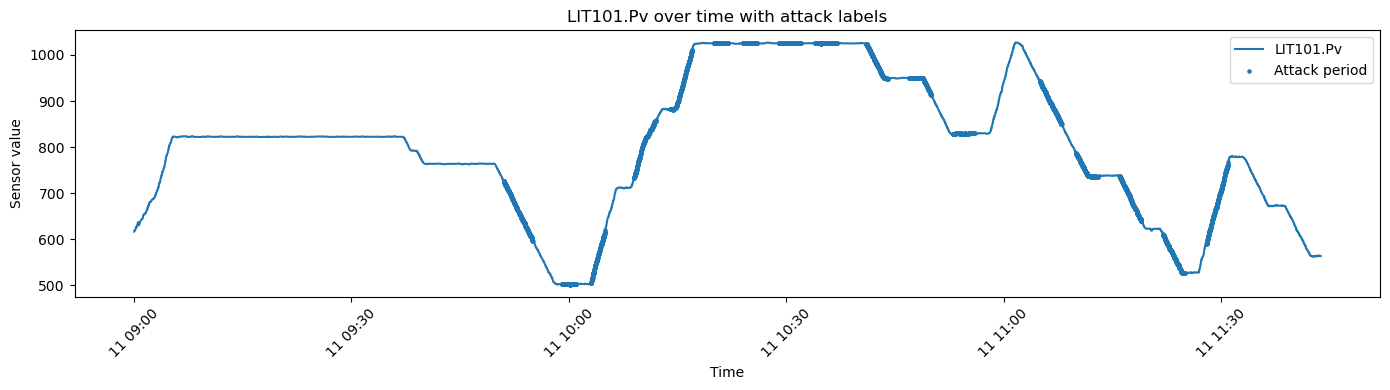

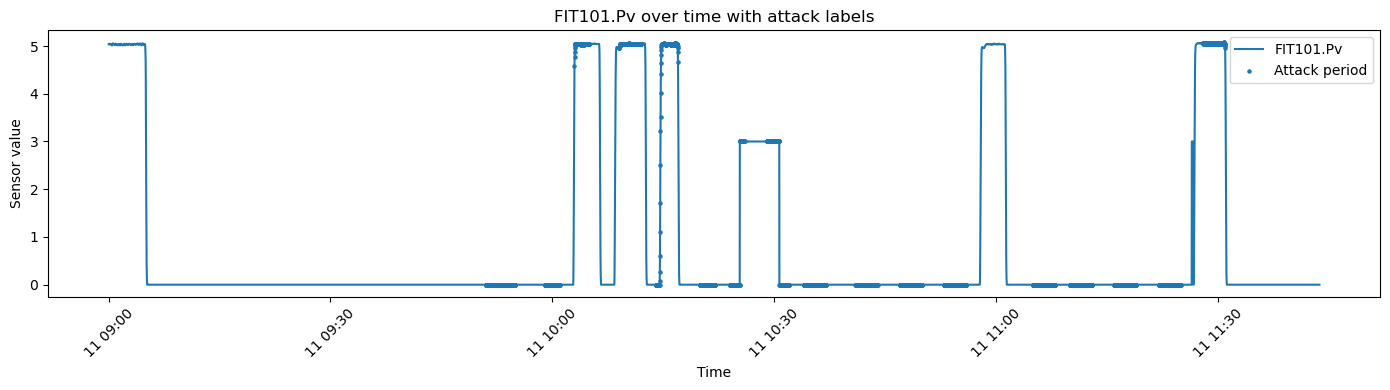

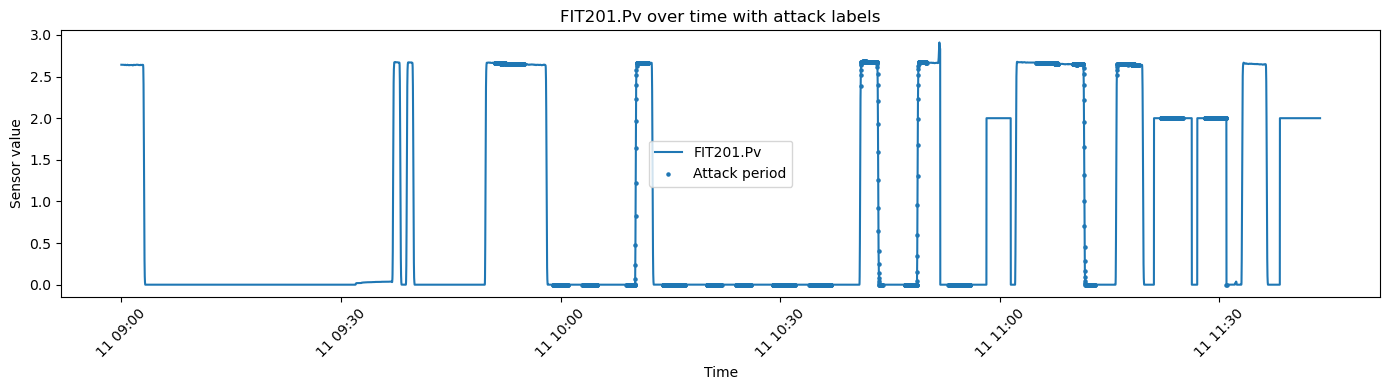

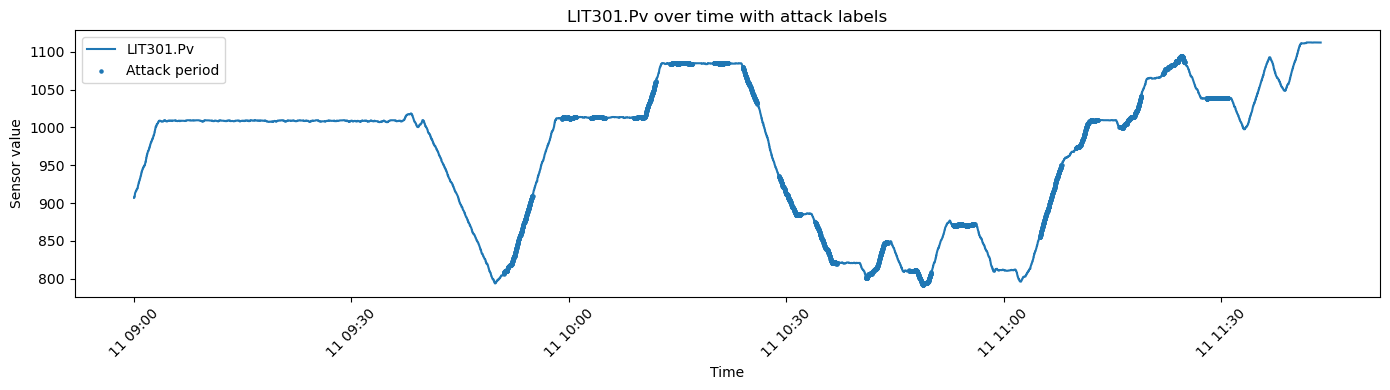

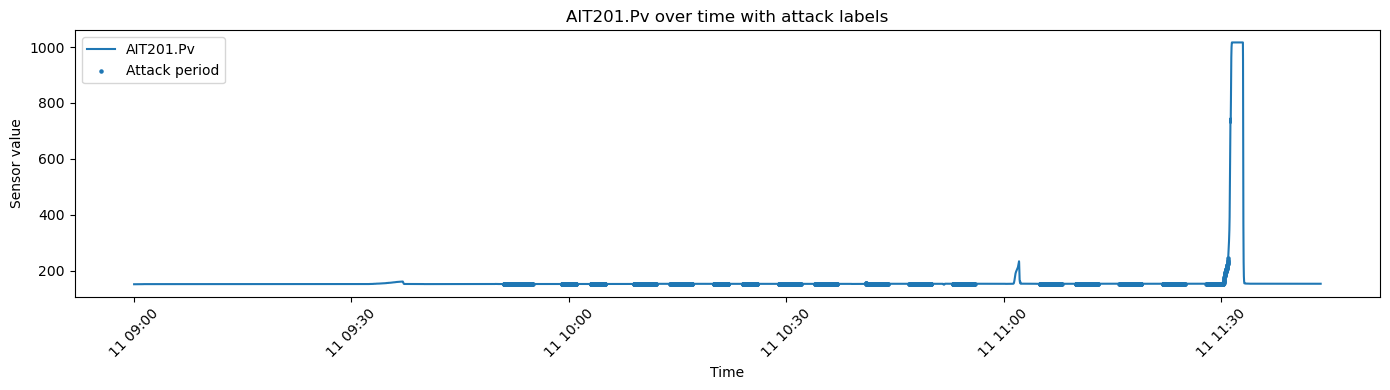

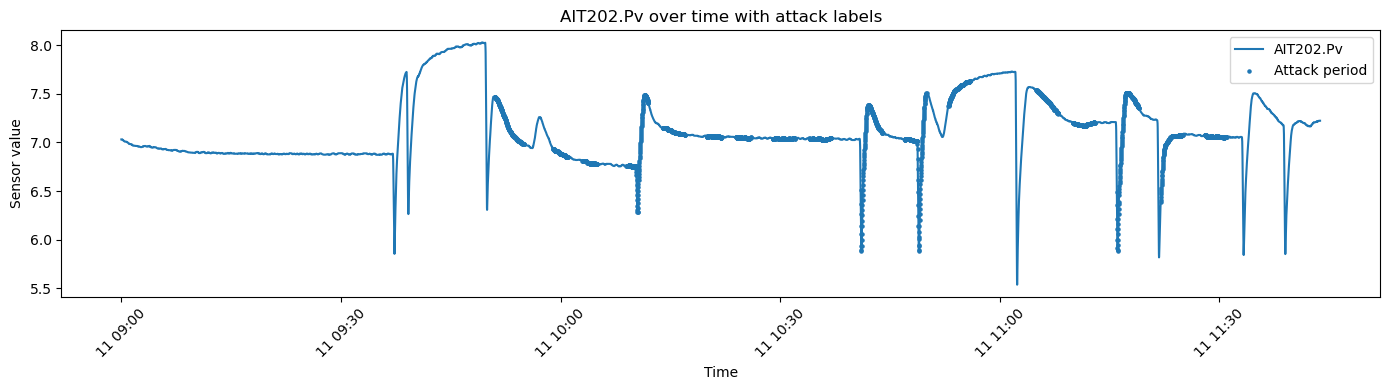

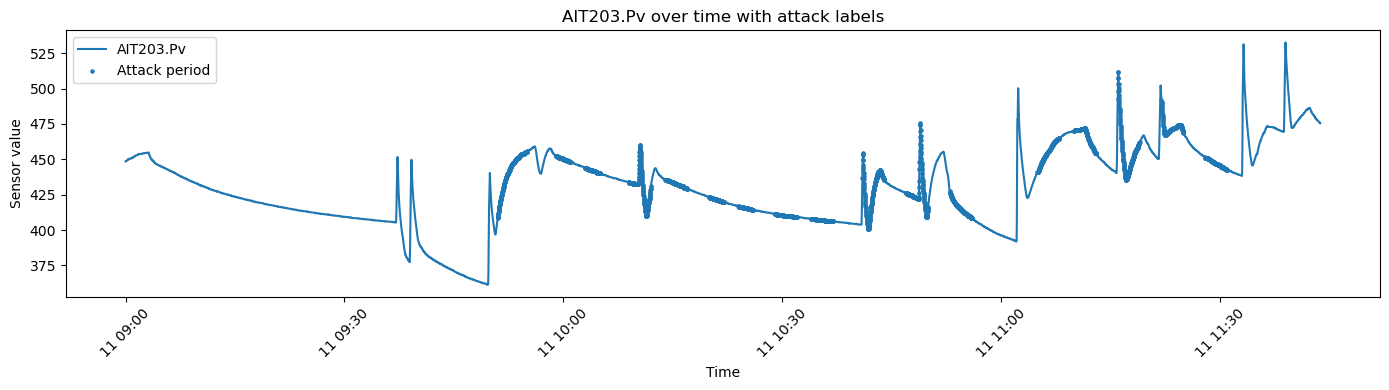

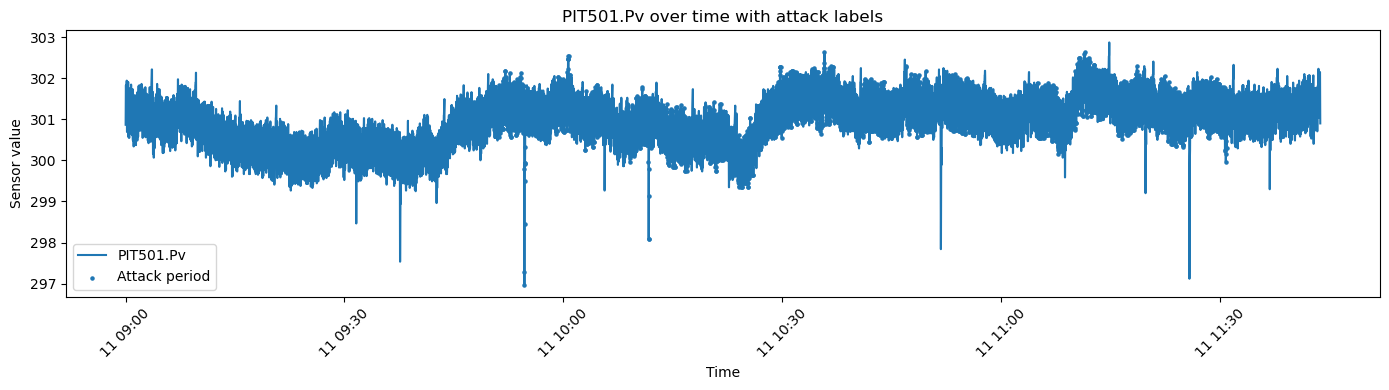

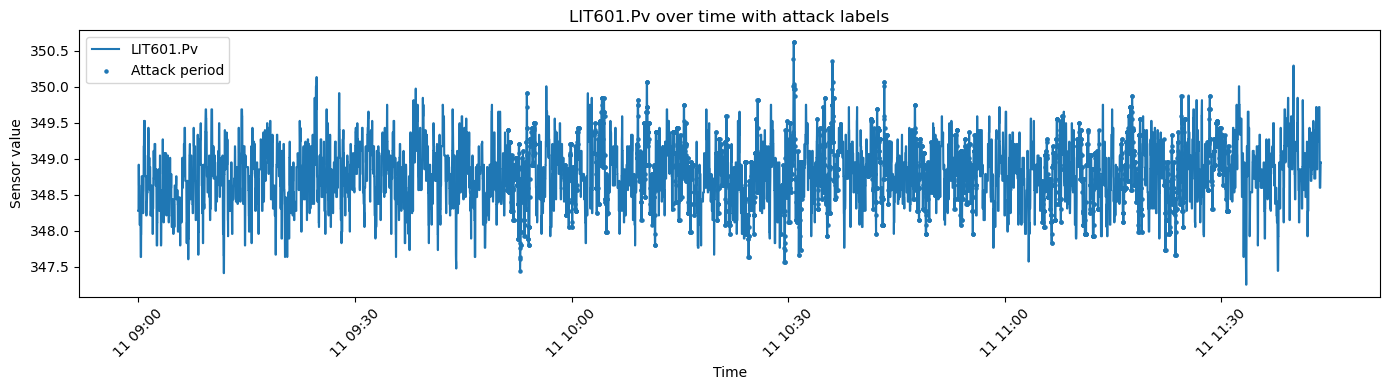

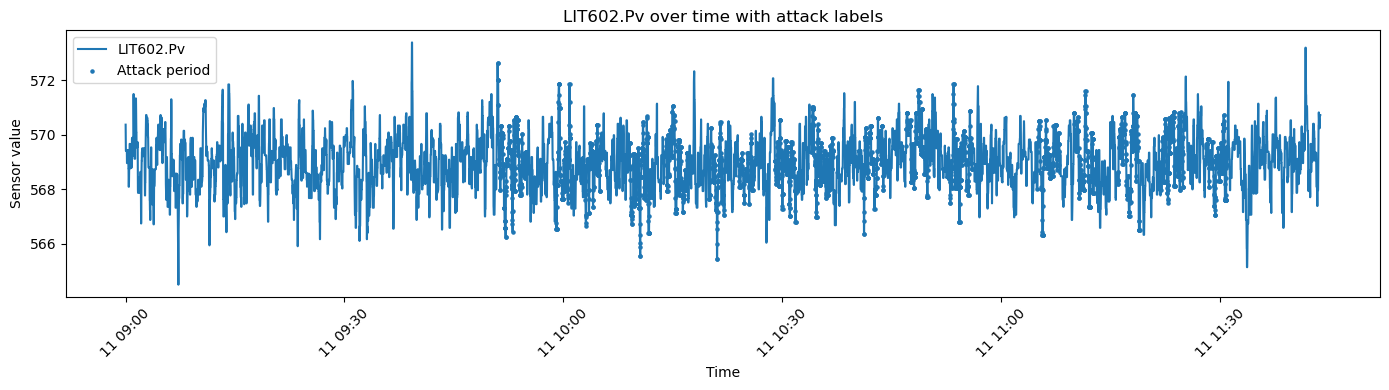

In [10]:
for col in available_starter_sensors:
    plt.figure(figsize=(14, 4))
    plt.plot(df11_clean["t_stamp"], df11_clean[col], label=col)
    
    attack_data = df11_clean[df11_clean["attack_label"] == 1]
    plt.scatter(
        attack_data["t_stamp"],
        attack_data[col],
        s=5,
        label="Attack period"
    )
    
    plt.title(f"{col} over time with attack labels")
    plt.xlabel("Time")
    plt.ylabel("Sensor value")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [11]:
from sklearn.metrics import classification_report, confusion_matrix

target = "LIT101.Pv"

df = df11_clean.copy()

df["prediction"] = df[target].shift(1)
df["residual"] = abs(df[target] - df["prediction"])

normal_residuals = df.loc[df["attack_label"] == 0, "residual"].dropna()
threshold = normal_residuals.quantile(0.95)

df["predicted_anomaly"] = (df["residual"] > threshold).astype(int)

eval_df = df.dropna(subset=["prediction"])

print("Target sensor:", target)
print("Threshold:", threshold)
print(confusion_matrix(eval_df["attack_label"], eval_df["predicted_anomaly"]))
print(classification_report(eval_df["attack_label"], eval_df["predicted_anomaly"]))

Target sensor: LIT101.Pv
Threshold: 1.1776395999999978
[[6582  347]
 [2571  326]]
              precision    recall  f1-score   support

           0       0.72      0.95      0.82      6929
           1       0.48      0.11      0.18      2897

    accuracy                           0.70      9826
   macro avg       0.60      0.53      0.50      9826
weighted avg       0.65      0.70      0.63      9826



In [12]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score

def evaluate_single_sensor_baseline(df_clean, target, train_end_time, quantile=0.95):
    df = df_clean.copy()

    # Previous value as prediction
    df["prediction"] = df[target].shift(1)

    # Absolute prediction error
    df["residual"] = abs(df[target] - df["prediction"])

    # Use only early normal data to calculate threshold
    train_mask = (df["t_stamp"] < train_end_time) & (df["attack_label"] == 0)
    normal_residuals = df.loc[train_mask, "residual"].dropna()

    if len(normal_residuals) == 0:
        return None

    threshold = normal_residuals.quantile(quantile)

    # Predict anomaly
    df["predicted_anomaly"] = (df["residual"] > threshold).astype(int)

    # Remove first row because shift creates NaN prediction
    eval_df = df.dropna(subset=["prediction"])

    y_true = eval_df["attack_label"]
    y_pred = eval_df["predicted_anomaly"]

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[1],
        zero_division=0
    )

    return {
        "sensor": target,
        "threshold": threshold,
        "accuracy": accuracy_score(y_true, y_pred),
        "attack_precision": precision[0],
        "attack_recall": recall[0],
        "attack_f1": f1[0],
        "true_normal": tn,
        "false_alarm": fp,
        "missed_attack": fn,
        "detected_attack_rows": tp
    }

In [13]:
train_end_time_11 = pd.to_datetime("2022-11-11 09:51:00")

result = evaluate_single_sensor_baseline(
    df_clean=df11_clean,
    target="LIT101.Pv",
    train_end_time=train_end_time_11,
    quantile=0.95
)

result

{'sensor': 'LIT101.Pv',
 'threshold': np.float64(0.8242999999999938),
 'accuracy': 0.6965194382251171,
 'attack_precision': np.float64(0.4667188723570869),
 'attack_recall': np.float64(0.20573006558508802),
 'attack_f1': np.float64(0.2855773838045041),
 'true_normal': np.int64(6248),
 'false_alarm': np.int64(681),
 'missed_attack': np.int64(2301),
 'detected_attack_rows': np.int64(596)}

In [14]:
train_end_time_11 = pd.to_datetime("2022-11-11 09:51:00")

results = []

for sensor in sensor_cols:
    result = evaluate_single_sensor_baseline(
        df_clean=df11_clean,
        target=sensor,
        train_end_time=train_end_time_11,
        quantile=0.95
    )
    
    if result is not None:
        results.append(result)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="attack_f1", ascending=False)

results_df

,sensor,threshold,accuracy,attack_precision,attack_recall,attack_f1,true_normal,false_alarm,missed_attack,detected_attack_rows
1,LIT101.Pv,0.824300,0.696519,0.466719,0.205730,0.285577,6248,681,2301,596
6,AIT301.Pv,0.002497,0.668940,0.358054,0.154988,0.216333,6124,805,2448,449
7,AIT302.Pv,0.384133,0.675758,0.363551,0.132896,0.194641,6255,674,2512,385
10,FIT301.Pv,0.001922,0.662223,0.315236,0.124266,0.178262,6147,782,2537,360
11,LIT301.Pv,0.801061,0.676064,0.336758,0.101829,0.156374,6348,581,2602,295
4,AIT203.Pv,0.694699,0.690413,0.390649,0.089403,0.145506,6525,404,2638,259
0,FIT101.Pv,0.001601,0.685528,0.361151,0.086641,0.139755,6485,444,2646,251
3,AIT202.Pv,0.017656,0.691024,0.376554,0.073179,0.122543,6578,351,2685,212
20,FIT501.Pv,0.002179,0.678302,0.298780,0.067656,0.110329,6469,460,2701,196
8,AIT303.Pv,0.160060,0.679727,0.300319,0.064895,0.106727,6491,438,2709,188


In [15]:
results_df[
    [
        "sensor",
        "threshold",
        "accuracy",
        "attack_precision",
        "attack_recall",
        "attack_f1",
        "false_alarm",
        "missed_attack",
        "detected_attack_rows"
    ]
].head(10)

,sensor,threshold,accuracy,attack_precision,attack_recall,attack_f1,false_alarm,missed_attack,detected_attack_rows
1,LIT101.Pv,0.824300,0.696519,0.466719,0.205730,0.285577,681,2301,596
6,AIT301.Pv,0.002497,0.668940,0.358054,0.154988,0.216333,805,2448,449
7,AIT302.Pv,0.384133,0.675758,0.363551,0.132896,0.194641,674,2512,385
10,FIT301.Pv,0.001922,0.662223,0.315236,0.124266,0.178262,782,2537,360
11,LIT301.Pv,0.801061,0.676064,0.336758,0.101829,0.156374,581,2602,295
4,AIT203.Pv,0.694699,0.690413,0.390649,0.089403,0.145506,404,2638,259
0,FIT101.Pv,0.001601,0.685528,0.361151,0.086641,0.139755,444,2646,251
3,AIT202.Pv,0.017656,0.691024,0.376554,0.073179,0.122543,351,2685,212
20,FIT501.Pv,0.002179,0.678302,0.298780,0.067656,0.110329,460,2701,196
8,AIT303.Pv,0.160060,0.679727,0.300319,0.064895,0.106727,438,2709,188


In [16]:
results_df.to_csv("single_sensor_baseline_results_11nov.csv", index=False)

In [17]:
quantile=0.95

In [18]:
all_threshold_results = []

for q in [0.90, 0.95, 0.99]:
    for sensor in sensor_cols:
        result = evaluate_single_sensor_baseline(
            df_clean=df11_clean,
            target=sensor,
            train_end_time=train_end_time_11,
            quantile=q
        )
        
        if result is not None:
            result["quantile"] = q
            all_threshold_results.append(result)

threshold_results_df = pd.DataFrame(all_threshold_results)

threshold_results_df = threshold_results_df.sort_values(
    by=["attack_f1", "attack_recall"],
    ascending=False
)

In [19]:
threshold_results_df[
    [
        "sensor",
        "quantile",
        "threshold",
        "accuracy",
        "attack_precision",
        "attack_recall",
        "attack_f1",
        "false_alarm",
        "missed_attack",
        "detected_attack_rows"
    ]
].head(20)

,sensor,quantile,threshold,accuracy,attack_precision,attack_recall,attack_f1,false_alarm,missed_attack,detected_attack_rows
1,LIT101.Pv,0.90,0.392532,0.671687,0.425397,0.323783,0.367699,1267,1959,938
32,LIT101.Pv,0.95,0.824300,0.696519,0.466719,0.205730,0.285577,681,2301,596
4,AIT203.Pv,0.90,0.281952,0.668634,0.390482,0.220918,0.282187,999,2257,640
6,AIT301.Pv,0.90,0.000416,0.646957,0.345572,0.220918,0.269530,1212,2257,640
7,AIT302.Pv,0.90,0.230499,0.651537,0.343991,0.200552,0.253380,1108,2316,581
3,AIT202.Pv,0.90,0.003845,0.667006,0.365976,0.176735,0.238361,887,2385,512
11,LIT301.Pv,0.90,0.560790,0.654183,0.334653,0.175009,0.229828,1008,2390,507
10,FIT301.Pv,0.90,0.000769,0.641461,0.304619,0.168450,0.216937,1114,2409,488
37,AIT301.Pv,0.95,0.002497,0.668940,0.358054,0.154988,0.216333,805,2448,449
38,AIT302.Pv,0.95,0.384133,0.675758,0.363551,0.132896,0.194641,674,2512,385


In [20]:
train_end_time_11 = pd.to_datetime("2022-11-11 09:51:00")

results = []

for sensor in sensor_cols:
    result = evaluate_single_sensor_baseline(
        df_clean=df11_clean,
        target=sensor,
        train_end_time=train_end_time_11,
        quantile=0.95
    )
    
    if result is not None:
        results.append(result)

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(by="attack_f1", ascending=False)

results_df[
    [
        "sensor",
        "threshold",
        "accuracy",
        "attack_precision",
        "attack_recall",
        "attack_f1",
        "false_alarm",
        "missed_attack",
        "detected_attack_rows"
    ]
].head(10)

,sensor,threshold,accuracy,attack_precision,attack_recall,attack_f1,false_alarm,missed_attack,detected_attack_rows
1,LIT101.Pv,0.824300,0.696519,0.466719,0.205730,0.285577,681,2301,596
6,AIT301.Pv,0.002497,0.668940,0.358054,0.154988,0.216333,805,2448,449
7,AIT302.Pv,0.384133,0.675758,0.363551,0.132896,0.194641,674,2512,385
10,FIT301.Pv,0.001922,0.662223,0.315236,0.124266,0.178262,782,2537,360
11,LIT301.Pv,0.801061,0.676064,0.336758,0.101829,0.156374,581,2602,295
4,AIT203.Pv,0.694699,0.690413,0.390649,0.089403,0.145506,404,2638,259
0,FIT101.Pv,0.001601,0.685528,0.361151,0.086641,0.139755,444,2646,251
3,AIT202.Pv,0.017656,0.691024,0.376554,0.073179,0.122543,351,2685,212
20,FIT501.Pv,0.002179,0.678302,0.298780,0.067656,0.110329,460,2701,196
8,AIT303.Pv,0.160060,0.679727,0.300319,0.064895,0.106727,438,2709,188


In [21]:
threshold_results_df.to_csv("single_sensor_threshold_comparison_11nov.csv", index=False)

In [22]:
def get_single_sensor_predictions(df_clean, target, train_end_time, quantile=0.95):
    df = df_clean.copy()

    # Previous value as prediction
    df["prediction"] = df[target].shift(1)

    # Absolute prediction error
    df["residual"] = abs(df[target] - df["prediction"])

    # Use only early normal data for threshold
    train_mask = (df["t_stamp"] < train_end_time) & (df["attack_label"] == 0)
    normal_residuals = df.loc[train_mask, "residual"].dropna()

    threshold = normal_residuals.quantile(quantile)

    # Predict anomaly
    df["predicted_anomaly"] = (df["residual"] > threshold).astype(int)

    # Remove first row because prediction is NaN
    df = df.dropna(subset=["prediction"]).copy()

    return df, threshold

In [23]:
def evaluate_attack_events(pred_df, intervals):
    date = pred_df["t_stamp"].dt.date.iloc[0]
    event_results = []

    for i, (start, end) in enumerate(intervals, start=1):
        start_dt = pd.to_datetime(f"{date} {start}")
        end_dt = pd.to_datetime(f"{date} {end}")

        window = pred_df[
            (pred_df["t_stamp"] >= start_dt) &
            (pred_df["t_stamp"] <= end_dt)
        ]

        detections = window[window["predicted_anomaly"] == 1]

        if len(detections) > 0:
            detected = 1
            first_detection_time = detections["t_stamp"].min()
            detection_delay_seconds = (first_detection_time - start_dt).total_seconds()
        else:
            detected = 0
            first_detection_time = None
            detection_delay_seconds = None

        event_results.append({
            "attack_event": i,
            "start_time": start_dt,
            "end_time": end_dt,
            "detected": detected,
            "first_detection_time": first_detection_time,
            "detection_delay_seconds": detection_delay_seconds,
            "total_rows_in_attack": len(window),
            "detected_rows_in_attack": len(detections)
        })

    return pd.DataFrame(event_results)

In [24]:
pred_lit101, threshold_lit101 = get_single_sensor_predictions(
    df_clean=df11_clean,
    target="LIT101.Pv",
    train_end_time=train_end_time_11,
    quantile=0.90
)

event_results_lit101 = evaluate_attack_events(pred_lit101, intervals_11)

event_results_lit101

,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:00,0.0,241,121
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:44,44.0,121,7
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:02,2.0,121,67
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:00,0.0,181,99
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:14,14.0,181,87
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,1,2022-11-11 10:20:14,14.0,121,3
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:39,39.0,121,1
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:31,31.0,181,2
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:45,45.0,181,5
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:02,2.0,181,75


In [25]:
event_detection_rate = event_results_lit101["detected"].mean() * 100

print(f"Attack event detection rate: {event_detection_rate:.2f}%")
print("Detected attacks:", event_results_lit101["detected"].sum())
print("Total attacks:", len(event_results_lit101))

Attack event detection rate: 100.00%
Detected attacks: 17
Total attacks: 17


In [26]:
top_sensors = results_df["sensor"].head(5).tolist()
top_sensors

['LIT101.Pv', 'AIT301.Pv', 'AIT302.Pv', 'FIT301.Pv', 'LIT301.Pv']

In [27]:
event_results_lit101["detection_delay_seconds"].describe()

count     17.000000
mean      18.117647
std       28.259694
min        0.000000
25%        0.000000
50%        2.000000
75%       31.000000
max      107.000000
Name: detection_delay_seconds, dtype: float64

In [28]:
print("Average detection delay:", event_results_lit101["detection_delay_seconds"].mean())
print("Median detection delay:", event_results_lit101["detection_delay_seconds"].median())
print("Maximum detection delay:", event_results_lit101["detection_delay_seconds"].max())

Average detection delay: 18.11764705882353
Median detection delay: 2.0
Maximum detection delay: 107.0


In [29]:
event_results_lit101[
    [
        "attack_event",
        "start_time",
        "end_time",
        "detected",
        "first_detection_time",
        "detection_delay_seconds",
        "total_rows_in_attack",
        "detected_rows_in_attack"
    ]
]

,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:00,0.0,241,121
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:44,44.0,121,7
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:02,2.0,121,67
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:00,0.0,181,99
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:14,14.0,181,87
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,1,2022-11-11 10:20:14,14.0,121,3
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:39,39.0,121,1
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:31,31.0,181,2
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:45,45.0,181,5
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:02,2.0,181,75


In [30]:
event_results_lit101.to_csv("lit101_event_detection_results_11nov.csv", index=False)

In [31]:
event_summary_results = []

for sensor in top_sensors:
    pred_df, threshold = get_single_sensor_predictions(
        df_clean=df11_clean,
        target=sensor,
        train_end_time=train_end_time_11,
        quantile=0.90
    )

    event_df = evaluate_attack_events(pred_df, intervals_11)

    event_summary_results.append({
        "sensor": sensor,
        "threshold": threshold,
        "quantile": 0.90,
        "detected_events": event_df["detected"].sum(),
        "total_events": len(event_df),
        "event_detection_rate": event_df["detected"].mean() * 100,
        "average_detection_delay_seconds": event_df["detection_delay_seconds"].mean(),
        "median_detection_delay_seconds": event_df["detection_delay_seconds"].median(),
        "max_detection_delay_seconds": event_df["detection_delay_seconds"].max(),
        "total_detected_attack_rows": event_df["detected_rows_in_attack"].sum()
    })

event_summary_df = pd.DataFrame(event_summary_results)

event_summary_df

,sensor,threshold,quantile,detected_events,total_events,event_detection_rate,average_detection_delay_seconds,median_detection_delay_seconds,max_detection_delay_seconds,total_detected_attack_rows
0,LIT101.Pv,0.392532,0.9,17,17,100.000000,18.117647,2.0,107.0,938
1,AIT301.Pv,0.000416,0.9,17,17,100.000000,22.529412,11.0,73.0,640
2,AIT302.Pv,0.230499,0.9,17,17,100.000000,11.352941,7.0,49.0,581
3,FIT301.Pv,0.000769,0.9,11,17,64.705882,24.727273,1.0,176.0,488
4,LIT301.Pv,0.560790,0.9,14,17,82.352941,19.000000,5.5,73.0,507


In [32]:
normal_rows = pred_lit101[pred_lit101["attack_label"] == 0]
false_alarms = normal_rows[normal_rows["predicted_anomaly"] == 1]

print("Total normal rows:", len(normal_rows))
print("False alarm rows:", len(false_alarms))
print("False alarm rate:", len(false_alarms) / len(normal_rows) * 100)

Total normal rows: 6929
False alarm rows: 1267
False alarm rate: 18.285466878337424


In [33]:
top_sensors = ['LIT101.Pv', 'AIT301.Pv', 'AIT302.Pv', 'FIT301.Pv', 'LIT301.Pv']

In [34]:
from sklearn.metrics import confusion_matrix, precision_recall_fscore_support, accuracy_score

def evaluate_multisensor_baseline(df_clean, selected_sensors, train_end_time, quantile=0.90):
    df = df_clean.copy()

    train_mask = (df["t_stamp"] < train_end_time) & (df["attack_label"] == 0)

    normalized_residual_cols = []

    for sensor in selected_sensors:
        prediction_col = f"{sensor}_prediction"
        residual_col = f"{sensor}_residual"
        normalized_col = f"{sensor}_normalized_residual"

        # Previous value as prediction
        df[prediction_col] = df[sensor].shift(1)

        # Absolute residual
        df[residual_col] = abs(df[sensor] - df[prediction_col])

        # Sensor-specific threshold from early normal data
        normal_residuals = df.loc[train_mask, residual_col].dropna()

        if len(normal_residuals) == 0:
            continue

        sensor_threshold = normal_residuals.quantile(quantile)

        # Avoid division by zero
        if sensor_threshold == 0:
            sensor_threshold = 1e-9

        # Normalize residual by that sensor's own threshold
        df[normalized_col] = df[residual_col] / sensor_threshold

        normalized_residual_cols.append(normalized_col)

    # Combine sensors: if any sensor becomes highly abnormal, anomaly score rises
    df["anomaly_score"] = df[normalized_residual_cols].max(axis=1)

    # If anomaly_score > 1, at least one sensor crossed its normal threshold
    df["predicted_anomaly"] = (df["anomaly_score"] > 1).astype(int)

    # Remove rows where predictions are missing
    eval_df = df.dropna(subset=normalized_residual_cols).copy()

    y_true = eval_df["attack_label"]
    y_pred = eval_df["predicted_anomaly"]

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[1],
        zero_division=0
    )

    results = {
        "selected_sensors": selected_sensors,
        "quantile": quantile,
        "accuracy": accuracy_score(y_true, y_pred),
        "attack_precision": precision[0],
        "attack_recall": recall[0],
        "attack_f1": f1[0],
        "true_normal": tn,
        "false_alarm": fp,
        "missed_attack": fn,
        "detected_attack_rows": tp,
        "false_alarm_rate": fp / (fp + tn) * 100
    }

    return eval_df, results

In [35]:
top_sensors = ['LIT101.Pv', 'AIT301.Pv', 'AIT302.Pv', 'FIT301.Pv', 'LIT301.Pv']

multi_pred_df, multi_results = evaluate_multisensor_baseline(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    train_end_time=train_end_time_11,
    quantile=0.90
)

multi_results

{'selected_sensors': ['LIT101.Pv',
  'AIT301.Pv',
  'AIT302.Pv',
  'FIT301.Pv',
  'LIT301.Pv'],
 'quantile': 0.9,
 'accuracy': 0.5323631182576837,
 'attack_precision': np.float64(0.3515215110178384),
 'attack_recall': np.float64(0.6938211943389714),
 'attack_f1': np.float64(0.4666279744631457),
 'true_normal': np.int64(3221),
 'false_alarm': np.int64(3708),
 'missed_attack': np.int64(887),
 'detected_attack_rows': np.int64(2010),
 'false_alarm_rate': np.float64(53.51421561552894)}

In [36]:
multi_pred_df[
    [
        "t_stamp",
        "attack_label",
        "anomaly_score",
        "predicted_anomaly"
    ]
].head(20)

,t_stamp,attack_label,anomaly_score,predicted_anomaly
1,2022-11-11 09:00:01,0,15.989194,1
2,2022-11-11 09:00:02,0,2.214112,1
3,2022-11-11 09:00:03,0,1.599847,1
4,2022-11-11 09:00:04,0,1.857023,1
5,2022-11-11 09:00:05,0,0.400143,0
6,2022-11-11 09:00:06,0,3.428378,1
7,2022-11-11 09:00:07,0,2.799903,1
8,2022-11-11 09:00:08,0,2.999788,1
9,2022-11-11 09:00:09,0,7.994405,1
10,2022-11-11 09:00:10,0,4.996806,1


In [37]:
multi_event_results = evaluate_attack_events(multi_pred_df, intervals_11)

multi_event_results

,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:00,0.0,241,198
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:04,4.0,121,40
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:02,2.0,121,73
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:00,0.0,181,130
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:14,14.0,181,94
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,1,2022-11-11 10:20:14,14.0,121,13
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:00,0.0,121,105
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:00,0.0,181,128
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:00,0.0,181,118
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:00,0.0,181,157


In [38]:
print("Detected attacks:", multi_event_results["detected"].sum())
print("Total attacks:", len(multi_event_results))
print("Attack event detection rate:", multi_event_results["detected"].mean() * 100)

print("Average detection delay:", multi_event_results["detection_delay_seconds"].mean())
print("Median detection delay:", multi_event_results["detection_delay_seconds"].median())
print("Maximum detection delay:", multi_event_results["detection_delay_seconds"].max())

Detected attacks: 17
Total attacks: 17
Attack event detection rate: 100.0
Average detection delay: 2.0588235294117645
Median detection delay: 0.0
Maximum detection delay: 14.0


In [39]:
multi_event_results.to_csv("multisensor_event_detection_results_11nov_q90.csv", index=False)
multi_pred_df.to_csv("multisensor_predictions_11nov_q90.csv", index=False)

In [40]:
multi_threshold_results = []

for q in [0.90, 0.95, 0.99]:
    multi_pred_df_q, multi_results_q = evaluate_multisensor_baseline(
        df_clean=df11_clean,
        selected_sensors=top_sensors,
        train_end_time=train_end_time_11,
        quantile=q
    )

    multi_event_results_q = evaluate_attack_events(multi_pred_df_q, intervals_11)

    multi_threshold_results.append({
        "quantile": q,
        "accuracy": multi_results_q["accuracy"],
        "attack_precision": multi_results_q["attack_precision"],
        "attack_recall": multi_results_q["attack_recall"],
        "attack_f1": multi_results_q["attack_f1"],
        "false_alarm": multi_results_q["false_alarm"],
        "false_alarm_rate": multi_results_q["false_alarm_rate"],
        "missed_attack": multi_results_q["missed_attack"],
        "detected_attack_rows": multi_results_q["detected_attack_rows"],
        "detected_events": multi_event_results_q["detected"].sum(),
        "total_events": len(multi_event_results_q),
        "event_detection_rate": multi_event_results_q["detected"].mean() * 100,
        "average_detection_delay": multi_event_results_q["detection_delay_seconds"].mean(),
        "median_detection_delay": multi_event_results_q["detection_delay_seconds"].median(),
        "max_detection_delay": multi_event_results_q["detection_delay_seconds"].max()
    })

multi_threshold_results_df = pd.DataFrame(multi_threshold_results)

multi_threshold_results_df

,quantile,accuracy,attack_precision,attack_recall,attack_f1,false_alarm,false_alarm_rate,missed_attack,detected_attack_rows,detected_events,total_events,event_detection_rate,average_detection_delay,median_detection_delay,max_detection_delay
0,0.90,0.532363,0.351522,0.693821,0.466628,3708,53.514216,887,2010,17,17,100.000000,2.058824,0.0,14.0
1,0.95,0.592510,0.367425,0.529513,0.433824,2641,38.115168,1363,1534,17,17,100.000000,5.352941,0.0,35.0
2,0.99,0.657847,0.356037,0.198481,0.254876,1040,15.009381,2322,575,16,17,94.117647,13.062500,5.0,70.0


In [41]:
multi_threshold_results_df.to_csv("multisensor_threshold_comparison_11nov.csv", index=False)

In [42]:
def evaluate_multisensor_voting_baseline(
    df_clean,
    selected_sensors,
    train_end_time,
    quantile=0.90,
    min_sensors_triggered=2
):
    df = df_clean.copy()

    train_mask = (df["t_stamp"] < train_end_time) & (df["attack_label"] == 0)

    trigger_cols = []
    normalized_residual_cols = []

    for sensor in selected_sensors:
        prediction_col = f"{sensor}_prediction"
        residual_col = f"{sensor}_residual"
        normalized_col = f"{sensor}_normalized_residual"
        trigger_col = f"{sensor}_triggered"

        df[prediction_col] = df[sensor].shift(1)
        df[residual_col] = abs(df[sensor] - df[prediction_col])

        normal_residuals = df.loc[train_mask, residual_col].dropna()

        if len(normal_residuals) == 0:
            continue

        sensor_threshold = normal_residuals.quantile(quantile)

        if sensor_threshold == 0:
            sensor_threshold = 1e-9

        df[normalized_col] = df[residual_col] / sensor_threshold

        df[trigger_col] = (df[normalized_col] > 1).astype(int)

        normalized_residual_cols.append(normalized_col)
        trigger_cols.append(trigger_col)

    df["anomaly_score"] = df[normalized_residual_cols].max(axis=1)

    df["num_sensors_triggered"] = df[trigger_cols].sum(axis=1)

    df["predicted_anomaly"] = (
        df["num_sensors_triggered"] >= min_sensors_triggered
    ).astype(int)

    eval_df = df.dropna(subset=normalized_residual_cols).copy()

    y_true = eval_df["attack_label"]
    y_pred = eval_df["predicted_anomaly"]

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[1],
        zero_division=0
    )

    results = {
        "selected_sensors": selected_sensors,
        "quantile": quantile,
        "min_sensors_triggered": min_sensors_triggered,
        "accuracy": accuracy_score(y_true, y_pred),
        "attack_precision": precision[0],
        "attack_recall": recall[0],
        "attack_f1": f1[0],
        "true_normal": tn,
        "false_alarm": fp,
        "missed_attack": fn,
        "detected_attack_rows": tp,
        "false_alarm_rate": fp / (fp + tn) * 100
    }

    return eval_df, results

In [43]:
voting_results = []

for q in [0.90, 0.95, 0.99]:
    for k in [1, 2, 3]:
        voting_pred_df, voting_row_results = evaluate_multisensor_voting_baseline(
            df_clean=df11_clean,
            selected_sensors=top_sensors,
            train_end_time=train_end_time_11,
            quantile=q,
            min_sensors_triggered=k
        )

        voting_event_results = evaluate_attack_events(voting_pred_df, intervals_11)

        voting_results.append({
            "quantile": q,
            "min_sensors_triggered": k,
            "accuracy": voting_row_results["accuracy"],
            "attack_precision": voting_row_results["attack_precision"],
            "attack_recall": voting_row_results["attack_recall"],
            "attack_f1": voting_row_results["attack_f1"],
            "false_alarm_rate": voting_row_results["false_alarm_rate"],
            "false_alarm": voting_row_results["false_alarm"],
            "missed_attack": voting_row_results["missed_attack"],
            "detected_attack_rows": voting_row_results["detected_attack_rows"],
            "detected_events": voting_event_results["detected"].sum(),
            "total_events": len(voting_event_results),
            "event_detection_rate": voting_event_results["detected"].mean() * 100,
            "average_detection_delay": voting_event_results["detection_delay_seconds"].mean(),
            "median_detection_delay": voting_event_results["detection_delay_seconds"].median(),
            "max_detection_delay": voting_event_results["detection_delay_seconds"].max()
        })

voting_results_df = pd.DataFrame(voting_results)

voting_results_df.sort_values(
    by=["event_detection_rate", "false_alarm_rate"],
    ascending=[False, True]
)[
    [
        "quantile",
        "min_sensors_triggered",
        "accuracy",
        "attack_precision",
        "attack_recall",
        "attack_f1",
        "false_alarm_rate",
        "false_alarm",
        "missed_attack",
        "detected_attack_rows",
        "detected_events",
        "total_events",
        "event_detection_rate",
        "average_detection_delay",
        "median_detection_delay",
        "max_detection_delay"
    ]
]

,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,false_alarm,missed_attack,detected_attack_rows,detected_events,total_events,event_detection_rate,average_detection_delay,median_detection_delay,max_detection_delay
3,0.95,1,0.592510,0.367425,0.529513,0.433824,38.115168,2641,1363,1534,17,17,100.000000,5.352941,0.0,35.0
0,0.90,1,0.532363,0.351522,0.693821,0.466628,53.514216,3708,887,2010,17,17,100.000000,2.058824,0.0,14.0
6,0.99,1,0.657847,0.356037,0.198481,0.254876,15.009381,1040,2322,575,16,17,94.117647,13.062500,5.0,70.0
1,0.90,2,0.639426,0.363943,0.298240,0.327832,21.792466,1510,2033,864,16,17,94.117647,12.437500,1.5,67.0
2,0.90,3,0.687767,0.369863,0.083880,0.136747,5.974888,414,2654,243,15,17,88.235294,22.066667,7.0,86.0
4,0.95,2,0.677081,0.383249,0.156369,0.222113,10.520999,729,2444,453,15,17,88.235294,20.333333,4.0,98.0
5,0.95,3,0.700590,0.402597,0.032102,0.059463,1.991629,138,2804,93,14,17,82.352941,45.571429,36.0,149.0
7,0.99,2,0.702524,0.404412,0.018985,0.036268,1.169000,81,2842,55,11,17,64.705882,65.000000,55.0,169.0
8,0.99,3,0.704966,0.333333,0.000690,0.001378,0.057728,4,2895,2,2,17,11.764706,29.500000,29.5,37.0


In [44]:
voting_results_df.to_csv("multisensor_voting_threshold_comparison_11nov.csv", index=False)

In [45]:
candidate_configs = voting_results_df[
    (
        (voting_results_df["event_detection_rate"] >= 90)
    )
].sort_values(
    by=["event_detection_rate", "false_alarm_rate"],
    ascending=[False, True]
)

candidate_configs[
    [
        "quantile",
        "min_sensors_triggered",
        "attack_precision",
        "attack_recall",
        "attack_f1",
        "false_alarm_rate",
        "detected_events",
        "total_events",
        "event_detection_rate",
        "average_detection_delay",
        "median_detection_delay",
        "max_detection_delay"
    ]
]

,quantile,min_sensors_triggered,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,total_events,event_detection_rate,average_detection_delay,median_detection_delay,max_detection_delay
3,0.95,1,0.367425,0.529513,0.433824,38.115168,17,17,100.000000,5.352941,0.0,35.0
0,0.90,1,0.351522,0.693821,0.466628,53.514216,17,17,100.000000,2.058824,0.0,14.0
6,0.99,1,0.356037,0.198481,0.254876,15.009381,16,17,94.117647,13.062500,5.0,70.0
1,0.90,2,0.363943,0.298240,0.327832,21.792466,16,17,94.117647,12.437500,1.5,67.0


In [46]:
chosen_quantile = 0.95
chosen_k = 1

In [47]:
chosen_quantile = 0.95
chosen_k = 1

final_multi_pred_df, final_multi_row_results = evaluate_multisensor_voting_baseline(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    train_end_time=train_end_time_11,
    quantile=chosen_quantile,
    min_sensors_triggered=chosen_k
)

final_multi_event_results = evaluate_attack_events(final_multi_pred_df, intervals_11)

print("Row-level results:")
print(final_multi_row_results)

print("\nEvent-level results:")
print("Detected attacks:", final_multi_event_results["detected"].sum())
print("Total attacks:", len(final_multi_event_results))
print("Event detection rate:", final_multi_event_results["detected"].mean() * 100)
print("Average detection delay:", final_multi_event_results["detection_delay_seconds"].mean())
print("Median detection delay:", final_multi_event_results["detection_delay_seconds"].median())
print("Maximum detection delay:", final_multi_event_results["detection_delay_seconds"].max())

Row-level results:
{'selected_sensors': ['LIT101.Pv', 'AIT301.Pv', 'AIT302.Pv', 'FIT301.Pv', 'LIT301.Pv'], 'quantile': 0.95, 'min_sensors_triggered': 1, 'accuracy': 0.5925096682271525, 'attack_precision': np.float64(0.3674251497005988), 'attack_recall': np.float64(0.5295132896099414), 'attack_f1': np.float64(0.4338235294117647), 'true_normal': np.int64(4288), 'false_alarm': np.int64(2641), 'missed_attack': np.int64(1363), 'detected_attack_rows': np.int64(1534), 'false_alarm_rate': np.float64(38.11516813392986)}

Event-level results:
Detected attacks: 17
Total attacks: 17
Event detection rate: 100.0
Average detection delay: 5.352941176470588
Median detection delay: 0.0
Maximum detection delay: 35.0


In [48]:
final_multi_event_results.to_csv("final_multisensor_event_results_11nov.csv", index=False)
final_multi_pred_df.to_csv("final_multisensor_predictions_11nov.csv", index=False)

In [49]:
train_end_time_10 = pd.to_datetime("2022-11-10 11:03:00")

final_multi_pred_df_10, final_multi_row_results_10 = evaluate_multisensor_voting_baseline(
    df_clean=df10_clean,
    selected_sensors=top_sensors,
    train_end_time=train_end_time_10,
    quantile=chosen_quantile,
    min_sensors_triggered=chosen_k
)

final_multi_event_results_10 = evaluate_attack_events(final_multi_pred_df_10, intervals_10)

print("10 Nov row-level results:")
print(final_multi_row_results_10)

print("\n10 Nov event-level results:")
print("Detected attacks:", final_multi_event_results_10["detected"].sum())
print("Total attacks:", len(final_multi_event_results_10))
print("Event detection rate:", final_multi_event_results_10["detected"].mean() * 100)
print("Average detection delay:", final_multi_event_results_10["detection_delay_seconds"].mean())
print("Median detection delay:", final_multi_event_results_10["detection_delay_seconds"].median())
print("Maximum detection delay:", final_multi_event_results_10["detection_delay_seconds"].max())

10 Nov row-level results:
{'selected_sensors': ['LIT101.Pv', 'AIT301.Pv', 'AIT302.Pv', 'FIT301.Pv', 'LIT301.Pv'], 'quantile': 0.95, 'min_sensors_triggered': 1, 'accuracy': 0.4263888888888889, 'attack_precision': np.float64(0.36827852998065763), 'attack_recall': np.float64(0.6878612716763006), 'attack_f1': np.float64(0.47971781305114636), 'true_normal': np.int64(583), 'false_alarm': np.int64(1633), 'missed_attack': np.int64(432), 'detected_attack_rows': np.int64(952), 'false_alarm_rate': np.float64(73.6913357400722)}

10 Nov event-level results:
Detected attacks: 4
Total attacks: 4
Event detection rate: 100.0
Average detection delay: 4.25
Median detection delay: 3.0
Maximum detection delay: 11.0


In [50]:
final_multi_event_results_10.to_csv("final_multisensor_event_results_10nov.csv", index=False)
final_multi_pred_df_10.to_csv("final_multisensor_predictions_10nov.csv", index=False)

In [51]:
comparison_summary = pd.DataFrame([
    {
        "dataset": "11 Nov",
        "model": "Multi-sensor voting residual detector",
        "quantile": chosen_quantile,
        "min_sensors_triggered": chosen_k,
        "accuracy": final_multi_row_results["accuracy"],
        "attack_precision": final_multi_row_results["attack_precision"],
        "attack_recall": final_multi_row_results["attack_recall"],
        "attack_f1": final_multi_row_results["attack_f1"],
        "false_alarm_rate": final_multi_row_results["false_alarm_rate"],
        "detected_events": final_multi_event_results["detected"].sum(),
        "total_events": len(final_multi_event_results),
        "event_detection_rate": final_multi_event_results["detected"].mean() * 100,
        "average_detection_delay": final_multi_event_results["detection_delay_seconds"].mean(),
        "median_detection_delay": final_multi_event_results["detection_delay_seconds"].median(),
        "max_detection_delay": final_multi_event_results["detection_delay_seconds"].max()
    },
    {
        "dataset": "10 Nov",
        "model": "Multi-sensor voting residual detector",
        "quantile": chosen_quantile,
        "min_sensors_triggered": chosen_k,
        "accuracy": final_multi_row_results_10["accuracy"],
        "attack_precision": final_multi_row_results_10["attack_precision"],
        "attack_recall": final_multi_row_results_10["attack_recall"],
        "attack_f1": final_multi_row_results_10["attack_f1"],
        "false_alarm_rate": final_multi_row_results_10["false_alarm_rate"],
        "detected_events": final_multi_event_results_10["detected"].sum(),
        "total_events": len(final_multi_event_results_10),
        "event_detection_rate": final_multi_event_results_10["detected"].mean() * 100,
        "average_detection_delay": final_multi_event_results_10["detection_delay_seconds"].mean(),
        "median_detection_delay": final_multi_event_results_10["detection_delay_seconds"].median(),
        "max_detection_delay": final_multi_event_results_10["detection_delay_seconds"].max()
    }
])

comparison_summary

,dataset,model,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,total_events,event_detection_rate,average_detection_delay,median_detection_delay,max_detection_delay
0,11 Nov,Multi-sensor voting residual detector,0.95,1,0.592510,0.367425,0.529513,0.433824,38.115168,17,17,100.0,5.352941,0.0,35.0
1,10 Nov,Multi-sensor voting residual detector,0.95,1,0.426389,0.368279,0.687861,0.479718,73.691336,4,4,100.0,4.250000,3.0,11.0


In [52]:
comparison_summary.to_csv("final_multisensor_comparison_summary.csv", index=False)

In [53]:
candidate_configs = voting_results_df[
    voting_results_df["event_detection_rate"] >= 90
].sort_values(
    by=["false_alarm_rate", "average_detection_delay"],
    ascending=[True, True]
)

candidate_configs[
    [
        "quantile",
        "min_sensors_triggered",
        "attack_precision",
        "attack_recall",
        "attack_f1",
        "false_alarm_rate",
        "detected_events",
        "total_events",
        "event_detection_rate",
        "average_detection_delay",
        "median_detection_delay",
        "max_detection_delay"
    ]
]

,quantile,min_sensors_triggered,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,total_events,event_detection_rate,average_detection_delay,median_detection_delay,max_detection_delay
6,0.99,1,0.356037,0.198481,0.254876,15.009381,16,17,94.117647,13.062500,5.0,70.0
1,0.90,2,0.363943,0.298240,0.327832,21.792466,16,17,94.117647,12.437500,1.5,67.0
3,0.95,1,0.367425,0.529513,0.433824,38.115168,17,17,100.000000,5.352941,0.0,35.0
0,0.90,1,0.351522,0.693821,0.466628,53.514216,17,17,100.000000,2.058824,0.0,14.0


In [54]:
import matplotlib.pyplot as plt

def plot_anomaly_score(pred_df, title, save_path=None):
    plt.figure(figsize=(14, 4))

    plt.plot(
        pred_df["t_stamp"],
        pred_df["anomaly_score"],
        label="Anomaly score"
    )

    attack_rows = pred_df[pred_df["attack_label"] == 1]

    plt.scatter(
        attack_rows["t_stamp"],
        attack_rows["anomaly_score"],
        s=5,
        label="Attack period"
    )

    plt.axhline(y=1, linestyle="--", label="Anomaly threshold")

    plt.title(title)
    plt.xlabel("Time")
    plt.ylabel("Anomaly score")
    plt.xticks(rotation=45)
    plt.legend()
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()

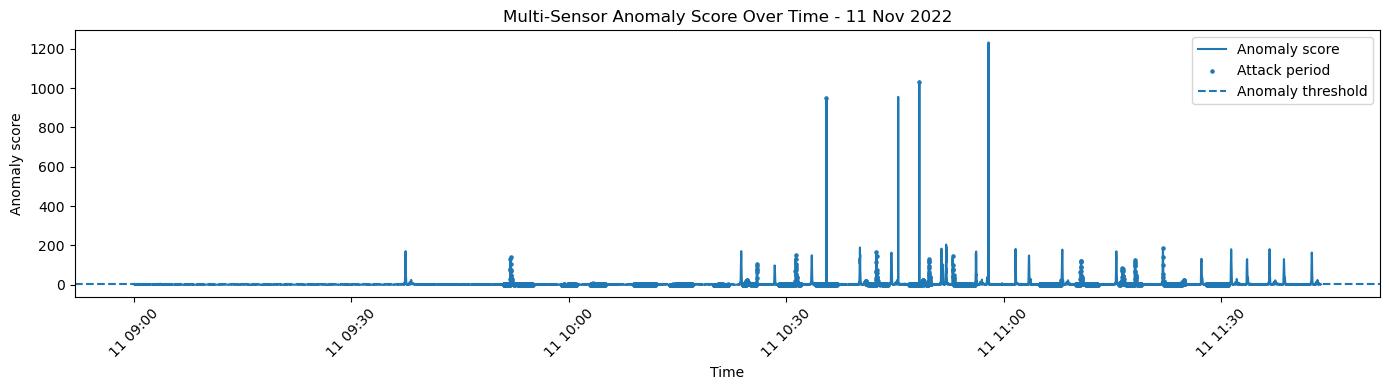

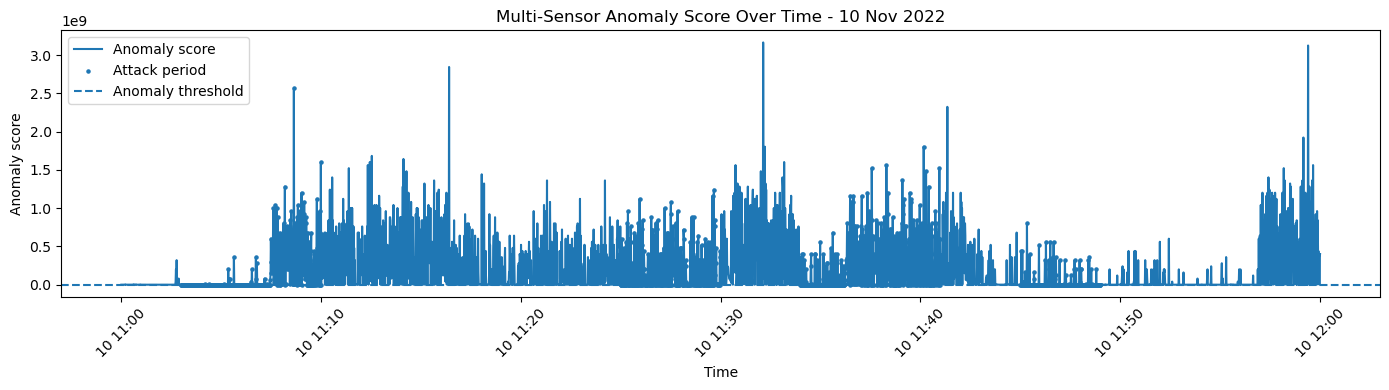

In [55]:
plot_anomaly_score(
    final_multi_pred_df,
    "Multi-Sensor Anomaly Score Over Time - 11 Nov 2022",
    save_path="multisensor_anomaly_score_11nov.png"
)

plot_anomaly_score(
    final_multi_pred_df_10,
    "Multi-Sensor Anomaly Score Over Time - 10 Nov 2022",
    save_path="multisensor_anomaly_score_10nov.png"
)

In [56]:
comparison_summary.to_csv("final_multisensor_comparison_summary.csv", index=False)

In [57]:
voting_results_df.to_csv("multisensor_voting_threshold_comparison_11nov.csv", index=False)

In [58]:
final_multi_event_results.to_csv("final_multisensor_event_results_11nov.csv", index=False)
final_multi_pred_df.to_csv("final_multisensor_predictions_11nov.csv", index=False)

final_multi_event_results_10.to_csv("final_multisensor_event_results_10nov.csv", index=False)
final_multi_pred_df_10.to_csv("final_multisensor_predictions_10nov.csv", index=False)

comparison_summary.to_csv("final_multisensor_comparison_summary.csv", index=False)
voting_results_df.to_csv("multisensor_voting_threshold_comparison_11nov.csv", index=False)

### Anomaly Score Visualisation

The anomaly score plots show the combined residual-based anomaly score over time. The horizontal threshold line at 1 represents the anomaly decision boundary. When the anomaly score exceeds 1, the detector flags the timestamp as anomalous.

The plots show that the anomaly score increases during several documented attack periods, supporting the event-level detection results. However, some anomaly scores also exceed the threshold outside attack windows, explaining the false-alarm rate observed in the evaluation.

This confirms that the persistence-based multi-sensor detector is sensitive and can detect attack events quickly, but further model improvement is needed to reduce false alarms.

In [59]:
def evaluate_multisensor_rolling_mean_baseline(
    df_clean,
    selected_sensors,
    train_end_time,
    window=5,
    quantile=0.95,
    min_sensors_triggered=1
):
    df = df_clean.copy()

    train_mask = (df["t_stamp"] < train_end_time) & (df["attack_label"] == 0)

    trigger_cols = []
    normalized_residual_cols = []

    for sensor in selected_sensors:
        prediction_col = f"{sensor}_rolling_prediction"
        residual_col = f"{sensor}_rolling_residual"
        normalized_col = f"{sensor}_rolling_normalized_residual"
        trigger_col = f"{sensor}_rolling_triggered"

        df[prediction_col] = df[sensor].shift(1).rolling(
            window=window,
            min_periods=1
        ).mean()

        df[residual_col] = abs(df[sensor] - df[prediction_col])

        normal_residuals = df.loc[train_mask, residual_col].dropna()

        if len(normal_residuals) == 0:
            continue

        sensor_threshold = normal_residuals.quantile(quantile)

        if sensor_threshold == 0:
            sensor_threshold = 1e-9

        df[normalized_col] = df[residual_col] / sensor_threshold
        df[trigger_col] = (df[normalized_col] > 1).astype(int)

        normalized_residual_cols.append(normalized_col)
        trigger_cols.append(trigger_col)

    df["anomaly_score"] = df[normalized_residual_cols].max(axis=1)

    df["num_sensors_triggered"] = df[trigger_cols].sum(axis=1)

    df["predicted_anomaly"] = (
        df["num_sensors_triggered"] >= min_sensors_triggered
    ).astype(int)

    eval_df = df.dropna(subset=normalized_residual_cols).copy()

    y_true = eval_df["attack_label"]
    y_pred = eval_df["predicted_anomaly"]

    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    precision, recall, f1, support = precision_recall_fscore_support(
        y_true,
        y_pred,
        labels=[1],
        zero_division=0
    )

    results = {
        "model": "rolling_mean",
        "selected_sensors": selected_sensors,
        "window": window,
        "quantile": quantile,
        "min_sensors_triggered": min_sensors_triggered,
        "accuracy": accuracy_score(y_true, y_pred),
        "attack_precision": precision[0],
        "attack_recall": recall[0],
        "attack_f1": f1[0],
        "true_normal": tn,
        "false_alarm": fp,
        "missed_attack": fn,
        "detected_attack_rows": tp,
        "false_alarm_rate": fp / (fp + tn) * 100
    }

    return eval_df, results

In [60]:
rolling_pred_df, rolling_row_results = evaluate_multisensor_rolling_mean_baseline(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    train_end_time=train_end_time_11,
    window=5,
    quantile=0.95,
    min_sensors_triggered=1
)

rolling_event_results = evaluate_attack_events(rolling_pred_df, intervals_11)

print("Rolling mean row-level results:")
print(rolling_row_results)

print("\nRolling mean event-level results:")
print("Detected attacks:", rolling_event_results["detected"].sum())
print("Total attacks:", len(rolling_event_results))
print("Event detection rate:", rolling_event_results["detected"].mean() * 100)
print("Average detection delay:", rolling_event_results["detection_delay_seconds"].mean())
print("Median detection delay:", rolling_event_results["detection_delay_seconds"].median())
print("Maximum detection delay:", rolling_event_results["detection_delay_seconds"].max())

Rolling mean row-level results:
{'model': 'rolling_mean', 'selected_sensors': ['LIT101.Pv', 'AIT301.Pv', 'AIT302.Pv', 'FIT301.Pv', 'LIT301.Pv'], 'window': 5, 'quantile': 0.95, 'min_sensors_triggered': 1, 'accuracy': 0.5895583146753511, 'attack_precision': np.float64(0.378684322938915), 'attack_recall': np.float64(0.6120124266482568), 'attack_f1': np.float64(0.46787175089061883), 'true_normal': np.int64(4020), 'false_alarm': np.int64(2909), 'missed_attack': np.int64(1124), 'detected_attack_rows': np.int64(1773), 'false_alarm_rate': np.float64(41.98297012555924)}

Rolling mean event-level results:
Detected attacks: 17
Total attacks: 17
Event detection rate: 100.0
Average detection delay: 9.588235294117647
Median detection delay: 1.0
Maximum detection delay: 60.0


In [61]:
model_comparison = pd.DataFrame([
    {
        "model": "Persistence baseline",
        "accuracy": final_multi_row_results["accuracy"],
        "attack_precision": final_multi_row_results["attack_precision"],
        "attack_recall": final_multi_row_results["attack_recall"],
        "attack_f1": final_multi_row_results["attack_f1"],
        "false_alarm_rate": final_multi_row_results["false_alarm_rate"],
        "event_detection_rate": final_multi_event_results["detected"].mean() * 100,
        "average_detection_delay": final_multi_event_results["detection_delay_seconds"].mean()
    },
    {
        "model": "Rolling mean baseline",
        "accuracy": rolling_row_results["accuracy"],
        "attack_precision": rolling_row_results["attack_precision"],
        "attack_recall": rolling_row_results["attack_recall"],
        "attack_f1": rolling_row_results["attack_f1"],
        "false_alarm_rate": rolling_row_results["false_alarm_rate"],
        "event_detection_rate": rolling_event_results["detected"].mean() * 100,
        "average_detection_delay": rolling_event_results["detection_delay_seconds"].mean()
    }
])

model_comparison

,model,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,event_detection_rate,average_detection_delay
0,Persistence baseline,0.592510,0.367425,0.529513,0.433824,38.115168,100.0,5.352941
1,Rolling mean baseline,0.589558,0.378684,0.612012,0.467872,41.982970,100.0,9.588235


In [62]:
model_comparison.to_csv("persistence_vs_rolling_mean_comparison_11nov.csv", index=False)

In [63]:
import os

print("Current folder:")
print(os.getcwd())

print("\nFiles in this folder:")
print(os.listdir())

Current folder:
/Users/anbnn

Files in this folder:
['Untitled Folder', 'final_explanation_evaluation.csv', 'final_threshold_correction_comparison.csv', 'Untitled10.ipynb', 'yale_face_data.mat', 'selected_normal_only_rf_threshold_independent_10nov.csv', 'How_to_Run_Python_Code_RISE.ipynb', 'sensor_subset_cross_day_comparison_10nov.csv', 'Untitled7.ipynb', '2. Seaborn-aesthetics.ipynb', 'ICSSR_GIS_Maps_New.zip', 'Resignation.txt', 'ICSSR_Last4Pages_Final', 'selected_normal_only_rf_events_10nov.csv', 'leakage_free_cross_day_comparison_10nov.csv', '.config', 'Music', 'selected_rf_difference_row_results_11nov.csv', 'human_explanation_evaluation_template.csv', 'ICSSR_Last4Pages_Outputs', '.cursor', 'degenerate_threshold_audit_11nov.csv', 'robust_event_quality_summary_11nov.csv', 'persistence_state_threshold_details_11nov.csv', 'frozen_global_event_results_10nov.csv', 'rf_difference_operating_points_11nov.csv', 'initial_state_threshold_comparison_11nov.csv', 'onset_relabelling_auc_10nov.csv'

In [64]:
rolling_tuning_results = []

windows = [3, 5, 10, 20, 30]
quantiles = [0.90, 0.95, 0.975, 0.99]
sensor_votes = [1, 2, 3]

for window in windows:
    for quantile in quantiles:
        for min_triggered in sensor_votes:

            rolling_pred, rolling_metrics = (
                evaluate_multisensor_rolling_mean_baseline(
                    df_clean=df11_clean,
                    selected_sensors=top_sensors,
                    train_end_time=train_end_time_11,
                    window=window,
                    quantile=quantile,
                    min_sensors_triggered=min_triggered
                )
            )

            event_metrics = evaluate_attack_events(
                rolling_pred,
                intervals_11
            )

            detected_delays = event_metrics.loc[
                event_metrics["detected"] == 1,
                "detection_delay_seconds"
            ]

            rolling_tuning_results.append({
                "window": window,
                "quantile": quantile,
                "min_sensors_triggered": min_triggered,
                "accuracy": rolling_metrics["accuracy"],
                "attack_precision": rolling_metrics["attack_precision"],
                "attack_recall": rolling_metrics["attack_recall"],
                "attack_f1": rolling_metrics["attack_f1"],
                "false_alarm_rate": rolling_metrics["false_alarm_rate"],
                "detected_events": int(event_metrics["detected"].sum()),
                "total_events": len(event_metrics),
                "event_detection_rate":
                    event_metrics["detected"].mean() * 100,
                "average_detection_delay":
                    detected_delays.mean(),
                "median_detection_delay":
                    detected_delays.median(),
                "maximum_detection_delay":
                    detected_delays.max()
            })

rolling_tuning_df = pd.DataFrame(rolling_tuning_results)

rolling_tuning_df = rolling_tuning_df.sort_values(
    by=[
        "event_detection_rate",
        "false_alarm_rate",
        "average_detection_delay",
        "attack_f1"
    ],
    ascending=[False, True, True, False]
)

rolling_tuning_df.head(15)

,window,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,total_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
3,3,0.950,1,0.591696,0.373840,0.570245,0.451613,39.933612,17,17,100.000000,7.176471,0.0,57.0
15,5,0.950,1,0.589558,0.378684,0.612012,0.467872,41.982970,17,17,100.000000,9.588235,1.0,60.0
0,3,0.900,1,0.539182,0.364197,0.754919,0.491350,55.101746,17,17,100.000000,3.823529,0.0,35.0
12,5,0.900,1,0.541014,0.367678,0.773559,0.498443,55.621302,17,17,100.000000,5.705882,0.0,35.0
24,10,0.900,1,0.543151,0.373087,0.807732,0.510416,56.747005,17,17,100.000000,8.882353,0.0,57.0
6,3,0.975,1,0.626806,0.372937,0.390059,0.381306,27.420984,16,17,94.117647,9.812500,0.5,60.0
18,5,0.975,1,0.621616,0.372079,0.412151,0.391091,29.080675,16,17,94.117647,11.250000,0.5,60.0
25,10,0.900,2,0.616629,0.373913,0.445288,0.406491,31.173329,16,17,94.117647,16.937500,0.0,86.0
30,10,0.975,1,0.614390,0.375697,0.465309,0.415729,32.327897,16,17,94.117647,14.187500,1.5,86.0
37,20,0.900,2,0.607877,0.375065,0.495340,0.426893,34.507144,16,17,94.117647,20.312500,0.0,86.0


In [65]:
rolling_tuning_df.to_csv(
    "rolling_mean_configuration_comparison_11nov.csv",
    index=False
)

In [66]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

In [67]:
rolling_forecast_results = []

normal_test_mask = (
    (rolling_pred_df["t_stamp"] >= train_end_time_11)
    & (rolling_pred_df["attack_label"] == 0)
)

for sensor in top_sensors:
    prediction_col = f"{sensor}_rolling_prediction"

    sensor_eval = rolling_pred_df.loc[
        normal_test_mask,
        [sensor, prediction_col]
    ].dropna()

    mae = mean_absolute_error(
        sensor_eval[sensor],
        sensor_eval[prediction_col]
    )

    rmse = np.sqrt(
        mean_squared_error(
            sensor_eval[sensor],
            sensor_eval[prediction_col]
        )
    )

    rolling_forecast_results.append({
        "model": "Rolling mean",
        "sensor": sensor,
        "window": 5,
        "mae": mae,
        "rmse": rmse
    })

rolling_forecast_metrics = pd.DataFrame(
    rolling_forecast_results
)

rolling_forecast_metrics

,model,sensor,window,mae,rmse
0,Rolling mean,LIT101.Pv,5,0.872515,1.359111
1,Rolling mean,AIT301.Pv,5,0.003582,0.007606
2,Rolling mean,AIT302.Pv,5,0.359189,0.542907
3,Rolling mean,FIT301.Pv,5,0.034990,0.144025
4,Rolling mean,LIT301.Pv,5,0.726973,1.023570


In [68]:
rolling_forecast_metrics.to_csv(
    "rolling_mean_forecasting_metrics_11nov.csv",
    index=False
)

In [69]:
def create_lag_features(
    df,
    sensors,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10)
):
    featured_df = df.copy()

    for sensor in sensors:
        for lag in lags:
            featured_df[f"{sensor}_lag_{lag}"] = (
                featured_df[sensor].shift(lag)
            )

        for window in rolling_windows:
            shifted_sensor = featured_df[sensor].shift(1)

            featured_df[f"{sensor}_mean_{window}"] = (
                shifted_sensor
                .rolling(window=window)
                .mean()
            )

            featured_df[f"{sensor}_std_{window}"] = (
                shifted_sensor
                .rolling(window=window)
                .std()
            )

    return featured_df

In [70]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

In [71]:
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

rolling_candidates = (
    rolling_tuning_df[
        rolling_tuning_df["event_detection_rate"] == 100
    ]
    .sort_values(
        by=[
            "false_alarm_rate",
            "average_detection_delay",
            "attack_f1"
        ],
        ascending=[True, True, False]
    )
    .reset_index(drop=True)
)

rolling_candidates[
    [
        "window",
        "quantile",
        "min_sensors_triggered",
        "accuracy",
        "attack_precision",
        "attack_recall",
        "attack_f1",
        "false_alarm_rate",
        "detected_events",
        "event_detection_rate",
        "average_detection_delay",
        "median_detection_delay",
        "maximum_detection_delay"
    ]
].head(10)

,window,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,3,0.95,1,0.591696,0.373840,0.570245,0.451613,39.933612,17,100.0,7.176471,0.0,57.0
1,5,0.95,1,0.589558,0.378684,0.612012,0.467872,41.982970,17,100.0,9.588235,1.0,60.0
2,3,0.90,1,0.539182,0.364197,0.754919,0.491350,55.101746,17,100.0,3.823529,0.0,35.0
3,5,0.90,1,0.541014,0.367678,0.773559,0.498443,55.621302,17,100.0,5.705882,0.0,35.0
4,10,0.90,1,0.543151,0.373087,0.807732,0.510416,56.747005,17,100.0,8.882353,0.0,57.0


In [72]:
best_rolling_config = rolling_candidates.iloc[0]

print("Best rolling-mean configuration:")
print("Window:", int(best_rolling_config["window"]))
print("Quantile:", best_rolling_config["quantile"])
print(
    "Minimum sensors triggered:",
    int(best_rolling_config["min_sensors_triggered"])
)
print(
    "False-alarm rate:",
    best_rolling_config["false_alarm_rate"]
)
print(
    "Attack F1:",
    best_rolling_config["attack_f1"]
)
print(
    "Average detection delay:",
    best_rolling_config["average_detection_delay"]
)

Best rolling-mean configuration:
Window: 3
Quantile: 0.95
Minimum sensors triggered: 1
False-alarm rate: 39.93361235387502
Attack F1: 0.45161290322580644
Average detection delay: 7.176470588235294


In [73]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
    mean_absolute_error,
    mean_squared_error
)

import numpy as np
import pandas as pd

In [74]:
def evaluate_multisensor_random_forest(
    df_clean,
    selected_sensors,
    train_end_time,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10),
    calibration_fraction=0.30,
    quantile=0.95,
    min_sensors_triggered=1,
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42
):
    df = df_clean.copy()

    df["t_stamp"] = pd.to_datetime(df["t_stamp"])
    train_end_time = pd.to_datetime(train_end_time)

    df = df.sort_values("t_stamp").reset_index(drop=True)

    # Create lagged and rolling features
    featured_df = create_lag_features(
        df=df,
        sensors=selected_sensors,
        lags=lags,
        rolling_windows=rolling_windows
    )

    feature_cols = []

    for sensor in selected_sensors:
        for lag in lags:
            feature_cols.append(f"{sensor}_lag_{lag}")

        for window in rolling_windows:
            feature_cols.append(f"{sensor}_mean_{window}")
            feature_cols.append(f"{sensor}_std_{window}")

    required_cols = (
        feature_cols
        + selected_sensors
        + ["t_stamp", "attack_label"]
    )

    valid_df = featured_df.dropna(
        subset=required_cols
    ).copy()

    # Early normal period available before the first attack
    preattack_normal_df = valid_df.loc[
        (valid_df["t_stamp"] < train_end_time)
        & (valid_df["attack_label"] == 0)
    ].copy()

    if len(preattack_normal_df) < 100:
        raise ValueError(
            "Insufficient normal pre-attack rows for "
            "Random Forest training and calibration."
        )

    split_index = int(
        len(preattack_normal_df)
        * (1 - calibration_fraction)
    )

    train_df = preattack_normal_df.iloc[
        :split_index
    ].copy()

    calibration_df = preattack_normal_df.iloc[
        split_index:
    ].copy()

    if train_df.empty or calibration_df.empty:
        raise ValueError(
            "Training or calibration split is empty."
        )

    prediction_df = valid_df.copy()

    trigger_cols = []
    normalized_residual_cols = []

    models = {}
    thresholds = {}
    forecasting_metrics = []

    for sensor in selected_sensors:

        model = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=random_state,
            n_jobs=-1
        )

        # Train the forecasting model only on normal data
        model.fit(
            train_df[feature_cols],
            train_df[sensor]
        )

        models[sensor] = model

        prediction_col = f"{sensor}_rf_prediction"
        residual_col = f"{sensor}_rf_residual"
        normalized_col = f"{sensor}_rf_normalized_residual"
        trigger_col = f"{sensor}_rf_triggered"

        # Generate predictions for all valid rows
        prediction_df[prediction_col] = model.predict(
            prediction_df[feature_cols]
        )

        prediction_df[residual_col] = (
            prediction_df[sensor]
            - prediction_df[prediction_col]
        ).abs()

        # Estimate threshold using separate normal calibration data
        calibration_predictions = model.predict(
            calibration_df[feature_cols]
        )

        calibration_residuals = np.abs(
            calibration_df[sensor].to_numpy()
            - calibration_predictions
        )

        sensor_threshold = np.quantile(
            calibration_residuals,
            quantile
        )

        if sensor_threshold == 0:
            sensor_threshold = 1e-9

        thresholds[sensor] = sensor_threshold

        prediction_df[normalized_col] = (
            prediction_df[residual_col]
            / sensor_threshold
        )

        prediction_df[trigger_col] = (
            prediction_df[normalized_col] > 1
        ).astype(int)

        normalized_residual_cols.append(normalized_col)
        trigger_cols.append(trigger_col)

    prediction_df["anomaly_score"] = prediction_df[
        normalized_residual_cols
    ].max(axis=1)

    prediction_df["num_sensors_triggered"] = prediction_df[
        trigger_cols
    ].sum(axis=1)

    prediction_df["predicted_anomaly"] = (
        prediction_df["num_sensors_triggered"]
        >= min_sensors_triggered
    ).astype(int)

    # Test only from the first attack onwards
    test_df = prediction_df.loc[
        prediction_df["t_stamp"] >= train_end_time
    ].copy()

    y_true = test_df["attack_label"].astype(int)
    y_pred = test_df["predicted_anomaly"].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=[1],
            zero_division=0
        )
    )

    false_alarm_rate = (
        fp / (fp + tn) * 100
        if (fp + tn) > 0
        else np.nan
    )

    # Forecasting performance on normal test rows
    normal_test_df = test_df.loc[
        test_df["attack_label"] == 0
    ]

    for sensor in selected_sensors:
        prediction_col = f"{sensor}_rf_prediction"

        mae = mean_absolute_error(
            normal_test_df[sensor],
            normal_test_df[prediction_col]
        )

        rmse = np.sqrt(
            mean_squared_error(
                normal_test_df[sensor],
                normal_test_df[prediction_col]
            )
        )

        forecasting_metrics.append({
            "model": "Random Forest",
            "sensor": sensor,
            "mae": mae,
            "rmse": rmse,
            "threshold": thresholds[sensor]
        })

    row_results = {
        "model": "random_forest",
        "selected_sensors": selected_sensors,
        "quantile": quantile,
        "min_sensors_triggered":
            min_sensors_triggered,
        "training_rows": len(train_df),
        "calibration_rows": len(calibration_df),
        "test_rows": len(test_df),
        "accuracy": accuracy_score(y_true, y_pred),
        "attack_precision": precision[0],
        "attack_recall": recall[0],
        "attack_f1": f1[0],
        "true_normal": tn,
        "false_alarm": fp,
        "missed_attack": fn,
        "detected_attack_rows": tp,
        "false_alarm_rate": false_alarm_rate
    }

    forecasting_metrics_df = pd.DataFrame(
        forecasting_metrics
    )

    return (
        test_df,
        row_results,
        forecasting_metrics_df,
        models,
        thresholds
    )

In [75]:
(
    rf_pred_df,
    rf_row_results,
    rf_forecasting_metrics,
    rf_models,
    rf_thresholds
) = evaluate_multisensor_random_forest(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    train_end_time=train_end_time_11,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10),
    calibration_fraction=0.30,
    quantile=0.95,
    min_sensors_triggered=1,
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42
)

print("Random Forest row-level results:")
print(rf_row_results)

print("\nRandom Forest forecasting metrics:")
display(rf_forecasting_metrics)

Random Forest row-level results:
{'model': 'random_forest', 'selected_sensors': ['LIT101.Pv', 'AIT301.Pv', 'AIT302.Pv', 'FIT301.Pv', 'LIT301.Pv'], 'quantile': 0.95, 'min_sensors_triggered': 1, 'training_rows': 2135, 'calibration_rows': 915, 'test_rows': 6767, 'accuracy': 0.4675631742278705, 'attack_precision': np.float64(0.43992511912865895), 'attack_recall': np.float64(0.8923023817742493), 'attack_f1': np.float64(0.5893081044112618), 'true_normal': np.int64(579), 'false_alarm': np.int64(3291), 'missed_attack': np.int64(312), 'detected_attack_rows': np.int64(2585), 'false_alarm_rate': np.float64(85.03875968992249)}

Random Forest forecasting metrics:


,model,sensor,mae,rmse,threshold
0,Random Forest,LIT101.Pv,127.267455,158.019485,35.664178
1,Random Forest,AIT301.Pv,0.157465,0.208622,0.284455
2,Random Forest,AIT302.Pv,35.028187,39.284783,54.080184
3,Random Forest,FIT301.Pv,0.637267,1.143343,1.874182
4,Random Forest,LIT301.Pv,84.927951,94.595148,139.692782


In [76]:
rf_event_results = evaluate_attack_events(
    rf_pred_df,
    intervals_11
)

detected_rf_delays = pd.to_numeric(
    rf_event_results.loc[
        rf_event_results["detected"].eq(1),
        "detection_delay_seconds"
    ],
    errors="coerce"
).dropna()

print("Random Forest event-level results:")
print(
    "Detected attacks:",
    int(rf_event_results["detected"].sum())
)
print(
    "Total attacks:",
    len(rf_event_results)
)
print(
    "Event detection rate:",
    rf_event_results["detected"].mean() * 100
)
print(
    "Average detection delay:",
    detected_rf_delays.mean()
)
print(
    "Median detection delay:",
    detected_rf_delays.median()
)
print(
    "Maximum detection delay:",
    detected_rf_delays.max()
)

Random Forest event-level results:
Detected attacks: 17
Total attacks: 17
Event detection rate: 100.0
Average detection delay: 0.0
Median detection delay: 0.0
Maximum detection delay: 0.0


In [77]:
three_model_comparison = pd.DataFrame([
    {
        "model": "Persistence baseline",
        "accuracy":
            final_multi_row_results["accuracy"],
        "attack_precision":
            final_multi_row_results["attack_precision"],
        "attack_recall":
            final_multi_row_results["attack_recall"],
        "attack_f1":
            final_multi_row_results["attack_f1"],
        "false_alarm_rate":
            final_multi_row_results["false_alarm_rate"],
        "event_detection_rate":
            final_multi_event_results["detected"].mean()
            * 100,
        "average_detection_delay":
            final_multi_event_results[
                "detection_delay_seconds"
            ].mean()
    },
    {
        "model": "Rolling mean baseline",
        "accuracy":
            rolling_row_results["accuracy"],
        "attack_precision":
            rolling_row_results["attack_precision"],
        "attack_recall":
            rolling_row_results["attack_recall"],
        "attack_f1":
            rolling_row_results["attack_f1"],
        "false_alarm_rate":
            rolling_row_results["false_alarm_rate"],
        "event_detection_rate":
            rolling_event_results["detected"].mean()
            * 100,
        "average_detection_delay":
            rolling_event_results[
                "detection_delay_seconds"
            ].mean()
    },
    {
        "model": "Random Forest",
        "accuracy":
            rf_row_results["accuracy"],
        "attack_precision":
            rf_row_results["attack_precision"],
        "attack_recall":
            rf_row_results["attack_recall"],
        "attack_f1":
            rf_row_results["attack_f1"],
        "false_alarm_rate":
            rf_row_results["false_alarm_rate"],
        "event_detection_rate":
            rf_event_results["detected"].mean()
            * 100,
        "average_detection_delay":
            detected_rf_delays.mean()
    }
])

three_model_comparison

,model,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,event_detection_rate,average_detection_delay
0,Persistence baseline,0.592510,0.367425,0.529513,0.433824,38.115168,100.0,5.352941
1,Rolling mean baseline,0.589558,0.378684,0.612012,0.467872,41.982970,100.0,9.588235
2,Random Forest,0.467563,0.439925,0.892302,0.589308,85.038760,100.0,0.000000


In [78]:
rf_forecasting_metrics.to_csv(
    "random_forest_forecasting_metrics_11nov.csv",
    index=False
)

rf_event_results.to_csv(
    "random_forest_event_results_11nov.csv",
    index=False
)

three_model_comparison.to_csv(
    "persistence_rolling_rf_comparison_11nov.csv",
    index=False
)

In [79]:
rolling_best_pred_df, rolling_best_row_results = (
    evaluate_multisensor_rolling_mean_baseline(
        df_clean=df11_clean,
        selected_sensors=top_sensors,
        train_end_time=train_end_time_11,
        window=3,
        quantile=0.95,
        min_sensors_triggered=1
    )
)

rolling_best_event_results = evaluate_attack_events(
    rolling_best_pred_df,
    intervals_11
)

print("Selected rolling-mean configuration:")
print(rolling_best_row_results)

print(
    "Event detection rate:",
    rolling_best_event_results["detected"].mean() * 100
)

Selected rolling-mean configuration:
{'model': 'rolling_mean', 'selected_sensors': ['LIT101.Pv', 'AIT301.Pv', 'AIT302.Pv', 'FIT301.Pv', 'LIT301.Pv'], 'window': 3, 'quantile': 0.95, 'min_sensors_triggered': 1, 'accuracy': 0.5916955017301038, 'attack_precision': np.float64(0.37384023534736366), 'attack_recall': np.float64(0.5702450811183983), 'attack_f1': np.float64(0.45161290322580644), 'true_normal': np.int64(4162), 'false_alarm': np.int64(2767), 'missed_attack': np.int64(1245), 'detected_attack_rows': np.int64(1652), 'false_alarm_rate': np.float64(39.93361235387502)}
Event detection rate: 100.0


In [80]:
def evaluate_on_common_window(
    pred_df,
    model_name,
    evaluation_start,
    attack_intervals
):
    eval_df = pred_df.copy()

    eval_df["t_stamp"] = pd.to_datetime(
        eval_df["t_stamp"]
    )

    evaluation_start = pd.to_datetime(
        evaluation_start
    )

    # Evaluate every model only from the first attack onwards
    eval_df = eval_df.loc[
        eval_df["t_stamp"] >= evaluation_start
    ].copy()

    eval_df = eval_df.dropna(
        subset=["attack_label", "predicted_anomaly"]
    )

    y_true = eval_df["attack_label"].astype(int)
    y_pred = eval_df["predicted_anomaly"].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=[1],
            zero_division=0
        )
    )

    false_alarm_rate = (
        fp / (fp + tn) * 100
        if (fp + tn) > 0
        else np.nan
    )

    event_results = evaluate_attack_events(
        eval_df,
        attack_intervals
    )

    detected_mask = event_results["detected"].eq(1)

    detected_delays = pd.to_numeric(
        event_results.loc[
            detected_mask,
            "detection_delay_seconds"
        ],
        errors="coerce"
    ).dropna()

    assert len(detected_delays) == int(
        event_results["detected"].sum()
    ), "Mismatch between detected events and available detection delays."

    summary = {
        "model": model_name,
        "evaluation_start": evaluation_start,
        "evaluation_rows": len(eval_df),
        "normal_rows": int((y_true == 0).sum()),
        "attack_rows": int((y_true == 1).sum()),
        "accuracy": accuracy_score(y_true, y_pred),
        "attack_precision": precision[0],
        "attack_recall": recall[0],
        "attack_f1": f1[0],
        "true_normal": tn,
        "false_alarm": fp,
        "missed_attack": fn,
        "detected_attack_rows": tp,
        "false_alarm_rate": false_alarm_rate,
        "detected_events": int(
            event_results["detected"].sum()
        ),
        "total_events": len(event_results),
        "event_detection_rate": (
            event_results["detected"].mean() * 100
        ),
        "average_detection_delay": (
            detected_delays.mean()
        ),
        "median_detection_delay": (
            detected_delays.median()
        ),
        "maximum_detection_delay": (
            detected_delays.max()
        )
    }

    return eval_df, summary, event_results

In [81]:
common_start_time = train_end_time_11

(
    persistence_common_df,
    persistence_common_results,
    persistence_common_events
) = evaluate_on_common_window(
    pred_df=final_multi_pred_df,
    model_name="Persistence baseline",
    evaluation_start=common_start_time,
    attack_intervals=intervals_11
)

(
    rolling_common_df,
    rolling_common_results,
    rolling_common_events
) = evaluate_on_common_window(
    pred_df=rolling_best_pred_df,
    model_name="Rolling mean, window=3",
    evaluation_start=common_start_time,
    attack_intervals=intervals_11
)

(
    rf_common_df,
    rf_common_results,
    rf_common_events
) = evaluate_on_common_window(
    pred_df=rf_pred_df,
    model_name="Random Forest level forecast",
    evaluation_start=common_start_time,
    attack_intervals=intervals_11
)

common_window_model_comparison = pd.DataFrame([
    persistence_common_results,
    rolling_common_results,
    rf_common_results
])

display(
    common_window_model_comparison[
        [
            "model",
            "evaluation_rows",
            "accuracy",
            "attack_precision",
            "attack_recall",
            "attack_f1",
            "false_alarm_rate",
            "detected_events",
            "event_detection_rate",
            "average_detection_delay",
            "median_detection_delay",
            "maximum_detection_delay"
        ]
    ]
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence baseline,6767,0.503177,0.434192,0.529513,0.477138,51.653747,17,100.0,5.352941,0.0,35.0
1,"Rolling mean, window=3",6767,0.501404,0.436921,0.570245,0.494759,55.012920,17,100.0,7.176471,0.0,57.0
2,Random Forest level forecast,6767,0.467563,0.439925,0.892302,0.589308,85.038760,17,100.0,0.000000,0.0,0.0


In [82]:
common_window_model_comparison.to_csv(
    "common_window_model_comparison_11nov.csv",
    index=False
)

persistence_common_events.to_csv(
    "persistence_common_window_events_11nov.csv",
    index=False
)

rolling_common_events.to_csv(
    "rolling_common_window_events_11nov.csv",
    index=False
)

rf_common_events.to_csv(
    "random_forest_common_window_events_11nov.csv",
    index=False
)

print(
    "Saved common-window model comparison and "
    "event-level results."
)

Saved common-window model comparison and event-level results.


In [83]:
def calculate_common_forecasting_metrics(
    pred_df,
    model_name,
    selected_sensors,
    prediction_suffix,
    evaluation_start
):
    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(df["t_stamp"])

    normal_test_df = df.loc[
        (df["t_stamp"] >= pd.to_datetime(evaluation_start))
        & (df["attack_label"] == 0)
    ].copy()

    results = []

    for sensor in selected_sensors:
        prediction_col = (
            f"{sensor}{prediction_suffix}"
        )

        if prediction_col not in normal_test_df.columns:
            print(
                f"Missing prediction column: "
                f"{prediction_col}"
            )
            continue

        sensor_df = normal_test_df[
            [sensor, prediction_col]
        ].dropna()

        results.append({
            "model": model_name,
            "sensor": sensor,
            "evaluation_rows": len(sensor_df),
            "mae": mean_absolute_error(
                sensor_df[sensor],
                sensor_df[prediction_col]
            ),
            "rmse": np.sqrt(
                mean_squared_error(
                    sensor_df[sensor],
                    sensor_df[prediction_col]
                )
            )
        })

    return pd.DataFrame(results)

In [84]:
persistence_common_forecast = (
    calculate_common_forecasting_metrics(
        pred_df=final_multi_pred_df,
        model_name="Persistence baseline",
        selected_sensors=top_sensors,
        prediction_suffix="_prediction",
        evaluation_start=common_start_time
    )
)

rolling_common_forecast = (
    calculate_common_forecasting_metrics(
        pred_df=rolling_best_pred_df,
        model_name="Rolling mean, window=3",
        selected_sensors=top_sensors,
        prediction_suffix="_rolling_prediction",
        evaluation_start=common_start_time
    )
)

rf_common_forecast = (
    calculate_common_forecasting_metrics(
        pred_df=rf_pred_df,
        model_name="Random Forest level forecast",
        selected_sensors=top_sensors,
        prediction_suffix="_rf_prediction",
        evaluation_start=common_start_time
    )
)

common_window_forecasting_metrics = pd.concat(
    [
        persistence_common_forecast,
        rolling_common_forecast,
        rf_common_forecast
    ],
    ignore_index=True
)

display(common_window_forecasting_metrics)

common_window_forecasting_metrics.to_csv(
    "common_window_forecasting_metrics_11nov.csv",
    index=False
)

,model,sensor,evaluation_rows,mae,rmse
0,Persistence baseline,LIT101.Pv,3870,0.291089,0.596254
1,Persistence baseline,AIT301.Pv,3870,0.001197,0.003014
2,Persistence baseline,AIT302.Pv,3870,0.121564,0.260585
3,Persistence baseline,FIT301.Pv,3870,0.011854,0.066030
4,Persistence baseline,LIT301.Pv,3870,0.243697,0.446904
5,"Rolling mean, window=3",LIT101.Pv,3870,0.583044,0.950198
6,"Rolling mean, window=3",AIT301.Pv,3870,0.002390,0.005291
7,"Rolling mean, window=3",AIT302.Pv,3870,0.242457,0.407322
8,"Rolling mean, window=3",FIT301.Pv,3870,0.023531,0.105693
9,"Rolling mean, window=3",LIT301.Pv,3870,0.486673,0.717352


In [85]:
def create_difference_features(
    df,
    sensors,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10)
):
    featured_df = df.copy()

    featured_df["t_stamp"] = pd.to_datetime(
        featured_df["t_stamp"]
    )

    featured_df = (
        featured_df
        .sort_values("t_stamp")
        .reset_index(drop=True)
    )

    for sensor in sensors:
        difference_col = f"{sensor}_difference"
        previous_value_col = f"{sensor}_previous_value"

        # Target: current change in sensor value
        featured_df[difference_col] = (
            featured_df[sensor].diff()
        )

        # Previous sensor level, used to reconstruct forecast
        featured_df[previous_value_col] = (
            featured_df[sensor].shift(1)
        )

        # Previous differences only
        for lag in lags:
            featured_df[
                f"{sensor}_difference_lag_{lag}"
            ] = featured_df[difference_col].shift(lag)

        shifted_difference = (
            featured_df[difference_col].shift(1)
        )

        for window in rolling_windows:
            featured_df[
                f"{sensor}_difference_mean_{window}"
            ] = (
                shifted_difference
                .rolling(window=window)
                .mean()
            )

            featured_df[
                f"{sensor}_difference_std_{window}"
            ] = (
                shifted_difference
                .rolling(window=window)
                .std()
            )

    return featured_df

In [86]:
def evaluate_multisensor_rf_difference(
    df_clean,
    selected_sensors,
    train_end_time,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10),
    calibration_fraction=0.30,
    quantile=0.95,
    min_sensors_triggered=1,
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42
):
    df = create_difference_features(
        df=df_clean,
        sensors=selected_sensors,
        lags=lags,
        rolling_windows=rolling_windows
    )

    train_end_time = pd.to_datetime(train_end_time)

    feature_cols = []

    for sensor in selected_sensors:
        for lag in lags:
            feature_cols.append(
                f"{sensor}_difference_lag_{lag}"
            )

        for window in rolling_windows:
            feature_cols.extend([
                f"{sensor}_difference_mean_{window}",
                f"{sensor}_difference_std_{window}"
            ])

    required_cols = (
        feature_cols
        + selected_sensors
        + [
            f"{sensor}_difference"
            for sensor in selected_sensors
        ]
        + [
            f"{sensor}_previous_value"
            for sensor in selected_sensors
        ]
        + ["t_stamp", "attack_label"]
    )

    valid_df = df.dropna(
        subset=required_cols
    ).copy()

    preattack_normal_df = valid_df.loc[
        (valid_df["t_stamp"] < train_end_time)
        & (valid_df["attack_label"] == 0)
    ].copy()

    if len(preattack_normal_df) < 100:
        raise ValueError(
            "Insufficient pre-attack normal data."
        )

    split_index = int(
        len(preattack_normal_df)
        * (1 - calibration_fraction)
    )

    train_df = preattack_normal_df.iloc[
        :split_index
    ].copy()

    calibration_df = preattack_normal_df.iloc[
        split_index:
    ].copy()

    prediction_df = valid_df.copy()

    models = {}
    thresholds = {}
    forecasting_results = []

    trigger_cols = []
    normalized_cols = []

    for sensor in selected_sensors:
        target_col = f"{sensor}_difference"
        previous_col = f"{sensor}_previous_value"

        predicted_difference_col = (
            f"{sensor}_rf_difference_prediction"
        )
        predicted_level_col = (
            f"{sensor}_rf_difference_level_prediction"
        )
        residual_col = (
            f"{sensor}_rf_difference_residual"
        )
        normalized_col = (
            f"{sensor}_rf_difference_normalized_residual"
        )
        trigger_col = (
            f"{sensor}_rf_difference_triggered"
        )

        model = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=random_state,
            n_jobs=-1
        )

        model.fit(
            train_df[feature_cols],
            train_df[target_col]
        )

        models[sensor] = model

        # Predict the sensor difference
        prediction_df[predicted_difference_col] = (
            model.predict(prediction_df[feature_cols])
        )

        # Reconstruct the predicted sensor level
        prediction_df[predicted_level_col] = (
            prediction_df[previous_col]
            + prediction_df[predicted_difference_col]
        )

        prediction_df[residual_col] = (
            prediction_df[sensor]
            - prediction_df[predicted_level_col]
        ).abs()

        # Separate calibration predictions
        calibration_difference_prediction = (
            model.predict(calibration_df[feature_cols])
        )

        calibration_level_prediction = (
            calibration_df[previous_col].to_numpy()
            + calibration_difference_prediction
        )

        calibration_residuals = np.abs(
            calibration_df[sensor].to_numpy()
            - calibration_level_prediction
        )

        threshold = np.quantile(
            calibration_residuals,
            quantile
        )

        if threshold == 0:
            threshold = 1e-9

        thresholds[sensor] = threshold

        prediction_df[normalized_col] = (
            prediction_df[residual_col] / threshold
        )

        prediction_df[trigger_col] = (
            prediction_df[normalized_col] > 1
        ).astype(int)

        normalized_cols.append(normalized_col)
        trigger_cols.append(trigger_col)

    prediction_df["anomaly_score"] = (
        prediction_df[normalized_cols].max(axis=1)
    )

    prediction_df["num_sensors_triggered"] = (
        prediction_df[trigger_cols].sum(axis=1)
    )

    prediction_df["predicted_anomaly"] = (
        prediction_df["num_sensors_triggered"]
        >= min_sensors_triggered
    ).astype(int)

    test_df = prediction_df.loc[
        prediction_df["t_stamp"] >= train_end_time
    ].copy()

    y_true = test_df["attack_label"].astype(int)
    y_pred = test_df["predicted_anomaly"].astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    precision, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=[1],
            zero_division=0
        )
    )

    false_alarm_rate = (
        fp / (fp + tn) * 100
        if (fp + tn) > 0
        else np.nan
    )

    normal_test_df = test_df.loc[
        test_df["attack_label"] == 0
    ]

    for sensor in selected_sensors:
        prediction_col = (
            f"{sensor}_rf_difference_level_prediction"
        )

        sensor_df = normal_test_df[
            [sensor, prediction_col]
        ].dropna()

        forecasting_results.append({
            "model": "Random Forest first difference",
            "sensor": sensor,
            "evaluation_rows": len(sensor_df),
            "mae": mean_absolute_error(
                sensor_df[sensor],
                sensor_df[prediction_col]
            ),
            "rmse": np.sqrt(
                mean_squared_error(
                    sensor_df[sensor],
                    sensor_df[prediction_col]
                )
            ),
            "threshold": thresholds[sensor]
        })

    row_results = {
        "model": "Random Forest first difference",
        "training_rows": len(train_df),
        "calibration_rows": len(calibration_df),
        "test_rows": len(test_df),
        "quantile": quantile,
        "min_sensors_triggered": min_sensors_triggered,
        "accuracy": accuracy_score(y_true, y_pred),
        "attack_precision": precision[0],
        "attack_recall": recall[0],
        "attack_f1": f1[0],
        "true_normal": tn,
        "false_alarm": fp,
        "missed_attack": fn,
        "detected_attack_rows": tp,
        "false_alarm_rate": false_alarm_rate
    }

    forecasting_df = pd.DataFrame(
        forecasting_results
    )

    return (
        test_df,
        row_results,
        forecasting_df,
        models,
        thresholds
    )

In [87]:
(
    rf_difference_pred_df,
    rf_difference_row_results,
    rf_difference_forecasting_metrics,
    rf_difference_models,
    rf_difference_thresholds
) = evaluate_multisensor_rf_difference(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    train_end_time=train_end_time_11,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10),
    calibration_fraction=0.30,
    quantile=0.95,
    min_sensors_triggered=1,
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42
)

print("Random Forest first-difference results:")
print(rf_difference_row_results)

display(rf_difference_forecasting_metrics)

Random Forest first-difference results:
{'model': 'Random Forest first difference', 'training_rows': 2134, 'calibration_rows': 915, 'test_rows': 6767, 'quantile': 0.95, 'min_sensors_triggered': 1, 'accuracy': 0.5074626865671642, 'attack_precision': np.float64(0.4098428453267163), 'attack_recall': np.float64(0.3420780117362789), 'attack_f1': np.float64(0.3729068673565381), 'true_normal': np.int64(2443), 'false_alarm': np.int64(1427), 'missed_attack': np.int64(1906), 'detected_attack_rows': np.int64(991), 'false_alarm_rate': np.float64(36.8733850129199)}


,model,sensor,evaluation_rows,mae,rmse,threshold
0,Random Forest first difference,LIT101.Pv,3870,0.404356,0.645419,1.021578
1,Random Forest first difference,AIT301.Pv,3870,0.001363,0.002752,0.004402
2,Random Forest first difference,AIT302.Pv,3870,0.141770,0.242209,0.562733
3,Random Forest first difference,FIT301.Pv,3870,0.011879,0.066044,0.004043
4,Random Forest first difference,LIT301.Pv,3870,0.235330,0.369668,0.898462


In [88]:
rf_difference_event_results = evaluate_attack_events(
    rf_difference_pred_df,
    intervals_11
)

rf_difference_delays = pd.to_numeric(
    rf_difference_event_results.loc[
        rf_difference_event_results["detected"].eq(1),
        "detection_delay_seconds"
    ],
    errors="coerce"
).dropna()

assert len(rf_difference_delays) == int(
    rf_difference_event_results["detected"].sum()
)

print(
    "Detected events:",
    int(rf_difference_event_results["detected"].sum()),
    "/",
    len(rf_difference_event_results)
)

print(
    "Event detection rate:",
    rf_difference_event_results["detected"].mean() * 100
)

print(
    "Average detection delay:",
    rf_difference_delays.mean()
)

print(
    "Median detection delay:",
    rf_difference_delays.median()
)

print(
    "Maximum detection delay:",
    rf_difference_delays.max()
)

Detected events: 17 / 17
Event detection rate: 100.0
Average detection delay: 6.823529411764706
Median detection delay: 2.0
Maximum detection delay: 35.0


In [89]:
rf_difference_common_df, rf_difference_common_results, rf_difference_common_events = (
    evaluate_on_common_window(
        pred_df=rf_difference_pred_df,
        model_name="Random Forest first difference",
        evaluation_start=common_start_time,
        attack_intervals=intervals_11
    )
)

four_model_comparison = pd.DataFrame([
    persistence_common_results,
    rolling_common_results,
    rf_common_results,
    rf_difference_common_results
])

comparison_columns = [
    "model",
    "evaluation_rows",
    "accuracy",
    "attack_precision",
    "attack_recall",
    "attack_f1",
    "false_alarm_rate",
    "detected_events",
    "event_detection_rate",
    "average_detection_delay",
    "median_detection_delay",
    "maximum_detection_delay"
]

display(
    four_model_comparison[comparison_columns]
)

four_model_comparison.to_csv(
    "four_model_common_window_comparison_11nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence baseline,6767,0.503177,0.434192,0.529513,0.477138,51.653747,17,100.0,5.352941,0.0,35.0
1,"Rolling mean, window=3",6767,0.501404,0.436921,0.570245,0.494759,55.012920,17,100.0,7.176471,0.0,57.0
2,Random Forest level forecast,6767,0.467563,0.439925,0.892302,0.589308,85.038760,17,100.0,0.000000,0.0,0.0
3,Random Forest first difference,6767,0.507463,0.409843,0.342078,0.372907,36.873385,17,100.0,6.823529,2.0,35.0


In [90]:
rf_difference_common_forecast = (
    rf_difference_forecasting_metrics[
        [
            "model",
            "sensor",
            "evaluation_rows",
            "mae",
            "rmse"
        ]
    ].copy()
)

four_model_forecasting_metrics = pd.concat(
    [
        persistence_common_forecast,
        rolling_common_forecast,
        rf_common_forecast,
        rf_difference_common_forecast
    ],
    ignore_index=True
)

display(four_model_forecasting_metrics)

four_model_forecasting_metrics.to_csv(
    "four_model_forecasting_metrics_11nov.csv",
    index=False
)

,model,sensor,evaluation_rows,mae,rmse
0,Persistence baseline,LIT101.Pv,3870,0.291089,0.596254
1,Persistence baseline,AIT301.Pv,3870,0.001197,0.003014
2,Persistence baseline,AIT302.Pv,3870,0.121564,0.260585
3,Persistence baseline,FIT301.Pv,3870,0.011854,0.066030
4,Persistence baseline,LIT301.Pv,3870,0.243697,0.446904
5,"Rolling mean, window=3",LIT101.Pv,3870,0.583044,0.950198
6,"Rolling mean, window=3",AIT301.Pv,3870,0.002390,0.005291
7,"Rolling mean, window=3",AIT302.Pv,3870,0.242457,0.407322
8,"Rolling mean, window=3",FIT301.Pv,3870,0.023531,0.105693
9,"Rolling mean, window=3",LIT301.Pv,3870,0.486673,0.717352


In [91]:
rf_difference_tuning_results = []

quantiles = [0.90, 0.95, 0.975, 0.99]
sensor_votes = [1, 2, 3]

for quantile in quantiles:
    for min_triggered in sensor_votes:

        (
            temp_pred_df,
            temp_row_results,
            temp_forecasting_metrics,
            _,
            _
        ) = evaluate_multisensor_rf_difference(
            df_clean=df11_clean,
            selected_sensors=top_sensors,
            train_end_time=train_end_time_11,
            lags=(1, 2, 3, 5, 10),
            rolling_windows=(5, 10),
            calibration_fraction=0.30,
            quantile=quantile,
            min_sensors_triggered=min_triggered,
            n_estimators=200,
            max_depth=15,
            min_samples_leaf=2,
            random_state=42
        )

        temp_event_results = evaluate_attack_events(
            temp_pred_df,
            intervals_11
        )

        temp_delays = pd.to_numeric(
            temp_event_results.loc[
                temp_event_results["detected"].eq(1),
                "detection_delay_seconds"
            ],
            errors="coerce"
        ).dropna()

        rf_difference_tuning_results.append({
            "quantile": quantile,
            "min_sensors_triggered": min_triggered,
            "accuracy": temp_row_results["accuracy"],
            "attack_precision": temp_row_results["attack_precision"],
            "attack_recall": temp_row_results["attack_recall"],
            "attack_f1": temp_row_results["attack_f1"],
            "false_alarm_rate": temp_row_results["false_alarm_rate"],
            "detected_events": int(
                temp_event_results["detected"].sum()
            ),
            "event_detection_rate": (
                temp_event_results["detected"].mean() * 100
            ),
            "average_detection_delay": temp_delays.mean(),
            "median_detection_delay": temp_delays.median(),
            "maximum_detection_delay": temp_delays.max()
        })

rf_difference_tuning_df = pd.DataFrame(
    rf_difference_tuning_results
).sort_values(
    by=[
        "event_detection_rate",
        "false_alarm_rate",
        "attack_f1",
        "average_detection_delay"
    ],
    ascending=[False, True, False, True]
).reset_index(drop=True)

display(rf_difference_tuning_df)

rf_difference_tuning_df.to_csv(
    "random_forest_difference_configuration_comparison_11nov.csv",
    index=False
)

,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.950,1,0.507463,0.409843,0.342078,0.372907,36.873385,17,100.000000,6.823529,2.0,35.0
1,0.900,1,0.502882,0.434976,0.539178,0.481504,52.428941,17,100.000000,4.705882,0.0,35.0
2,0.975,1,0.528890,0.411335,0.233000,0.297488,24.961240,16,94.117647,9.437500,4.0,70.0
3,0.990,1,0.543816,0.402263,0.134967,0.202119,15.012920,15,88.235294,14.333333,7.0,70.0
4,0.900,2,0.544259,0.410183,0.147394,0.216861,15.865633,15,88.235294,26.133333,5.0,160.0
5,0.950,2,0.563913,0.439189,0.067311,0.116732,6.434109,12,70.588235,31.250000,9.0,137.0
6,0.975,2,0.570415,0.473118,0.030376,0.057087,2.532300,11,64.705882,57.272727,37.0,137.0
7,0.900,3,0.569824,0.463158,0.030376,0.057013,2.635659,11,64.705882,44.818182,27.0,149.0
8,0.950,3,0.571745,0.491803,0.010356,0.020284,0.801034,9,52.941176,69.111111,37.0,169.0
9,0.990,2,0.572632,0.551020,0.009320,0.018330,0.568475,7,41.176471,59.285714,41.0,137.0


In [92]:
rf_difference_candidates = (
    rf_difference_tuning_df[
        rf_difference_tuning_df["event_detection_rate"] >= 90
    ]
    .sort_values(
        by=[
            "false_alarm_rate",
            "attack_f1",
            "average_detection_delay"
        ],
        ascending=[True, False, True]
    )
    .reset_index(drop=True)
)

display(rf_difference_candidates)

,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.975,1,0.528890,0.411335,0.233000,0.297488,24.961240,16,94.117647,9.437500,4.0,70.0
1,0.950,1,0.507463,0.409843,0.342078,0.372907,36.873385,17,100.000000,6.823529,2.0,35.0
2,0.900,1,0.502882,0.434976,0.539178,0.481504,52.428941,17,100.000000,4.705882,0.0,35.0


In [93]:
best_rf_difference_config = rf_difference_candidates.iloc[0]

best_quantile = float(
    best_rf_difference_config["quantile"]
)

best_sensor_vote = int(
    best_rf_difference_config["min_sensors_triggered"]
)

print("Selected RF-difference configuration")
print("Quantile:", best_quantile)
print("Minimum sensors triggered:", best_sensor_vote)
print(
    "Event detection rate:",
    best_rf_difference_config["event_detection_rate"]
)
print(
    "False-alarm rate:",
    best_rf_difference_config["false_alarm_rate"]
)
print(
    "Attack F1:",
    best_rf_difference_config["attack_f1"]
)
print(
    "Average detection delay:",
    best_rf_difference_config["average_detection_delay"]
)

Selected RF-difference configuration
Quantile: 0.975
Minimum sensors triggered: 1
Event detection rate: 94.11764705882352
False-alarm rate: 24.96124031007752
Attack F1: 0.2974878801234024
Average detection delay: 9.4375


In [94]:
(
    final_rf_difference_pred_df,
    final_rf_difference_row_results,
    final_rf_difference_forecasting_metrics,
    final_rf_difference_models,
    final_rf_difference_thresholds
) = evaluate_multisensor_rf_difference(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    train_end_time=train_end_time_11,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10),
    calibration_fraction=0.30,
    quantile=best_quantile,
    min_sensors_triggered=best_sensor_vote,
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42
)

final_rf_difference_event_results = evaluate_attack_events(
    final_rf_difference_pred_df,
    intervals_11
)

print(final_rf_difference_row_results)

display(final_rf_difference_event_results)

{'model': 'Random Forest first difference', 'training_rows': 2134, 'calibration_rows': 915, 'test_rows': 6767, 'quantile': 0.975, 'min_sensors_triggered': 1, 'accuracy': 0.5288902024530812, 'attack_precision': np.float64(0.4113345521023766), 'attack_recall': np.float64(0.2329996548153262), 'attack_f1': np.float64(0.2974878801234024), 'true_normal': np.int64(2904), 'false_alarm': np.int64(966), 'missed_attack': np.int64(2222), 'detected_attack_rows': np.int64(675), 'false_alarm_rate': np.float64(24.96124031007752)}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:01,1.0,241,90
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:22,22.0,121,3
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:04,4.0,121,19
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:07,7.0,181,11
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:15:10,70.0,181,7
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,0,NaT,NaN,121,0
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:14,14.0,121,46
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:07,7.0,181,36
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:01,1.0,181,29
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:00,0.0,181,80


In [95]:
final_rf_difference_forecasting_metrics.to_csv(
    "selected_rf_difference_forecasting_metrics_11nov.csv",
    index=False
)

final_rf_difference_event_results.to_csv(
    "selected_rf_difference_event_results_11nov.csv",
    index=False
)

pd.DataFrame(
    [final_rf_difference_row_results]
).to_csv(
    "selected_rf_difference_row_results_11nov.csv",
    index=False
)

In [96]:
(
    final_rf_diff_common_df,
    final_rf_diff_common_results,
    final_rf_diff_common_events
) = evaluate_on_common_window(
    pred_df=final_rf_difference_pred_df,
    model_name="Selected Random Forest first difference",
    evaluation_start=common_start_time,
    attack_intervals=intervals_11
)

final_model_comparison = pd.DataFrame([
    persistence_common_results,
    rolling_common_results,
    rf_common_results,
    final_rf_diff_common_results
])

display(
    final_model_comparison[
        comparison_columns
    ]
)

final_model_comparison.to_csv(
    "selected_four_model_comparison_11nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence baseline,6767,0.503177,0.434192,0.529513,0.477138,51.653747,17,100.000000,5.352941,0.0,35.0
1,"Rolling mean, window=3",6767,0.501404,0.436921,0.570245,0.494759,55.012920,17,100.000000,7.176471,0.0,57.0
2,Random Forest level forecast,6767,0.467563,0.439925,0.892302,0.589308,85.038760,17,100.000000,0.000000,0.0,0.0
3,Selected Random Forest first difference,6767,0.528890,0.411335,0.233000,0.297488,24.961240,16,94.117647,9.437500,4.0,70.0


In [97]:
rf_difference_operating_points = rf_difference_tuning_df[
    (
        (rf_difference_tuning_df["quantile"] == 0.95)
        & (rf_difference_tuning_df["min_sensors_triggered"] == 1)
    )
    |
    (
        (rf_difference_tuning_df["quantile"] == 0.975)
        & (rf_difference_tuning_df["min_sensors_triggered"] == 1)
    )
].copy()

rf_difference_operating_points["operating_point"] = [
    "Detection-first",
    "Lower-false-alarm"
]

display(rf_difference_operating_points)

rf_difference_operating_points.to_csv(
    "rf_difference_operating_points_11nov.csv",
    index=False
)

,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay,operating_point
0,0.950,1,0.507463,0.409843,0.342078,0.372907,36.873385,17,100.000000,6.823529,2.0,35.0,Detection-first
2,0.975,1,0.528890,0.411335,0.233000,0.297488,24.961240,16,94.117647,9.437500,4.0,70.0,Lower-false-alarm


In [98]:
rf_difference_operating_points["operating_point"] = (
    rf_difference_operating_points["quantile"].map({
        0.95: "Detection-first",
        0.975: "Lower-false-alarm"
    })
)

In [99]:
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    roc_auc_score
)

In [100]:
required_variables = [
    "final_multi_pred_df",
    "rolling_best_pred_df",
    "rf_pred_df",
    "rf_difference_pred_df",
    "final_rf_difference_pred_df",
    "common_start_time"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]

if missing_variables:
    print("Missing variables:", missing_variables)
else:
    print("All required prediction DataFrames are available.")

All required prediction DataFrames are available.


In [101]:
def evaluate_continuous_anomaly_score(
    pred_df,
    model_name,
    evaluation_start
):
    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(df["t_stamp"])
    evaluation_start = pd.to_datetime(evaluation_start)

    eval_df = df.loc[
        df["t_stamp"] >= evaluation_start
    ].copy()

    eval_df = eval_df.dropna(
        subset=[
            "attack_label",
            "anomaly_score"
        ]
    )

    y_true = eval_df["attack_label"].astype(int)
    anomaly_score = pd.to_numeric(
        eval_df["anomaly_score"],
        errors="coerce"
    )

    valid_mask = anomaly_score.notna()

    y_true = y_true.loc[valid_mask]
    anomaly_score = anomaly_score.loc[valid_mask]

    if y_true.nunique() < 2:
        raise ValueError(
            f"{model_name} evaluation contains only one class."
        )

    average_precision = average_precision_score(
        y_true,
        anomaly_score
    )

    roc_auc = roc_auc_score(
        y_true,
        anomaly_score
    )

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        anomaly_score
    )

    attack_prevalence = y_true.mean()

    summary = {
        "model": model_name,
        "evaluation_rows": len(y_true),
        "normal_rows": int((y_true == 0).sum()),
        "attack_rows": int((y_true == 1).sum()),
        "attack_prevalence": attack_prevalence,
        "average_precision": average_precision,
        "roc_auc": roc_auc,
        "ap_lift_over_prevalence": (
            average_precision / attack_prevalence
            if attack_prevalence > 0
            else np.nan
        )
    }

    curve_df = pd.DataFrame({
        "precision": precision,
        "recall": recall
    })

    return summary, curve_df, eval_df

In [102]:
score_model_inputs = {
    "Persistence baseline":
        final_multi_pred_df,

    "Rolling mean, window=3":
        rolling_best_pred_df,

    "Random Forest level":
        rf_pred_df,

    "RF difference, detection-first q=0.95":
        rf_difference_pred_df,

    "RF difference, lower-FAR q=0.975":
        final_rf_difference_pred_df
}

score_summary_results = []
precision_recall_curves = {}
score_evaluation_frames = {}

for model_name, prediction_df in score_model_inputs.items():

    summary, curve_df, evaluation_df = (
        evaluate_continuous_anomaly_score(
            pred_df=prediction_df,
            model_name=model_name,
            evaluation_start=common_start_time
        )
    )

    score_summary_results.append(summary)
    precision_recall_curves[model_name] = curve_df
    score_evaluation_frames[model_name] = evaluation_df

threshold_independent_results = pd.DataFrame(
    score_summary_results
).sort_values(
    by="average_precision",
    ascending=False
).reset_index(drop=True)

display(threshold_independent_results)

,model,evaluation_rows,normal_rows,attack_rows,attack_prevalence,average_precision,roc_auc,ap_lift_over_prevalence
0,Random Forest level,6767,3870,2897,0.428107,0.433119,0.514293,1.011707
1,"RF difference, lower-FAR q=0.975",6767,3870,2897,0.428107,0.418875,0.507627,0.978436
2,"RF difference, detection-first q=0.95",6767,3870,2897,0.428107,0.410123,0.498897,0.957991
3,Persistence baseline,6767,3870,2897,0.428107,0.409952,0.497493,0.957593
4,"Rolling mean, window=3",6767,3870,2897,0.428107,0.409917,0.501267,0.957510


In [103]:
threshold_independent_results.to_csv(
    "threshold_independent_model_comparison_11nov.csv",
    index=False
)

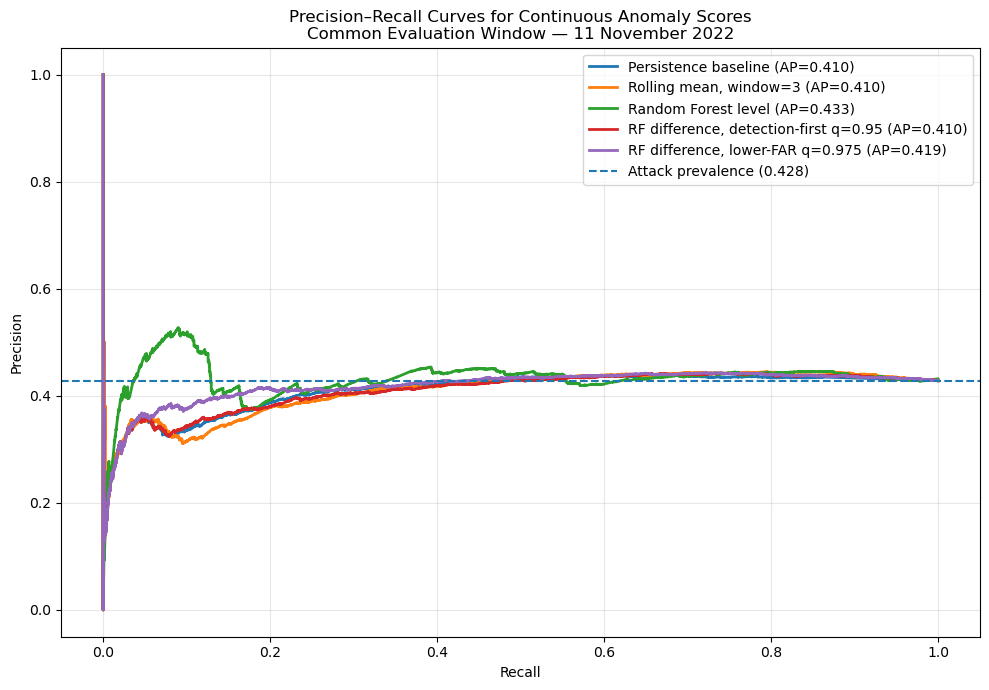

In [104]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 7))

for model_name, curve_df in precision_recall_curves.items():

    model_ap = threshold_independent_results.loc[
        threshold_independent_results["model"] == model_name,
        "average_precision"
    ].iloc[0]

    plt.plot(
        curve_df["recall"],
        curve_df["precision"],
        linewidth=2,
        label=f"{model_name} (AP={model_ap:.3f})"
    )

attack_prevalence = threshold_independent_results[
    "attack_prevalence"
].iloc[0]

plt.axhline(
    y=attack_prevalence,
    linestyle="--",
    label=f"Attack prevalence ({attack_prevalence:.3f})"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title(
    "Precision–Recall Curves for Continuous Anomaly Scores\n"
    "Common Evaluation Window — 11 November 2022"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "precision_recall_curves_11nov.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [105]:
event_6_information = final_rf_difference_event_results.loc[
    final_rf_difference_event_results["attack_event"] == 6
].iloc[0]

event_6_start = pd.to_datetime(
    event_6_information["start_time"]
)

event_6_end = pd.to_datetime(
    event_6_information["end_time"]
)

print("Event 6 start:", event_6_start)
print("Event 6 end:", event_6_end)
print(
    "Detected by lower-FAR configuration:",
    event_6_information["detected"]
)

Event 6 start: 2022-11-11 10:20:00
Event 6 end: 2022-11-11 10:22:00
Detected by lower-FAR configuration: 0


In [106]:
def summarise_rf_difference_event(
    pred_df,
    configuration_name,
    event_start,
    event_end,
    selected_sensors
):
    event_df = pred_df.loc[
        (pred_df["t_stamp"] >= event_start)
        & (pred_df["t_stamp"] <= event_end)
    ].copy()

    results = []

    for sensor in selected_sensors:

        normalized_col = (
            f"{sensor}_rf_difference_normalized_residual"
        )

        trigger_col = (
            f"{sensor}_rf_difference_triggered"
        )

        if normalized_col not in event_df.columns:
            continue

        results.append({
            "configuration": configuration_name,
            "sensor": sensor,
            "event_rows": len(event_df),
            "maximum_normalized_residual":
                event_df[normalized_col].max(),
            "mean_normalized_residual":
                event_df[normalized_col].mean(),
            "triggered_rows":
                int(event_df[trigger_col].sum()),
            "triggered_percentage":
                event_df[trigger_col].mean() * 100
        })

    return pd.DataFrame(results)

In [107]:
event_6_detection_first = summarise_rf_difference_event(
    pred_df=rf_difference_pred_df,
    configuration_name="Detection-first q=0.95",
    event_start=event_6_start,
    event_end=event_6_end,
    selected_sensors=top_sensors
)

event_6_lower_far = summarise_rf_difference_event(
    pred_df=final_rf_difference_pred_df,
    configuration_name="Lower-FAR q=0.975",
    event_start=event_6_start,
    event_end=event_6_end,
    selected_sensors=top_sensors
)

event_6_sensor_comparison = pd.concat(
    [
        event_6_detection_first,
        event_6_lower_far
    ],
    ignore_index=True
)

display(event_6_sensor_comparison)

event_6_sensor_comparison.to_csv(
    "attack_event_6_sensor_analysis_11nov.csv",
    index=False
)

,configuration,sensor,event_rows,maximum_normalized_residual,mean_normalized_residual,triggered_rows,triggered_percentage
0,Detection-first q=0.95,LIT101.Pv,121,0.437130,0.051734,0,0.000000
1,Detection-first q=0.95,AIT301.Pv,121,1.140565,0.050167,1,0.826446
2,Detection-first q=0.95,AIT302.Pv,121,0.871636,0.055892,0,0.000000
3,Detection-first q=0.95,FIT301.Pv,121,0.145478,0.002092,0,0.000000
4,Detection-first q=0.95,LIT301.Pv,121,0.539557,0.040252,0,0.000000
5,Lower-FAR q=0.975,LIT101.Pv,121,0.353731,0.041864,0,0.000000
6,Lower-FAR q=0.975,AIT301.Pv,121,0.757949,0.033338,0,0.000000
7,Lower-FAR q=0.975,AIT302.Pv,121,0.724749,0.046473,0,0.000000
8,Lower-FAR q=0.975,FIT301.Pv,121,0.029364,0.000422,0,0.000000
9,Lower-FAR q=0.975,LIT301.Pv,121,0.448223,0.033438,0,0.000000


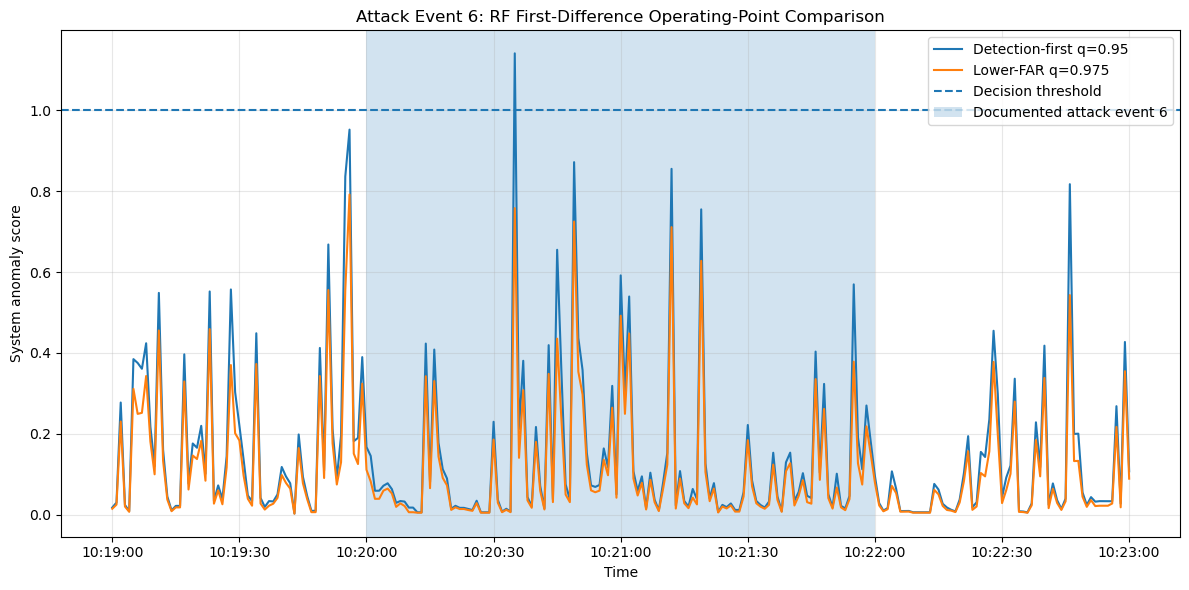

In [108]:
plot_start = event_6_start - pd.Timedelta(minutes=1)
plot_end = event_6_end + pd.Timedelta(minutes=1)

detection_first_window = rf_difference_pred_df.loc[
    (rf_difference_pred_df["t_stamp"] >= plot_start)
    & (rf_difference_pred_df["t_stamp"] <= plot_end)
].copy()

lower_far_window = final_rf_difference_pred_df.loc[
    (final_rf_difference_pred_df["t_stamp"] >= plot_start)
    & (final_rf_difference_pred_df["t_stamp"] <= plot_end)
].copy()

plt.figure(figsize=(12, 6))

plt.plot(
    detection_first_window["t_stamp"],
    detection_first_window["anomaly_score"],
    label="Detection-first q=0.95"
)

plt.plot(
    lower_far_window["t_stamp"],
    lower_far_window["anomaly_score"],
    label="Lower-FAR q=0.975"
)

plt.axhline(
    y=1,
    linestyle="--",
    label="Decision threshold"
)

plt.axvspan(
    event_6_start,
    event_6_end,
    alpha=0.2,
    label="Documented attack event 6"
)

plt.xlabel("Time")
plt.ylabel("System anomaly score")
plt.title(
    "Attack Event 6: RF First-Difference Operating-Point Comparison"
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "attack_event_6_anomaly_score_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [109]:
event_6_system_summary = pd.DataFrame([
    {
        "configuration": "Detection-first q=0.95",
        "maximum_anomaly_score":
            detection_first_window.loc[
                (detection_first_window["t_stamp"] >= event_6_start)
                & (detection_first_window["t_stamp"] <= event_6_end),
                "anomaly_score"
            ].max(),
        "anomaly_rows":
            int(
                detection_first_window.loc[
                    (detection_first_window["t_stamp"] >= event_6_start)
                    & (detection_first_window["t_stamp"] <= event_6_end),
                    "predicted_anomaly"
                ].sum()
            )
    },
    {
        "configuration": "Lower-FAR q=0.975",
        "maximum_anomaly_score":
            lower_far_window.loc[
                (lower_far_window["t_stamp"] >= event_6_start)
                & (lower_far_window["t_stamp"] <= event_6_end),
                "anomaly_score"
            ].max(),
        "anomaly_rows":
            int(
                lower_far_window.loc[
                    (lower_far_window["t_stamp"] >= event_6_start)
                    & (lower_far_window["t_stamp"] <= event_6_end),
                    "predicted_anomaly"
                ].sum()
            )
    }
])

display(event_6_system_summary)

event_6_system_summary.to_csv(
    "attack_event_6_system_summary_11nov.csv",
    index=False
)

,configuration,maximum_anomaly_score,anomaly_rows
0,Detection-first q=0.95,1.140565,1
1,Lower-FAR q=0.975,0.757949,0


In [110]:
pre_attack_normal_11 = (
    df11_clean.loc[
        (df11_clean["t_stamp"] < train_end_time_11)
        & (df11_clean["attack_label"] == 0)
    ]
    .sort_values("t_stamp")
    .copy()
)

common_split_index = int(
    len(pre_attack_normal_11) * 0.70
)

common_calibration_start = pd.to_datetime(
    pre_attack_normal_11.iloc[
        common_split_index
    ]["t_stamp"]
)

print("Pre-attack normal rows:", len(pre_attack_normal_11))
print("First 70% rows:", common_split_index)
print(
    "Final 30% calibration rows:",
    len(pre_attack_normal_11) - common_split_index
)
print("Calibration starts:", common_calibration_start)
print("Evaluation starts:", train_end_time_11)

Pre-attack normal rows: 3060
First 70% rows: 2142
Final 30% calibration rows: 918
Calibration starts: 2022-11-11 09:35:42
Evaluation starts: 2022-11-11 09:51:00


In [111]:
def build_common_calibrated_baseline(
    df_clean,
    selected_sensors,
    calibration_start,
    train_end_time,
    model_type="persistence",
    window=3,
    quantile=0.95,
    min_sensors_triggered=1
):
    df = df_clean.copy()

    df["t_stamp"] = pd.to_datetime(df["t_stamp"])
    calibration_start = pd.to_datetime(
        calibration_start
    )
    train_end_time = pd.to_datetime(
        train_end_time
    )

    df = (
        df.sort_values("t_stamp")
        .reset_index(drop=True)
    )

    if model_type not in {
        "persistence",
        "rolling_mean"
    }:
        raise ValueError(
            "model_type must be 'persistence' "
            "or 'rolling_mean'."
        )

    calibration_mask = (
        (df["t_stamp"] >= calibration_start)
        & (df["t_stamp"] < train_end_time)
        & (df["attack_label"] == 0)
    )

    normalized_cols = []
    trigger_cols = []
    thresholds = {}

    for sensor in selected_sensors:

        if model_type == "persistence":
            prefix = "persistence_common"
            prediction = df[sensor].shift(1)

        else:
            prefix = f"rolling_{window}_common"
            prediction = (
                df[sensor]
                .shift(1)
                .rolling(
                    window=window,
                    min_periods=1
                )
                .mean()
            )

        prediction_col = (
            f"{sensor}_{prefix}_prediction"
        )
        residual_col = (
            f"{sensor}_{prefix}_residual"
        )
        normalized_col = (
            f"{sensor}_{prefix}_normalized_residual"
        )
        trigger_col = (
            f"{sensor}_{prefix}_triggered"
        )

        df[prediction_col] = prediction

        df[residual_col] = (
            df[sensor] - df[prediction_col]
        ).abs()

        calibration_residuals = df.loc[
            calibration_mask,
            residual_col
        ].dropna()

        if calibration_residuals.empty:
            raise ValueError(
                f"No calibration residuals for {sensor}."
            )

        threshold = calibration_residuals.quantile(
            quantile
        )

        if pd.isna(threshold):
            raise ValueError(
                f"Threshold is NaN for {sensor}."
            )

        if threshold == 0:
            threshold = 1e-9

        thresholds[sensor] = threshold

        df[normalized_col] = (
            df[residual_col] / threshold
        )

        df[trigger_col] = (
            df[normalized_col] > 1
        ).astype(int)

        normalized_cols.append(normalized_col)
        trigger_cols.append(trigger_col)

    df["anomaly_score"] = df[
        normalized_cols
    ].max(axis=1)

    df["num_sensors_triggered"] = df[
        trigger_cols
    ].sum(axis=1)

    df["predicted_anomaly"] = (
        df["num_sensors_triggered"]
        >= min_sensors_triggered
    ).astype(int)

    return df, thresholds

In [112]:
(
    persistence_commoncal_pred_df,
    persistence_commoncal_thresholds
) = build_common_calibrated_baseline(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    calibration_start=common_calibration_start,
    train_end_time=train_end_time_11,
    model_type="persistence",
    quantile=0.95,
    min_sensors_triggered=1
)

(
    rolling_commoncal_pred_df,
    rolling_commoncal_thresholds
) = build_common_calibrated_baseline(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    calibration_start=common_calibration_start,
    train_end_time=train_end_time_11,
    model_type="rolling_mean",
    window=3,
    quantile=0.95,
    min_sensors_triggered=1
)

In [113]:
(
    persistence_commoncal_eval_df,
    persistence_commoncal_results,
    persistence_commoncal_events
) = evaluate_on_common_window(
    pred_df=persistence_commoncal_pred_df,
    model_name="Persistence — common calibration",
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

(
    rolling_commoncal_eval_df,
    rolling_commoncal_results,
    rolling_commoncal_events
) = evaluate_on_common_window(
    pred_df=rolling_commoncal_pred_df,
    model_name="Rolling mean w=3 — common calibration",
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

(
    rf_difference_95_eval_df,
    rf_difference_95_results,
    rf_difference_95_events
) = evaluate_on_common_window(
    pred_df=rf_difference_pred_df,
    model_name="RF difference — detection-first",
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

(
    rf_difference_975_eval_df,
    rf_difference_975_results,
    rf_difference_975_events
) = evaluate_on_common_window(
    pred_df=final_rf_difference_pred_df,
    model_name="RF difference — lower-FAR",
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

In [114]:
common_calibration_comparison = pd.DataFrame([
    persistence_commoncal_results,
    rolling_commoncal_results,
    rf_difference_95_results,
    rf_difference_975_results
])

display(
    common_calibration_comparison[
        [
            "model",
            "evaluation_rows",
            "attack_precision",
            "attack_recall",
            "attack_f1",
            "false_alarm_rate",
            "detected_events",
            "event_detection_rate",
            "average_detection_delay",
            "median_detection_delay",
            "maximum_detection_delay"
        ]
    ]
)

common_calibration_comparison.to_csv(
    "common_calibration_model_comparison_11nov.csv",
    index=False
)

,model,evaluation_rows,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence — common calibration,6767,0.436120,0.415948,0.425795,40.258398,17,100.000000,5.588235,1.0,35.0
1,Rolling mean w=3 — common calibration,6767,0.449294,0.493959,0.470569,45.322997,16,94.117647,10.312500,0.5,81.0
2,RF difference — detection-first,6767,0.409843,0.342078,0.372907,36.873385,17,100.000000,6.823529,2.0,35.0
3,RF difference — lower-FAR,6767,0.411335,0.233000,0.297488,24.961240,16,94.117647,9.437500,4.0,70.0


In [115]:
sensor_state_map = {
    "LIT101.Pv": "P1_STATE",
    "AIT301.Pv": "P3_STATE",
    "AIT302.Pv": "P3_STATE",
    "FIT301.Pv": "P3_STATE",
    "LIT301.Pv": "P3_STATE"
}

missing_state_columns = [
    state_col
    for state_col in set(sensor_state_map.values())
    if state_col not in persistence_commoncal_pred_df.columns
]

assert not missing_state_columns, (
    f"Missing state columns: {missing_state_columns}"
)

print("Sensor-to-state mapping:")
for sensor, state_col in sensor_state_map.items():
    print(f"{sensor} -> {state_col}")

Sensor-to-state mapping:
LIT101.Pv -> P1_STATE
AIT301.Pv -> P3_STATE
AIT302.Pv -> P3_STATE
FIT301.Pv -> P3_STATE
LIT301.Pv -> P3_STATE


In [116]:
state_calibration_rows = []

for sensor, state_col in sensor_state_map.items():

    sensor_state_counts = (
        persistence_commoncal_pred_df.loc[
            (
                persistence_commoncal_pred_df["t_stamp"]
                >= common_calibration_start
            )
            & (
                persistence_commoncal_pred_df["t_stamp"]
                < train_end_time_11
            )
            & (
                persistence_commoncal_pred_df["attack_label"]
                == 0
            ),
            state_col
        ]
        .fillna("MISSING")
        .astype(str)
        .value_counts()
        .rename_axis("state_value")
        .reset_index(name="calibration_rows")
    )

    sensor_state_counts.insert(
        0,
        "state_column",
        state_col
    )

    sensor_state_counts.insert(
        0,
        "sensor",
        sensor
    )

    state_calibration_rows.append(
        sensor_state_counts
    )

state_calibration_counts = pd.concat(
    state_calibration_rows,
    ignore_index=True
)

display(state_calibration_counts)

state_calibration_counts.to_csv(
    "state_calibration_counts_11nov.csv",
    index=False
)

,sensor,state_column,state_value,calibration_rows
0,LIT101.Pv,P1_STATE,2,918
1,AIT301.Pv,P3_STATE,7,770
2,AIT301.Pv,P3_STATE,99,90
3,AIT301.Pv,P3_STATE,4,31
4,AIT301.Pv,P3_STATE,2,9
5,AIT301.Pv,P3_STATE,5,9
6,AIT301.Pv,P3_STATE,6,9
7,AIT302.Pv,P3_STATE,7,770
8,AIT302.Pv,P3_STATE,99,90
9,AIT302.Pv,P3_STATE,4,31


In [117]:
def build_state_conditioned_detector(
    base_pred_df,
    selected_sensors,
    sensor_state_map,
    residual_suffix,
    calibration_start,
    train_end_time,
    quantile=0.95,
    min_state_rows=50,
    min_sensors_triggered=1
):
    df = base_pred_df.copy()

    df["t_stamp"] = pd.to_datetime(
        df["t_stamp"]
    )

    calibration_start = pd.to_datetime(
        calibration_start
    )

    train_end_time = pd.to_datetime(
        train_end_time
    )

    df = (
        df.sort_values("t_stamp")
        .reset_index(drop=True)
    )

    calibration_mask = (
        (df["t_stamp"] >= calibration_start)
        & (df["t_stamp"] < train_end_time)
        & (df["attack_label"] == 0)
    )

    normalized_columns = []
    trigger_columns = []
    threshold_records = []

    for sensor in selected_sensors:

        if sensor not in sensor_state_map:
            raise KeyError(
                f"No state mapping provided for {sensor}."
            )

        state_col = sensor_state_map[sensor]

        residual_col = (
            f"{sensor}_{residual_suffix}"
        )

        if residual_col not in df.columns:
            raise KeyError(
                f"Missing residual column: {residual_col}"
            )

        if state_col not in df.columns:
            raise KeyError(
                f"Missing state column: {state_col}"
            )

        state_key_col = (
            f"{sensor}_state_threshold_key"
        )

        threshold_col = (
            f"{sensor}_state_threshold"
        )

        normalized_col = (
            f"{sensor}_state_normalized_residual"
        )

        trigger_col = (
            f"{sensor}_state_triggered"
        )

        df[state_key_col] = (
            df[state_col]
            .fillna("MISSING")
            .astype(str)
        )

        calibration_df = df.loc[
            calibration_mask,
            [state_key_col, residual_col]
        ].dropna(
            subset=[residual_col]
        )

        if calibration_df.empty:
            raise ValueError(
                f"No calibration residuals for {sensor}."
            )

        global_threshold = (
            calibration_df[residual_col]
            .quantile(quantile)
        )

        if pd.isna(global_threshold):
            raise ValueError(
                f"Global threshold is NaN for {sensor}."
            )

        global_threshold = max(
            float(global_threshold),
            1e-9
        )

        state_counts = (
            calibration_df
            .groupby(state_key_col)[residual_col]
            .count()
            .rename("state_rows")
        )

        state_quantiles = (
            calibration_df
            .groupby(state_key_col)[residual_col]
            .quantile(quantile)
            .rename("state_specific_threshold")
        )

        state_table = pd.concat(
            [
                state_counts,
                state_quantiles
            ],
            axis=1
        ).reset_index()

        state_table[
            "uses_state_specific_threshold"
        ] = (
            state_table["state_rows"]
            >= min_state_rows
        ) & (
            state_table[
                "state_specific_threshold"
            ].notna()
        )

        state_table["applied_threshold"] = np.where(
            state_table[
                "uses_state_specific_threshold"
            ],
            state_table[
                "state_specific_threshold"
            ],
            global_threshold
        )

        state_table["applied_threshold"] = (
            pd.to_numeric(
                state_table["applied_threshold"],
                errors="coerce"
            )
            .fillna(global_threshold)
            .clip(lower=1e-9)
        )

        threshold_map = (
            state_table
            .set_index(state_key_col)[
                "applied_threshold"
            ]
            .to_dict()
        )

        df[threshold_col] = (
            df[state_key_col]
            .map(threshold_map)
            .fillna(global_threshold)
            .astype(float)
        )

        df[normalized_col] = (
            df[residual_col]
            / df[threshold_col]
        )

        df[trigger_col] = (
            df[normalized_col] > 1
        ).astype(int)

        normalized_columns.append(
            normalized_col
        )

        trigger_columns.append(
            trigger_col
        )

        state_table.insert(
            0,
            "sensor",
            sensor
        )

        state_table.insert(
            1,
            "state_column",
            state_col
        )

        state_table["global_threshold"] = (
            global_threshold
        )

        state_table["quantile"] = quantile
        state_table["min_state_rows"] = (
            min_state_rows
        )

        threshold_records.append(
            state_table
        )

    df["anomaly_score"] = (
        df[normalized_columns]
        .max(axis=1)
    )

    df["num_sensors_triggered"] = (
        df[trigger_columns]
        .sum(axis=1)
    )

    df["predicted_anomaly"] = (
        df["num_sensors_triggered"]
        >= min_sensors_triggered
    ).astype(int)

    threshold_details = pd.concat(
        threshold_records,
        ignore_index=True
    )

    return df, threshold_details

In [118]:
(
    persistence_state_pred_df,
    persistence_state_threshold_details
) = build_state_conditioned_detector(
    base_pred_df=persistence_commoncal_pred_df,
    selected_sensors=top_sensors,
    sensor_state_map=sensor_state_map,
    residual_suffix="persistence_common_residual",
    calibration_start=common_calibration_start,
    train_end_time=train_end_time_11,
    quantile=0.95,
    min_state_rows=50,
    min_sensors_triggered=1
)

display(
    persistence_state_threshold_details
)

,sensor,state_column,LIT101.Pv_state_threshold_key,state_rows,state_specific_threshold,uses_state_specific_threshold,applied_threshold,global_threshold,quantile,min_state_rows,AIT301.Pv_state_threshold_key,AIT302.Pv_state_threshold_key,FIT301.Pv_state_threshold_key,LIT301.Pv_state_threshold_key
0,LIT101.Pv,P1_STATE,2,918,0.824300,True,8.243000e-01,0.824300,0.95,50,NaN,NaN,NaN,NaN
1,AIT301.Pv,P3_STATE,NaN,9,0.000000,False,4.577439e-03,0.004577,0.95,50,2,NaN,NaN,NaN
2,AIT301.Pv,P3_STATE,NaN,31,0.002913,False,4.577439e-03,0.004577,0.95,50,4,NaN,NaN,NaN
3,AIT301.Pv,P3_STATE,NaN,9,0.000000,False,4.577439e-03,0.004577,0.95,50,5,NaN,NaN,NaN
4,AIT301.Pv,P3_STATE,NaN,9,0.003329,False,4.577439e-03,0.004577,0.95,50,6,NaN,NaN,NaN
5,AIT301.Pv,P3_STATE,NaN,770,0.005639,True,5.638800e-03,0.004577,0.95,50,7,NaN,NaN,NaN
6,AIT301.Pv,P3_STATE,NaN,90,0.000000,True,1.000000e-09,0.004577,0.95,50,99,NaN,NaN,NaN
7,AIT302.Pv,P3_STATE,NaN,9,0.000000,False,6.146336e-01,0.614634,0.95,50,NaN,2,NaN,NaN
8,AIT302.Pv,P3_STATE,NaN,31,0.332925,False,6.146336e-01,0.614634,0.95,50,NaN,4,NaN,NaN
9,AIT302.Pv,P3_STATE,NaN,9,0.000000,False,6.146336e-01,0.614634,0.95,50,NaN,5,NaN,NaN


In [119]:
(
    persistence_state_eval_df,
    persistence_state_results,
    persistence_state_events
) = evaluate_on_common_window(
    pred_df=persistence_state_pred_df,
    model_name=(
        "Persistence — state-conditioned thresholds"
    ),
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

print("State-conditioned persistence results:")
print(persistence_state_results)

display(persistence_state_events)

State-conditioned persistence results:
{'model': 'Persistence — state-conditioned thresholds', 'evaluation_start': Timestamp('2022-11-11 09:51:00'), 'evaluation_rows': 6767, 'normal_rows': 3870, 'attack_rows': 2897, 'accuracy': 0.5040638392197428, 'attack_precision': np.float64(0.436794271550537), 'attack_recall': np.float64(0.5474628926475664), 'attack_f1': np.float64(0.48590686274509803), 'true_normal': np.int64(1825), 'false_alarm': np.int64(2045), 'missed_attack': np.int64(1311), 'detected_attack_rows': np.int64(1586), 'false_alarm_rate': np.float64(52.84237726098191), 'detected_events': 17, 'total_events': 17, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(1.9411764705882353), 'median_detection_delay': 0.0, 'maximum_detection_delay': 14.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:01,1.0,241,186
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:02,2.0,121,39
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:04,4.0,121,61
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:00,0.0,181,118
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:14,14.0,181,77
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,1,2022-11-11 10:20:01,1.0,121,12
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:00,0.0,121,70
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:07,7.0,181,56
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:00,0.0,181,58
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:00,0.0,181,125


In [120]:
state_threshold_initial_comparison = pd.DataFrame([
    persistence_commoncal_results,
    persistence_state_results,
    rf_difference_95_results,
    rf_difference_975_results
])

comparison_columns_state = [
    "model",
    "evaluation_rows",
    "accuracy",
    "attack_precision",
    "attack_recall",
    "attack_f1",
    "false_alarm_rate",
    "detected_events",
    "event_detection_rate",
    "average_detection_delay",
    "median_detection_delay",
    "maximum_detection_delay"
]

display(
    state_threshold_initial_comparison[
        comparison_columns_state
    ]
)

state_threshold_initial_comparison.to_csv(
    "initial_state_threshold_comparison_11nov.csv",
    index=False
)

persistence_state_threshold_details.to_csv(
    "persistence_state_threshold_details_11nov.csv",
    index=False
)

persistence_state_events.to_csv(
    "persistence_state_event_results_11nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence — common calibration,6767,0.519728,0.436120,0.415948,0.425795,40.258398,17,100.000000,5.588235,1.0,35.0
1,Persistence — state-conditioned thresholds,6767,0.504064,0.436794,0.547463,0.485907,52.842377,17,100.000000,1.941176,0.0,14.0
2,RF difference — detection-first,6767,0.507463,0.409843,0.342078,0.372907,36.873385,17,100.000000,6.823529,2.0,35.0
3,RF difference — lower-FAR,6767,0.528890,0.411335,0.233000,0.297488,24.961240,16,94.117647,9.437500,4.0,70.0


In [121]:
state_tuning_results = []
state_tuning_predictions = {}
state_tuning_thresholds = {}

state_quantiles = [
    0.90,
    0.95,
    0.975,
    0.99
]

minimum_state_rows_options = [
    25,
    50,
    100
]

state_sensor_votes = [
    1,
    2
]

for quantile in state_quantiles:

    for min_state_rows in (
        minimum_state_rows_options
    ):

        for min_sensor_votes in (
            state_sensor_votes
        ):

            (
                temp_state_pred_df,
                temp_state_threshold_details
            ) = build_state_conditioned_detector(
                base_pred_df=(
                    persistence_commoncal_pred_df
                ),
                selected_sensors=top_sensors,
                sensor_state_map=sensor_state_map,
                residual_suffix=(
                    "persistence_common_residual"
                ),
                calibration_start=(
                    common_calibration_start
                ),
                train_end_time=train_end_time_11,
                quantile=quantile,
                min_state_rows=min_state_rows,
                min_sensors_triggered=(
                    min_sensor_votes
                )
            )

            (
                _,
                temp_state_results,
                temp_state_events
            ) = evaluate_on_common_window(
                pred_df=temp_state_pred_df,
                model_name=(
                    "Persistence state-conditioned"
                ),
                evaluation_start=train_end_time_11,
                attack_intervals=intervals_11
            )

            detected_delays = pd.to_numeric(
                temp_state_events.loc[
                    temp_state_events[
                        "detected"
                    ].eq(1),
                    "detection_delay_seconds"
                ],
                errors="coerce"
            ).dropna()

            config_key = (
                quantile,
                min_state_rows,
                min_sensor_votes
            )

            state_tuning_predictions[
                config_key
            ] = temp_state_pred_df

            state_tuning_thresholds[
                config_key
            ] = temp_state_threshold_details

            state_tuning_results.append({
                "quantile": quantile,
                "min_state_rows": min_state_rows,
                "min_sensors_triggered":
                    min_sensor_votes,
                "accuracy":
                    temp_state_results[
                        "accuracy"
                    ],
                "attack_precision":
                    temp_state_results[
                        "attack_precision"
                    ],
                "attack_recall":
                    temp_state_results[
                        "attack_recall"
                    ],
                "attack_f1":
                    temp_state_results[
                        "attack_f1"
                    ],
                "false_alarm_rate":
                    temp_state_results[
                        "false_alarm_rate"
                    ],
                "detected_events":
                    temp_state_results[
                        "detected_events"
                    ],
                "event_detection_rate":
                    temp_state_results[
                        "event_detection_rate"
                    ],
                "average_detection_delay":
                    detected_delays.mean(),
                "median_detection_delay":
                    detected_delays.median(),
                "maximum_detection_delay":
                    detected_delays.max()
            })

state_tuning_df = pd.DataFrame(
    state_tuning_results
).sort_values(
    by=[
        "event_detection_rate",
        "false_alarm_rate",
        "attack_f1",
        "average_detection_delay"
    ],
    ascending=[
        False,
        True,
        False,
        True
    ]
).reset_index(drop=True)

display(state_tuning_df)

state_tuning_df.to_csv(
    "state_conditioned_threshold_tuning_11nov.csv",
    index=False
)

,quantile,min_state_rows,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.990,25,1,0.546328,0.464737,0.393511,0.426168,33.927649,17,100.000000,5.176471,1.0,26.0
1,0.990,50,1,0.537461,0.453493,0.392130,0.420585,35.374677,17,100.000000,6.000000,1.0,26.0
2,0.950,100,1,0.522684,0.438899,0.412841,0.425471,39.509044,17,100.000000,5.588235,1.0,35.0
3,0.975,25,1,0.531550,0.452915,0.453227,0.453071,40.981912,17,100.000000,3.235294,1.0,22.0
4,0.975,50,1,0.519433,0.440376,0.452537,0.446374,43.049096,17,100.000000,4.058824,1.0,22.0
5,0.950,25,1,0.518398,0.448841,0.548153,0.493551,50.387597,17,100.000000,1.941176,0.0,14.0
6,0.950,50,1,0.504064,0.436794,0.547463,0.485907,52.842377,17,100.000000,1.941176,0.0,14.0
7,0.900,100,1,0.503325,0.436957,0.555057,0.488977,53.540052,17,100.000000,4.882353,0.0,35.0
8,0.900,25,1,0.497266,0.440208,0.641698,0.522191,61.085271,17,100.000000,1.705882,0.0,14.0
9,0.900,50,1,0.486478,0.432791,0.642389,0.517160,63.023256,17,100.000000,1.705882,0.0,14.0


In [122]:
state_full_detection_candidates = (
    state_tuning_df.loc[
        state_tuning_df[
            "detected_events"
        ] == len(intervals_11)
    ]
    .sort_values(
        by=[
            "false_alarm_rate",
            "attack_f1",
            "average_detection_delay"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

display(state_full_detection_candidates)

if state_full_detection_candidates.empty:

    print(
        "No state-conditioned configuration "
        "detected all attack events."
    )

    selected_state_config = (
        state_tuning_df.iloc[0]
    )

else:

    selected_state_config = (
        state_full_detection_candidates.iloc[0]
    )

print("\nSelected state-conditioned configuration:")
display(
    selected_state_config.to_frame().T
)

,quantile,min_state_rows,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.990,25,1,0.546328,0.464737,0.393511,0.426168,33.927649,17,100.0,5.176471,1.0,26.0
1,0.990,50,1,0.537461,0.453493,0.392130,0.420585,35.374677,17,100.0,6.000000,1.0,26.0
2,0.950,100,1,0.522684,0.438899,0.412841,0.425471,39.509044,17,100.0,5.588235,1.0,35.0
3,0.975,25,1,0.531550,0.452915,0.453227,0.453071,40.981912,17,100.0,3.235294,1.0,22.0
4,0.975,50,1,0.519433,0.440376,0.452537,0.446374,43.049096,17,100.0,4.058824,1.0,22.0
5,0.950,25,1,0.518398,0.448841,0.548153,0.493551,50.387597,17,100.0,1.941176,0.0,14.0
6,0.950,50,1,0.504064,0.436794,0.547463,0.485907,52.842377,17,100.0,1.941176,0.0,14.0
7,0.900,100,1,0.503325,0.436957,0.555057,0.488977,53.540052,17,100.0,4.882353,0.0,35.0
8,0.900,25,1,0.497266,0.440208,0.641698,0.522191,61.085271,17,100.0,1.705882,0.0,14.0
9,0.900,50,1,0.486478,0.432791,0.642389,0.517160,63.023256,17,100.0,1.705882,0.0,14.0



Selected state-conditioned configuration:


,quantile,min_state_rows,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.99,25.0,1.0,0.546328,0.464737,0.393511,0.426168,33.927649,17.0,100.0,5.176471,1.0,26.0


In [123]:
selected_state_quantile = float(
    selected_state_config["quantile"]
)

selected_min_state_rows = int(
    selected_state_config["min_state_rows"]
)

selected_state_sensor_votes = int(
    selected_state_config[
        "min_sensors_triggered"
    ]
)

selected_state_key = (
    selected_state_quantile,
    selected_min_state_rows,
    selected_state_sensor_votes
)

selected_state_pred_df = (
    state_tuning_predictions[
        selected_state_key
    ]
)

selected_state_threshold_details = (
    state_tuning_thresholds[
        selected_state_key
    ]
)

(
    selected_state_eval_df,
    selected_state_results,
    selected_state_events
) = evaluate_on_common_window(
    pred_df=selected_state_pred_df,
    model_name=(
        "Selected persistence "
        "state-conditioned detector"
    ),
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

print(selected_state_results)

display(selected_state_events)

{'model': 'Selected persistence state-conditioned detector', 'evaluation_start': Timestamp('2022-11-11 09:51:00'), 'evaluation_rows': 6767, 'normal_rows': 3870, 'attack_rows': 2897, 'accuracy': 0.5463277671050687, 'attack_precision': np.float64(0.4647370566653078), 'attack_recall': np.float64(0.39351052813255094), 'attack_f1': np.float64(0.4261682242990654), 'true_normal': np.int64(2557), 'false_alarm': np.int64(1313), 'missed_attack': np.int64(1757), 'detected_attack_rows': np.int64(1140), 'false_alarm_rate': np.float64(33.92764857881137), 'detected_events': 17, 'total_events': 17, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(5.176470588235294), 'median_detection_delay': 1.0, 'maximum_detection_delay': 26.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:11,11.0,241,144
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:08,8.0,121,26
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:04,4.0,121,51
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:00,0.0,181,94
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:20,20.0,181,59
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,1,2022-11-11 10:20:01,1.0,121,9
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:00,0.0,121,29
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:26,26.0,181,22
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:01,1.0,181,38
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:00,0.0,181,96


In [124]:
state_model_comparison = pd.DataFrame([
    persistence_commoncal_results,
    rolling_commoncal_results,
    rf_difference_95_results,
    rf_difference_975_results,
    selected_state_results
])

display(
    state_model_comparison[
        comparison_columns_state
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate"
        ],
        ascending=[
            False,
            True
        ]
    )
)

state_model_comparison.to_csv(
    "state_conditioned_final_comparison_11nov.csv",
    index=False
)

selected_state_threshold_details.to_csv(
    "selected_state_thresholds_11nov.csv",
    index=False
)

selected_state_events.to_csv(
    "selected_state_event_results_11nov.csv",
    index=False
)

print("State-conditioned results saved.")

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
4,Selected persistence state-conditioned detector,6767,0.546328,0.464737,0.393511,0.426168,33.927649,17,100.000000,5.176471,1.0,26.0
2,RF difference — detection-first,6767,0.507463,0.409843,0.342078,0.372907,36.873385,17,100.000000,6.823529,2.0,35.0
0,Persistence — common calibration,6767,0.519728,0.436120,0.415948,0.425795,40.258398,17,100.000000,5.588235,1.0,35.0
3,RF difference — lower-FAR,6767,0.528890,0.411335,0.233000,0.297488,24.961240,16,94.117647,9.437500,4.0,70.0
1,Rolling mean w=3 — common calibration,6767,0.524161,0.449294,0.493959,0.470569,45.322997,16,94.117647,10.312500,0.5,81.0


State-conditioned results saved.


# Matched-Quantile State-Conditioning Comparison

In [125]:
(
    persistence_global_99_pred_df,
    persistence_global_99_thresholds
) = build_common_calibrated_baseline(
    df_clean=df11_clean,
    selected_sensors=top_sensors,
    calibration_start=common_calibration_start,
    train_end_time=train_end_time_11,
    model_type="persistence",
    quantile=selected_state_quantile,
    min_sensors_triggered=selected_state_sensor_votes
)

(
    persistence_global_99_eval_df,
    persistence_global_99_results,
    persistence_global_99_events
) = evaluate_on_common_window(
    pred_df=persistence_global_99_pred_df,
    model_name="Persistence global threshold q=0.99",
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

print(persistence_global_99_results)

display(persistence_global_99_events)

{'model': 'Persistence global threshold q=0.99', 'evaluation_start': Timestamp('2022-11-11 09:51:00'), 'evaluation_rows': 6767, 'normal_rows': 3870, 'attack_rows': 2897, 'accuracy': 0.5540121176296734, 'attack_precision': np.float64(0.45069274653626734), 'attack_recall': np.float64(0.19088712461166724), 'attack_f1': np.float64(0.26818622696411254), 'true_normal': np.int64(3196), 'false_alarm': np.int64(674), 'missed_attack': np.int64(2344), 'detected_attack_rows': np.int64(553), 'false_alarm_rate': np.float64(17.416020671834627), 'detected_events': 15, 'total_events': 17, 'event_detection_rate': np.float64(88.23529411764706), 'average_detection_delay': np.float64(11.6), 'median_detection_delay': 4.0, 'maximum_detection_delay': 51.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:11,11.0,241,59
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,0,NaT,NaN,121,0
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:04,4.0,121,43
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:00,0.0,181,49
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:51,51.0,181,52
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,0,NaT,NaN,121,0
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:14,14.0,121,19
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:26,26.0,181,20
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:01,1.0,181,11
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:05,5.0,181,44


In [126]:
matched_quantile_comparison = pd.DataFrame([
    persistence_global_99_results,
    selected_state_results
])

matched_quantile_columns = [
    "model",
    "evaluation_rows",
    "accuracy",
    "attack_precision",
    "attack_recall",
    "attack_f1",
    "false_alarm_rate",
    "detected_events",
    "event_detection_rate",
    "average_detection_delay",
    "median_detection_delay",
    "maximum_detection_delay"
]

display(
    matched_quantile_comparison[
        matched_quantile_columns
    ]
)

matched_quantile_comparison.to_csv(
    "matched_quantile_state_comparison_11nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence global threshold q=0.99,6767,0.554012,0.450693,0.190887,0.268186,17.416021,15,88.235294,11.600000,4.0,51.0
1,Selected persistence state-conditioned detector,6767,0.546328,0.464737,0.393511,0.426168,33.927649,17,100.000000,5.176471,1.0,26.0


In [127]:
state_conditioning_effect = pd.DataFrame({
    "metric": [
        "false_alarm_rate",
        "attack_precision",
        "attack_recall",
        "attack_f1",
        "detected_events",
        "average_detection_delay"
    ],
    "global_q99": [
        persistence_global_99_results[
            "false_alarm_rate"
        ],
        persistence_global_99_results[
            "attack_precision"
        ],
        persistence_global_99_results[
            "attack_recall"
        ],
        persistence_global_99_results[
            "attack_f1"
        ],
        persistence_global_99_results[
            "detected_events"
        ],
        persistence_global_99_results[
            "average_detection_delay"
        ]
    ],
    "state_conditioned_q99": [
        selected_state_results[
            "false_alarm_rate"
        ],
        selected_state_results[
            "attack_precision"
        ],
        selected_state_results[
            "attack_recall"
        ],
        selected_state_results[
            "attack_f1"
        ],
        selected_state_results[
            "detected_events"
        ],
        selected_state_results[
            "average_detection_delay"
        ]
    ]
})

state_conditioning_effect["state_minus_global"] = (
    state_conditioning_effect[
        "state_conditioned_q99"
    ]
    - state_conditioning_effect["global_q99"]
)

display(state_conditioning_effect)

state_conditioning_effect.to_csv(
    "state_conditioning_effect_11nov.csv",
    index=False
)

,metric,global_q99,state_conditioned_q99,state_minus_global
0,false_alarm_rate,17.416021,33.927649,16.511628
1,attack_precision,0.450693,0.464737,0.014044
2,attack_recall,0.190887,0.393511,0.202623
3,attack_f1,0.268186,0.426168,0.157982
4,detected_events,15.000000,17.000000,2.000000
5,average_detection_delay,11.600000,5.176471,-6.423529


In [128]:
def fit_frozen_state_threshold_bundle(
    base_pred_df,
    selected_sensors,
    sensor_state_map,
    residual_suffix,
    calibration_start,
    calibration_end,
    quantile=0.99,
    min_state_rows=25
):
    df = base_pred_df.copy()

    df["t_stamp"] = pd.to_datetime(
        df["t_stamp"]
    )

    calibration_start = pd.to_datetime(
        calibration_start
    )

    calibration_end = pd.to_datetime(
        calibration_end
    )

    calibration_mask = (
        (df["t_stamp"] >= calibration_start)
        & (df["t_stamp"] < calibration_end)
        & (df["attack_label"] == 0)
    )

    threshold_bundle = {}
    threshold_records = []

    for sensor in selected_sensors:

        state_col = sensor_state_map[sensor]

        residual_col = (
            f"{sensor}_{residual_suffix}"
        )

        if state_col not in df.columns:
            raise KeyError(
                f"Missing state column: {state_col}"
            )

        if residual_col not in df.columns:
            raise KeyError(
                f"Missing residual column: {residual_col}"
            )

        calibration_df = df.loc[
            calibration_mask,
            [state_col, residual_col]
        ].copy()

        calibration_df = calibration_df.dropna(
            subset=[residual_col]
        )

        calibration_df["state_key"] = (
            calibration_df[state_col]
            .astype("string")
            .fillna("MISSING")
        )

        if calibration_df.empty:
            raise ValueError(
                f"No calibration rows for {sensor}."
            )

        global_threshold = float(
            calibration_df[residual_col]
            .quantile(quantile)
        )

        global_threshold = max(
            global_threshold,
            1e-9
        )

        state_counts = (
            calibration_df
            .groupby("state_key")[residual_col]
            .count()
            .rename("state_rows")
        )

        state_quantiles = (
            calibration_df
            .groupby("state_key")[residual_col]
            .quantile(quantile)
            .rename("state_specific_threshold")
        )

        state_table = pd.concat(
            [
                state_counts,
                state_quantiles
            ],
            axis=1
        ).reset_index()

        state_table[
            "uses_state_specific_threshold"
        ] = (
            state_table["state_rows"]
            >= min_state_rows
        )

        state_table["applied_threshold"] = np.where(
            state_table[
                "uses_state_specific_threshold"
            ],
            state_table[
                "state_specific_threshold"
            ],
            global_threshold
        )

        state_table["applied_threshold"] = (
            pd.to_numeric(
                state_table["applied_threshold"],
                errors="coerce"
            )
            .fillna(global_threshold)
            .clip(lower=1e-9)
        )

        state_threshold_map = (
            state_table
            .set_index("state_key")[
                "applied_threshold"
            ]
            .to_dict()
        )

        threshold_bundle[sensor] = {
            "state_column": state_col,
            "global_threshold": global_threshold,
            "state_thresholds": state_threshold_map
        }

        state_table.insert(
            0,
            "sensor",
            sensor
        )

        state_table.insert(
            1,
            "state_column",
            state_col
        )

        state_table["global_threshold"] = (
            global_threshold
        )

        state_table["quantile"] = quantile

        state_table["min_state_rows"] = (
            min_state_rows
        )

        threshold_records.append(
            state_table
        )

    threshold_details = pd.concat(
        threshold_records,
        ignore_index=True
    )

    return threshold_bundle, threshold_details

In [129]:
(
    frozen_state_threshold_bundle,
    frozen_state_threshold_details
) = fit_frozen_state_threshold_bundle(
    base_pred_df=persistence_global_99_pred_df,
    selected_sensors=top_sensors,
    sensor_state_map=sensor_state_map,
    residual_suffix="persistence_common_residual",
    calibration_start=common_calibration_start,
    calibration_end=train_end_time_11,
    quantile=selected_state_quantile,
    min_state_rows=selected_min_state_rows
)

display(frozen_state_threshold_details)

frozen_state_threshold_details.to_csv(
    "frozen_state_threshold_bundle_11nov.csv",
    index=False
)

,sensor,state_column,state_key,state_rows,state_specific_threshold,uses_state_specific_threshold,applied_threshold,global_threshold,quantile,min_state_rows
0,LIT101.Pv,P1_STATE,2,918,1.177630,True,1.177630e+00,1.177630,0.99,25
1,AIT301.Pv,P3_STATE,2,9,0.000000,False,1.033295e-02,0.010333,0.99,25
2,AIT301.Pv,P3_STATE,4,31,0.006409,True,6.408800e-03,0.010333,0.99,25
3,AIT301.Pv,P3_STATE,5,9,0.000000,False,1.033295e-02,0.010333,0.99,25
4,AIT301.Pv,P3_STATE,6,9,0.003995,False,1.033295e-02,0.010333,0.99,25
5,AIT301.Pv,P3_STATE,7,770,0.010949,True,1.094941e-02,0.010333,0.99,25
6,AIT301.Pv,P3_STATE,99,90,0.000553,True,5.531515e-04,0.010333,0.99,25
7,AIT302.Pv,P3_STATE,2,9,0.000000,False,8.451350e-01,0.845135,0.99,25
8,AIT302.Pv,P3_STATE,4,31,0.419989,True,4.199886e-01,0.845135,0.99,25
9,AIT302.Pv,P3_STATE,5,9,0.000000,False,8.451350e-01,0.845135,0.99,25


In [130]:
for sensor in top_sensors:

    sensor_bundle = (
        frozen_state_threshold_bundle[sensor]
    )

    print("\nSensor:", sensor)

    print(
        "State column:",
        sensor_bundle["state_column"]
    )

    print(
        "Global threshold:",
        sensor_bundle["global_threshold"]
    )

    print(
        "Number of stored states:",
        len(
            sensor_bundle[
                "state_thresholds"
            ]
        )
    )


Sensor: LIT101.Pv
State column: P1_STATE
Global threshold: 1.177630260000002
Number of stored states: 1

Sensor: AIT301.Pv
State column: P3_STATE
Global threshold: 0.010332945699999917
Number of stored states: 6

Sensor: AIT302.Pv
State column: P3_STATE
Global threshold: 0.8451349800000275
Number of stored states: 6

Sensor: FIT301.Pv
State column: P3_STATE
Global threshold: 0.0503167654200004
Number of stored states: 6

Sensor: LIT301.Pv
State column: P3_STATE
Global threshold: 1.2748553400000076
Number of stored states: 6


In [131]:
def apply_frozen_persistence_detector(
    df_clean,
    selected_sensors,
    threshold_bundle,
    min_sensors_triggered=1,
    use_state_thresholds=True
):
    df = df_clean.copy()

    df["t_stamp"] = pd.to_datetime(
        df["t_stamp"]
    )

    df = (
        df.sort_values("t_stamp")
        .reset_index(drop=True)
    )

    normalized_columns = []
    trigger_columns = []

    for sensor in selected_sensors:

        if sensor not in threshold_bundle:
            raise KeyError(
                f"No frozen threshold for {sensor}."
            )

        sensor_bundle = threshold_bundle[sensor]

        state_col = sensor_bundle[
            "state_column"
        ]

        global_threshold = float(
            sensor_bundle[
                "global_threshold"
            ]
        )

        state_threshold_map = sensor_bundle[
            "state_thresholds"
        ]

        prediction_col = (
            f"{sensor}_frozen_prediction"
        )

        residual_col = (
            f"{sensor}_frozen_residual"
        )

        threshold_col = (
            f"{sensor}_frozen_threshold"
        )

        normalized_col = (
            f"{sensor}_frozen_normalized_residual"
        )

        trigger_col = (
            f"{sensor}_frozen_triggered"
        )

        df[prediction_col] = (
            df[sensor].shift(1)
        )

        df[residual_col] = (
            df[sensor]
            - df[prediction_col]
        ).abs()

        if use_state_thresholds:

            if state_col not in df.columns:
                raise KeyError(
                    f"Missing state column: {state_col}"
                )

            state_keys = (
                df[state_col]
                .astype("string")
                .fillna("MISSING")
            )

            df[threshold_col] = (
                state_keys
                .map(state_threshold_map)
                .fillna(global_threshold)
                .astype(float)
            )

        else:

            df[threshold_col] = (
                global_threshold
            )

        df[normalized_col] = (
            df[residual_col]
            / df[threshold_col]
        )

        df[trigger_col] = (
            df[normalized_col] > 1
        ).astype(int)

        normalized_columns.append(
            normalized_col
        )

        trigger_columns.append(
            trigger_col
        )

    df["anomaly_score"] = (
        df[normalized_columns]
        .max(axis=1)
    )

    df["num_sensors_triggered"] = (
        df[trigger_columns]
        .sum(axis=1)
    )

    df["predicted_anomaly"] = (
        df["num_sensors_triggered"]
        >= min_sensors_triggered
    ).astype(int)

    return df

In [132]:
frozen_global_10_pred_df = (
    apply_frozen_persistence_detector(
        df_clean=df10_clean,
        selected_sensors=top_sensors,
        threshold_bundle=(
            frozen_state_threshold_bundle
        ),
        min_sensors_triggered=(
            selected_state_sensor_votes
        ),
        use_state_thresholds=False
    )
)

frozen_state_10_pred_df = (
    apply_frozen_persistence_detector(
        df_clean=df10_clean,
        selected_sensors=top_sensors,
        threshold_bundle=(
            frozen_state_threshold_bundle
        ),
        min_sensors_triggered=(
            selected_state_sensor_votes
        ),
        use_state_thresholds=True
    )
)

print(
    "Frozen global rows:",
    len(frozen_global_10_pred_df)
)

print(
    "Frozen state-conditioned rows:",
    len(frozen_state_10_pred_df)
)

Frozen global rows: 3601
Frozen state-conditioned rows: 3601


In [133]:
evaluation_start_10 = pd.to_datetime(
    df10_clean["t_stamp"].min()
)

(
    frozen_global_10_eval_df,
    frozen_global_10_results,
    frozen_global_10_events
) = evaluate_on_common_window(
    pred_df=frozen_global_10_pred_df,
    model_name=(
        "Frozen global persistence q=0.99"
    ),
    evaluation_start=evaluation_start_10,
    attack_intervals=intervals_10
)

(
    frozen_state_10_eval_df,
    frozen_state_10_results,
    frozen_state_10_events
) = evaluate_on_common_window(
    pred_df=frozen_state_10_pred_df,
    model_name=(
        "Frozen state-conditioned "
        "persistence q=0.99"
    ),
    evaluation_start=evaluation_start_10,
    attack_intervals=intervals_10
)

print("Frozen global results:")
print(frozen_global_10_results)

print("\nFrozen state-conditioned results:")
print(frozen_state_10_results)

Frozen global results:
{'model': 'Frozen global persistence q=0.99', 'evaluation_start': Timestamp('2022-11-10 11:00:00'), 'evaluation_rows': 3601, 'normal_rows': 2217, 'attack_rows': 1384, 'accuracy': 0.5912246598167176, 'attack_precision': np.float64(0.3757062146892655), 'attack_recall': np.float64(0.09609826589595376), 'attack_f1': np.float64(0.15304948216340622), 'true_normal': np.int64(1996), 'false_alarm': np.int64(221), 'missed_attack': np.int64(1251), 'detected_attack_rows': np.int64(133), 'false_alarm_rate': np.float64(9.968425800631483), 'detected_events': 4, 'total_events': 4, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(105.25), 'median_detection_delay': 70.5, 'maximum_detection_delay': 268.0}

Frozen state-conditioned results:
{'model': 'Frozen state-conditioned persistence q=0.99', 'evaluation_start': Timestamp('2022-11-10 11:00:00'), 'evaluation_rows': 3601, 'normal_rows': 2217, 'attack_rows': 1384, 'accuracy': 0.5462371563454596, 'att

In [134]:
cross_day_state_comparison = pd.DataFrame([
    frozen_global_10_results,
    frozen_state_10_results
])

display(
    cross_day_state_comparison[
        matched_quantile_columns
    ]
)

cross_day_state_comparison.to_csv(
    "frozen_cross_day_state_comparison_10nov.csv",
    index=False
)

frozen_global_10_events.to_csv(
    "frozen_global_event_results_10nov.csv",
    index=False
)

frozen_state_10_events.to_csv(
    "frozen_state_event_results_10nov.csv",
    index=False
)

print("Frozen cross-day results saved.")

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Frozen global persistence q=0.99,3601,0.591225,0.375706,0.096098,0.153049,9.968426,4,100.0,105.25,70.5,268.0
1,Frozen state-conditioned persistence q=0.99,3601,0.546237,0.373482,0.266618,0.311130,27.920613,4,100.0,17.50,10.5,46.0


Frozen cross-day results saved.


In [135]:
print("Global frozen thresholds:")
display(frozen_global_10_events)

print("State-conditioned frozen thresholds:")
display(frozen_state_10_events)

Global frozen thresholds:


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,2022-11-10 11:07:28,268.0,421,21
1,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,2022-11-10 11:25:12,12.0,301,19
2,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,2022-11-10 11:35:05,65.0,421,36
3,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,2022-11-10 11:46:16,76.0,241,57


State-conditioned frozen thresholds:


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,2022-11-10 11:03:46,46.0,421,37
1,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,2022-11-10 11:25:12,12.0,301,18
2,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,2022-11-10 11:34:03,3.0,421,219
3,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,2022-11-10 11:45:09,9.0,241,95


In [136]:
unseen_state_records = []

for sensor in top_sensors:

    sensor_bundle = (
        frozen_state_threshold_bundle[sensor]
    )

    state_col = sensor_bundle[
        "state_column"
    ]

    known_states = set(
        sensor_bundle[
            "state_thresholds"
        ].keys()
    )

    test_states = set(
        df10_clean[state_col]
        .astype("string")
        .fillna("MISSING")
        .unique()
    )

    unseen_states = sorted(
        test_states - known_states
    )

    unseen_state_records.append({
        "sensor": sensor,
        "state_column": state_col,
        "known_training_states":
            len(known_states),
        "test_states":
            len(test_states),
        "unseen_test_states":
            len(unseen_states),
        "unseen_state_values":
            ", ".join(unseen_states)
    })

unseen_state_summary = pd.DataFrame(
    unseen_state_records
)

display(unseen_state_summary)

unseen_state_summary.to_csv(
    "unseen_states_10nov.csv",
    index=False
)

,sensor,state_column,known_training_states,test_states,unseen_test_states,unseen_state_values
0,LIT101.Pv,P1_STATE,1,1,0,
1,AIT301.Pv,P3_STATE,6,6,0,
2,AIT302.Pv,P3_STATE,6,6,0,
3,FIT301.Pv,P3_STATE,6,6,0,
4,LIT301.Pv,P3_STATE,6,6,0,


In [137]:
def apply_frozen_rf_difference_detector(
    df_clean,
    selected_sensors,
    fitted_models,
    frozen_thresholds,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10),
    min_sensors_triggered=1
):
    """
    Apply RF first-difference models and thresholds learned on
    11 November to another dataset without refitting or recalibration.
    """

    df = create_difference_features(
        df=df_clean,
        sensors=selected_sensors,
        lags=lags,
        rolling_windows=rolling_windows
    )

    feature_cols = []

    for sensor in selected_sensors:

        for lag in lags:
            feature_cols.append(
                f"{sensor}_difference_lag_{lag}"
            )

        for window in rolling_windows:
            feature_cols.extend([
                f"{sensor}_difference_mean_{window}",
                f"{sensor}_difference_std_{window}"
            ])

    required_cols = (
        feature_cols
        + selected_sensors
        + [
            f"{sensor}_previous_value"
            for sensor in selected_sensors
        ]
        + [
            "t_stamp",
            "attack_label"
        ]
    )

    missing_columns = [
        column
        for column in required_cols
        if column not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Missing required columns: {missing_columns}"
        )

    prediction_df = df.dropna(
        subset=required_cols
    ).copy()

    normalized_cols = []
    trigger_cols = []

    for sensor in selected_sensors:

        if sensor not in fitted_models:
            raise KeyError(
                f"Frozen model missing for {sensor}."
            )

        if sensor not in frozen_thresholds:
            raise KeyError(
                f"Frozen threshold missing for {sensor}."
            )

        model = fitted_models[sensor]

        threshold = max(
            float(frozen_thresholds[sensor]),
            1e-9
        )

        previous_col = (
            f"{sensor}_previous_value"
        )

        predicted_difference_col = (
            f"{sensor}_frozen_rf_difference_prediction"
        )

        predicted_level_col = (
            f"{sensor}_frozen_rf_level_prediction"
        )

        residual_col = (
            f"{sensor}_frozen_rf_residual"
        )

        normalized_col = (
            f"{sensor}_frozen_rf_normalized_residual"
        )

        trigger_col = (
            f"{sensor}_frozen_rf_triggered"
        )

        prediction_df[
            predicted_difference_col
        ] = model.predict(
            prediction_df[feature_cols]
        )

        prediction_df[
            predicted_level_col
        ] = (
            prediction_df[previous_col]
            + prediction_df[
                predicted_difference_col
            ]
        )

        prediction_df[
            residual_col
        ] = (
            prediction_df[sensor]
            - prediction_df[
                predicted_level_col
            ]
        ).abs()

        prediction_df[
            normalized_col
        ] = (
            prediction_df[residual_col]
            / threshold
        )

        prediction_df[
            trigger_col
        ] = (
            prediction_df[normalized_col] > 1
        ).astype(int)

        normalized_cols.append(
            normalized_col
        )

        trigger_cols.append(
            trigger_col
        )

    prediction_df["anomaly_score"] = (
        prediction_df[
            normalized_cols
        ].max(axis=1)
    )

    prediction_df[
        "num_sensors_triggered"
    ] = (
        prediction_df[
            trigger_cols
        ].sum(axis=1)
    )

    prediction_df[
        "predicted_anomaly"
    ] = (
        prediction_df[
            "num_sensors_triggered"
        ]
        >= min_sensors_triggered
    ).astype(int)

    return prediction_df

In [138]:
frozen_rf_difference_95_10_pred_df = (
    apply_frozen_rf_difference_detector(
        df_clean=df10_clean,
        selected_sensors=top_sensors,
        fitted_models=rf_difference_models,
        frozen_thresholds=(
            rf_difference_thresholds
        ),
        lags=(1, 2, 3, 5, 10),
        rolling_windows=(5, 10),
        min_sensors_triggered=1
    )
)

print(
    "RF difference q=0.95 rows:",
    len(frozen_rf_difference_95_10_pred_df)
)

print(
    "First evaluated timestamp:",
    frozen_rf_difference_95_10_pred_df[
        "t_stamp"
    ].min()
)

RF difference q=0.95 rows: 3590
First evaluated timestamp: 2022-11-10 11:00:11


In [139]:
frozen_rf_difference_975_10_pred_df = (
    apply_frozen_rf_difference_detector(
        df_clean=df10_clean,
        selected_sensors=top_sensors,
        fitted_models=(
            final_rf_difference_models
        ),
        frozen_thresholds=(
            final_rf_difference_thresholds
        ),
        lags=(1, 2, 3, 5, 10),
        rolling_windows=(5, 10),
        min_sensors_triggered=1
    )
)

print(
    "RF difference q=0.975 rows:",
    len(frozen_rf_difference_975_10_pred_df)
)

print(
    "First evaluated timestamp:",
    frozen_rf_difference_975_10_pred_df[
        "t_stamp"
    ].min()
)

RF difference q=0.975 rows: 3590
First evaluated timestamp: 2022-11-10 11:00:11


In [140]:
rf_cross_day_evaluation_start = min(
    frozen_rf_difference_95_10_pred_df[
        "t_stamp"
    ].min(),
    frozen_rf_difference_975_10_pred_df[
        "t_stamp"
    ].min()
)

(
    frozen_rf_95_10_eval_df,
    frozen_rf_95_10_results,
    frozen_rf_95_10_events
) = evaluate_on_common_window(
    pred_df=(
        frozen_rf_difference_95_10_pred_df
    ),
    model_name=(
        "Frozen RF difference q=0.95"
    ),
    evaluation_start=(
        rf_cross_day_evaluation_start
    ),
    attack_intervals=intervals_10
)

(
    frozen_rf_975_10_eval_df,
    frozen_rf_975_10_results,
    frozen_rf_975_10_events
) = evaluate_on_common_window(
    pred_df=(
        frozen_rf_difference_975_10_pred_df
    ),
    model_name=(
        "Frozen RF difference q=0.975"
    ),
    evaluation_start=(
        rf_cross_day_evaluation_start
    ),
    attack_intervals=intervals_10
)

print("Frozen RF q=0.95:")
print(frozen_rf_95_10_results)

print("\nFrozen RF q=0.975:")
print(frozen_rf_975_10_results)

Frozen RF q=0.95:
{'model': 'Frozen RF difference q=0.95', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.5370473537604457, 'attack_precision': np.float64(0.3190104166666667), 'attack_recall': np.float64(0.17702312138728324), 'attack_f1': np.float64(0.22769516728624536), 'true_normal': np.int64(1683), 'false_alarm': np.int64(523), 'missed_attack': np.int64(1139), 'detected_attack_rows': np.int64(245), 'false_alarm_rate': np.float64(23.70806890299184), 'detected_events': 4, 'total_events': 4, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(24.25), 'median_detection_delay': 22.5, 'maximum_detection_delay': 47.0}

Frozen RF q=0.975:
{'model': 'Frozen RF difference q=0.975', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.5743732590529248, 'attack_precision': np.float64(0.3378378378378

In [141]:
frozen_cross_day_model_comparison = pd.DataFrame([
    frozen_global_10_results,
    frozen_state_10_results,
    frozen_rf_95_10_results,
    frozen_rf_975_10_results
])

cross_day_comparison_columns = [
    "model",
    "evaluation_rows",
    "accuracy",
    "attack_precision",
    "attack_recall",
    "attack_f1",
    "false_alarm_rate",
    "detected_events",
    "event_detection_rate",
    "average_detection_delay",
    "median_detection_delay",
    "maximum_detection_delay"
]

display(
    frozen_cross_day_model_comparison[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate"
        ],
        ascending=[
            False,
            True
        ]
    )
)

frozen_cross_day_model_comparison.to_csv(
    "frozen_cross_day_all_models_10nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Frozen global persistence q=0.99,3601,0.591225,0.375706,0.096098,0.153049,9.968426,4,100.0,105.25,70.5,268.0
3,Frozen RF difference q=0.975,3590,0.574373,0.337838,0.108382,0.164114,13.327289,4,100.0,95.25,50.5,268.0
2,Frozen RF difference q=0.95,3590,0.537047,0.319010,0.177023,0.227695,23.708069,4,100.0,24.25,22.5,47.0
1,Frozen state-conditioned persistence q=0.99,3601,0.546237,0.373482,0.266618,0.311130,27.920613,4,100.0,17.50,10.5,46.0


In [142]:
print(
    "Frozen RF difference q=0.95 "
    "event results:"
)

display(
    frozen_rf_95_10_events
)

print(
    "Frozen RF difference q=0.975 "
    "event results:"
)

display(
    frozen_rf_975_10_events
)

Frozen RF difference q=0.95 event results:


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,2022-11-10 11:03:47,47.0,421,67
1,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,2022-11-10 11:25:07,7.0,301,57
2,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,2022-11-10 11:34:05,5.0,421,85
3,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,2022-11-10 11:45:38,38.0,241,36


Frozen RF difference q=0.975 event results:


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,2022-11-10 11:07:28,268.0,421,45
1,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,2022-11-10 11:25:12,12.0,301,27
2,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,2022-11-10 11:34:21,21.0,421,59
3,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,2022-11-10 11:46:20,80.0,241,19


In [143]:
frozen_rf_95_10_events.to_csv(
    "frozen_rf_difference_q95_events_10nov.csv",
    index=False
)

frozen_rf_975_10_events.to_csv(
    "frozen_rf_difference_q975_events_10nov.csv",
    index=False
)

print(
    "Frozen RF cross-day event "
    "results saved."
)

Frozen RF cross-day event results saved.


In [144]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error
)

def calculate_frozen_rf_forecasting_metrics(
    prediction_df,
    selected_sensors,
    model_name
):
    normal_df = prediction_df.loc[
        prediction_df["attack_label"] == 0
    ].copy()

    results = []

    for sensor in selected_sensors:

        prediction_col = (
            f"{sensor}_frozen_rf_level_prediction"
        )

        sensor_df = normal_df[
            [
                sensor,
                prediction_col
            ]
        ].dropna()

        if sensor_df.empty:
            continue

        results.append({
            "model": model_name,
            "sensor": sensor,
            "normal_evaluation_rows":
                len(sensor_df),
            "mae": mean_absolute_error(
                sensor_df[sensor],
                sensor_df[prediction_col]
            ),
            "rmse": np.sqrt(
                mean_squared_error(
                    sensor_df[sensor],
                    sensor_df[prediction_col]
                )
            )
        })

    return pd.DataFrame(results)

In [145]:
frozen_rf_95_10_forecasting = (
    calculate_frozen_rf_forecasting_metrics(
        prediction_df=(
            frozen_rf_difference_95_10_pred_df
        ),
        selected_sensors=top_sensors,
        model_name=(
            "Frozen RF difference q=0.95"
        )
    )
)

frozen_rf_975_10_forecasting = (
    calculate_frozen_rf_forecasting_metrics(
        prediction_df=(
            frozen_rf_difference_975_10_pred_df
        ),
        selected_sensors=top_sensors,
        model_name=(
            "Frozen RF difference q=0.975"
        )
    )
)

frozen_rf_cross_day_forecasting = pd.concat(
    [
        frozen_rf_95_10_forecasting,
        frozen_rf_975_10_forecasting
    ],
    ignore_index=True
)

display(
    frozen_rf_cross_day_forecasting
)

frozen_rf_cross_day_forecasting.to_csv(
    "frozen_rf_forecasting_metrics_10nov.csv",
    index=False
)

,model,sensor,normal_evaluation_rows,mae,rmse
0,Frozen RF difference q=0.95,LIT101.Pv,2206,0.366456,0.583467
1,Frozen RF difference q=0.95,AIT301.Pv,2206,0.000847,0.001733
2,Frozen RF difference q=0.95,AIT302.Pv,2206,0.117448,0.199812
3,Frozen RF difference q=0.95,FIT301.Pv,2206,0.002296,0.016723
4,Frozen RF difference q=0.95,LIT301.Pv,2206,0.231713,0.372180
5,Frozen RF difference q=0.975,LIT101.Pv,2206,0.366456,0.583467
6,Frozen RF difference q=0.975,AIT301.Pv,2206,0.000847,0.001733
7,Frozen RF difference q=0.975,AIT302.Pv,2206,0.117448,0.199812
8,Frozen RF difference q=0.975,FIT301.Pv,2206,0.002296,0.016723
9,Frozen RF difference q=0.975,LIT301.Pv,2206,0.231713,0.372180


In [146]:
cross_day_score_inputs = {
    "Frozen global persistence q=0.99":
        frozen_global_10_pred_df,

    "Frozen state-conditioned persistence q=0.99":
        frozen_state_10_pred_df,

    "Frozen RF difference q=0.95":
        frozen_rf_difference_95_10_pred_df,

    "Frozen RF difference q=0.975":
        frozen_rf_difference_975_10_pred_df
}

cross_day_score_summaries = []
cross_day_precision_recall_curves = {}

for model_name, prediction_df in (
    cross_day_score_inputs.items()
):

    summary, curve_df, _ = (
        evaluate_continuous_anomaly_score(
            pred_df=prediction_df,
            model_name=model_name,
            evaluation_start=(
                rf_cross_day_evaluation_start
            )
        )
    )

    cross_day_score_summaries.append(
        summary
    )

    cross_day_precision_recall_curves[
        model_name
    ] = curve_df

cross_day_threshold_independent_results = (
    pd.DataFrame(
        cross_day_score_summaries
    )
    .sort_values(
        by="average_precision",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    cross_day_threshold_independent_results
)

cross_day_threshold_independent_results.to_csv(
    "cross_day_threshold_independent_results_10nov.csv",
    index=False
)

,model,evaluation_rows,normal_rows,attack_rows,attack_prevalence,average_precision,roc_auc,ap_lift_over_prevalence
0,Frozen state-conditioned persistence q=0.99,3590,2206,1384,0.385515,0.396405,0.481302,1.028248
1,Frozen global persistence q=0.99,3590,2206,1384,0.385515,0.369894,0.453749,0.959480
2,Frozen RF difference q=0.95,3590,2206,1384,0.385515,0.366473,0.454528,0.950606
3,Frozen RF difference q=0.975,3590,2206,1384,0.385515,0.364149,0.454062,0.944577


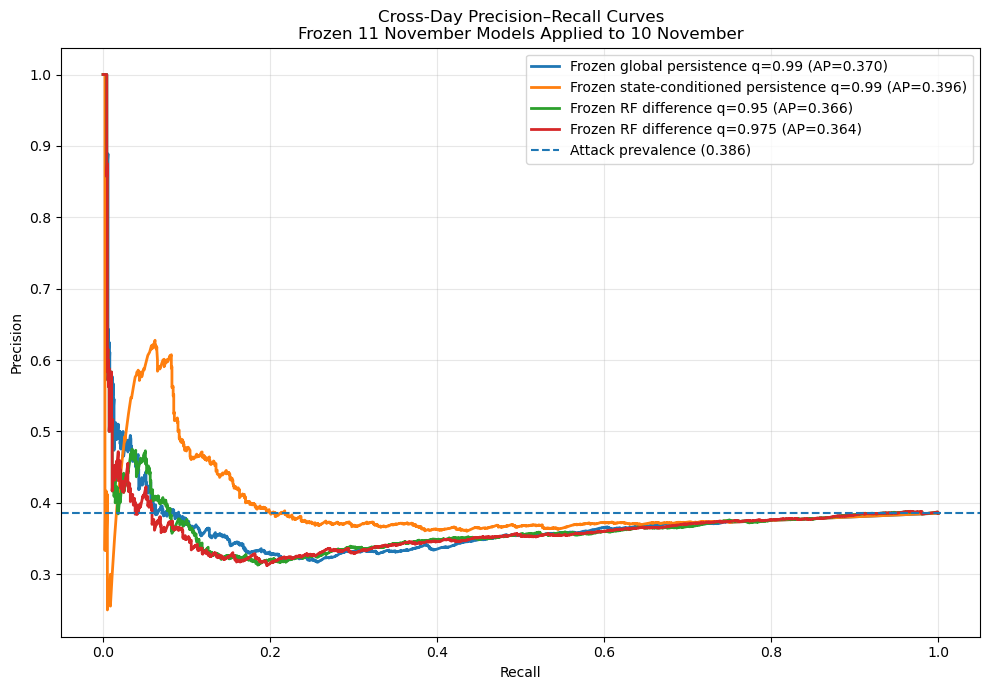

In [147]:
plt.figure(figsize=(10, 7))

for model_name, curve_df in (
    cross_day_precision_recall_curves.items()
):

    model_ap = (
        cross_day_threshold_independent_results
        .loc[
            cross_day_threshold_independent_results[
                "model"
            ] == model_name,
            "average_precision"
        ]
        .iloc[0]
    )

    plt.plot(
        curve_df["recall"],
        curve_df["precision"],
        linewidth=2,
        label=(
            f"{model_name} "
            f"(AP={model_ap:.3f})"
        )
    )

cross_day_prevalence = (
    cross_day_threshold_independent_results[
        "attack_prevalence"
    ].iloc[0]
)

plt.axhline(
    y=cross_day_prevalence,
    linestyle="--",
    label=(
        "Attack prevalence "
        f"({cross_day_prevalence:.3f})"
    )
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.title(
    "Cross-Day Precision–Recall Curves\n"
    "Frozen 11 November Models Applied to "
    "10 November"
)

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "cross_day_precision_recall_curves_10nov.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Strict Common Cross-Day Evaluation Window

In [148]:
strict_cross_day_start = pd.to_datetime(
    rf_cross_day_evaluation_start
)

print(
    "Strict cross-day evaluation starts:",
    strict_cross_day_start
)

(
    strict_global_10_eval_df,
    strict_global_10_results,
    strict_global_10_events
) = evaluate_on_common_window(
    pred_df=frozen_global_10_pred_df,
    model_name="Frozen global persistence q=0.99",
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

(
    strict_state_10_eval_df,
    strict_state_10_results,
    strict_state_10_events
) = evaluate_on_common_window(
    pred_df=frozen_state_10_pred_df,
    model_name=(
        "Frozen state-conditioned "
        "persistence q=0.99"
    ),
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

strict_cross_day_comparison = pd.DataFrame([
    strict_global_10_results,
    strict_state_10_results,
    frozen_rf_95_10_results,
    frozen_rf_975_10_results
])

display(
    strict_cross_day_comparison[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate"
        ],
        ascending=[False, True]
    )
)

strict_cross_day_comparison.to_csv(
    "strict_common_window_cross_day_comparison_10nov.csv",
    index=False
)

Strict cross-day evaluation starts: 2022-11-10 11:00:11


,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Frozen global persistence q=0.99,3590,0.589972,0.375706,0.096098,0.153049,10.018132,4,100.0,105.25,70.5,268.0
3,Frozen RF difference q=0.975,3590,0.574373,0.337838,0.108382,0.164114,13.327289,4,100.0,95.25,50.5,268.0
2,Frozen RF difference q=0.95,3590,0.537047,0.319010,0.177023,0.227695,23.708069,4,100.0,24.25,22.5,47.0
1,Frozen state-conditioned persistence q=0.99,3590,0.544847,0.373482,0.266618,0.311130,28.059837,4,100.0,17.50,10.5,46.0


# Normal-Data-Only Sensor Selection

In [149]:
import re

sensor_selection_normal_df = (
    pre_attack_normal_11
    .iloc[:common_split_index]
    .copy()
)

print(
    "Normal rows used for sensor selection:",
    len(sensor_selection_normal_df)
)

print(
    "Selection interval:",
    sensor_selection_normal_df["t_stamp"].min(),
    "to",
    sensor_selection_normal_df["t_stamp"].max()
)

Normal rows used for sensor selection: 2142
Selection interval: 2022-11-11 09:00:00 to 2022-11-11 09:35:41


In [150]:
def extract_process_stage(sensor_name):
    """
    Extract process stage from SWaT sensor tags.

    Examples:
    LIT101.Pv -> 1
    AIT302.Pv -> 3
    FIT601.Pv -> 6
    """

    match = re.search(
        r"(\d)\d{2}\.Pv$",
        sensor_name
    )

    if match is None:
        return np.nan

    return int(match.group(1))


def rank_sensors_using_normal_data(
    normal_df,
    sensor_columns,
    min_unique_values=20,
    min_nonzero_change_rate=0.005,
    minimum_valid_rows=100
):
    results = []

    for sensor in sensor_columns:

        values = pd.to_numeric(
            normal_df[sensor],
            errors="coerce"
        )

        valid_values = values.dropna()

        if len(valid_values) < minimum_valid_rows:
            continue

        previous_values = values.shift(1)

        residuals = (
            values - previous_values
        ).abs().dropna()

        if residuals.empty:
            continue

        q05 = valid_values.quantile(0.05)
        q25 = valid_values.quantile(0.25)
        q75 = valid_values.quantile(0.75)
        q95 = valid_values.quantile(0.95)

        robust_range = q95 - q05
        iqr = q75 - q25
        standard_deviation = valid_values.std()

        if robust_range > 1e-9:
            normalisation_scale = robust_range
        elif iqr > 1e-9:
            normalisation_scale = iqr
        elif standard_deviation > 1e-9:
            normalisation_scale = standard_deviation
        else:
            normalisation_scale = np.nan

        absolute_changes = valid_values.diff().abs()

        nonzero_change_rate = (
            absolute_changes.gt(1e-9).mean()
        )

        persistence_mae = residuals.mean()

        persistence_rmse = np.sqrt(
            np.mean(
                np.square(residuals)
            )
        )

        normalized_mae = (
            persistence_mae / normalisation_scale
            if pd.notna(normalisation_scale)
            else np.nan
        )

        normalized_rmse = (
            persistence_rmse / normalisation_scale
            if pd.notna(normalisation_scale)
            else np.nan
        )

        unique_values = valid_values.nunique()

        eligible = (
            unique_values >= min_unique_values
            and nonzero_change_rate
            >= min_nonzero_change_rate
            and pd.notna(normalized_mae)
            and normalisation_scale > 1e-9
        )

        results.append({
            "sensor": sensor,
            "process_stage":
                extract_process_stage(sensor),
            "valid_rows": len(valid_values),
            "unique_values": unique_values,
            "missing_percentage":
                values.isna().mean() * 100,
            "standard_deviation":
                standard_deviation,
            "robust_range_05_95":
                robust_range,
            "nonzero_change_rate":
                nonzero_change_rate,
            "lag1_autocorrelation":
                valid_values.autocorr(lag=1),
            "persistence_mae":
                persistence_mae,
            "persistence_rmse":
                persistence_rmse,
            "normalized_mae":
                normalized_mae,
            "normalized_rmse":
                normalized_rmse,
            "eligible":
                eligible
        })

    ranking_df = pd.DataFrame(results)

    ranking_df = ranking_df.sort_values(
        by=[
            "eligible",
            "normalized_mae",
            "normalized_rmse"
        ],
        ascending=[
            False,
            True,
            True
        ]
    ).reset_index(drop=True)

    return ranking_df

In [151]:
normal_only_sensor_ranking = (
    rank_sensors_using_normal_data(
        normal_df=sensor_selection_normal_df,
        sensor_columns=sensor_cols,
        min_unique_values=20,
        min_nonzero_change_rate=0.005,
        minimum_valid_rows=100
    )
)

display(
    normal_only_sensor_ranking.head(20)
)

normal_only_sensor_ranking.to_csv(
    "normal_only_sensor_ranking_11nov.csv",
    index=False
)

/opt/anaconda3/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/opt/anaconda3/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:2999: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]


,sensor,process_stage,valid_rows,unique_values,missing_percentage,standard_deviation,robust_range_05_95,nonzero_change_rate,lag1_autocorrelation,persistence_mae,persistence_rmse,normalized_mae,normalized_rmse,eligible
0,FIT201.Pv,2,2142,83,0.0,0.739910,2.638772,0.052754,0.999738,0.001282,0.017061,0.000486,0.006465,True
1,FIT101.Pv,1,2142,98,0.0,1.752943,5.041155,0.086368,0.999804,0.002752,0.034837,0.000546,0.006911,True
2,AIT203.Pv,2,2142,380,0.0,14.673590,45.808766,0.181606,0.999988,0.027167,0.075433,0.000593,0.001647,True
3,LIT101.Pv,1,2142,273,0.0,48.660575,160.133627,0.232493,0.999971,0.130206,0.415129,0.000813,0.002592,True
4,AIT302.Pv,3,2142,293,0.0,9.451890,29.986569,0.159197,0.999955,0.030382,0.093303,0.001013,0.003111,True
5,AIT402.Pv,4,2142,203,0.0,4.560558,13.868251,0.113912,0.999929,0.015840,0.054774,0.001142,0.003950,True
6,LIT401.Pv,4,2142,1561,0.0,54.376092,169.033540,0.922502,0.999991,0.195258,0.245294,0.001155,0.001451,True
7,AIT502.Pv,5,2142,215,0.0,3.132781,9.561643,0.134921,0.999799,0.019636,0.062913,0.002054,0.006580,True
8,LIT301.Pv,3,2142,194,0.0,17.216270,45.296845,0.261905,0.999919,0.098891,0.257647,0.002183,0.005688,True
9,AIT202.Pv,2,2142,178,0.0,0.032366,0.091002,0.232026,0.999476,0.000443,0.001055,0.004863,0.011592,True


In [152]:
def select_stage_diverse_sensors(
    ranking_df,
    number_of_sensors=5
):
    eligible_df = (
        ranking_df.loc[
            ranking_df["eligible"]
        ]
        .sort_values(
            by=[
                "normalized_mae",
                "normalized_rmse"
            ]
        )
        .copy()
    )

    if eligible_df.empty:
        raise ValueError(
            "No eligible sensors were found."
        )

    # Best predictable sensor from each stage
    best_per_stage = (
        eligible_df
        .dropna(subset=["process_stage"])
        .groupby(
            "process_stage",
            as_index=False,
            group_keys=False
        )
        .head(1)
        .sort_values(
            by="normalized_mae"
        )
    )

    selected_df = best_per_stage.head(
        number_of_sensors
    ).copy()

    if len(selected_df) < number_of_sensors:

        remaining_df = eligible_df.loc[
            ~eligible_df["sensor"].isin(
                selected_df["sensor"]
            )
        ]

        required = (
            number_of_sensors
            - len(selected_df)
        )

        selected_df = pd.concat(
            [
                selected_df,
                remaining_df.head(required)
            ],
            ignore_index=True
        )

    selected_df = (
        selected_df
        .head(number_of_sensors)
        .reset_index(drop=True)
    )

    return selected_df

In [153]:
normal_only_selected_sensor_details = (
    select_stage_diverse_sensors(
        ranking_df=normal_only_sensor_ranking,
        number_of_sensors=5
    )
)

normal_only_sensors = (
    normal_only_selected_sensor_details[
        "sensor"
    ].tolist()
)

print("Normal-data-only selected sensors:")

for sensor in normal_only_sensors:
    print(sensor)

display(
    normal_only_selected_sensor_details[
        [
            "sensor",
            "process_stage",
            "unique_values",
            "nonzero_change_rate",
            "lag1_autocorrelation",
            "normalized_mae",
            "normalized_rmse"
        ]
    ]
)

normal_only_selected_sensor_details.to_csv(
    "normal_only_selected_sensors_11nov.csv",
    index=False
)

Normal-data-only selected sensors:
FIT201.Pv
FIT101.Pv
AIT302.Pv
AIT402.Pv
AIT502.Pv


,sensor,process_stage,unique_values,nonzero_change_rate,lag1_autocorrelation,normalized_mae,normalized_rmse
0,FIT201.Pv,2,83,0.052754,0.999738,0.000486,0.006465
1,FIT101.Pv,1,98,0.086368,0.999804,0.000546,0.006911
2,AIT302.Pv,3,293,0.159197,0.999955,0.001013,0.003111
3,AIT402.Pv,4,203,0.113912,0.999929,0.001142,0.003950
4,AIT502.Pv,5,215,0.134921,0.999799,0.002054,0.006580


In [154]:
(
    normal_only_persistence_11_pred_df,
    normal_only_persistence_thresholds
) = build_common_calibrated_baseline(
    df_clean=df11_clean,
    selected_sensors=normal_only_sensors,
    calibration_start=common_calibration_start,
    train_end_time=train_end_time_11,
    model_type="persistence",
    quantile=0.99,
    min_sensors_triggered=1
)

(
    normal_only_persistence_11_eval_df,
    normal_only_persistence_11_results,
    normal_only_persistence_11_events
) = evaluate_on_common_window(
    pred_df=normal_only_persistence_11_pred_df,
    model_name=(
        "Normal-only sensors — "
        "global persistence q=0.99"
    ),
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

print(
    normal_only_persistence_11_results
)

display(
    normal_only_persistence_11_events
)

{'model': 'Normal-only sensors — global persistence q=0.99', 'evaluation_start': Timestamp('2022-11-11 09:51:00'), 'evaluation_rows': 6767, 'normal_rows': 3870, 'attack_rows': 2897, 'accuracy': 0.5571154130338407, 'attack_precision': np.float64(0.4479166666666667), 'attack_recall': np.float64(0.1484294097342078), 'attack_f1': np.float64(0.22297122115633913), 'true_normal': np.int64(3340), 'false_alarm': np.int64(530), 'missed_attack': np.int64(2467), 'detected_attack_rows': np.int64(430), 'false_alarm_rate': np.float64(13.695090439276486), 'detected_events': 17, 'total_events': 17, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(15.823529411764707), 'median_detection_delay': 12.0, 'maximum_detection_delay': 52.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:31,31.0,241,14
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:12,12.0,121,4
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:00,0.0,121,59
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:03,3.0,181,75
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:19,19.0,181,91
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,1,2022-11-11 10:20:23,23.0,121,5
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:15,15.0,121,11
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:30,30.0,181,14
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:08,8.0,181,6
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:21,21.0,181,15


In [155]:
normal_only_vs_original_11 = pd.DataFrame([
    persistence_global_99_results,
    normal_only_persistence_11_results
])

display(
    normal_only_vs_original_11[
        matched_quantile_columns
    ]
)

normal_only_vs_original_11.to_csv(
    "normal_only_vs_attack_selected_sensors_11nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence global threshold q=0.99,6767,0.554012,0.450693,0.190887,0.268186,17.416021,15,88.235294,11.600000,4.0,51.0
1,Normal-only sensors — global persistence q=0.99,6767,0.557115,0.447917,0.148429,0.222971,13.695090,17,100.000000,15.823529,12.0,52.0


In [156]:
(
    normal_only_score_summary_11,
    normal_only_pr_curve_11,
    normal_only_score_eval_df_11
) = evaluate_continuous_anomaly_score(
    pred_df=normal_only_persistence_11_pred_df,
    model_name=(
        "Normal-only sensors — "
        "global persistence q=0.99"
    ),
    evaluation_start=train_end_time_11
)

normal_only_score_summary_11_df = (
    pd.DataFrame([
        normal_only_score_summary_11
    ])
)

display(
    normal_only_score_summary_11_df
)

normal_only_score_summary_11_df.to_csv(
    "normal_only_threshold_independent_11nov.csv",
    index=False
)

,model,evaluation_rows,normal_rows,attack_rows,attack_prevalence,average_precision,roc_auc,ap_lift_over_prevalence
0,Normal-only sensors — global persistence q=0.99,6767,3870,2897,0.428107,0.420981,0.48769,0.983355


In [157]:
normal_only_global_threshold_bundle = {}

for sensor in normal_only_sensors:

    stage = extract_process_stage(sensor)

    state_column = (
        f"P{int(stage)}_STATE"
        if pd.notna(stage)
        else "UNUSED_STATE"
    )

    normal_only_global_threshold_bundle[
        sensor
    ] = {
        "state_column": state_column,
        "global_threshold": float(
            normal_only_persistence_thresholds[
                sensor
            ]
        ),
        "state_thresholds": {}
    }

print(
    "Frozen thresholds created for:",
    list(
        normal_only_global_threshold_bundle.keys()
    )
)

Frozen thresholds created for: ['FIT201.Pv', 'FIT101.Pv', 'AIT302.Pv', 'AIT402.Pv', 'AIT502.Pv']


In [158]:
normal_only_persistence_10_pred_df = (
    apply_frozen_persistence_detector(
        df_clean=df10_clean,
        selected_sensors=normal_only_sensors,
        threshold_bundle=(
            normal_only_global_threshold_bundle
        ),
        min_sensors_triggered=1,
        use_state_thresholds=False
    )
)

(
    normal_only_persistence_10_eval_df,
    normal_only_persistence_10_results,
    normal_only_persistence_10_events
) = evaluate_on_common_window(
    pred_df=normal_only_persistence_10_pred_df,
    model_name=(
        "Frozen normal-only sensor "
        "persistence q=0.99"
    ),
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

print(
    normal_only_persistence_10_results
)

display(
    normal_only_persistence_10_events
)

{'model': 'Frozen normal-only sensor persistence q=0.99', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.6086350974930362, 'attack_precision': np.float64(0.46938775510204084), 'attack_recall': np.float64(0.11632947976878613), 'attack_f1': np.float64(0.18645049218297627), 'true_normal': np.int64(2024), 'false_alarm': np.int64(182), 'missed_attack': np.int64(1223), 'detected_attack_rows': np.int64(161), 'false_alarm_rate': np.float64(8.250226654578423), 'detected_events': 4, 'total_events': 4, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(29.5), 'median_detection_delay': 29.5, 'maximum_detection_delay': 41.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,2022-11-10 11:03:18,18.0,421,17
1,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,2022-11-10 11:25:38,38.0,301,13
2,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,2022-11-10 11:34:21,21.0,421,25
3,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,2022-11-10 11:45:41,41.0,241,106


In [159]:
normal_only_cross_day_comparison = pd.DataFrame([
    strict_global_10_results,
    strict_state_10_results,
    frozen_rf_95_10_results,
    frozen_rf_975_10_results,
    normal_only_persistence_10_results
])

display(
    normal_only_cross_day_comparison[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate"
        ],
        ascending=[False, True]
    )
)

normal_only_cross_day_comparison.to_csv(
    "normal_only_cross_day_model_comparison_10nov.csv",
    index=False
)

normal_only_persistence_10_events.to_csv(
    "normal_only_sensor_events_10nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
4,Frozen normal-only sensor persistence q=0.99,3590,0.608635,0.469388,0.116329,0.186450,8.250227,4,100.0,29.50,29.5,41.0
0,Frozen global persistence q=0.99,3590,0.589972,0.375706,0.096098,0.153049,10.018132,4,100.0,105.25,70.5,268.0
3,Frozen RF difference q=0.975,3590,0.574373,0.337838,0.108382,0.164114,13.327289,4,100.0,95.25,50.5,268.0
2,Frozen RF difference q=0.95,3590,0.537047,0.319010,0.177023,0.227695,23.708069,4,100.0,24.25,22.5,47.0
1,Frozen state-conditioned persistence q=0.99,3590,0.544847,0.373482,0.266618,0.311130,28.059837,4,100.0,17.50,10.5,46.0


In [160]:
(
    normal_only_score_summary_10,
    normal_only_pr_curve_10,
    normal_only_score_eval_df_10
) = evaluate_continuous_anomaly_score(
    pred_df=normal_only_persistence_10_pred_df,
    model_name=(
        "Frozen normal-only sensor "
        "persistence q=0.99"
    ),
    evaluation_start=strict_cross_day_start
)

normal_only_score_summary_10_df = (
    pd.DataFrame([
        normal_only_score_summary_10
    ])
)

display(
    normal_only_score_summary_10_df
)

normal_only_score_summary_10_df.to_csv(
    "normal_only_threshold_independent_10nov.csv",
    index=False
)

,model,evaluation_rows,normal_rows,attack_rows,attack_prevalence,average_precision,roc_auc,ap_lift_over_prevalence
0,Frozen normal-only sensor persistence q=0.99,3590,2206,1384,0.385515,0.39617,0.487678,1.027637


# State-Conditioned Thresholds Using Normal-Only Selected Sensors

In [161]:
normal_only_sensor_state_map = {}

for sensor in normal_only_sensors:
    stage = extract_process_stage(sensor)

    if pd.isna(stage):
        raise ValueError(
            f"Could not determine process stage for {sensor}."
        )

    normal_only_sensor_state_map[sensor] = (
        f"P{int(stage)}_STATE"
    )

missing_state_columns = [
    state_column
    for state_column in normal_only_sensor_state_map.values()
    if state_column not in df11_clean.columns
]

assert not missing_state_columns, (
    f"Missing state columns: {missing_state_columns}"
)

print("Leakage-free sensor-to-state mapping:")

for sensor, state_column in (
    normal_only_sensor_state_map.items()
):
    print(f"{sensor} -> {state_column}")

Leakage-free sensor-to-state mapping:
FIT201.Pv -> P2_STATE
FIT101.Pv -> P1_STATE
AIT302.Pv -> P3_STATE
AIT402.Pv -> P4_STATE
AIT502.Pv -> P5_STATE


In [162]:
normal_only_state_count_records = []

calibration_mask_11 = (
    (
        normal_only_persistence_11_pred_df["t_stamp"]
        >= common_calibration_start
    )
    & (
        normal_only_persistence_11_pred_df["t_stamp"]
        < train_end_time_11
    )
    & (
        normal_only_persistence_11_pred_df[
            "attack_label"
        ] == 0
    )
)

for sensor, state_column in (
    normal_only_sensor_state_map.items()
):

    counts = (
        normal_only_persistence_11_pred_df.loc[
            calibration_mask_11,
            state_column
        ]
        .astype("string")
        .fillna("MISSING")
        .value_counts()
        .rename_axis("state_value")
        .reset_index(name="calibration_rows")
    )

    counts.insert(0, "state_column", state_column)
    counts.insert(0, "sensor", sensor)

    normal_only_state_count_records.append(counts)

normal_only_state_calibration_counts = pd.concat(
    normal_only_state_count_records,
    ignore_index=True
)

display(normal_only_state_calibration_counts)

normal_only_state_calibration_counts.to_csv(
    "normal_only_state_calibration_counts_11nov.csv",
    index=False
)

,sensor,state_column,state_value,calibration_rows
0,FIT201.Pv,P2_STATE,2,918
1,FIT101.Pv,P1_STATE,2,918
2,AIT302.Pv,P3_STATE,7,770
3,AIT302.Pv,P3_STATE,99,90
4,AIT302.Pv,P3_STATE,4,31
5,AIT302.Pv,P3_STATE,2,9
6,AIT302.Pv,P3_STATE,5,9
7,AIT302.Pv,P3_STATE,6,9
8,AIT402.Pv,P4_STATE,3,918
9,AIT502.Pv,P5_STATE,7,918


In [163]:
normal_only_state_tuning_results = []
normal_only_state_prediction_store = {}
normal_only_state_threshold_store = {}

state_quantiles = [
    0.95,
    0.975,
    0.99
]

minimum_state_rows_options = [
    25,
    50,
    100
]

sensor_vote_options = [
    1,
    2
]

for quantile in state_quantiles:

    for minimum_state_rows in (
        minimum_state_rows_options
    ):

        for sensor_votes in sensor_vote_options:

            (
                temporary_prediction_df,
                temporary_threshold_details
            ) = build_state_conditioned_detector(
                base_pred_df=(
                    normal_only_persistence_11_pred_df
                ),
                selected_sensors=normal_only_sensors,
                sensor_state_map=(
                    normal_only_sensor_state_map
                ),
                residual_suffix=(
                    "persistence_common_residual"
                ),
                calibration_start=(
                    common_calibration_start
                ),
                train_end_time=train_end_time_11,
                quantile=quantile,
                min_state_rows=minimum_state_rows,
                min_sensors_triggered=sensor_votes
            )

            (
                _,
                temporary_results,
                temporary_events
            ) = evaluate_on_common_window(
                pred_df=temporary_prediction_df,
                model_name=(
                    "Normal-only state-conditioned "
                    "persistence"
                ),
                evaluation_start=train_end_time_11,
                attack_intervals=intervals_11
            )

            configuration_key = (
                quantile,
                minimum_state_rows,
                sensor_votes
            )

            normal_only_state_prediction_store[
                configuration_key
            ] = temporary_prediction_df

            normal_only_state_threshold_store[
                configuration_key
            ] = temporary_threshold_details

            normal_only_state_tuning_results.append({
                "quantile": quantile,
                "min_state_rows": minimum_state_rows,
                "min_sensors_triggered": sensor_votes,
                "accuracy":
                    temporary_results["accuracy"],
                "attack_precision":
                    temporary_results[
                        "attack_precision"
                    ],
                "attack_recall":
                    temporary_results[
                        "attack_recall"
                    ],
                "attack_f1":
                    temporary_results["attack_f1"],
                "false_alarm_rate":
                    temporary_results[
                        "false_alarm_rate"
                    ],
                "detected_events":
                    temporary_results[
                        "detected_events"
                    ],
                "event_detection_rate":
                    temporary_results[
                        "event_detection_rate"
                    ],
                "average_detection_delay":
                    temporary_results[
                        "average_detection_delay"
                    ],
                "median_detection_delay":
                    temporary_results[
                        "median_detection_delay"
                    ],
                "maximum_detection_delay":
                    temporary_results[
                        "maximum_detection_delay"
                    ]
            })

normal_only_state_tuning_df = pd.DataFrame(
    normal_only_state_tuning_results
).sort_values(
    by=[
        "event_detection_rate",
        "false_alarm_rate",
        "attack_f1",
        "average_detection_delay"
    ],
    ascending=[
        False,
        True,
        False,
        True
    ]
).reset_index(drop=True)

display(normal_only_state_tuning_df)

normal_only_state_tuning_df.to_csv(
    "normal_only_state_threshold_tuning_11nov.csv",
    index=False
)

,quantile,min_state_rows,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.990,100,1,0.556820,0.446541,0.147049,0.221241,13.643411,17,100.000000,15.823529,12.0,52.0
1,0.975,100,1,0.547806,0.433469,0.183293,0.257642,17.932817,17,100.000000,12.411765,8.0,52.0
2,0.990,50,1,0.552091,0.449548,0.206075,0.282604,18.888889,17,100.000000,14.117647,11.0,52.0
3,0.990,25,1,0.549283,0.443291,0.206420,0.281677,19.405685,17,100.000000,14.117647,11.0,52.0
4,0.950,100,1,0.537018,0.425786,0.233690,0.301761,23.591731,17,100.000000,8.058824,6.0,52.0
5,0.975,50,1,0.539087,0.431141,0.239903,0.308272,23.695090,17,100.000000,12.000000,8.0,52.0
6,0.975,25,1,0.536279,0.426209,0.240249,0.307285,24.211886,17,100.000000,12.000000,8.0,52.0
7,0.950,50,1,0.530811,0.429009,0.289955,0.346035,28.888889,17,100.000000,7.647059,4.0,52.0
8,0.950,25,1,0.528447,0.425832,0.291336,0.345973,29.405685,17,100.000000,4.823529,4.0,19.0
9,0.950,50,2,0.568790,0.448276,0.031412,0.058710,2.894057,14,82.352941,69.928571,72.5,172.0


In [164]:
normal_only_state_full_detection = (
    normal_only_state_tuning_df.loc[
        normal_only_state_tuning_df[
            "detected_events"
        ] == len(intervals_11)
    ]
    .sort_values(
        by=[
            "false_alarm_rate",
            "attack_f1",
            "average_detection_delay"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

display(normal_only_state_full_detection)

if normal_only_state_full_detection.empty:
    raise ValueError(
        "No state-conditioned configuration "
        "detected all 17 attack events."
    )

selected_normal_only_state_config = (
    normal_only_state_full_detection.iloc[0]
)

selected_normal_only_state_quantile = float(
    selected_normal_only_state_config["quantile"]
)

selected_normal_only_min_state_rows = int(
    selected_normal_only_state_config[
        "min_state_rows"
    ]
)

selected_normal_only_state_votes = int(
    selected_normal_only_state_config[
        "min_sensors_triggered"
    ]
)

selected_normal_only_state_key = (
    selected_normal_only_state_quantile,
    selected_normal_only_min_state_rows,
    selected_normal_only_state_votes
)

print("Selected configuration:")

display(
    selected_normal_only_state_config
    .to_frame()
    .T
)

,quantile,min_state_rows,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.990,100,1,0.556820,0.446541,0.147049,0.221241,13.643411,17,100.0,15.823529,12.0,52.0
1,0.975,100,1,0.547806,0.433469,0.183293,0.257642,17.932817,17,100.0,12.411765,8.0,52.0
2,0.990,50,1,0.552091,0.449548,0.206075,0.282604,18.888889,17,100.0,14.117647,11.0,52.0
3,0.990,25,1,0.549283,0.443291,0.206420,0.281677,19.405685,17,100.0,14.117647,11.0,52.0
4,0.950,100,1,0.537018,0.425786,0.233690,0.301761,23.591731,17,100.0,8.058824,6.0,52.0
5,0.975,50,1,0.539087,0.431141,0.239903,0.308272,23.695090,17,100.0,12.000000,8.0,52.0
6,0.975,25,1,0.536279,0.426209,0.240249,0.307285,24.211886,17,100.0,12.000000,8.0,52.0
7,0.950,50,1,0.530811,0.429009,0.289955,0.346035,28.888889,17,100.0,7.647059,4.0,52.0
8,0.950,25,1,0.528447,0.425832,0.291336,0.345973,29.405685,17,100.0,4.823529,4.0,19.0


Selected configuration:


,quantile,min_state_rows,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.99,100.0,1.0,0.55682,0.446541,0.147049,0.221241,13.643411,17.0,100.0,15.823529,12.0,52.0


In [165]:
normal_only_state_11_pred_df = (
    normal_only_state_prediction_store[
        selected_normal_only_state_key
    ]
)

normal_only_state_11_threshold_details = (
    normal_only_state_threshold_store[
        selected_normal_only_state_key
    ]
)

(
    normal_only_state_11_eval_df,
    normal_only_state_11_results,
    normal_only_state_11_events
) = evaluate_on_common_window(
    pred_df=normal_only_state_11_pred_df,
    model_name=(
        "Normal-only sensors — "
        "state-conditioned persistence"
    ),
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

print(normal_only_state_11_results)

display(normal_only_state_11_events)

{'model': 'Normal-only sensors — state-conditioned persistence', 'evaluation_start': Timestamp('2022-11-11 09:51:00'), 'evaluation_rows': 6767, 'normal_rows': 3870, 'attack_rows': 2897, 'accuracy': 0.5568198610905867, 'attack_precision': np.float64(0.44654088050314467), 'attack_recall': np.float64(0.14704867103900587), 'attack_f1': np.float64(0.22124123604258633), 'true_normal': np.int64(3342), 'false_alarm': np.int64(528), 'missed_attack': np.int64(2471), 'detected_attack_rows': np.int64(426), 'false_alarm_rate': np.float64(13.643410852713178), 'detected_events': 17, 'total_events': 17, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(15.823529411764707), 'median_detection_delay': 12.0, 'maximum_detection_delay': 52.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:31,31.0,241,14
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:12,12.0,121,4
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:00,0.0,121,59
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:03,3.0,181,75
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:19,19.0,181,91
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,1,2022-11-11 10:20:23,23.0,121,5
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:15,15.0,121,10
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:30,30.0,181,13
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:08,8.0,181,6
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:21,21.0,181,15


In [166]:
normal_only_global_vs_state_11 = pd.DataFrame([
    normal_only_persistence_11_results,
    normal_only_state_11_results
])

display(
    normal_only_global_vs_state_11[
        matched_quantile_columns
    ]
)

normal_only_global_vs_state_11.to_csv(
    "normal_only_global_vs_state_11nov.csv",
    index=False
)

normal_only_state_11_events.to_csv(
    "normal_only_state_events_11nov.csv",
    index=False
)

normal_only_state_11_threshold_details.to_csv(
    "normal_only_selected_state_thresholds_11nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Normal-only sensors — global persistence q=0.99,6767,0.557115,0.447917,0.148429,0.222971,13.695090,17,100.0,15.823529,12.0,52.0
1,Normal-only sensors — state-conditioned persis...,6767,0.556820,0.446541,0.147049,0.221241,13.643411,17,100.0,15.823529,12.0,52.0


In [167]:
(
    normal_only_frozen_state_bundle,
    normal_only_frozen_state_details
) = fit_frozen_state_threshold_bundle(
    base_pred_df=normal_only_persistence_11_pred_df,
    selected_sensors=normal_only_sensors,
    sensor_state_map=normal_only_sensor_state_map,
    residual_suffix="persistence_common_residual",
    calibration_start=common_calibration_start,
    calibration_end=train_end_time_11,
    quantile=selected_normal_only_state_quantile,
    min_state_rows=(
        selected_normal_only_min_state_rows
    )
)

display(normal_only_frozen_state_details)

,sensor,state_column,state_key,state_rows,state_specific_threshold,uses_state_specific_threshold,applied_threshold,global_threshold,quantile,min_state_rows
0,FIT201.Pv,P2_STATE,2,918,0.330428,True,3.304277e-01,3.304277e-01,0.99,100
1,FIT101.Pv,P1_STATE,2,918,0.000000,True,1.000000e-09,1.000000e-09,0.99,100
2,AIT302.Pv,P3_STATE,2,9,0.000000,False,8.451350e-01,8.451350e-01,0.99,100
3,AIT302.Pv,P3_STATE,4,31,0.419989,False,8.451350e-01,8.451350e-01,0.99,100
4,AIT302.Pv,P3_STATE,5,9,0.000000,False,8.451350e-01,8.451350e-01,0.99,100
5,AIT302.Pv,P3_STATE,6,9,0.263270,False,8.451350e-01,8.451350e-01,0.99,100
6,AIT302.Pv,P3_STATE,7,770,0.896329,True,8.963285e-01,8.451350e-01,0.99,100
7,AIT302.Pv,P3_STATE,99,90,0.358298,False,8.451350e-01,8.451350e-01,0.99,100
8,AIT402.Pv,P4_STATE,3,918,0.205078,True,2.050780e-01,2.050780e-01,0.99,100
9,AIT502.Pv,P5_STATE,7,918,0.281983,True,2.819827e-01,2.819827e-01,0.99,100


In [168]:
normal_only_state_10_pred_df = (
    apply_frozen_persistence_detector(
        df_clean=df10_clean,
        selected_sensors=normal_only_sensors,
        threshold_bundle=(
            normal_only_frozen_state_bundle
        ),
        min_sensors_triggered=(
            selected_normal_only_state_votes
        ),
        use_state_thresholds=True
    )
)

(
    normal_only_state_10_eval_df,
    normal_only_state_10_results,
    normal_only_state_10_events
) = evaluate_on_common_window(
    pred_df=normal_only_state_10_pred_df,
    model_name=(
        "Frozen normal-only state-conditioned "
        "persistence"
    ),
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

print(normal_only_state_10_results)

display(normal_only_state_10_events)

{'model': 'Frozen normal-only state-conditioned persistence', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.6086350974930362, 'attack_precision': np.float64(0.46938775510204084), 'attack_recall': np.float64(0.11632947976878613), 'attack_f1': np.float64(0.18645049218297627), 'true_normal': np.int64(2024), 'false_alarm': np.int64(182), 'missed_attack': np.int64(1223), 'detected_attack_rows': np.int64(161), 'false_alarm_rate': np.float64(8.250226654578423), 'detected_events': 4, 'total_events': 4, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(29.5), 'median_detection_delay': 29.5, 'maximum_detection_delay': 41.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,2022-11-10 11:03:18,18.0,421,17
1,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,2022-11-10 11:25:38,38.0,301,13
2,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,2022-11-10 11:34:21,21.0,421,25
3,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,2022-11-10 11:45:41,41.0,241,106


In [169]:
normal_only_state_cross_day_comparison = pd.DataFrame([
    normal_only_persistence_10_results,
    normal_only_state_10_results,
    strict_global_10_results,
    strict_state_10_results,
    frozen_rf_95_10_results,
    frozen_rf_975_10_results
])

display(
    normal_only_state_cross_day_comparison[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate"
        ],
        ascending=[
            False,
            True
        ]
    )
)

normal_only_state_cross_day_comparison.to_csv(
    "normal_only_state_cross_day_comparison_10nov.csv",
    index=False
)

normal_only_state_10_events.to_csv(
    "normal_only_state_events_10nov.csv",
    index=False
)

normal_only_frozen_state_details.to_csv(
    "normal_only_frozen_state_thresholds.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Frozen normal-only sensor persistence q=0.99,3590,0.608635,0.469388,0.116329,0.186450,8.250227,4,100.0,29.50,29.5,41.0
1,Frozen normal-only state-conditioned persistence,3590,0.608635,0.469388,0.116329,0.186450,8.250227,4,100.0,29.50,29.5,41.0
2,Frozen global persistence q=0.99,3590,0.589972,0.375706,0.096098,0.153049,10.018132,4,100.0,105.25,70.5,268.0
5,Frozen RF difference q=0.975,3590,0.574373,0.337838,0.108382,0.164114,13.327289,4,100.0,95.25,50.5,268.0
4,Frozen RF difference q=0.95,3590,0.537047,0.319010,0.177023,0.227695,23.708069,4,100.0,24.25,22.5,47.0
3,Frozen state-conditioned persistence q=0.99,3590,0.544847,0.373482,0.266618,0.311130,28.059837,4,100.0,17.50,10.5,46.0


# Leakage-Free Random Forest First-Difference Model

In [170]:
def fit_rf_difference_fixed_split(
    df_clean,
    selected_sensors,
    calibration_start,
    evaluation_start,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10),
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42
):
    df = create_difference_features(
        df=df_clean,
        sensors=selected_sensors,
        lags=lags,
        rolling_windows=rolling_windows
    )

    calibration_start = pd.to_datetime(
        calibration_start
    )

    evaluation_start = pd.to_datetime(
        evaluation_start
    )

    feature_columns = []

    for sensor in selected_sensors:

        for lag in lags:
            feature_columns.append(
                f"{sensor}_difference_lag_{lag}"
            )

        for window in rolling_windows:
            feature_columns.extend([
                f"{sensor}_difference_mean_{window}",
                f"{sensor}_difference_std_{window}"
            ])

    required_columns = (
        feature_columns
        + selected_sensors
        + [
            f"{sensor}_difference"
            for sensor in selected_sensors
        ]
        + [
            f"{sensor}_previous_value"
            for sensor in selected_sensors
        ]
        + [
            "t_stamp",
            "attack_label"
        ]
    )

    valid_df = df.dropna(
        subset=required_columns
    ).copy()

    training_df = valid_df.loc[
        (
            valid_df["t_stamp"]
            < calibration_start
        )
        & (
            valid_df["attack_label"] == 0
        )
    ].copy()

    calibration_df = valid_df.loc[
        (
            valid_df["t_stamp"]
            >= calibration_start
        )
        & (
            valid_df["t_stamp"]
            < evaluation_start
        )
        & (
            valid_df["attack_label"] == 0
        )
    ].copy()

    if training_df.empty:
        raise ValueError("RF training data is empty.")

    if calibration_df.empty:
        raise ValueError("RF calibration data is empty.")

    prediction_df = valid_df.copy()

    fitted_models = {}
    calibration_residuals = {}

    for sensor in selected_sensors:

        target_column = f"{sensor}_difference"

        previous_value_column = (
            f"{sensor}_previous_value"
        )

        predicted_difference_column = (
            f"{sensor}_rf_difference_prediction"
        )

        predicted_level_column = (
            f"{sensor}_rf_difference_level_prediction"
        )

        residual_column = (
            f"{sensor}_rf_difference_residual"
        )

        model = RandomForestRegressor(
            n_estimators=n_estimators,
            max_depth=max_depth,
            min_samples_leaf=min_samples_leaf,
            random_state=random_state,
            n_jobs=-1
        )

        model.fit(
            training_df[feature_columns],
            training_df[target_column]
        )

        fitted_models[sensor] = model

        prediction_df[
            predicted_difference_column
        ] = model.predict(
            prediction_df[feature_columns]
        )

        prediction_df[
            predicted_level_column
        ] = (
            prediction_df[previous_value_column]
            + prediction_df[
                predicted_difference_column
            ]
        )

        prediction_df[residual_column] = (
            prediction_df[sensor]
            - prediction_df[predicted_level_column]
        ).abs()

        calibration_difference_prediction = (
            model.predict(
                calibration_df[feature_columns]
            )
        )

        calibration_level_prediction = (
            calibration_df[
                previous_value_column
            ].to_numpy()
            + calibration_difference_prediction
        )

        calibration_residuals[sensor] = np.abs(
            calibration_df[sensor].to_numpy()
            - calibration_level_prediction
        )

    print("RF training rows:", len(training_df))
    print(
        "RF calibration rows:",
        len(calibration_df)
    )

    return (
        prediction_df,
        fitted_models,
        calibration_residuals,
        feature_columns
    )

In [171]:
def score_fixed_rf_difference_predictions(
    base_prediction_df,
    selected_sensors,
    calibration_residuals,
    quantile,
    min_sensors_triggered
):
    scored_df = base_prediction_df.copy()

    threshold_dictionary = {}
    normalized_columns = []
    trigger_columns = []

    for sensor in selected_sensors:

        residual_column = (
            f"{sensor}_rf_difference_residual"
        )

        normalized_column = (
            f"{sensor}_rf_difference_normalized_residual"
        )

        trigger_column = (
            f"{sensor}_rf_difference_triggered"
        )

        threshold = float(
            np.quantile(
                calibration_residuals[sensor],
                quantile
            )
        )

        threshold = max(threshold, 1e-9)

        threshold_dictionary[sensor] = threshold

        scored_df[normalized_column] = (
            scored_df[residual_column]
            / threshold
        )

        scored_df[trigger_column] = (
            scored_df[normalized_column] > 1
        ).astype(int)

        normalized_columns.append(normalized_column)
        trigger_columns.append(trigger_column)

    scored_df["anomaly_score"] = (
        scored_df[normalized_columns]
        .max(axis=1)
    )

    scored_df["num_sensors_triggered"] = (
        scored_df[trigger_columns]
        .sum(axis=1)
    )

    scored_df["predicted_anomaly"] = (
        scored_df["num_sensors_triggered"]
        >= min_sensors_triggered
    ).astype(int)

    return scored_df, threshold_dictionary

In [172]:
(
    normal_only_rf_base_11_df,
    normal_only_rf_models,
    normal_only_rf_calibration_residuals,
    normal_only_rf_feature_columns
) = fit_rf_difference_fixed_split(
    df_clean=df11_clean,
    selected_sensors=normal_only_sensors,
    calibration_start=common_calibration_start,
    evaluation_start=train_end_time_11,
    lags=(1, 2, 3, 5, 10),
    rolling_windows=(5, 10),
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42
)

RF training rows: 2131
RF calibration rows: 918


In [173]:
normal_only_rf_tuning_results = []
normal_only_rf_prediction_store = {}
normal_only_rf_threshold_store = {}

rf_quantiles = [
    0.95,
    0.975,
    0.99
]

rf_sensor_votes = [
    1,
    2
]

for quantile in rf_quantiles:

    for sensor_votes in rf_sensor_votes:

        (
            temporary_rf_prediction_df,
            temporary_rf_thresholds
        ) = score_fixed_rf_difference_predictions(
            base_prediction_df=(
                normal_only_rf_base_11_df
            ),
            selected_sensors=normal_only_sensors,
            calibration_residuals=(
                normal_only_rf_calibration_residuals
            ),
            quantile=quantile,
            min_sensors_triggered=sensor_votes
        )

        (
            _,
            temporary_rf_results,
            temporary_rf_events
        ) = evaluate_on_common_window(
            pred_df=temporary_rf_prediction_df,
            model_name=(
                "Normal-only RF first difference"
            ),
            evaluation_start=train_end_time_11,
            attack_intervals=intervals_11
        )

        configuration_key = (
            quantile,
            sensor_votes
        )

        normal_only_rf_prediction_store[
            configuration_key
        ] = temporary_rf_prediction_df

        normal_only_rf_threshold_store[
            configuration_key
        ] = temporary_rf_thresholds

        normal_only_rf_tuning_results.append({
            "quantile": quantile,
            "min_sensors_triggered": sensor_votes,
            "accuracy":
                temporary_rf_results["accuracy"],
            "attack_precision":
                temporary_rf_results[
                    "attack_precision"
                ],
            "attack_recall":
                temporary_rf_results[
                    "attack_recall"
                ],
            "attack_f1":
                temporary_rf_results["attack_f1"],
            "false_alarm_rate":
                temporary_rf_results[
                    "false_alarm_rate"
                ],
            "detected_events":
                temporary_rf_results[
                    "detected_events"
                ],
            "event_detection_rate":
                temporary_rf_results[
                    "event_detection_rate"
                ],
            "average_detection_delay":
                temporary_rf_results[
                    "average_detection_delay"
                ],
            "median_detection_delay":
                temporary_rf_results[
                    "median_detection_delay"
                ],
            "maximum_detection_delay":
                temporary_rf_results[
                    "maximum_detection_delay"
                ]
        })

normal_only_rf_tuning_df = pd.DataFrame(
    normal_only_rf_tuning_results
).sort_values(
    by=[
        "event_detection_rate",
        "false_alarm_rate",
        "attack_f1"
    ],
    ascending=[
        False,
        True,
        False
    ]
).reset_index(drop=True)

display(normal_only_rf_tuning_df)

normal_only_rf_tuning_df.to_csv(
    "normal_only_rf_difference_tuning_11nov.csv",
    index=False
)

,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.990,1,0.547658,0.395674,0.107352,0.168884,12.273902,17,100.000000,17.705882,12.0,52.0
1,0.975,1,0.542338,0.414966,0.168450,0.239627,17.777778,17,100.000000,10.117647,6.0,52.0
2,0.950,1,0.531993,0.413462,0.222644,0.289432,23.643411,17,100.000000,4.000000,2.0,19.0
3,0.950,2,0.567608,0.413174,0.023818,0.045039,2.532300,13,76.470588,57.153846,58.0,119.0
4,0.975,2,0.569381,0.402299,0.012081,0.023458,1.343669,10,58.823529,68.600000,76.0,127.0
5,0.990,2,0.572484,0.583333,0.004833,0.009586,0.258398,9,52.941176,92.444444,82.0,168.0


# Selected Leakage-Free RF First-Difference Model

In [174]:
normal_only_rf_full_detection_candidates = (
    normal_only_rf_tuning_df.loc[
        normal_only_rf_tuning_df["detected_events"]
        == len(intervals_11)
    ]
    .sort_values(
        by=[
            "false_alarm_rate",
            "attack_f1",
            "average_detection_delay"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

display(normal_only_rf_full_detection_candidates)

if normal_only_rf_full_detection_candidates.empty:
    raise ValueError(
        "No RF configuration detected all 17 attack events."
    )

selected_normal_only_rf_config = (
    normal_only_rf_full_detection_candidates.iloc[0]
)

selected_normal_only_rf_quantile = float(
    selected_normal_only_rf_config["quantile"]
)

selected_normal_only_rf_votes = int(
    selected_normal_only_rf_config[
        "min_sensors_triggered"
    ]
)

selected_normal_only_rf_key = (
    selected_normal_only_rf_quantile,
    selected_normal_only_rf_votes
)

print("Selected RF configuration")
print(
    "Quantile:",
    selected_normal_only_rf_quantile
)
print(
    "Minimum sensors triggered:",
    selected_normal_only_rf_votes
)

display(
    selected_normal_only_rf_config
    .to_frame()
    .T
)

,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.990,1,0.547658,0.395674,0.107352,0.168884,12.273902,17,100.0,17.705882,12.0,52.0
1,0.975,1,0.542338,0.414966,0.168450,0.239627,17.777778,17,100.0,10.117647,6.0,52.0
2,0.950,1,0.531993,0.413462,0.222644,0.289432,23.643411,17,100.0,4.000000,2.0,19.0


Selected RF configuration
Quantile: 0.99
Minimum sensors triggered: 1


,quantile,min_sensors_triggered,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,0.99,1.0,0.547658,0.395674,0.107352,0.168884,12.273902,17.0,100.0,17.705882,12.0,52.0


In [175]:
selected_normal_only_rf_11_pred_df = (
    normal_only_rf_prediction_store[
        selected_normal_only_rf_key
    ]
)

selected_normal_only_rf_thresholds = (
    normal_only_rf_threshold_store[
        selected_normal_only_rf_key
    ]
)

(
    selected_normal_only_rf_11_eval_df,
    selected_normal_only_rf_11_results,
    selected_normal_only_rf_11_events
) = evaluate_on_common_window(
    pred_df=selected_normal_only_rf_11_pred_df,
    model_name=(
        "Normal-only RF first difference "
        f"q={selected_normal_only_rf_quantile}"
    ),
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

print(selected_normal_only_rf_11_results)

display(selected_normal_only_rf_11_events)

{'model': 'Normal-only RF first difference q=0.99', 'evaluation_start': Timestamp('2022-11-11 09:51:00'), 'evaluation_rows': 6767, 'normal_rows': 3870, 'attack_rows': 2897, 'accuracy': 0.5476577508497118, 'attack_precision': np.float64(0.39567430025445294), 'attack_recall': np.float64(0.10735243355195029), 'attack_f1': np.float64(0.16888406190605484), 'true_normal': np.int64(3395), 'false_alarm': np.int64(475), 'missed_attack': np.int64(2586), 'detected_attack_rows': np.int64(311), 'false_alarm_rate': np.float64(12.27390180878553), 'detected_events': 17, 'total_events': 17, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(17.705882352941178), 'median_detection_delay': 12.0, 'maximum_detection_delay': 52.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-11 09:51:00,2022-11-11 09:55:00,1,2022-11-11 09:51:23,23.0,241,33
1,2,2022-11-11 09:59:00,2022-11-11 10:01:00,1,2022-11-11 09:59:12,12.0,121,7
2,3,2022-11-11 10:03:00,2022-11-11 10:05:00,1,2022-11-11 10:03:00,0.0,121,14
3,4,2022-11-11 10:09:00,2022-11-11 10:12:00,1,2022-11-11 10:09:07,7.0,181,10
4,5,2022-11-11 10:14:00,2022-11-11 10:17:00,1,2022-11-11 10:14:19,19.0,181,37
5,6,2022-11-11 10:20:00,2022-11-11 10:22:00,1,2022-11-11 10:20:36,36.0,121,3
6,7,2022-11-11 10:24:00,2022-11-11 10:26:00,1,2022-11-11 10:24:15,15.0,121,16
7,8,2022-11-11 10:29:00,2022-11-11 10:32:00,1,2022-11-11 10:29:30,30.0,181,22
8,9,2022-11-11 10:34:00,2022-11-11 10:37:00,1,2022-11-11 10:34:38,38.0,181,5
9,10,2022-11-11 10:41:00,2022-11-11 10:44:00,1,2022-11-11 10:41:00,0.0,181,33


In [176]:
leakage_free_model_comparison_11 = pd.DataFrame([
    normal_only_persistence_11_results,
    normal_only_state_11_results,
    selected_normal_only_rf_11_results
])

display(
    leakage_free_model_comparison_11[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate"
        ],
        ascending=[
            False,
            True
        ]
    )
)

leakage_free_model_comparison_11.to_csv(
    "leakage_free_model_comparison_11nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
2,Normal-only RF first difference q=0.99,6767,0.547658,0.395674,0.107352,0.168884,12.273902,17,100.0,17.705882,12.0,52.0
1,Normal-only sensors — state-conditioned persis...,6767,0.556820,0.446541,0.147049,0.221241,13.643411,17,100.0,15.823529,12.0,52.0
0,Normal-only sensors — global persistence q=0.99,6767,0.557115,0.447917,0.148429,0.222971,13.695090,17,100.0,15.823529,12.0,52.0


In [177]:
selected_normal_only_rf_threshold_df = (
    pd.DataFrame({
        "sensor": list(
            selected_normal_only_rf_thresholds.keys()
        ),
        "threshold": list(
            selected_normal_only_rf_thresholds.values()
        )
    })
)

selected_normal_only_rf_threshold_df[
    "quantile"
] = selected_normal_only_rf_quantile

selected_normal_only_rf_threshold_df[
    "min_sensors_triggered"
] = selected_normal_only_rf_votes

display(selected_normal_only_rf_threshold_df)

selected_normal_only_rf_threshold_df.to_csv(
    "selected_normal_only_rf_thresholds_11nov.csv",
    index=False
)

selected_normal_only_rf_11_events.to_csv(
    "selected_normal_only_rf_events_11nov.csv",
    index=False
)

,sensor,threshold,quantile,min_sensors_triggered
0,FIT201.Pv,0.320410,0.99,1
1,FIT101.Pv,0.008306,0.99,1
2,AIT302.Pv,0.847629,0.99,1
3,AIT402.Pv,0.203914,0.99,1
4,AIT502.Pv,0.289435,0.99,1


In [178]:
selected_normal_only_rf_10_pred_df = (
    apply_frozen_rf_difference_detector(
        df_clean=df10_clean,
        selected_sensors=normal_only_sensors,
        fitted_models=normal_only_rf_models,
        frozen_thresholds=(
            selected_normal_only_rf_thresholds
        ),
        lags=(1, 2, 3, 5, 10),
        rolling_windows=(5, 10),
        min_sensors_triggered=(
            selected_normal_only_rf_votes
        )
    )
)

print(
    "Frozen RF evaluation rows:",
    len(selected_normal_only_rf_10_pred_df)
)

print(
    "First available timestamp:",
    selected_normal_only_rf_10_pred_df[
        "t_stamp"
    ].min()
)

print(
    "Last available timestamp:",
    selected_normal_only_rf_10_pred_df[
        "t_stamp"
    ].max()
)

Frozen RF evaluation rows: 3590
First available timestamp: 2022-11-10 11:00:11
Last available timestamp: 2022-11-10 12:00:00


In [179]:
(
    selected_normal_only_rf_10_eval_df,
    selected_normal_only_rf_10_results,
    selected_normal_only_rf_10_events
) = evaluate_on_common_window(
    pred_df=selected_normal_only_rf_10_pred_df,
    model_name=(
        "Frozen normal-only RF first difference "
        f"q={selected_normal_only_rf_quantile}"
    ),
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

print(selected_normal_only_rf_10_results)

display(selected_normal_only_rf_10_events)

{'model': 'Frozen normal-only RF first difference q=0.99', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.5933147632311978, 'attack_precision': np.float64(0.35271317829457366), 'attack_recall': np.float64(0.0657514450867052), 'attack_f1': np.float64(0.11084043848964677), 'true_normal': np.int64(2039), 'false_alarm': np.int64(167), 'missed_attack': np.int64(1293), 'detected_attack_rows': np.int64(91), 'false_alarm_rate': np.float64(7.57026291931097), 'detected_events': 4, 'total_events': 4, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(33.5), 'median_detection_delay': 32.0, 'maximum_detection_delay': 52.0}


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,2022-11-10 11:03:18,18.0,421,17
1,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,2022-11-10 11:25:43,43.0,301,10
2,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,2022-11-10 11:34:21,21.0,421,24
3,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,2022-11-10 11:45:52,52.0,241,40


In [180]:
leakage_free_cross_day_comparison = pd.DataFrame([
    normal_only_persistence_10_results,
    normal_only_state_10_results,
    selected_normal_only_rf_10_results
])

display(
    leakage_free_cross_day_comparison[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate",
            "average_detection_delay"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
)

leakage_free_cross_day_comparison.to_csv(
    "leakage_free_cross_day_comparison_10nov.csv",
    index=False
)

selected_normal_only_rf_10_events.to_csv(
    "selected_normal_only_rf_events_10nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
2,Frozen normal-only RF first difference q=0.99,3590,0.593315,0.352713,0.065751,0.11084,7.570263,4,100.0,33.5,32.0,52.0
0,Frozen normal-only sensor persistence q=0.99,3590,0.608635,0.469388,0.116329,0.18645,8.250227,4,100.0,29.5,29.5,41.0
1,Frozen normal-only state-conditioned persistence,3590,0.608635,0.469388,0.116329,0.18645,8.250227,4,100.0,29.5,29.5,41.0


In [181]:
selected_normal_only_rf_forecasting_10 = (
    calculate_frozen_rf_forecasting_metrics(
        prediction_df=(
            selected_normal_only_rf_10_pred_df
        ),
        selected_sensors=normal_only_sensors,
        model_name=(
            "Frozen normal-only RF first difference"
        )
    )
)

display(selected_normal_only_rf_forecasting_10)

selected_normal_only_rf_forecasting_10.to_csv(
    "selected_normal_only_rf_forecasting_10nov.csv",
    index=False
)

,model,sensor,normal_evaluation_rows,mae,rmse
0,Frozen normal-only RF first difference,FIT201.Pv,2206,0.004546,0.062973
1,Frozen normal-only RF first difference,FIT101.Pv,2206,0.001975,0.010837
2,Frozen normal-only RF first difference,AIT302.Pv,2206,0.108545,0.198630
3,Frozen normal-only RF first difference,AIT402.Pv,2206,0.027964,0.048198
4,Frozen normal-only RF first difference,AIT502.Pv,2206,0.030498,0.062670


In [182]:
(
    selected_normal_only_rf_score_summary_10,
    selected_normal_only_rf_pr_curve_10,
    selected_normal_only_rf_score_eval_df_10
) = evaluate_continuous_anomaly_score(
    pred_df=selected_normal_only_rf_10_pred_df,
    model_name=(
        "Frozen normal-only RF first difference"
    ),
    evaluation_start=strict_cross_day_start
)

selected_normal_only_rf_score_summary_10_df = (
    pd.DataFrame([
        selected_normal_only_rf_score_summary_10
    ])
)

display(
    selected_normal_only_rf_score_summary_10_df
)

selected_normal_only_rf_score_summary_10_df.to_csv(
    "selected_normal_only_rf_threshold_independent_10nov.csv",
    index=False
)

,model,evaluation_rows,normal_rows,attack_rows,attack_prevalence,average_precision,roc_auc,ap_lift_over_prevalence
0,Frozen normal-only RF first difference,3590,2206,1384,0.385515,0.393624,0.480597,1.021033


In [183]:
leakage_free_cross_day_score_inputs = {
    "Normal-only global persistence":
        normal_only_persistence_10_pred_df,

    "Normal-only state-conditioned persistence":
        normal_only_state_10_pred_df,

    "Normal-only RF first difference":
        selected_normal_only_rf_10_pred_df
}

leakage_free_score_summaries = []
leakage_free_pr_curves = {}

for model_name, prediction_df in (
    leakage_free_cross_day_score_inputs.items()
):

    summary, curve_df, _ = (
        evaluate_continuous_anomaly_score(
            pred_df=prediction_df,
            model_name=model_name,
            evaluation_start=strict_cross_day_start
        )
    )

    leakage_free_score_summaries.append(
        summary
    )

    leakage_free_pr_curves[
        model_name
    ] = curve_df

leakage_free_threshold_independent_10 = (
    pd.DataFrame(
        leakage_free_score_summaries
    )
    .sort_values(
        by="average_precision",
        ascending=False
    )
    .reset_index(drop=True)
)

display(
    leakage_free_threshold_independent_10
)

leakage_free_threshold_independent_10.to_csv(
    "leakage_free_threshold_independent_10nov.csv",
    index=False
)

,model,evaluation_rows,normal_rows,attack_rows,attack_prevalence,average_precision,roc_auc,ap_lift_over_prevalence
0,Normal-only state-conditioned persistence,3590,2206,1384,0.385515,0.396360,0.487793,1.028131
1,Normal-only global persistence,3590,2206,1384,0.385515,0.396170,0.487678,1.027637
2,Normal-only RF first difference,3590,2206,1384,0.385515,0.393624,0.480597,1.021033


In [184]:
assert (
    selected_normal_only_rf_10_results[
        "evaluation_rows"
    ]
    == normal_only_persistence_10_results[
        "evaluation_rows"
    ]
), "Cross-day evaluation row counts do not match."

assert (
    selected_normal_only_rf_10_results[
        "total_events"
    ]
    == len(intervals_10)
), "Incorrect number of 10 November attack events."

assert set(
    selected_normal_only_rf_thresholds.keys()
) == set(
    normal_only_sensors
), "RF thresholds do not match the selected sensors."

print("All frozen RF validation checks passed.")

All frozen RF validation checks passed.


# Temporal Alarm Persistence Filtering

In [185]:
def apply_temporal_m_of_n_filter(
    pred_df,
    window_size,
    minimum_hits,
    processing_start
):
    """
    Raise an alarm when at least `minimum_hits` raw anomaly
    predictions occur within the latest `window_size` rows.
    """

    if window_size < 1:
        raise ValueError("window_size must be at least 1.")

    if minimum_hits < 1 or minimum_hits > window_size:
        raise ValueError(
            "minimum_hits must be between 1 and window_size."
        )

    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(df["t_stamp"])
    processing_start = pd.to_datetime(processing_start)

    df = (
        df.loc[df["t_stamp"] >= processing_start]
        .sort_values("t_stamp")
        .reset_index(drop=True)
        .copy()
    )

    if "predicted_anomaly" not in df.columns:
        raise KeyError("predicted_anomaly column is missing.")

    df["raw_predicted_anomaly"] = (
        df["predicted_anomaly"]
        .fillna(0)
        .astype(int)
    )

    df["temporal_alarm_count"] = (
        df["raw_predicted_anomaly"]
        .rolling(
            window=window_size,
            min_periods=window_size
        )
        .sum()
    )

    df["predicted_anomaly"] = (
        df["temporal_alarm_count"]
        >= minimum_hits
    ).astype(int)

    df["temporal_window_size"] = window_size
    df["temporal_minimum_hits"] = minimum_hits

    return df

In [186]:
temporal_filter_configurations = [
    (1, 1),
    (2, 2),
    (3, 2),
    (3, 3),
    (5, 2),
    (5, 3),
    (5, 4),
    (10, 3),
    (10, 5)
]

temporal_development_models = {
    "Persistence q=0.99":
        normal_only_persistence_11_pred_df,

    "RF difference q=0.99":
        selected_normal_only_rf_11_pred_df
}

temporal_filter_tuning_results = []
temporal_filter_prediction_store = {}

for model_name, base_prediction_df in (
    temporal_development_models.items()
):

    for window_size, minimum_hits in (
        temporal_filter_configurations
    ):

        filtered_df = apply_temporal_m_of_n_filter(
            pred_df=base_prediction_df,
            window_size=window_size,
            minimum_hits=minimum_hits,
            processing_start=train_end_time_11
        )

        (
            _,
            filtered_results,
            filtered_events
        ) = evaluate_on_common_window(
            pred_df=filtered_df,
            model_name=(
                f"{model_name} — "
                f"{minimum_hits}-of-{window_size}"
            ),
            evaluation_start=train_end_time_11,
            attack_intervals=intervals_11
        )

        configuration_key = (
            model_name,
            window_size,
            minimum_hits
        )

        temporal_filter_prediction_store[
            configuration_key
        ] = filtered_df

        temporal_filter_tuning_results.append({
            "base_model": model_name,
            "window_size": window_size,
            "minimum_hits": minimum_hits,
            "accuracy":
                filtered_results["accuracy"],
            "attack_precision":
                filtered_results["attack_precision"],
            "attack_recall":
                filtered_results["attack_recall"],
            "attack_f1":
                filtered_results["attack_f1"],
            "false_alarm_rate":
                filtered_results["false_alarm_rate"],
            "detected_events":
                filtered_results["detected_events"],
            "event_detection_rate":
                filtered_results[
                    "event_detection_rate"
                ],
            "average_detection_delay":
                filtered_results[
                    "average_detection_delay"
                ],
            "median_detection_delay":
                filtered_results[
                    "median_detection_delay"
                ],
            "maximum_detection_delay":
                filtered_results[
                    "maximum_detection_delay"
                ]
        })

temporal_filter_tuning_df = pd.DataFrame(
    temporal_filter_tuning_results
).sort_values(
    by=[
        "base_model",
        "event_detection_rate",
        "false_alarm_rate",
        "attack_f1",
        "average_detection_delay"
    ],
    ascending=[
        True,
        False,
        True,
        False,
        True
    ]
).reset_index(drop=True)

display(temporal_filter_tuning_df)

temporal_filter_tuning_df.to_csv(
    "temporal_filter_tuning_11nov.csv",
    index=False
)

,base_model,window_size,minimum_hits,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence q=0.99,1,1,0.557115,0.447917,0.148429,0.222971,13.695090,17,100.000000,15.823529,12.0,52.0
1,Persistence q=0.99,5,2,0.566425,0.483288,0.184674,0.267233,14.780362,15,88.235294,60.600000,47.0,141.0
2,Persistence q=0.99,10,3,0.575735,0.510708,0.214014,0.301630,15.348837,11,64.705882,38.363636,34.0,119.0
3,Persistence q=0.99,3,2,0.564356,0.463623,0.112185,0.180656,9.715762,10,58.823529,44.100000,42.5,107.0
4,Persistence q=0.99,2,2,0.560958,0.417411,0.064550,0.111809,6.744186,9,52.941176,44.888889,47.0,107.0
5,Persistence q=0.99,5,3,0.564061,0.460507,0.106662,0.173206,9.354005,8,47.058824,46.125000,50.0,108.0
6,Persistence q=0.99,3,3,0.558298,0.342466,0.034518,0.062716,4.961240,6,35.294118,49.666667,20.0,145.0
7,Persistence q=0.99,5,4,0.560514,0.389685,0.046945,0.083795,5.503876,5,29.411765,31.400000,7.0,109.0
8,Persistence q=0.99,10,5,0.563765,0.463186,0.119434,0.189901,10.361757,5,29.411765,30.200000,5.0,110.0
9,RF difference q=0.99,1,1,0.547658,0.395674,0.107352,0.168884,12.273902,17,100.000000,17.705882,12.0,52.0


In [187]:
selected_temporal_filter_rows = []

for model_name in temporal_development_models:

    model_candidates = (
        temporal_filter_tuning_df.loc[
            (
                temporal_filter_tuning_df[
                    "base_model"
                ] == model_name
            )
            & (
                temporal_filter_tuning_df[
                    "detected_events"
                ] == len(intervals_11)
            )
        ]
        .sort_values(
            by=[
                "false_alarm_rate",
                "attack_f1",
                "average_detection_delay"
            ],
            ascending=[
                True,
                False,
                True
            ]
        )
        .reset_index(drop=True)
    )

    if model_candidates.empty:
        raise ValueError(
            f"No temporal configuration retained "
            f"all events for {model_name}."
        )

    selected_temporal_filter_rows.append(
        model_candidates.iloc[0]
    )

selected_temporal_filters = pd.DataFrame(
    selected_temporal_filter_rows
).reset_index(drop=True)

display(selected_temporal_filters)

selected_temporal_filters.to_csv(
    "selected_temporal_filters_11nov.csv",
    index=False
)

,base_model,window_size,minimum_hits,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Persistence q=0.99,1,1,0.557115,0.447917,0.148429,0.222971,13.695090,17,100.0,15.823529,12.0,52.0
1,RF difference q=0.99,1,1,0.547658,0.395674,0.107352,0.168884,12.273902,17,100.0,17.705882,12.0,52.0


In [188]:
persistence_temporal_config = (
    selected_temporal_filters.loc[
        selected_temporal_filters[
            "base_model"
        ] == "Persistence q=0.99"
    ].iloc[0]
)

rf_temporal_config = (
    selected_temporal_filters.loc[
        selected_temporal_filters[
            "base_model"
        ] == "RF difference q=0.99"
    ].iloc[0]
)

persistence_temporal_window = int(
    persistence_temporal_config["window_size"]
)

persistence_temporal_hits = int(
    persistence_temporal_config["minimum_hits"]
)

rf_temporal_window = int(
    rf_temporal_config["window_size"]
)

rf_temporal_hits = int(
    rf_temporal_config["minimum_hits"]
)

selected_persistence_temporal_11_df = (
    temporal_filter_prediction_store[
        (
            "Persistence q=0.99",
            persistence_temporal_window,
            persistence_temporal_hits
        )
    ]
)

selected_rf_temporal_11_df = (
    temporal_filter_prediction_store[
        (
            "RF difference q=0.99",
            rf_temporal_window,
            rf_temporal_hits
        )
    ]
)

print(
    "Selected persistence filter:",
    f"{persistence_temporal_hits}-of-"
    f"{persistence_temporal_window}"
)

print(
    "Selected RF filter:",
    f"{rf_temporal_hits}-of-"
    f"{rf_temporal_window}"
)

Selected persistence filter: 1-of-1
Selected RF filter: 1-of-1


In [189]:
selected_persistence_temporal_10_df = (
    apply_temporal_m_of_n_filter(
        pred_df=normal_only_persistence_10_pred_df,
        window_size=persistence_temporal_window,
        minimum_hits=persistence_temporal_hits,
        processing_start=strict_cross_day_start
    )
)

selected_rf_temporal_10_df = (
    apply_temporal_m_of_n_filter(
        pred_df=selected_normal_only_rf_10_pred_df,
        window_size=rf_temporal_window,
        minimum_hits=rf_temporal_hits,
        processing_start=strict_cross_day_start
    )
)

(
    persistence_temporal_10_eval_df,
    persistence_temporal_10_results,
    persistence_temporal_10_events
) = evaluate_on_common_window(
    pred_df=selected_persistence_temporal_10_df,
    model_name=(
        "Frozen persistence with "
        f"{persistence_temporal_hits}-of-"
        f"{persistence_temporal_window} filter"
    ),
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

(
    rf_temporal_10_eval_df,
    rf_temporal_10_results,
    rf_temporal_10_events
) = evaluate_on_common_window(
    pred_df=selected_rf_temporal_10_df,
    model_name=(
        "Frozen RF difference with "
        f"{rf_temporal_hits}-of-"
        f"{rf_temporal_window} filter"
    ),
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

print("Filtered persistence:")
print(persistence_temporal_10_results)

print("\nFiltered RF:")
print(rf_temporal_10_results)

Filtered persistence:
{'model': 'Frozen persistence with 1-of-1 filter', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.6086350974930362, 'attack_precision': np.float64(0.46938775510204084), 'attack_recall': np.float64(0.11632947976878613), 'attack_f1': np.float64(0.18645049218297627), 'true_normal': np.int64(2024), 'false_alarm': np.int64(182), 'missed_attack': np.int64(1223), 'detected_attack_rows': np.int64(161), 'false_alarm_rate': np.float64(8.250226654578423), 'detected_events': 4, 'total_events': 4, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(29.5), 'median_detection_delay': 29.5, 'maximum_detection_delay': 41.0}

Filtered RF:
{'model': 'Frozen RF difference with 1-of-1 filter', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.5933147632311978, 'attack_precision': np.floa

In [190]:
temporal_cross_day_comparison = pd.DataFrame([
    normal_only_persistence_10_results,
    selected_normal_only_rf_10_results,
    persistence_temporal_10_results,
    rf_temporal_10_results
])

display(
    temporal_cross_day_comparison[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate",
            "average_detection_delay"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
)

temporal_cross_day_comparison.to_csv(
    "temporal_filter_cross_day_comparison_10nov.csv",
    index=False
)

persistence_temporal_10_events.to_csv(
    "filtered_persistence_events_10nov.csv",
    index=False
)

rf_temporal_10_events.to_csv(
    "filtered_rf_events_10nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
1,Frozen normal-only RF first difference q=0.99,3590,0.593315,0.352713,0.065751,0.11084,7.570263,4,100.0,33.5,32.0,52.0
3,Frozen RF difference with 1-of-1 filter,3590,0.593315,0.352713,0.065751,0.11084,7.570263,4,100.0,33.5,32.0,52.0
0,Frozen normal-only sensor persistence q=0.99,3590,0.608635,0.469388,0.116329,0.18645,8.250227,4,100.0,29.5,29.5,41.0
2,Frozen persistence with 1-of-1 filter,3590,0.608635,0.469388,0.116329,0.18645,8.250227,4,100.0,29.5,29.5,41.0


In [191]:
def summarise_false_alarm_episodes(
    pred_df,
    model_name,
    evaluation_start
):
    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(df["t_stamp"])

    df = (
        df.loc[
            df["t_stamp"]
            >= pd.to_datetime(evaluation_start)
        ]
        .sort_values("t_stamp")
        .reset_index(drop=True)
        .copy()
    )

    df["false_alarm_flag"] = (
        (df["attack_label"] == 0)
        & (df["predicted_anomaly"] == 1)
    ).astype(int)

    df["false_alarm_episode_start"] = (
        df["false_alarm_flag"].eq(1)
        & df["false_alarm_flag"]
        .shift(fill_value=0)
        .eq(0)
    )

    df["false_alarm_episode_id"] = (
        df["false_alarm_episode_start"]
        .cumsum()
    )

    episode_lengths = (
        df.loc[df["false_alarm_flag"] == 1]
        .groupby("false_alarm_episode_id")
        .size()
    )

    return {
        "model": model_name,
        "normal_rows":
            int((df["attack_label"] == 0).sum()),
        "false_alarm_rows":
            int(df["false_alarm_flag"].sum()),
        "false_alarm_episodes":
            int(len(episode_lengths)),
        "mean_episode_length":
            episode_lengths.mean()
            if len(episode_lengths) > 0
            else 0,
        "median_episode_length":
            episode_lengths.median()
            if len(episode_lengths) > 0
            else 0,
        "maximum_episode_length":
            episode_lengths.max()
            if len(episode_lengths) > 0
            else 0
    }

In [192]:
false_alarm_episode_comparison = pd.DataFrame([
    summarise_false_alarm_episodes(
        normal_only_persistence_10_pred_df,
        "Persistence unfiltered",
        strict_cross_day_start
    ),
    summarise_false_alarm_episodes(
        selected_persistence_temporal_10_df,
        "Persistence temporally filtered",
        strict_cross_day_start
    ),
    summarise_false_alarm_episodes(
        selected_normal_only_rf_10_pred_df,
        "RF unfiltered",
        strict_cross_day_start
    ),
    summarise_false_alarm_episodes(
        selected_rf_temporal_10_df,
        "RF temporally filtered",
        strict_cross_day_start
    )
])

display(false_alarm_episode_comparison)

false_alarm_episode_comparison.to_csv(
    "false_alarm_episode_comparison_10nov.csv",
    index=False
)

,model,normal_rows,false_alarm_rows,false_alarm_episodes,mean_episode_length,median_episode_length,maximum_episode_length
0,Persistence unfiltered,2206,182,89,2.044944,1.0,17
1,Persistence temporally filtered,2206,182,89,2.044944,1.0,17
2,RF unfiltered,2206,167,102,1.637255,1.0,10
3,RF temporally filtered,2206,167,102,1.637255,1.0,10


In [193]:
assert (
    len(selected_persistence_temporal_10_df)
    == len(selected_rf_temporal_10_df)
), "Filtered evaluation row counts do not match."

assert (
    persistence_temporal_10_results["total_events"]
    == len(intervals_10)
)

assert (
    rf_temporal_10_results["total_events"]
    == len(intervals_10)
)

print("Temporal filter validation checks passed.")

Temporal filter validation checks passed.


# Sensor Contribution and Threshold Stability Audit

In [194]:
def audit_sensor_thresholds_and_triggers(
    pred_df,
    selected_sensors,
    threshold_dictionary,
    residual_suffix,
    trigger_suffix,
    evaluation_start,
    attack_intervals
):
    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(df["t_stamp"])
    evaluation_start = pd.to_datetime(evaluation_start)

    eval_df = df.loc[
        df["t_stamp"] >= evaluation_start
    ].copy()

    date_value = eval_df["t_stamp"].dt.date.iloc[0]

    audit_records = []

    for sensor in selected_sensors:

        residual_col = f"{sensor}_{residual_suffix}"
        trigger_col = f"{sensor}_{trigger_suffix}"

        if residual_col not in df.columns:
            raise KeyError(
                f"Missing residual column: {residual_col}"
            )

        if trigger_col not in df.columns:
            raise KeyError(
                f"Missing trigger column: {trigger_col}"
            )

        calibration_residuals = df.loc[
            (
                df["t_stamp"] >= common_calibration_start
            )
            & (
                df["t_stamp"] < train_end_time_11
            )
            & (
                df["attack_label"] == 0
            ),
            residual_col
        ].dropna()

        positive_residuals = calibration_residuals.loc[
            calibration_residuals > 0
        ]

        normal_eval = eval_df.loc[
            eval_df["attack_label"] == 0
        ]

        attack_eval = eval_df.loc[
            eval_df["attack_label"] == 1
        ]

        false_alarm_rows = int(
            normal_eval[trigger_col].sum()
        )

        attack_trigger_rows = int(
            attack_eval[trigger_col].sum()
        )

        detected_events = 0

        for start_time, end_time in attack_intervals:

            start_dt = pd.to_datetime(
                f"{date_value} {start_time}"
            )

            end_dt = pd.to_datetime(
                f"{date_value} {end_time}"
            )

            event_window = eval_df.loc[
                (
                    eval_df["t_stamp"] >= start_dt
                )
                & (
                    eval_df["t_stamp"] <= end_dt
                )
            ]

            if event_window[trigger_col].eq(1).any():
                detected_events += 1

        audit_records.append({
            "sensor": sensor,
            "threshold": float(
                threshold_dictionary[sensor]
            ),
            "calibration_rows":
                len(calibration_residuals),
            "zero_calibration_residual_percentage":
                calibration_residuals.eq(0).mean() * 100,
            "positive_calibration_residuals":
                len(positive_residuals),
            "minimum_positive_residual":
                positive_residuals.min()
                if not positive_residuals.empty
                else np.nan,
            "median_positive_residual":
                positive_residuals.median()
                if not positive_residuals.empty
                else np.nan,
            "maximum_calibration_residual":
                calibration_residuals.max(),
            "normal_evaluation_rows":
                len(normal_eval),
            "false_alarm_rows":
                false_alarm_rows,
            "sensor_false_alarm_rate":
                (
                    false_alarm_rows
                    / len(normal_eval)
                    * 100
                    if len(normal_eval) > 0
                    else np.nan
                ),
            "attack_evaluation_rows":
                len(attack_eval),
            "attack_trigger_rows":
                attack_trigger_rows,
            "sensor_attack_trigger_rate":
                (
                    attack_trigger_rows
                    / len(attack_eval)
                    * 100
                    if len(attack_eval) > 0
                    else np.nan
                ),
            "detected_events":
                detected_events,
            "total_events":
                len(attack_intervals)
        })

    return pd.DataFrame(audit_records)

In [195]:
persistence_sensor_audit_11 = (
    audit_sensor_thresholds_and_triggers(
        pred_df=normal_only_persistence_11_pred_df,
        selected_sensors=normal_only_sensors,
        threshold_dictionary=(
            normal_only_persistence_thresholds
        ),
        residual_suffix=(
            "persistence_common_residual"
        ),
        trigger_suffix=(
            "persistence_common_triggered"
        ),
        evaluation_start=train_end_time_11,
        attack_intervals=intervals_11
    )
)

display(
    persistence_sensor_audit_11.sort_values(
        by="sensor_false_alarm_rate",
        ascending=False
    )
)

persistence_sensor_audit_11.to_csv(
    "persistence_sensor_threshold_audit_11nov.csv",
    index=False
)

,sensor,threshold,calibration_rows,zero_calibration_residual_percentage,positive_calibration_residuals,minimum_positive_residual,median_positive_residual,maximum_calibration_residual,normal_evaluation_rows,false_alarm_rows,sensor_false_alarm_rate,attack_evaluation_rows,attack_trigger_rows,sensor_attack_trigger_rate,detected_events,total_events
1,FIT101.Pv,1.000000e-09,918,100.000000,0,NaN,NaN,0.000000,3870,329,8.501292,2897,300,10.355540,6,17
3,AIT402.Pv,2.050780e-01,918,91.830065,75,0.025624,0.128180,0.281983,3870,80,2.067183,2897,57,1.967553,17,17
2,AIT302.Pv,8.451350e-01,918,64.052288,330,0.025600,0.281708,1.306122,3870,78,2.015504,2897,55,1.898516,12,17
4,AIT502.Pv,2.819827e-01,918,85.947712,129,0.025623,0.128183,0.410156,3870,42,1.085271,2897,22,0.759406,9,17
0,FIT201.Pv,3.304277e-01,918,83.877996,148,0.000128,0.021337,0.400859,3870,22,0.568475,2897,11,0.379703,5,17


In [196]:
rf_sensor_audit_11 = (
    audit_sensor_thresholds_and_triggers(
        pred_df=selected_normal_only_rf_11_pred_df,
        selected_sensors=normal_only_sensors,
        threshold_dictionary=(
            selected_normal_only_rf_thresholds
        ),
        residual_suffix=(
            "rf_difference_residual"
        ),
        trigger_suffix=(
            "rf_difference_triggered"
        ),
        evaluation_start=train_end_time_11,
        attack_intervals=intervals_11
    )
)

display(
    rf_sensor_audit_11.sort_values(
        by="sensor_false_alarm_rate",
        ascending=False
    )
)

rf_sensor_audit_11.to_csv(
    "rf_sensor_threshold_audit_11nov.csv",
    index=False
)

,sensor,threshold,calibration_rows,zero_calibration_residual_percentage,positive_calibration_residuals,minimum_positive_residual,median_positive_residual,maximum_calibration_residual,normal_evaluation_rows,false_alarm_rows,sensor_false_alarm_rate,attack_evaluation_rows,attack_trigger_rows,sensor_attack_trigger_rate,detected_events,total_events
1,FIT101.Pv,0.008306,918,0.0,918,9.747465e-07,9.931882e-07,0.011165,3870,301,7.777778,2897,214,7.386952,16,17
2,AIT302.Pv,0.847629,918,0.0,918,7.566756e-05,5.401745e-02,1.209067,3870,69,1.782946,2897,44,1.518813,10,17
3,AIT402.Pv,0.203914,918,0.0,918,2.696060e-05,1.449941e-02,0.274600,3870,67,1.731266,2897,45,1.553331,17,17
4,AIT502.Pv,0.289435,918,0.0,918,5.989991e-05,1.392131e-02,0.405714,3870,29,0.749354,2897,14,0.483259,8,17
0,FIT201.Pv,0.320410,918,0.0,918,6.237912e-08,4.392296e-06,0.402893,3870,19,0.490956,2897,8,0.276148,3,17


In [197]:
from itertools import combinations


def build_sensor_subset_detector(
    pred_df,
    sensor_subset,
    normalized_suffix,
    trigger_suffix,
    min_sensors_triggered=1
):
    df = pred_df.copy()

    normalized_columns = [
        f"{sensor}_{normalized_suffix}"
        for sensor in sensor_subset
    ]

    trigger_columns = [
        f"{sensor}_{trigger_suffix}"
        for sensor in sensor_subset
    ]

    missing_columns = [
        column
        for column in (
            normalized_columns + trigger_columns
        )
        if column not in df.columns
    ]

    if missing_columns:
        raise KeyError(
            f"Missing sensor-score columns: "
            f"{missing_columns}"
        )

    df["anomaly_score"] = (
        df[normalized_columns].max(axis=1)
    )

    df["num_sensors_triggered"] = (
        df[trigger_columns].sum(axis=1)
    )

    df["predicted_anomaly"] = (
        df["num_sensors_triggered"]
        >= min_sensors_triggered
    ).astype(int)

    return df

In [198]:
def evaluate_all_sensor_subsets(
    base_pred_df,
    all_sensors,
    model_name,
    normalized_suffix,
    trigger_suffix,
    evaluation_start,
    attack_intervals,
    minimum_subset_size=2,
    min_sensors_triggered=1
):
    result_records = []

    for subset_size in range(
        minimum_subset_size,
        len(all_sensors) + 1
    ):

        for sensor_subset in combinations(
            all_sensors,
            subset_size
        ):

            subset_prediction_df = (
                build_sensor_subset_detector(
                    pred_df=base_pred_df,
                    sensor_subset=sensor_subset,
                    normalized_suffix=normalized_suffix,
                    trigger_suffix=trigger_suffix,
                    min_sensors_triggered=(
                        min_sensors_triggered
                    )
                )
            )

            (
                _,
                subset_results,
                _
            ) = evaluate_on_common_window(
                pred_df=subset_prediction_df,
                model_name=model_name,
                evaluation_start=evaluation_start,
                attack_intervals=attack_intervals
            )

            result_records.append({
                "base_model": model_name,
                "sensor_subset":
                    " | ".join(sensor_subset),
                "number_of_sensors":
                    len(sensor_subset),
                "accuracy":
                    subset_results["accuracy"],
                "attack_precision":
                    subset_results[
                        "attack_precision"
                    ],
                "attack_recall":
                    subset_results[
                        "attack_recall"
                    ],
                "attack_f1":
                    subset_results["attack_f1"],
                "false_alarm_rate":
                    subset_results[
                        "false_alarm_rate"
                    ],
                "detected_events":
                    subset_results[
                        "detected_events"
                    ],
                "event_detection_rate":
                    subset_results[
                        "event_detection_rate"
                    ],
                "average_detection_delay":
                    subset_results[
                        "average_detection_delay"
                    ],
                "median_detection_delay":
                    subset_results[
                        "median_detection_delay"
                    ],
                "maximum_detection_delay":
                    subset_results[
                        "maximum_detection_delay"
                    ]
            })

    results_df = pd.DataFrame(
        result_records
    ).sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate",
            "attack_f1",
            "average_detection_delay",
            "number_of_sensors"
        ],
        ascending=[
            False,
            True,
            False,
            True,
            True
        ]
    ).reset_index(drop=True)

    return results_df

In [199]:
persistence_subset_tuning_11 = (
    evaluate_all_sensor_subsets(
        base_pred_df=(
            normal_only_persistence_11_pred_df
        ),
        all_sensors=normal_only_sensors,
        model_name=(
            "Normal-only persistence subset"
        ),
        normalized_suffix=(
            "persistence_common_normalized_residual"
        ),
        trigger_suffix=(
            "persistence_common_triggered"
        ),
        evaluation_start=train_end_time_11,
        attack_intervals=intervals_11,
        minimum_subset_size=2,
        min_sensors_triggered=1
    )
)

display(persistence_subset_tuning_11)

persistence_subset_tuning_11.to_csv(
    "persistence_sensor_subset_tuning_11nov.csv",
    index=False
)

,base_model,sensor_subset,number_of_sensors,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Normal-only persistence subset,FIT201.Pv | AIT402.Pv,2,0.566721,0.396450,0.023127,0.043705,2.635659,17,100.000000,50.882353,35.0,143.0
1,Normal-only persistence subset,AIT402.Pv | AIT502.Pv,2,0.565539,0.393035,0.027270,0.051001,3.152455,17,100.000000,43.352941,23.0,160.0
2,Normal-only persistence subset,FIT201.Pv | AIT402.Pv | AIT502.Pv,3,0.563765,0.381974,0.030721,0.056869,3.720930,17,100.000000,37.823529,23.0,143.0
3,Normal-only persistence subset,AIT302.Pv | AIT402.Pv,2,0.564800,0.410448,0.037970,0.069510,4.082687,17,100.000000,33.882353,30.0,152.0
4,Normal-only persistence subset,FIT201.Pv | AIT302.Pv | AIT402.Pv,3,0.563322,0.402685,0.041422,0.075117,4.599483,17,100.000000,29.352941,30.0,77.0
5,Normal-only persistence subset,AIT302.Pv | AIT402.Pv | AIT502.Pv,3,0.562288,0.401216,0.045564,0.081835,5.090439,17,100.000000,27.941176,19.0,152.0
6,Normal-only persistence subset,FIT201.Pv | AIT302.Pv | AIT402.Pv | AIT502.Pv,4,0.560810,0.395543,0.049016,0.087224,5.607235,17,100.000000,23.411765,19.0,75.0
7,Normal-only persistence subset,FIT101.Pv | AIT402.Pv,2,0.564061,0.464901,0.121160,0.192223,10.439276,17,100.000000,41.647059,31.0,160.0
8,Normal-only persistence subset,FIT201.Pv | FIT101.Pv | AIT402.Pv,3,0.561992,0.457106,0.123231,0.194127,10.956072,17,100.000000,40.647059,31.0,143.0
9,Normal-only persistence subset,FIT101.Pv | AIT402.Pv | AIT502.Pv,3,0.561696,0.457565,0.128409,0.200539,11.395349,17,100.000000,31.235294,15.0,160.0


In [200]:
rf_subset_tuning_11 = (
    evaluate_all_sensor_subsets(
        base_pred_df=(
            selected_normal_only_rf_11_pred_df
        ),
        all_sensors=normal_only_sensors,
        model_name=(
            "Normal-only RF-difference subset"
        ),
        normalized_suffix=(
            "rf_difference_normalized_residual"
        ),
        trigger_suffix=(
            "rf_difference_triggered"
        ),
        evaluation_start=train_end_time_11,
        attack_intervals=intervals_11,
        minimum_subset_size=2,
        min_sensors_triggered=1
    )
)

display(rf_subset_tuning_11)

rf_subset_tuning_11.to_csv(
    "rf_sensor_subset_tuning_11nov.csv",
    index=False
)

,base_model,sensor_subset,number_of_sensors,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Normal-only RF-difference subset,FIT201.Pv | AIT402.Pv,2,0.567016,0.381295,0.018295,0.034914,2.222222,17,100.000000,63.764706,52.0,160.0
1,Normal-only RF-difference subset,AIT402.Pv | AIT502.Pv,2,0.566425,0.380645,0.020366,0.038663,2.480620,17,100.000000,62.058824,42.0,160.0
2,Normal-only RF-difference subset,FIT201.Pv | AIT402.Pv | AIT502.Pv,3,0.564800,0.368132,0.023127,0.043521,2.971576,17,100.000000,57.529412,42.0,160.0
3,Normal-only RF-difference subset,AIT302.Pv | AIT402.Pv,2,0.564948,0.395556,0.030721,0.057015,3.514212,17,100.000000,47.000000,38.0,152.0
4,Normal-only RF-difference subset,FIT201.Pv | AIT302.Pv | AIT402.Pv,3,0.563470,0.386454,0.033483,0.061626,3.979328,17,100.000000,42.470588,38.0,111.0
5,Normal-only RF-difference subset,AIT302.Pv | AIT402.Pv | AIT502.Pv,3,0.562879,0.385768,0.035554,0.065107,4.237726,17,100.000000,43.588235,36.0,152.0
6,Normal-only RF-difference subset,FIT201.Pv | AIT302.Pv | AIT402.Pv | AIT502.Pv,4,0.561401,0.378840,0.038315,0.069592,4.702842,17,100.000000,39.058824,36.0,111.0
7,Normal-only RF-difference subset,FIT101.Pv | AIT502.Pv,2,0.557115,0.409747,0.078357,0.131556,8.449612,17,100.000000,33.470588,23.0,159.0
8,Normal-only RF-difference subset,FIT201.Pv | FIT101.Pv | AIT502.Pv,3,0.555785,0.405217,0.080428,0.134217,8.837209,17,100.000000,33.470588,23.0,159.0
9,Normal-only RF-difference subset,FIT101.Pv | AIT402.Pv,2,0.555047,0.408360,0.087677,0.144359,9.509044,17,100.000000,24.352941,12.0,138.0


In [201]:
def select_full_event_sensor_subset(
    subset_results_df,
    total_events
):
    candidates = (
        subset_results_df.loc[
            subset_results_df["detected_events"]
            == total_events
        ]
        .sort_values(
            by=[
                "false_alarm_rate",
                "attack_f1",
                "average_detection_delay",
                "number_of_sensors"
            ],
            ascending=[
                True,
                False,
                True,
                True
            ]
        )
        .reset_index(drop=True)
    )

    if candidates.empty:
        raise ValueError(
            "No sensor subset retained all attack events."
        )

    return candidates, candidates.iloc[0]

In [202]:
(
    persistence_subset_candidates,
    selected_persistence_subset_row
) = select_full_event_sensor_subset(
    subset_results_df=(
        persistence_subset_tuning_11
    ),
    total_events=len(intervals_11)
)

(
    rf_subset_candidates,
    selected_rf_subset_row
) = select_full_event_sensor_subset(
    subset_results_df=rf_subset_tuning_11,
    total_events=len(intervals_11)
)

selected_persistence_sensors = (
    selected_persistence_subset_row[
        "sensor_subset"
    ].split(" | ")
)

selected_rf_sensors = (
    selected_rf_subset_row[
        "sensor_subset"
    ].split(" | ")
)

print("Selected persistence sensors:")
print(selected_persistence_sensors)

print("\nSelected RF sensors:")
print(selected_rf_sensors)

print("\nSelected persistence configuration:")
display(
    selected_persistence_subset_row
    .to_frame()
    .T
)

print("\nSelected RF configuration:")
display(
    selected_rf_subset_row
    .to_frame()
    .T
)

Selected persistence sensors:
['FIT201.Pv', 'AIT402.Pv']

Selected RF sensors:
['FIT201.Pv', 'AIT402.Pv']

Selected persistence configuration:


,base_model,sensor_subset,number_of_sensors,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Normal-only persistence subset,FIT201.Pv | AIT402.Pv,2,0.566721,0.39645,0.023127,0.043705,2.635659,17,100.0,50.882353,35.0,143.0



Selected RF configuration:


,base_model,sensor_subset,number_of_sensors,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Normal-only RF-difference subset,FIT201.Pv | AIT402.Pv,2,0.567016,0.381295,0.018295,0.034914,2.222222,17,100.0,63.764706,52.0,160.0


In [203]:
persistence_subset_candidates.to_csv(
    "full_event_persistence_subsets_11nov.csv",
    index=False
)

rf_subset_candidates.to_csv(
    "full_event_rf_subsets_11nov.csv",
    index=False
)

In [204]:
selected_persistence_subset_11_df = (
    build_sensor_subset_detector(
        pred_df=normal_only_persistence_11_pred_df,
        sensor_subset=selected_persistence_sensors,
        normalized_suffix=(
            "persistence_common_normalized_residual"
        ),
        trigger_suffix=(
            "persistence_common_triggered"
        ),
        min_sensors_triggered=1
    )
)

selected_rf_subset_11_df = (
    build_sensor_subset_detector(
        pred_df=selected_normal_only_rf_11_pred_df,
        sensor_subset=selected_rf_sensors,
        normalized_suffix=(
            "rf_difference_normalized_residual"
        ),
        trigger_suffix=(
            "rf_difference_triggered"
        ),
        min_sensors_triggered=1
    )
)

(
    _,
    selected_persistence_subset_11_results,
    selected_persistence_subset_11_events
) = evaluate_on_common_window(
    pred_df=selected_persistence_subset_11_df,
    model_name="Selected persistence sensor subset",
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

(
    _,
    selected_rf_subset_11_results,
    selected_rf_subset_11_events
) = evaluate_on_common_window(
    pred_df=selected_rf_subset_11_df,
    model_name="Selected RF sensor subset",
    evaluation_start=train_end_time_11,
    attack_intervals=intervals_11
)

subset_development_comparison = pd.DataFrame([
    normal_only_persistence_11_results,
    selected_normal_only_rf_11_results,
    selected_persistence_subset_11_results,
    selected_rf_subset_11_results
])

display(
    subset_development_comparison[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate"
        ],
        ascending=[False, True]
    )
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
3,Selected RF sensor subset,6767,0.567016,0.381295,0.018295,0.034914,2.222222,17,100.0,63.764706,52.0,160.0
2,Selected persistence sensor subset,6767,0.566721,0.396450,0.023127,0.043705,2.635659,17,100.0,50.882353,35.0,143.0
1,Normal-only RF first difference q=0.99,6767,0.547658,0.395674,0.107352,0.168884,12.273902,17,100.0,17.705882,12.0,52.0
0,Normal-only sensors — global persistence q=0.99,6767,0.557115,0.447917,0.148429,0.222971,13.695090,17,100.0,15.823529,12.0,52.0


In [205]:
selected_persistence_subset_10_df = (
    build_sensor_subset_detector(
        pred_df=normal_only_persistence_10_pred_df,
        sensor_subset=selected_persistence_sensors,
        normalized_suffix=(
            "frozen_normalized_residual"
        ),
        trigger_suffix="frozen_triggered",
        min_sensors_triggered=1
    )
)

selected_rf_subset_10_df = (
    build_sensor_subset_detector(
        pred_df=selected_normal_only_rf_10_pred_df,
        sensor_subset=selected_rf_sensors,
        normalized_suffix=(
            "frozen_rf_normalized_residual"
        ),
        trigger_suffix=(
            "frozen_rf_triggered"
        ),
        min_sensors_triggered=1
    )
)

In [206]:
(
    _,
    selected_persistence_subset_10_results,
    selected_persistence_subset_10_events
) = evaluate_on_common_window(
    pred_df=selected_persistence_subset_10_df,
    model_name=(
        "Frozen selected persistence subset"
    ),
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

(
    _,
    selected_rf_subset_10_results,
    selected_rf_subset_10_events
) = evaluate_on_common_window(
    pred_df=selected_rf_subset_10_df,
    model_name="Frozen selected RF subset",
    evaluation_start=strict_cross_day_start,
    attack_intervals=intervals_10
)

print("Persistence subset transfer:")
print(selected_persistence_subset_10_results)

print("\nRF subset transfer:")
print(selected_rf_subset_10_results)

Persistence subset transfer:
{'model': 'Frozen selected persistence subset', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.6139275766016713, 'attack_precision': np.float64(0.4852941176470588), 'attack_recall': np.float64(0.02384393063583815), 'attack_f1': np.float64(0.045454545454545456), 'true_normal': np.int64(2171), 'false_alarm': np.int64(35), 'missed_attack': np.int64(1351), 'detected_attack_rows': np.int64(33), 'false_alarm_rate': np.float64(1.5865820489573892), 'detected_events': 4, 'total_events': 4, 'event_detection_rate': np.float64(100.0), 'average_detection_delay': np.float64(70.0), 'median_detection_delay': 63.5, 'maximum_detection_delay': 112.0}

RF subset transfer:
{'model': 'Frozen selected RF subset', 'evaluation_start': Timestamp('2022-11-10 11:00:11'), 'evaluation_rows': 3590, 'normal_rows': 2206, 'attack_rows': 1384, 'accuracy': 0.6136490250696379, 'attack_precision': np.float64

In [207]:
sensor_subset_cross_day_comparison = pd.DataFrame([
    normal_only_persistence_10_results,
    selected_normal_only_rf_10_results,
    selected_persistence_subset_10_results,
    selected_rf_subset_10_results
])

display(
    sensor_subset_cross_day_comparison[
        cross_day_comparison_columns
    ].sort_values(
        by=[
            "event_detection_rate",
            "false_alarm_rate",
            "average_detection_delay"
        ],
        ascending=[
            False,
            True,
            True
        ]
    )
)

sensor_subset_cross_day_comparison.to_csv(
    "sensor_subset_cross_day_comparison_10nov.csv",
    index=False
)

selected_persistence_subset_10_events.to_csv(
    "selected_persistence_subset_events_10nov.csv",
    index=False
)

selected_rf_subset_10_events.to_csv(
    "selected_rf_subset_events_10nov.csv",
    index=False
)

,model,evaluation_rows,accuracy,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
3,Frozen selected RF subset,3590,0.613649,0.472727,0.018786,0.036136,1.314597,4,100.0,92.5,98.0,131.0
2,Frozen selected persistence subset,3590,0.613928,0.485294,0.023844,0.045455,1.586582,4,100.0,70.0,63.5,112.0
1,Frozen normal-only RF first difference q=0.99,3590,0.593315,0.352713,0.065751,0.110840,7.570263,4,100.0,33.5,32.0,52.0
0,Frozen normal-only sensor persistence q=0.99,3590,0.608635,0.469388,0.116329,0.186450,8.250227,4,100.0,29.5,29.5,41.0


In [208]:
subset_false_alarm_episode_comparison = pd.DataFrame([
    summarise_false_alarm_episodes(
        normal_only_persistence_10_pred_df,
        "Persistence — all sensors",
        strict_cross_day_start
    ),
    summarise_false_alarm_episodes(
        selected_persistence_subset_10_df,
        "Persistence — selected subset",
        strict_cross_day_start
    ),
    summarise_false_alarm_episodes(
        selected_normal_only_rf_10_pred_df,
        "RF — all sensors",
        strict_cross_day_start
    ),
    summarise_false_alarm_episodes(
        selected_rf_subset_10_df,
        "RF — selected subset",
        strict_cross_day_start
    )
])

display(subset_false_alarm_episode_comparison)

subset_false_alarm_episode_comparison.to_csv(
    "sensor_subset_false_alarm_episodes_10nov.csv",
    index=False
)

,model,normal_rows,false_alarm_rows,false_alarm_episodes,mean_episode_length,median_episode_length,maximum_episode_length
0,Persistence — all sensors,2206,182,89,2.044944,1.0,17
1,Persistence — selected subset,2206,35,28,1.250000,1.0,5
2,RF — all sensors,2206,167,102,1.637255,1.0,10
3,RF — selected subset,2206,29,23,1.260870,1.0,5


In [209]:
assert set(
    selected_persistence_sensors
).issubset(
    set(normal_only_sensors)
)

assert set(
    selected_rf_sensors
).issubset(
    set(normal_only_sensors)
)

assert (
    selected_persistence_subset_10_results[
        "total_events"
    ] == len(intervals_10)
)

assert (
    selected_rf_subset_10_results[
        "total_events"
    ] == len(intervals_10)
)

print(
    "Sensor-subset validation checks passed."
)

Sensor-subset validation checks passed.


# Robust Event-Level Detection Quality

In [210]:
def longest_consecutive_alarm_run(alarm_values):
    alarm_array = (
        pd.Series(alarm_values)
        .fillna(0)
        .astype(int)
        .to_numpy()
    )

    longest_run = 0
    current_run = 0

    for value in alarm_array:

        if value == 1:
            current_run += 1
            longest_run = max(
                longest_run,
                current_run
            )
        else:
            current_run = 0

    return int(longest_run)

In [211]:
def evaluate_event_detection_quality(
    pred_df,
    attack_intervals,
    model_name,
    evaluation_start
):
    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(
        df["t_stamp"]
    )

    evaluation_start = pd.to_datetime(
        evaluation_start
    )

    df = (
        df.loc[
            df["t_stamp"] >= evaluation_start
        ]
        .sort_values("t_stamp")
        .reset_index(drop=True)
        .copy()
    )

    if df.empty:
        raise ValueError(
            f"No evaluation rows for {model_name}."
        )

    date_value = df["t_stamp"].dt.date.iloc[0]

    event_records = []

    for event_number, (
        start_time,
        end_time
    ) in enumerate(
        attack_intervals,
        start=1
    ):

        start_dt = pd.to_datetime(
            f"{date_value} {start_time}"
        )

        end_dt = pd.to_datetime(
            f"{date_value} {end_time}"
        )

        event_df = df.loc[
            (
                df["t_stamp"] >= start_dt
            )
            & (
                df["t_stamp"] <= end_dt
            )
        ].copy()

        if event_df.empty:

            event_records.append({
                "model": model_name,
                "attack_event": event_number,
                "start_time": start_dt,
                "end_time": end_dt,
                "total_event_rows": 0,
                "alarm_rows": 0,
                "alarm_coverage_percentage": 0.0,
                "alarm_episodes": 0,
                "longest_consecutive_alarm_run": 0,
                "first_detection_time": pd.NaT,
                "first_detection_delay_seconds": np.nan,
                "maximum_anomaly_score": np.nan,
                "any_hit_detected": 0,
                "detected_at_least_3_rows": 0,
                "detected_at_least_1_percent": 0,
                "detected_with_2_consecutive_rows": 0,
                "robust_combined_detection": 0
            })

            continue

        alarm_series = (
            event_df["predicted_anomaly"]
            .fillna(0)
            .astype(int)
        )

        alarm_rows = int(
            alarm_series.sum()
        )

        total_rows = len(event_df)

        alarm_coverage_percentage = (
            alarm_rows / total_rows * 100
            if total_rows > 0
            else 0.0
        )

        alarm_episode_starts = (
            alarm_series.eq(1)
            & alarm_series
            .shift(fill_value=0)
            .eq(0)
        )

        alarm_episodes = int(
            alarm_episode_starts.sum()
        )

        longest_run = (
            longest_consecutive_alarm_run(
                alarm_series
            )
        )

        detection_rows = event_df.loc[
            alarm_series.eq(1)
        ]

        if detection_rows.empty:

            first_detection_time = pd.NaT
            first_delay = np.nan

        else:

            first_detection_time = (
                detection_rows["t_stamp"].iloc[0]
            )

            first_delay = (
                first_detection_time
                - start_dt
            ).total_seconds()

        any_hit = int(alarm_rows >= 1)

        at_least_three_rows = int(
            alarm_rows >= 3
        )

        at_least_one_percent = int(
            alarm_coverage_percentage >= 1.0
        )

        two_consecutive = int(
            longest_run >= 2
        )

        robust_combined = int(
            (alarm_rows >= 3)
            and (longest_run >= 2)
        )

        event_records.append({
            "model": model_name,
            "attack_event": event_number,
            "start_time": start_dt,
            "end_time": end_dt,
            "total_event_rows": total_rows,
            "alarm_rows": alarm_rows,
            "alarm_coverage_percentage":
                alarm_coverage_percentage,
            "alarm_episodes": alarm_episodes,
            "longest_consecutive_alarm_run":
                longest_run,
            "first_detection_time":
                first_detection_time,
            "first_detection_delay_seconds":
                first_delay,
            "maximum_anomaly_score":
                event_df["anomaly_score"].max(),
            "any_hit_detected": any_hit,
            "detected_at_least_3_rows":
                at_least_three_rows,
            "detected_at_least_1_percent":
                at_least_one_percent,
            "detected_with_2_consecutive_rows":
                two_consecutive,
            "robust_combined_detection":
                robust_combined
        })

    event_quality_df = pd.DataFrame(
        event_records
    )

    detected_delays = (
        event_quality_df[
            "first_detection_delay_seconds"
        ]
        .dropna()
    )

    summary = {
        "model": model_name,
        "total_events": len(event_quality_df),
        "events_with_any_hit": int(
            event_quality_df[
                "any_hit_detected"
            ].sum()
        ),
        "events_with_3_or_more_alarm_rows": int(
            event_quality_df[
                "detected_at_least_3_rows"
            ].sum()
        ),
        "events_with_at_least_1_percent_coverage": int(
            event_quality_df[
                "detected_at_least_1_percent"
            ].sum()
        ),
        "events_with_2_consecutive_alarm_rows": int(
            event_quality_df[
                "detected_with_2_consecutive_rows"
            ].sum()
        ),
        "robustly_detected_events": int(
            event_quality_df[
                "robust_combined_detection"
            ].sum()
        ),
        "mean_event_alarm_coverage_percentage":
            event_quality_df[
                "alarm_coverage_percentage"
            ].mean(),
        "median_event_alarm_coverage_percentage":
            event_quality_df[
                "alarm_coverage_percentage"
            ].median(),
        "mean_longest_alarm_run":
            event_quality_df[
                "longest_consecutive_alarm_run"
            ].mean(),
        "average_first_detection_delay":
            detected_delays.mean(),
        "median_first_detection_delay":
            detected_delays.median(),
        "maximum_first_detection_delay":
            detected_delays.max()
    }

    return event_quality_df, summary

In [212]:
development_quality_inputs = {
    "Persistence — all sensors":
        normal_only_persistence_11_pred_df,

    "RF difference — all sensors":
        selected_normal_only_rf_11_pred_df,

    "Persistence — selected subset":
        selected_persistence_subset_11_df,

    "RF difference — selected subset":
        selected_rf_subset_11_df
}

development_event_quality_tables = {}
development_event_quality_summaries = []

for model_name, prediction_df in (
    development_quality_inputs.items()
):

    event_table, event_summary = (
        evaluate_event_detection_quality(
            pred_df=prediction_df,
            attack_intervals=intervals_11,
            model_name=model_name,
            evaluation_start=train_end_time_11
        )
    )

    development_event_quality_tables[
        model_name
    ] = event_table

    development_event_quality_summaries.append(
        event_summary
    )

development_event_quality_summary = (
    pd.DataFrame(
        development_event_quality_summaries
    )
)

display(
    development_event_quality_summary
)

development_event_quality_summary.to_csv(
    "robust_event_quality_summary_11nov.csv",
    index=False
)

,model,total_events,events_with_any_hit,events_with_3_or_more_alarm_rows,events_with_at_least_1_percent_coverage,events_with_2_consecutive_alarm_rows,robustly_detected_events,mean_event_alarm_coverage_percentage,median_event_alarm_coverage_percentage,mean_longest_alarm_run,average_first_detection_delay,median_first_detection_delay,maximum_first_detection_delay
0,Persistence — all sensors,17,17,16,17,9,9,15.134484,6.629834,3.705882,15.823529,12.0,52.0
1,RF difference — all sensors,17,17,17,17,13,13,10.484854,11.570248,4.470588,17.705882,12.0,52.0
2,Persistence — selected subset,17,17,12,15,3,3,2.314125,2.762431,1.352941,50.882353,35.0,143.0
3,RF difference — selected subset,17,17,10,13,2,2,1.834997,1.657459,1.294118,63.764706,52.0,160.0


In [213]:
for model_name, event_table in (
    development_event_quality_tables.items()
):

    safe_name = (
        model_name.lower()
        .replace(" ", "_")
        .replace("—", "")
        .replace("-", "_")
    )

    event_table.to_csv(
        f"event_quality_11nov_{safe_name}.csv",
        index=False
    )

print(
    "Detailed 11 November event-quality "
    "tables saved."
)

Detailed 11 November event-quality tables saved.


In [214]:
cross_day_quality_inputs = {
    "Frozen persistence — all sensors":
        normal_only_persistence_10_pred_df,

    "Frozen RF difference — all sensors":
        selected_normal_only_rf_10_pred_df,

    "Frozen persistence — selected subset":
        selected_persistence_subset_10_df,

    "Frozen RF difference — selected subset":
        selected_rf_subset_10_df
}

cross_day_event_quality_tables = {}
cross_day_event_quality_summaries = []

for model_name, prediction_df in (
    cross_day_quality_inputs.items()
):

    event_table, event_summary = (
        evaluate_event_detection_quality(
            pred_df=prediction_df,
            attack_intervals=intervals_10,
            model_name=model_name,
            evaluation_start=strict_cross_day_start
        )
    )

    cross_day_event_quality_tables[
        model_name
    ] = event_table

    cross_day_event_quality_summaries.append(
        event_summary
    )

cross_day_event_quality_summary = (
    pd.DataFrame(
        cross_day_event_quality_summaries
    )
)

display(
    cross_day_event_quality_summary
)

cross_day_event_quality_summary.to_csv(
    "robust_event_quality_summary_10nov.csv",
    index=False
)

,model,total_events,events_with_any_hit,events_with_3_or_more_alarm_rows,events_with_at_least_1_percent_coverage,events_with_2_consecutive_alarm_rows,robustly_detected_events,mean_event_alarm_coverage_percentage,median_event_alarm_coverage_percentage,mean_longest_alarm_run,average_first_detection_delay,median_first_detection_delay,maximum_first_detection_delay
0,Frozen persistence — all sensors,4,4,4,4,3,3,14.569647,5.128590,5.75,29.5,29.5,41.0
1,Frozen RF difference — all sensors,4,4,4,4,4,4,7.414622,4.869359,6.25,33.5,32.0,52.0
2,Frozen persistence — selected subset,4,4,4,4,1,1,2.394447,2.343758,1.25,70.0,63.5,112.0
3,Frozen RF difference — selected subset,4,4,4,4,2,2,1.887069,1.781473,1.50,92.5,98.0,131.0


In [215]:
cross_day_event_quality_details = pd.concat(
    cross_day_event_quality_tables.values(),
    ignore_index=True
)

display(
    cross_day_event_quality_details[
        [
            "model",
            "attack_event",
            "alarm_rows",
            "alarm_coverage_percentage",
            "alarm_episodes",
            "longest_consecutive_alarm_run",
            "first_detection_delay_seconds",
            "any_hit_detected",
            "robust_combined_detection"
        ]
    ]
)

cross_day_event_quality_details.to_csv(
    "robust_event_quality_details_10nov.csv",
    index=False
)

,model,attack_event,alarm_rows,alarm_coverage_percentage,alarm_episodes,longest_consecutive_alarm_run,first_detection_delay_seconds,any_hit_detected,robust_combined_detection
0,Frozen persistence — all sensors,1,17,4.038005,16,2,18.0,1,1
1,Frozen persistence — all sensors,2,13,4.318937,11,2,38.0,1,1
2,Frozen persistence — all sensors,3,25,5.938242,25,1,21.0,1,0
3,Frozen persistence — all sensors,4,106,43.983402,39,18,41.0,1,1
4,Frozen RF difference — all sensors,1,17,4.038005,15,3,18.0,1,1
5,Frozen RF difference — all sensors,2,10,3.322259,7,3,43.0,1,1
6,Frozen RF difference — all sensors,3,24,5.700713,19,3,21.0,1,1
7,Frozen RF difference — all sensors,4,40,16.597510,13,16,52.0,1,1
8,Frozen persistence — selected subset,1,8,1.900238,8,1,84.0,1,0
9,Frozen persistence — selected subset,2,9,2.990033,8,2,43.0,1,1


In [216]:
def calculate_false_alarm_burden(
    pred_df,
    model_name,
    evaluation_start
):
    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(
        df["t_stamp"]
    )

    df = (
        df.loc[
            df["t_stamp"]
            >= pd.to_datetime(evaluation_start)
        ]
        .sort_values("t_stamp")
        .reset_index(drop=True)
        .copy()
    )

    time_step_seconds = (
        df["t_stamp"]
        .diff()
        .dt.total_seconds()
        .median()
    )

    if (
        pd.isna(time_step_seconds)
        or time_step_seconds <= 0
    ):
        time_step_seconds = 1.0

    normal_mask = (
        df["attack_label"] == 0
    )

    false_alarm_flag = (
        normal_mask
        & df["predicted_anomaly"].eq(1)
    ).astype(int)

    episode_starts = (
        false_alarm_flag.eq(1)
        & false_alarm_flag
        .shift(fill_value=0)
        .eq(0)
    )

    normal_exposure_hours = (
        normal_mask.sum()
        * time_step_seconds
        / 3600
    )

    false_alarm_rows = int(
        false_alarm_flag.sum()
    )

    false_alarm_episodes = int(
        episode_starts.sum()
    )

    return {
        "model": model_name,
        "normal_rows": int(
            normal_mask.sum()
        ),
        "normal_exposure_hours":
            normal_exposure_hours,
        "false_alarm_rows":
            false_alarm_rows,
        "false_alarm_episodes":
            false_alarm_episodes,
        "false_alarm_rows_per_hour": (
            false_alarm_rows
            / normal_exposure_hours
            if normal_exposure_hours > 0
            else np.nan
        ),
        "false_alarm_episodes_per_hour": (
            false_alarm_episodes
            / normal_exposure_hours
            if normal_exposure_hours > 0
            else np.nan
        )
    }

In [217]:
cross_day_false_alarm_burden = pd.DataFrame([
    calculate_false_alarm_burden(
        pred_df=prediction_df,
        model_name=model_name,
        evaluation_start=strict_cross_day_start
    )
    for model_name, prediction_df
    in cross_day_quality_inputs.items()
])

display(
    cross_day_false_alarm_burden.sort_values(
        by="false_alarm_episodes_per_hour"
    )
)

cross_day_false_alarm_burden.to_csv(
    "cross_day_false_alarm_burden_per_hour.csv",
    index=False
)

,model,normal_rows,normal_exposure_hours,false_alarm_rows,false_alarm_episodes,false_alarm_rows_per_hour,false_alarm_episodes_per_hour
3,Frozen RF difference — selected subset,2206,0.612778,29,23,47.325476,37.533998
2,Frozen persistence — selected subset,2206,0.612778,35,28,57.116954,45.693563
0,Frozen persistence — all sensors,2206,0.612778,182,89,297.008160,145.240254
1,Frozen RF difference — all sensors,2206,0.612778,167,102,272.529465,166.455122


In [218]:
cross_day_operating_point_table = (
    sensor_subset_cross_day_comparison
    .merge(
        cross_day_event_quality_summary,
        on="model",
        how="left"
    )
)

In [219]:
operating_point_name_map = {
    "Frozen normal-only sensor persistence q=0.99":
        "Frozen persistence — all sensors",

    "Frozen normal-only RF first difference q=0.99":
        "Frozen RF difference — all sensors",

    "Frozen selected persistence subset":
        "Frozen persistence — selected subset",

    "Frozen selected RF subset":
        "Frozen RF difference — selected subset"
}

cross_day_operating_point_table = (
    sensor_subset_cross_day_comparison
    .copy()
)

cross_day_operating_point_table[
    "quality_model_name"
] = (
    cross_day_operating_point_table["model"]
    .map(operating_point_name_map)
)

cross_day_operating_point_table = (
    cross_day_operating_point_table
    .merge(
        cross_day_event_quality_summary,
        left_on="quality_model_name",
        right_on="model",
        how="left",
        suffixes=(
            "_row_level",
            "_event_quality"
        )
    )
)

decision_columns = [
    "model_row_level",
    "false_alarm_rate",
    "attack_recall",
    "attack_f1",
    "average_detection_delay",
    "events_with_any_hit",
    "events_with_3_or_more_alarm_rows",
    "events_with_2_consecutive_alarm_rows",
    "robustly_detected_events",
    "mean_event_alarm_coverage_percentage",
    "mean_longest_alarm_run"
]

display(
    cross_day_operating_point_table[
        decision_columns
    ]
)

cross_day_operating_point_table.to_csv(
    "final_operating_point_decision_table.csv",
    index=False
)

,model_row_level,false_alarm_rate,attack_recall,attack_f1,average_detection_delay,events_with_any_hit,events_with_3_or_more_alarm_rows,events_with_2_consecutive_alarm_rows,robustly_detected_events,mean_event_alarm_coverage_percentage,mean_longest_alarm_run
0,Frozen normal-only sensor persistence q=0.99,8.250227,0.116329,0.186450,29.5,4,4,3,3,14.569647,5.75
1,Frozen normal-only RF first difference q=0.99,7.570263,0.065751,0.110840,33.5,4,4,4,4,7.414622,6.25
2,Frozen selected persistence subset,1.586582,0.023844,0.045455,70.0,4,4,1,1,2.394447,1.25
3,Frozen selected RF subset,1.314597,0.018786,0.036136,92.5,4,4,2,2,1.887069,1.50


# Structured Anomaly Explanation Records

In [220]:
import json


def build_event_explanation_payloads(
    pred_df,
    attack_intervals,
    selected_sensors,
    model_name,
    evaluation_start,
    prediction_suffix,
    residual_suffix,
    normalized_suffix,
    sensor_state_map=None,
    number_of_contributors=3
):
    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(
        df["t_stamp"]
    )

    df = (
        df.loc[
            df["t_stamp"]
            >= pd.to_datetime(evaluation_start)
        ]
        .sort_values("t_stamp")
        .reset_index(drop=True)
        .copy()
    )

    date_value = df["t_stamp"].dt.date.iloc[0]

    payload_records = []

    for event_number, (
        start_time,
        end_time
    ) in enumerate(
        attack_intervals,
        start=1
    ):

        start_dt = pd.to_datetime(
            f"{date_value} {start_time}"
        )

        end_dt = pd.to_datetime(
            f"{date_value} {end_time}"
        )

        event_df = df.loc[
            (
                df["t_stamp"] >= start_dt
            )
            & (
                df["t_stamp"] <= end_dt
            )
        ].copy()

        detection_df = event_df.loc[
            event_df["predicted_anomaly"].eq(1)
        ]

        detected = not detection_df.empty

        if detected:

            reference_row = (
                detection_df.iloc[0]
            )

            reference_type = (
                "first_detection"
            )

            detection_delay = (
                reference_row["t_stamp"]
                - start_dt
            ).total_seconds()

        else:

            reference_row = (
                event_df.sort_values(
                    by="anomaly_score",
                    ascending=False
                ).iloc[0]
            )

            reference_type = (
                "maximum_score_without_detection"
            )

            detection_delay = np.nan

        contributors = []

        for sensor in selected_sensors:

            prediction_col = (
                f"{sensor}_{prediction_suffix}"
            )

            residual_col = (
                f"{sensor}_{residual_suffix}"
            )

            normalized_col = (
                f"{sensor}_{normalized_suffix}"
            )

            contributor = {
                "sensor": sensor,
                "actual_value": float(
                    reference_row[sensor]
                ),
                "predicted_value": float(
                    reference_row[prediction_col]
                ),
                "absolute_residual": float(
                    reference_row[residual_col]
                ),
                "normalized_residual": float(
                    reference_row[normalized_col]
                )
            }

            if (
                sensor_state_map is not None
                and sensor
                in sensor_state_map
            ):

                state_column = (
                    sensor_state_map[sensor]
                )

                contributor[
                    "process_state_column"
                ] = state_column

                contributor[
                    "process_state_value"
                ] = str(
                    reference_row[state_column]
                )

            contributors.append(
                contributor
            )

        contributors = sorted(
            contributors,
            key=lambda record: record[
                "normalized_residual"
            ],
            reverse=True
        )[:number_of_contributors]

        payload_records.append({
            "model": model_name,
            "attack_event": event_number,
            "event_start": start_dt,
            "event_end": end_dt,
            "detected": int(detected),
            "reference_type": reference_type,
            "reference_timestamp":
                reference_row["t_stamp"],
            "detection_delay_seconds":
                detection_delay,
            "system_anomaly_score": float(
                reference_row["anomaly_score"]
            ),
            "number_of_sensors_triggered": int(
                reference_row[
                    "num_sensors_triggered"
                ]
            ),
            "top_contributors": contributors
        })

    return pd.DataFrame(
        payload_records
    )

In [221]:
balanced_explanation_payloads_10 = (
    build_event_explanation_payloads(
        pred_df=normal_only_persistence_10_pred_df,
        attack_intervals=intervals_10,
        selected_sensors=normal_only_sensors,
        model_name=(
            "Frozen normal-only persistence q=0.99"
        ),
        evaluation_start=strict_cross_day_start,
        prediction_suffix="frozen_prediction",
        residual_suffix="frozen_residual",
        normalized_suffix=(
            "frozen_normalized_residual"
        ),
        sensor_state_map=(
            normal_only_sensor_state_map
        ),
        number_of_contributors=3
    )
)

display(
    balanced_explanation_payloads_10
)

balanced_explanation_payloads_10.to_json(
    "balanced_detector_explanation_payloads_10nov.jsonl",
    orient="records",
    lines=True,
    date_format="iso"
)

,model,attack_event,event_start,event_end,detected,reference_type,reference_timestamp,detection_delay_seconds,system_anomaly_score,number_of_sensors_triggered,top_contributors
0,Frozen normal-only persistence q=0.99,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,first_detection,2022-11-10 11:03:18,18.0,1.181746,1,"[{'sensor': 'AIT502.Pv', 'actual_value': 495.9..."
1,Frozen normal-only persistence q=0.99,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,first_detection,2022-11-10 11:25:38,38.0,1.090908,1,"[{'sensor': 'AIT502.Pv', 'actual_value': 499.8..."
2,Frozen normal-only persistence q=0.99,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,first_detection,2022-11-10 11:34:21,21.0,1.181793,1,"[{'sensor': 'AIT502.Pv', 'actual_value': 502.4..."
3,Frozen normal-only persistence q=0.99,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,first_detection,2022-11-10 11:45:41,41.0,1.000107,1,"[{'sensor': 'AIT402.Pv', 'actual_value': 399.0..."


# Final Detector Selection

In [222]:
final_detector_roles = {
    "Frozen normal-only sensor persistence q=0.99":
        "Primary balanced detector",

    "Frozen normal-only RF first difference q=0.99":
        "Secondary RF comparison",

    "Frozen selected persistence subset":
        "Low-alarm ablation",

    "Frozen selected RF subset":
        "Low-alarm RF ablation"
}

final_detector_decision = (
    cross_day_operating_point_table[
        decision_columns
    ].copy()
)

final_detector_decision["role"] = (
    final_detector_decision[
        "model_row_level"
    ].map(final_detector_roles)
)

final_detector_decision["selected_as_primary"] = (
    final_detector_decision["role"]
    == "Primary balanced detector"
).astype(int)

display(final_detector_decision)

final_detector_decision.to_csv(
    "final_detector_decision.csv",
    index=False
)

,model_row_level,false_alarm_rate,attack_recall,attack_f1,average_detection_delay,events_with_any_hit,events_with_3_or_more_alarm_rows,events_with_2_consecutive_alarm_rows,robustly_detected_events,mean_event_alarm_coverage_percentage,mean_longest_alarm_run,role,selected_as_primary
0,Frozen normal-only sensor persistence q=0.99,8.250227,0.116329,0.186450,29.5,4,4,3,3,14.569647,5.75,Primary balanced detector,1
1,Frozen normal-only RF first difference q=0.99,7.570263,0.065751,0.110840,33.5,4,4,4,4,7.414622,6.25,Secondary RF comparison,0
2,Frozen selected persistence subset,1.586582,0.023844,0.045455,70.0,4,4,1,1,2.394447,1.25,Low-alarm ablation,0
3,Frozen selected RF subset,1.314597,0.018786,0.036136,92.5,4,4,2,2,1.887069,1.50,Low-alarm RF ablation,0


# Complete Explanation Dataset

In [223]:
development_explanation_payloads_11 = (
    build_event_explanation_payloads(
        pred_df=normal_only_persistence_11_pred_df,
        attack_intervals=intervals_11,
        selected_sensors=normal_only_sensors,
        model_name=(
            "Normal-only persistence q=0.99"
        ),
        evaluation_start=train_end_time_11,
        prediction_suffix=(
            "persistence_common_prediction"
        ),
        residual_suffix=(
            "persistence_common_residual"
        ),
        normalized_suffix=(
            "persistence_common_normalized_residual"
        ),
        sensor_state_map=(
            normal_only_sensor_state_map
        ),
        number_of_contributors=3
    )
)

development_explanation_payloads_11.insert(
    0,
    "dataset_split",
    "development_11nov"
)

test_explanation_payloads_10 = (
    balanced_explanation_payloads_10.copy()
)

test_explanation_payloads_10.insert(
    0,
    "dataset_split",
    "cross_day_10nov"
)

all_explanation_payloads = pd.concat(
    [
        development_explanation_payloads_11,
        test_explanation_payloads_10
    ],
    ignore_index=True
)

display(
    all_explanation_payloads[
        [
            "dataset_split",
            "attack_event",
            "detected",
            "reference_timestamp",
            "detection_delay_seconds",
            "system_anomaly_score",
            "number_of_sensors_triggered"
        ]
    ]
)

all_explanation_payloads.to_json(
    "all_event_explanation_payloads.jsonl",
    orient="records",
    lines=True,
    date_format="iso"
)

print(
    "Explanation payloads:",
    len(all_explanation_payloads)
)

,dataset_split,attack_event,detected,reference_timestamp,detection_delay_seconds,system_anomaly_score,number_of_sensors_triggered
0,development_11nov,1,1,2022-11-11 09:51:31,31.0,1.125001e+00,1
1,development_11nov,2,1,2022-11-11 09:59:12,12.0,1.249978e+00,1
2,development_11nov,3,1,2022-11-11 10:03:00,0.0,2.917719e+08,1
3,development_11nov,4,1,2022-11-11 10:09:03,3.0,2.562550e+06,1
4,development_11nov,5,1,2022-11-11 10:14:19,19.0,1.091032e+00,1
5,development_11nov,6,1,2022-11-11 10:20:23,23.0,1.000061e+00,1
6,development_11nov,7,1,2022-11-11 10:24:15,15.0,1.375087e+00,1
7,development_11nov,8,1,2022-11-11 10:29:30,30.0,1.000107e+00,1
8,development_11nov,9,1,2022-11-11 10:34:08,8.0,1.181807e+00,1
9,development_11nov,10,1,2022-11-11 10:41:21,21.0,1.060576e+00,1


Explanation payloads: 21


In [224]:
required_payload_columns = [
    "dataset_split",
    "attack_event",
    "event_start",
    "event_end",
    "detected",
    "reference_timestamp",
    "system_anomaly_score",
    "number_of_sensors_triggered",
    "top_contributors"
]

missing_payload_columns = [
    column
    for column in required_payload_columns
    if column not in all_explanation_payloads.columns
]

assert not missing_payload_columns, (
    f"Missing payload columns: "
    f"{missing_payload_columns}"
)

assert len(all_explanation_payloads) == (
    len(intervals_11) + len(intervals_10)
)

assert all(
    isinstance(value, list)
    and len(value) > 0
    for value in all_explanation_payloads[
        "top_contributors"
    ]
)

assert all(
    len(value) <= 3
    for value in all_explanation_payloads[
        "top_contributors"
    ]
)

print(
    "All explanation payload validation "
    "checks passed."
)

All explanation payload validation checks passed.


# Grounded LLM Prompt Construction

In [225]:
def ensure_contributor_list(value):

    if isinstance(value, list):
        return value

    if isinstance(value, str):
        return json.loads(value)

    raise TypeError(
        "top_contributors must be a list "
        "or JSON-formatted string."
    )


def build_grounded_explanation_prompt(
    payload_row
):
    contributors = ensure_contributor_list(
        payload_row["top_contributors"]
    )

    evidence_payload = {
        "dataset_split":
            payload_row["dataset_split"],

        "attack_event":
            int(payload_row["attack_event"]),

        "event_start":
            str(payload_row["event_start"]),

        "event_end":
            str(payload_row["event_end"]),

        "detected":
            bool(payload_row["detected"]),

        "reference_timestamp":
            str(
                payload_row[
                    "reference_timestamp"
                ]
            ),

        "detection_delay_seconds":
            (
                None
                if pd.isna(
                    payload_row[
                        "detection_delay_seconds"
                    ]
                )
                else float(
                    payload_row[
                        "detection_delay_seconds"
                    ]
                )
            ),

        "system_anomaly_score":
            float(
                payload_row[
                    "system_anomaly_score"
                ]
            ),

        "number_of_sensors_triggered":
            int(
                payload_row[
                    "number_of_sensors_triggered"
                ]
            ),

        "top_contributors":
            contributors
    }

    return f"""
You are explaining an anomaly detected in an industrial
cyber-physical water-treatment system.

Use only the supplied evidence.

Rules:
1. Do not invent sensor values, operating states or causes.
2. Do not claim that a cyberattack was proven.
3. Do not identify a specific attack type unless it appears
   explicitly in the evidence.
4. Clearly separate measured evidence from interpretation.
5. Treat the anomaly score as detector evidence, not as a
   probability.
6. Mention only sensors present in the evidence.
7. State limitations and recommend checks for a human operator.
8. Keep the explanation concise and technically precise.

Evidence:
{json.dumps(evidence_payload, indent=2)}

Produce:
- a concise summary;
- the main sensor evidence;
- the operating-state context;
- an evidence-strength assessment;
- limitations;
- recommended manual checks.
""".strip()

In [226]:
all_explanation_payloads[
    "explanation_prompt"
] = all_explanation_payloads.apply(
    build_grounded_explanation_prompt,
    axis=1
)

display(
    all_explanation_payloads[
        [
            "dataset_split",
            "attack_event",
            "explanation_prompt"
        ]
    ].head()
)

prompt_export_records = (
    all_explanation_payloads[
        [
            "dataset_split",
            "attack_event",
            "explanation_prompt"
        ]
    ]
)

prompt_export_records.to_json(
    "grounded_llm_prompts.jsonl",
    orient="records",
    lines=True
)

,dataset_split,attack_event,explanation_prompt
0,development_11nov,1,You are explaining an anomaly detected in an i...
1,development_11nov,2,You are explaining an anomaly detected in an i...
2,development_11nov,3,You are explaining an anomaly detected in an i...
3,development_11nov,4,You are explaining an anomaly detected in an i...
4,development_11nov,5,You are explaining an anomaly detected in an i...


In [227]:
def classify_evidence_strength(
    anomaly_score
):
    anomaly_score = float(anomaly_score)

    if anomaly_score < 1.25:
        return "weak"

    if anomaly_score < 2.0:
        return "moderate"

    return "strong"


def create_rule_based_explanation(
    payload_row
):
    contributors = ensure_contributor_list(
        payload_row["top_contributors"]
    )

    strongest = contributors[0]

    evidence_strength = (
        classify_evidence_strength(
            payload_row["system_anomaly_score"]
        )
    )

    evidence_items = []

    for contributor in contributors:

        sensor_text = (
            f"{contributor['sensor']} had an actual "
            f"value of {contributor['actual_value']:.6g}, "
            f"compared with a forecast of "
            f"{contributor['predicted_value']:.6g}. "
            f"The absolute residual was "
            f"{contributor['absolute_residual']:.6g}, "
            f"equivalent to a normalised residual of "
            f"{contributor['normalized_residual']:.3f}."
        )

        if (
            "process_state_column"
            in contributor
        ):
            sensor_text += (
                f" The recorded operating state was "
                f"{contributor['process_state_column']}="
                f"{contributor['process_state_value']}."
            )

        evidence_items.append(sensor_text)

    summary = (
        f"The detector raised an anomaly at "
        f"{payload_row['reference_timestamp']}. "
        f"The strongest contribution came from "
        f"{strongest['sensor']}, with a normalised "
        f"residual of "
        f"{strongest['normalized_residual']:.3f}."
    )

    return {
        "summary": summary,
        "evidence": evidence_items,
        "operating_context": (
            "The explanation uses the recorded process "
            "states included in the sensor evidence."
        ),
        "confidence": evidence_strength,
        "limitations": [
            (
                "The residual indicates deviation from "
                "the forecast but does not establish the "
                "root cause."
            ),
            (
                "The detector does not prove that the "
                "deviation was caused by a cyberattack."
            )
        ],
        "recommended_checks": [
            (
                "Review the affected sensor and related "
                "process-stage measurements."
            ),
            (
                "Check associated actuators, alarms and "
                "maintenance records around the timestamp."
            )
        ]
    }

In [228]:
all_explanation_payloads[
    "rule_based_explanation"
] = all_explanation_payloads.apply(
    create_rule_based_explanation,
    axis=1
)

all_explanation_payloads.to_json(
    "rule_based_explanations.jsonl",
    orient="records",
    lines=True,
    date_format="iso"
)

display(
    all_explanation_payloads[
        [
            "dataset_split",
            "attack_event",
            "rule_based_explanation"
        ]
    ].head()
)

,dataset_split,attack_event,rule_based_explanation
0,development_11nov,1,{'summary': 'The detector raised an anomaly at...
1,development_11nov,2,{'summary': 'The detector raised an anomaly at...
2,development_11nov,3,{'summary': 'The detector raised an anomaly at...
3,development_11nov,4,{'summary': 'The detector raised an anomaly at...
4,development_11nov,5,{'summary': 'The detector raised an anomaly at...


In [229]:
%pip install -q -U openai

Note: you may need to restart the kernel to use updated packages.


In [230]:
import os
import ipywidgets as widgets
from IPython.display import display, clear_output

api_key_box = widgets.Password(
    description="API key:",
    placeholder="Paste the complete API key here",
    layout=widgets.Layout(width="600px")
)

save_button = widgets.Button(
    description="Store API key",
    button_style="primary"
)

status_output = widgets.Output()

def store_api_key(_):
    with status_output:
        clear_output()

        entered_key = api_key_box.value.strip()

        if not entered_key:
            print("No key was detected. Click inside the box and paste again.")
            return

        if not entered_key.startswith("sk-"):
            print(
                "This does not appear to be an OpenAI API key. "
                "The complete secret usually begins with 'sk-'."
            )
            return

        os.environ["OPENAI_API_KEY"] = entered_key

        # Remove it from the visible widget after storing it
        api_key_box.value = ""

        print("API key stored securely in the current kernel.")

save_button.on_click(store_api_key)

display(
    widgets.VBox([
        api_key_box,
        save_button,
        status_output
    ])
)

In [231]:
ANOMALY_EXPLANATION_SCHEMA = {
    "type": "object",
    "properties": {
        "summary": {
            "type": "string"
        },
        "evidence": {
            "type": "array",
            "items": {
                "type": "string"
            }
        },
        "operating_context": {
            "type": "string"
        },
        "confidence": {
            "type": "string",
            "enum": [
                "weak",
                "moderate",
                "strong"
            ]
        },
        "limitations": {
            "type": "array",
            "items": {
                "type": "string"
            }
        },
        "recommended_checks": {
            "type": "array",
            "items": {
                "type": "string"
            }
        }
    },
    "required": [
        "summary",
        "evidence",
        "operating_context",
        "confidence",
        "limitations",
        "recommended_checks"
    ],
    "additionalProperties": False
}

In [232]:
import os# ============================================================
# OPENAI CLIENT SETUP
# Safe for reproducible notebook execution
# ============================================================

import os
import json
import time

from openai import OpenAI


OPENAI_MODEL = "gpt-5-mini"


api_key = os.getenv(
    "OPENAI_API_KEY"
)


if api_key:

    client = OpenAI(
        api_key=api_key
    )

    print(
        "OpenAI client configured."
    )

else:

    client = None

    print(
        "No OPENAI_API_KEY is configured "
        "in this kernel."
    )

    print(
        "Previously generated LLM outputs "
        "will be loaded from disk."
    )


print(
    "Configured model:",
    OPENAI_MODEL
)

No OPENAI_API_KEY is configured in this kernel.
Previously generated LLM outputs will be loaded from disk.
Configured model: gpt-5-mini


=== Onset-window relabelling, 11 November ===
If ROC-AUC climbs as the onset window narrows, the flat AUC is a
labelling artefact rather than a detector failure.



,model,onset_seconds,scored_rows,positive_rows,prevalence,average_precision,roc_auc,ap_lift
0,Persistence — all sensors,15,4125,255,0.0618,0.0604,0.4697,0.9763
1,Persistence — all sensors,30,4380,510,0.1164,0.1050,0.4421,0.9020
2,Persistence — all sensors,60,4890,1020,0.2086,0.1981,0.4599,0.9496
3,Persistence — all sensors,120,5910,2040,0.3452,0.3369,0.4807,0.9759
4,Persistence — all sensors,full interval,6767,2897,0.4281,0.4210,0.4877,0.9834
5,Persistence — subset,15,4125,255,0.0618,0.0596,0.5005,0.9639
6,Persistence — subset,30,4380,510,0.1164,0.1108,0.4874,0.9520
7,Persistence — subset,60,4890,1020,0.2086,0.1997,0.4848,0.9576
8,Persistence — subset,120,5910,2040,0.3452,0.3363,0.4902,0.9743
9,Persistence — subset,full interval,6767,2897,0.4281,0.4228,0.4979,0.9877



=== Onset-window relabelling, 10 November (cross-day) ===


,model,onset_seconds,scored_rows,positive_rows,prevalence,average_precision,roc_auc,ap_lift
0,Frozen RF difference — all sensors,15,2266,60,0.0265,0.0191,0.3580,0.7214
1,Frozen RF difference — all sensors,30,2326,120,0.0516,0.0398,0.3818,0.7717
2,Frozen RF difference — all sensors,60,2446,240,0.0981,0.0811,0.4102,0.8268
3,Frozen RF difference — all sensors,120,2686,480,0.1787,0.2045,0.4689,1.1444
4,Frozen RF difference — all sensors,full interval,3590,1384,0.3855,0.3936,0.4806,1.0210
5,Frozen persistence — all sensors,15,2266,60,0.0265,0.0226,0.4014,0.8525
6,Frozen persistence — all sensors,30,2326,120,0.0516,0.0440,0.4052,0.8520
7,Frozen persistence — all sensors,60,2446,240,0.0981,0.0870,0.4308,0.8868
8,Frozen persistence — all sensors,120,2686,480,0.1787,0.2023,0.4755,1.1322
9,Frozen persistence — all sensors,full interval,3590,1384,0.3855,0.3962,0.4877,1.0276


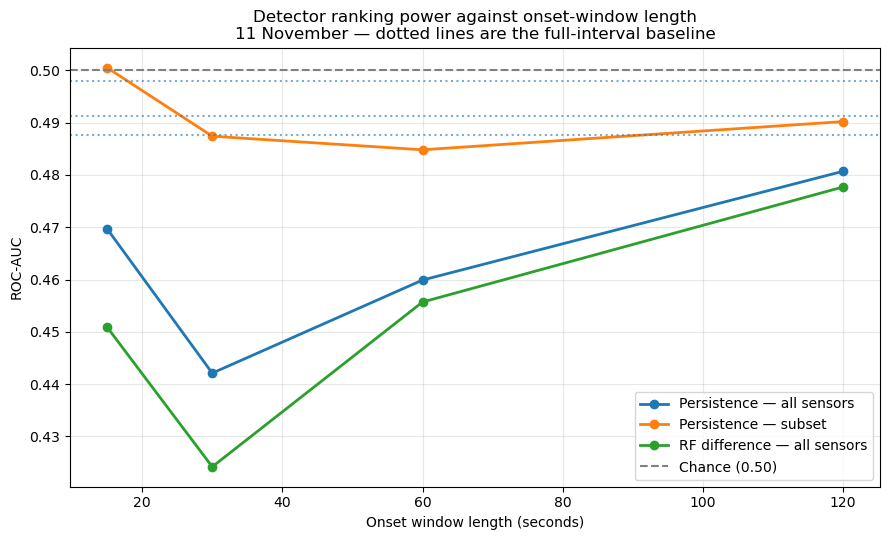

In [233]:
from sklearn.metrics import average_precision_score, roc_auc_score
 
 
def build_onset_mask(
    pred_df,
    attack_intervals,
    onset_seconds,
    evaluation_start,
):
    """
    Returns a frame with:
        onset_label : 1 = attack onset window, 0 = normal
        include     : False for attack rows outside the onset window
    """
    df = pred_df.copy()
    df["t_stamp"] = pd.to_datetime(df["t_stamp"])
    df = df.loc[df["t_stamp"] >= pd.to_datetime(evaluation_start)].copy()
 
    reference_date = df["t_stamp"].dt.date.iloc[0]
 
    df["onset_label"] = 0
    df["include"] = True
 
    for start, end in attack_intervals:
        start_dt = pd.to_datetime(f"{reference_date} {start}")
        end_dt = pd.to_datetime(f"{reference_date} {end}")
        onset_end = start_dt + pd.Timedelta(seconds=onset_seconds)
 
        in_event = (
            (df["t_stamp"] >= start_dt)
            & (df["t_stamp"] <= end_dt)
        )

        if onset_seconds >= 99999:

            # Full interval means exactly the
            # labelled attack interval.
            in_onset = in_event.copy()

        else:

            # Onset window must NEVER extend
            # beyond the attack interval.
            in_onset = (
                in_event
                & (df["t_stamp"] < onset_end)
            )
 
        df.loc[in_onset, "onset_label"] = 1
        # Attack rows after the onset window are excluded from scoring
        df.loc[in_event & ~in_onset, "include"] = False
 
    return df
 
 
def score_onset_relabelling(
    model_inputs,
    attack_intervals,
    evaluation_start,
    onset_seconds_grid=(15, 30, 60, 120, 99999),
):
    """onset_seconds=99999 reproduces the original full-interval labelling."""
    records = []
 
    for model_name, pred_df in model_inputs.items():
        for onset_seconds in onset_seconds_grid:
            frame = build_onset_mask(
                pred_df=pred_df,
                attack_intervals=attack_intervals,
                onset_seconds=onset_seconds,
                evaluation_start=evaluation_start,
            )
 
            scored = frame.loc[frame["include"]].copy()
            scored["anomaly_score"] = pd.to_numeric(
                scored["anomaly_score"], errors="coerce"
            )
            scored = scored.dropna(subset=["anomaly_score", "onset_label"])
 
            y_true = scored["onset_label"].astype(int)
 
            if y_true.nunique() < 2:
                continue
 
            prevalence = float(y_true.mean())
            ap = average_precision_score(y_true, scored["anomaly_score"])
            auc = roc_auc_score(y_true, scored["anomaly_score"])
 
            records.append(
                {
                    "model": model_name,
                    "onset_seconds": (
                        "full interval"
                        if onset_seconds >= 99999
                        else onset_seconds
                    ),
                    "scored_rows": int(len(y_true)),
                    "positive_rows": int(y_true.sum()),
                    "prevalence": round(prevalence, 4),
                    "average_precision": round(float(ap), 4),
                    "roc_auc": round(float(auc), 4),
                    "ap_lift": round(float(ap) / prevalence, 4),
                }
            )
 
    return pd.DataFrame(records)
 
 
# ---- run it -----------------------------------------------------------
onset_model_inputs_11 = {
    "Persistence — all sensors": normal_only_persistence_11_pred_df,
    "RF difference — all sensors": selected_normal_only_rf_11_pred_df,
}
 
# Include the subset detectors if those variables exist
if "selected_persistence_subset_11_df" in globals():
    onset_model_inputs_11["Persistence — subset"] = (
        selected_persistence_subset_11_df
    )
 
onset_results_11 = score_onset_relabelling(
    model_inputs=onset_model_inputs_11,
    attack_intervals=intervals_11,
    evaluation_start=train_end_time_11,
)
 
print("=== Onset-window relabelling, 11 November ===")
print("If ROC-AUC climbs as the onset window narrows, the flat AUC is a")
print("labelling artefact rather than a detector failure.\n")
display(
    onset_results_11.sort_values(
        ["model", "onset_seconds"]
    ).reset_index(drop=True)
)
onset_results_11.to_csv("onset_relabelling_auc_11nov.csv", index=False)
 
# Same test on the cross-day set
onset_model_inputs_10 = {
    "Frozen persistence — all sensors": normal_only_persistence_10_pred_df,
    "Frozen RF difference — all sensors": selected_normal_only_rf_10_pred_df,
}
 
onset_results_10 = score_onset_relabelling(
    model_inputs=onset_model_inputs_10,
    attack_intervals=intervals_10,
    evaluation_start=strict_cross_day_start,
)
 
print("\n=== Onset-window relabelling, 10 November (cross-day) ===")
display(
    onset_results_10.sort_values(
        ["model", "onset_seconds"]
    ).reset_index(drop=True)
)
onset_results_10.to_csv("onset_relabelling_auc_10nov.csv", index=False)
 
 
# ---- one plot that makes the point --------------------------------------
import matplotlib.pyplot as plt
 
plot_df = onset_results_11.loc[
    onset_results_11["onset_seconds"] != "full interval"
].copy()
 
if not plot_df.empty:
    plt.figure(figsize=(9, 5.5))
 
    for model_name, group in plot_df.groupby("model"):
        group = group.sort_values("onset_seconds")
        plt.plot(
            group["onset_seconds"],
            group["roc_auc"],
            marker="o",
            linewidth=2,
            label=model_name,
        )
 
    # Full-interval reference values
    for model_name, group in onset_results_11.loc[
        onset_results_11["onset_seconds"] == "full interval"
    ].groupby("model"):
        plt.axhline(
            y=group["roc_auc"].iloc[0],
            linestyle=":",
            alpha=0.6,
        )
 
    plt.axhline(y=0.5, linestyle="--", color="grey", label="Chance (0.50)")
    plt.xlabel("Onset window length (seconds)")
    plt.ylabel("ROC-AUC")
    plt.title(
        "Detector ranking power against onset-window length\n"
        "11 November — dotted lines are the full-interval baseline"
    )
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig("onset_relabelling_auc_11nov.png", dpi=300,
                bbox_inches="tight")
    plt.show()
 

In [234]:
import numpy as np
import pandas as pd


def rescore_with_threshold_floor(
    pred_df,
    selected_sensors,
    residual_suffix,
    calibration_start,
    calibration_end,
    quantile=0.99,
    min_sensors_triggered=1,
    max_zero_fraction=0.95,
    drop_degenerate=False,
):
    """
    Re-score an existing residual detector.

    Threshold:
        q-th quantile of the held-out calibration residuals.

    Resolution floor:
        smallest positive residual observed in the earlier
        normal development/training period.

    This avoids replacing a genuinely zero calibration
    threshold with an arbitrary value such as 1e-9.
    """

    df = pred_df.copy()

    df["t_stamp"] = pd.to_datetime(df["t_stamp"])

    calibration_start = pd.to_datetime(
        calibration_start
    )

    calibration_end = pd.to_datetime(
        calibration_end
    )

    calibration_mask = (
        (df["t_stamp"] >= calibration_start)
        & (df["t_stamp"] < calibration_end)
        & (df["attack_label"] == 0)
    )

    # Earlier normal-only data:
    # used to estimate the actual observed sensor resolution.
    resolution_reference_mask = (
        (df["t_stamp"] < calibration_start)
        & (df["attack_label"] == 0)
    )

    prefix = residual_suffix.removesuffix(
        "_residual"
    )

    normalized_cols = []
    trigger_cols = []
    threshold_records = []

    for sensor in selected_sensors:

        residual_col = (
            f"{sensor}_{residual_suffix}"
        )

        normalized_col = (
            f"{sensor}_{prefix}_normalized_residual"
        )

        trigger_col = (
            f"{sensor}_{prefix}_triggered"
        )

        if residual_col not in df.columns:
            raise KeyError(
                f"Missing residual column: {residual_col}"
            )

        calibration_residuals = (
            pd.to_numeric(
                df.loc[
                    calibration_mask,
                    residual_col
                ],
                errors="coerce"
            )
            .dropna()
        )

        reference_residuals = (
            pd.to_numeric(
                df.loc[
                    resolution_reference_mask,
                    residual_col
                ],
                errors="coerce"
            )
            .dropna()
        )

        if calibration_residuals.empty:
            raise ValueError(
                f"No calibration residuals for {sensor}."
            )

        raw_threshold = float(
            calibration_residuals.quantile(
                quantile
            )
        )

        zero_fraction = float(
            np.isclose(
                calibration_residuals.to_numpy(),
                0.0,
                atol=1e-12
            ).mean()
        )

        positive_reference = (
            reference_residuals[
                reference_residuals > 1e-12
            ]
        )

        if positive_reference.empty:
            resolution_floor = np.nan
        else:
            resolution_floor = float(
                positive_reference.min()
            )

        degenerate = (
            zero_fraction > max_zero_fraction
        )

        if drop_degenerate and degenerate:

            applied_threshold = np.nan

            df[normalized_col] = np.nan
            df[trigger_col] = 0

            kept = False

        else:

            if np.isfinite(resolution_floor):
                applied_threshold = max(
                    raw_threshold,
                    resolution_floor
                )

            elif raw_threshold > 0:
                applied_threshold = raw_threshold

            else:
                # Completely static even in the earlier
                # normal reference period.
                applied_threshold = np.inf

            df[normalized_col] = (
                pd.to_numeric(
                    df[residual_col],
                    errors="coerce"
                )
                / applied_threshold
            )

            df[trigger_col] = (
                df[normalized_col] > 1
            ).astype(int)

            normalized_cols.append(
                normalized_col
            )

            trigger_cols.append(
                trigger_col
            )

            kept = True

        threshold_records.append({
            "sensor": sensor,
            "calibration_rows":
                len(calibration_residuals),
            "zero_fraction":
                zero_fraction,
            "raw_quantile_threshold":
                raw_threshold,
            "resolution_floor":
                resolution_floor,
            "applied_threshold":
                applied_threshold,
            "degenerate":
                degenerate,
            "kept":
                kept
        })

    if not normalized_cols:
        raise ValueError(
            "No sensors survived the "
            "degeneracy filter."
        )

    df["anomaly_score"] = (
        df[normalized_cols].max(axis=1)
    )

    df["num_sensors_triggered"] = (
        df[trigger_cols].sum(axis=1)
    )

    df["predicted_anomaly"] = (
        df["num_sensors_triggered"]
        >= min_sensors_triggered
    ).astype(int)

    threshold_details = pd.DataFrame(
        threshold_records
    )

    return df, threshold_details

In [235]:
# Variant A:
# keep every sensor, but floor threshold
# at its observed calibration resolution.

(
    floored_pred_11,
    floored_thresholds_11
) = rescore_with_threshold_floor(
    pred_df=normal_only_persistence_11_pred_df,
    selected_sensors=normal_only_sensors,
    residual_suffix=(
        "persistence_common_residual"
    ),
    calibration_start=(
        common_calibration_start
    ),
    calibration_end=train_end_time_11,
    quantile=0.99,
    min_sensors_triggered=1,
    drop_degenerate=False
)

print(
    "\n=== Applied thresholds "
    "(floored variant) ==="
)

display(
    floored_thresholds_11
)


# Variant B:
# progressively remove sensors whose
# calibration residuals are mostly zero.

print(
    "\n=== Degeneracy sweep ==="
)

survival_records = []

dropped_pred_11 = None
surviving_sensors = None

for max_zero in (
    0.50,
    0.70,
    0.90,
    0.95,
    0.999
):

    try:

        (
            candidate_df,
            candidate_thresholds
        ) = rescore_with_threshold_floor(
            pred_df=(
                normal_only_persistence_11_pred_df
            ),
            selected_sensors=(
                normal_only_sensors
            ),
            residual_suffix=(
                "persistence_common_residual"
            ),
            calibration_start=(
                common_calibration_start
            ),
            calibration_end=(
                train_end_time_11
            ),
            quantile=0.99,
            min_sensors_triggered=1,
            max_zero_fraction=max_zero,
            drop_degenerate=True
        )

        kept = candidate_thresholds.loc[
            candidate_thresholds[
                "applied_threshold"
            ].notna(),
            "sensor"
        ].tolist()

        survival_records.append({
            "max_zero_fraction":
                max_zero,
            "sensors_kept":
                len(kept),
            "kept":
                ", ".join(kept)
        })

        # Use the strictest filter that
        # still leaves at least 2 sensors.
        if (
            dropped_pred_11 is None
            and len(kept) >= 2
        ):
            dropped_pred_11 = (
                candidate_df.copy()
            )

            surviving_sensors = (
                kept.copy()
            )

    except ValueError:

        survival_records.append({
            "max_zero_fraction":
                max_zero,
            "sensors_kept":
                0,
            "kept":
                "none"
        })


degeneracy_survival_df = pd.DataFrame(
    survival_records
)

display(
    degeneracy_survival_df
)


# Compare detectors

results_to_compare = [
    normal_only_persistence_11_results
]

(
    _,
    floored_results_11,
    floored_events_11
) = evaluate_on_common_window(
    pred_df=floored_pred_11,
    model_name=(
        "Persistence — "
        "resolution-floored thresholds"
    ),
    evaluation_start=(
        train_end_time_11
    ),
    attack_intervals=intervals_11
)

results_to_compare.append(
    floored_results_11
)


if dropped_pred_11 is not None:

    (
        _,
        dropped_results_11,
        dropped_events_11
    ) = evaluate_on_common_window(
        pred_df=dropped_pred_11,
        model_name=(
            "Persistence — "
            "non-degenerate only "
            f"({len(surviving_sensors)} sensors)"
        ),
        evaluation_start=(
            train_end_time_11
        ),
        attack_intervals=intervals_11
    )

    results_to_compare.append(
        dropped_results_11
    )

else:

    print(
        "\nNo subset containing at least "
        "two sensors survived the "
        "degeneracy filters."
    )


degenerate_fix_comparison = (
    pd.DataFrame(
        results_to_compare
    )[
        [
            "model",
            "attack_precision",
            "attack_recall",
            "attack_f1",
            "false_alarm_rate",
            "detected_events",
            "event_detection_rate",
            "average_detection_delay"
        ]
    ]
)

print(
    "\n=== Effect of fixing "
    "degenerate thresholds ==="
)

display(
    degenerate_fix_comparison
)

degenerate_fix_comparison.to_csv(
    "degenerate_threshold_fix_comparison_11nov.csv",
    index=False
)


=== Applied thresholds (floored variant) ===


,sensor,calibration_rows,zero_fraction,raw_quantile_threshold,resolution_floor,applied_threshold,degenerate,kept
0,FIT201.Pv,918,0.838780,0.330428,0.000128,0.330428,False,True
1,FIT101.Pv,918,1.000000,0.000000,0.000320,0.000320,True,True
2,AIT302.Pv,918,0.640523,0.845135,0.025600,0.845135,False,True
3,AIT402.Pv,918,0.918301,0.205078,0.025621,0.205078,False,True
4,AIT502.Pv,918,0.859477,0.281983,0.025624,0.281983,False,True



=== Degeneracy sweep ===


,max_zero_fraction,sensors_kept,kept
0,0.500,0,none
1,0.700,1,AIT302.Pv
2,0.900,3,"FIT201.Pv, AIT302.Pv, AIT502.Pv"
3,0.950,4,"FIT201.Pv, AIT302.Pv, AIT402.Pv, AIT502.Pv"
4,0.999,4,"FIT201.Pv, AIT302.Pv, AIT402.Pv, AIT502.Pv"



=== Effect of fixing degenerate thresholds ===


,model,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay
0,Normal-only sensors — global persistence q=0.99,0.447917,0.148429,0.222971,13.695090,17,100.000000,15.823529
1,Persistence — resolution-floored thresholds,0.448384,0.148429,0.223029,13.669251,17,100.000000,15.823529
2,Persistence — non-degenerate only (3 sensors),0.391111,0.030376,0.056374,3.540052,16,94.117647,40.562500


In [236]:
def select_temporal_filter_frontier(
    tuning_df,
    total_events,
    minimum_event_detection_rate=90.0,
):
    """Return, per base model, the filter with the lowest false-alarm rate
    that still meets a relaxed event-detection floor."""
    frontier_rows = []
 
    for model_name, group in tuning_df.groupby("base_model"):
        eligible = group.loc[
            group["event_detection_rate"] >= minimum_event_detection_rate
        ].copy()
 
        if eligible.empty:
            eligible = group.copy()
 
        eligible = eligible.sort_values(
            by=["false_alarm_rate", "average_detection_delay"],
            ascending=[True, True],
        )
 
        best = eligible.iloc[0].copy()
        best["selection_rule"] = (
            f"min FAR subject to event rate >= "
            f"{minimum_event_detection_rate:.0f}%"
        )
        frontier_rows.append(best)
 
    return pd.DataFrame(frontier_rows).reset_index(drop=True)
 
 
print("=== Temporal filter: full frontier, all configurations ===")
temporal_frontier_view = temporal_filter_tuning_df[
    [
        "base_model",
        "window_size",
        "minimum_hits",
        "attack_recall",
        "attack_f1",
        "false_alarm_rate",
        "detected_events",
        "event_detection_rate",
        "average_detection_delay",
    ]
].sort_values(
    ["base_model", "false_alarm_rate"]
).reset_index(drop=True)
 
display(temporal_frontier_view)
temporal_frontier_view.to_csv(
    "temporal_filter_full_frontier_11nov.csv", index=False
)
 
for event_floor in (100.0, 95.0, 90.0, 85.0):
    print(f"\n--- Selection at event-detection floor {event_floor:.0f}% ---")
    display(
        select_temporal_filter_frontier(
            tuning_df=temporal_filter_tuning_df,
            total_events=len(intervals_11),
            minimum_event_detection_rate=event_floor,
        )[
            [
                "base_model",
                "window_size",
                "minimum_hits",
                "false_alarm_rate",
                "detected_events",
                "average_detection_delay",
            ]
        ]
    )

=== Temporal filter: full frontier, all configurations ===


,base_model,window_size,minimum_hits,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay
0,Persistence q=0.99,3,3,0.034518,0.062716,4.961240,6,35.294118,49.666667
1,Persistence q=0.99,5,4,0.046945,0.083795,5.503876,5,29.411765,31.400000
2,Persistence q=0.99,2,2,0.064550,0.111809,6.744186,9,52.941176,44.888889
3,Persistence q=0.99,5,3,0.106662,0.173206,9.354005,8,47.058824,46.125000
4,Persistence q=0.99,3,2,0.112185,0.180656,9.715762,10,58.823529,44.100000
5,Persistence q=0.99,10,5,0.119434,0.189901,10.361757,5,29.411765,30.200000
6,Persistence q=0.99,1,1,0.148429,0.222971,13.695090,17,100.000000,15.823529
7,Persistence q=0.99,5,2,0.184674,0.267233,14.780362,15,88.235294,60.600000
8,Persistence q=0.99,10,3,0.214014,0.301630,15.348837,11,64.705882,38.363636
9,RF difference q=0.99,3,3,0.025544,0.046939,4.702842,10,58.823529,58.100000



--- Selection at event-detection floor 100% ---


,base_model,window_size,minimum_hits,false_alarm_rate,detected_events,average_detection_delay
0,Persistence q=0.99,1,1,13.695090,17,15.823529
1,RF difference q=0.99,1,1,12.273902,17,17.705882



--- Selection at event-detection floor 95% ---


,base_model,window_size,minimum_hits,false_alarm_rate,detected_events,average_detection_delay
0,Persistence q=0.99,1,1,13.695090,17,15.823529
1,RF difference q=0.99,1,1,12.273902,17,17.705882



--- Selection at event-detection floor 90% ---


,base_model,window_size,minimum_hits,false_alarm_rate,detected_events,average_detection_delay
0,Persistence q=0.99,1,1,13.695090,17,15.823529
1,RF difference q=0.99,1,1,12.273902,17,17.705882



--- Selection at event-detection floor 85% ---


,base_model,window_size,minimum_hits,false_alarm_rate,detected_events,average_detection_delay
0,Persistence q=0.99,1,1,13.695090,17,15.823529
1,RF difference q=0.99,1,1,12.273902,17,17.705882


In [237]:
from scipy.stats import beta


def exact_event_detection_interval(
    event_results_df,
    confidence_level=0.95
):
    detected = (
        event_results_df["detected"]
        .astype(int)
        .to_numpy()
    )

    successes = int(detected.sum())
    n_events = int(len(detected))

    if n_events == 0:
        raise ValueError(
            "No attack events were supplied."
        )

    alpha = 1 - confidence_level

    if successes == 0:
        lower = 0.0
    else:
        lower = beta.ppf(
            alpha / 2,
            successes,
            n_events - successes + 1
        )

    if successes == n_events:
        upper = 1.0
    else:
        upper = beta.ppf(
            1 - alpha / 2,
            successes + 1,
            n_events - successes
        )

    return {
        "point_estimate":
            successes / n_events * 100,
        "ci_lower":
            lower * 100,
        "ci_upper":
            upper * 100,
        "n_events":
            n_events
    }


def block_bootstrap_false_alarm_rate(
    eval_df,
    block_size=60,
    n_bootstrap=2000,
    random_state=42,
):
    """
    Moving-block bootstrap for the false-alarm
    rate on normal rows.
    """

    rng = np.random.default_rng(
        random_state
    )

    normal = (
        eval_df.loc[
            eval_df["attack_label"] == 0,
            "predicted_anomaly"
        ]
        .astype(int)
        .to_numpy()
    )

    n = len(normal)

    if n == 0:
        raise ValueError(
            "No normal rows are available."
        )

    if n <= block_size:
        return {
            "point_estimate":
                float(normal.mean() * 100),
            "ci_lower":
                np.nan,
            "ci_upper":
                np.nan,
            "normal_rows":
                int(n)
        }

    n_blocks = int(
        np.ceil(n / block_size)
    )

    max_start = (
        n - block_size
    )

    rates = []

    for _ in range(n_bootstrap):

        starts = rng.integers(
            0,
            max_start + 1,
            size=n_blocks
        )

        sample = np.concatenate(
            [
                normal[
                    start:
                    start + block_size
                ]
                for start in starts
            ]
        )[:n]

        rates.append(
            sample.mean() * 100
        )

    rates = np.asarray(rates)

    return {
        "point_estimate":
            float(normal.mean() * 100),

        "ci_lower":
            float(
                np.percentile(
                    rates,
                    2.5
                )
            ),

        "ci_upper":
            float(
                np.percentile(
                    rates,
                    97.5
                )
            ),

        "normal_rows":
            int(n)
    }


uncertainty_inputs = {
    "Frozen persistence — all sensors": (
        normal_only_persistence_10_pred_df,
        normal_only_persistence_10_events
    ),

    "Frozen RF difference — all sensors": (
        selected_normal_only_rf_10_pred_df,
        selected_normal_only_rf_10_events
    )
}


if (
    "selected_persistence_subset_10_events"
    in globals()
):
    uncertainty_inputs[
        "Frozen persistence — subset"
    ] = (
        selected_persistence_subset_10_df,
        selected_persistence_subset_10_events
    )


if (
    "selected_rf_subset_10_events"
    in globals()
):
    uncertainty_inputs[
        "Frozen RF difference — subset"
    ] = (
        selected_rf_subset_10_df,
        selected_rf_subset_10_events
    )


uncertainty_records = []


for (
    model_name,
    (pred_df, event_df)
) in uncertainty_inputs.items():

    (
        eval_df,
        _,
        _
    ) = evaluate_on_common_window(
        pred_df=pred_df,
        model_name=model_name,
        evaluation_start=(
            strict_cross_day_start
        ),
        attack_intervals=intervals_10
    )

    event_ci = (
        exact_event_detection_interval(
            event_df
        )
    )

    far_ci = (
        block_bootstrap_false_alarm_rate(
            eval_df
        )
    )

    uncertainty_records.append({
        "model":
            model_name,

        "n_events":
            event_ci["n_events"],

        "event_rate_%":
            round(
                event_ci[
                    "point_estimate"
                ],
                1
            ),

        "event_rate_95CI":
            (
                f"[{event_ci['ci_lower']:.1f}, "
                f"{event_ci['ci_upper']:.1f}]"
            ),

        "false_alarm_%":
            round(
                far_ci[
                    "point_estimate"
                ],
                2
            ),

        "false_alarm_95CI":
            (
                f"[{far_ci['ci_lower']:.2f}, "
                f"{far_ci['ci_upper']:.2f}]"
            )
    })


cross_day_uncertainty_10 = (
    pd.DataFrame(
        uncertainty_records
    )
)


print(
    "=== Cross-day uncertainty intervals, "
    "10 November ==="
)

print(
    "Event detection: exact binomial 95% CI.\n"
    "False-alarm rate: moving-block "
    "bootstrap 95% CI.\n"
)

display(
    cross_day_uncertainty_10
)


cross_day_uncertainty_10.to_csv(
    "cross_day_uncertainty_intervals_10nov.csv",
    index=False
)

=== Cross-day uncertainty intervals, 10 November ===
Event detection: exact binomial 95% CI.
False-alarm rate: moving-block bootstrap 95% CI.



,model,n_events,event_rate_%,event_rate_95CI,false_alarm_%,false_alarm_95CI
0,Frozen persistence — all sensors,4,100.0,"[39.8, 100.0]",8.25,"[3.76, 14.46]"
1,Frozen RF difference — all sensors,4,100.0,"[39.8, 100.0]",7.57,"[5.35, 10.25]"
2,Frozen persistence — subset,4,100.0,"[39.8, 100.0]",1.59,"[0.82, 2.22]"
3,Frozen RF difference — subset,4,100.0,"[39.8, 100.0]",1.31,"[0.68, 1.90]"


In [238]:
# ============================================================
# Final corrected persistence detector:
# freeze 11-Nov resolution-floored thresholds
# and transfer them unchanged to 10-Nov
# ============================================================

floored_threshold_bundle_11 = {}


for _, row in (
    floored_thresholds_11.iterrows()
):

    sensor = row["sensor"]

    threshold = float(
        row["applied_threshold"]
    )

    if (
        not np.isfinite(threshold)
        or threshold <= 0
    ):
        raise ValueError(
            f"Invalid threshold for "
            f"{sensor}: {threshold}"
        )

    floored_threshold_bundle_11[
        sensor
    ] = {
        "state_column":
            normal_only_sensor_state_map[
                sensor
            ],

        "global_threshold":
            threshold,

        "state_thresholds":
            {}
    }


print(
    "=== Frozen resolution-floored "
    "thresholds ==="
)

for (
    sensor,
    bundle
) in (
    floored_threshold_bundle_11.items()
):

    print(
        f"{sensor}: "
        f"{bundle['global_threshold']:.9f}"
    )


# ------------------------------------------------------------
# Apply them to 10 November.
#
# IMPORTANT:
# No fitting or recalibration occurs on 10-Nov.
# ------------------------------------------------------------

floored_persistence_10_pred_df = (
    apply_frozen_persistence_detector(
        df_clean=df10_clean,
        selected_sensors=(
            normal_only_sensors
        ),
        threshold_bundle=(
            floored_threshold_bundle_11
        ),
        min_sensors_triggered=1,
        use_state_thresholds=False
    )
)


(
    floored_persistence_10_eval_df,
    floored_persistence_10_results,
    floored_persistence_10_events
) = evaluate_on_common_window(
    pred_df=(
        floored_persistence_10_pred_df
    ),
    model_name=(
        "Frozen resolution-floored "
        "persistence q=0.99"
    ),
    evaluation_start=(
        strict_cross_day_start
    ),
    attack_intervals=intervals_10
)


print(
    "\n=== Frozen corrected persistence: "
    "10 November ==="
)

display(
    pd.DataFrame([
        floored_persistence_10_results
    ])
)

print(
    "\n=== Attack-event detections ==="
)

display(
    floored_persistence_10_events
)

=== Frozen resolution-floored thresholds ===
FIT201.Pv: 0.330427717
FIT101.Pv: 0.000319960
AIT302.Pv: 0.845134980
AIT402.Pv: 0.205078000
AIT502.Pv: 0.281982660

=== Frozen corrected persistence: 10 November ===


,model,evaluation_start,evaluation_rows,normal_rows,attack_rows,accuracy,attack_precision,attack_recall,attack_f1,true_normal,false_alarm,missed_attack,detected_attack_rows,false_alarm_rate,detected_events,total_events,event_detection_rate,average_detection_delay,median_detection_delay,maximum_detection_delay
0,Frozen resolution-floored persistence q=0.99,2022-11-10 11:00:11,3590,2206,1384,0.608635,0.469388,0.116329,0.18645,2024,182,1223,161,8.250227,4,4,100.0,29.5,29.5,41.0



=== Attack-event detections ===


,attack_event,start_time,end_time,detected,first_detection_time,detection_delay_seconds,total_rows_in_attack,detected_rows_in_attack
0,1,2022-11-10 11:03:00,2022-11-10 11:10:00,1,2022-11-10 11:03:18,18.0,421,17
1,2,2022-11-10 11:25:00,2022-11-10 11:30:00,1,2022-11-10 11:25:38,38.0,301,13
2,3,2022-11-10 11:34:00,2022-11-10 11:41:00,1,2022-11-10 11:34:21,21.0,421,25
3,4,2022-11-10 11:45:00,2022-11-10 11:49:00,1,2022-11-10 11:45:41,41.0,241,106


In [239]:
comparison_metrics = [
    "attack_precision",
    "attack_recall",
    "attack_f1",
    "false_alarm_rate",
    "detected_events",
    "event_detection_rate",
    "average_detection_delay"
]


comparison_records = []


for (
    dataset_name,
    threshold_version,
    result_dict
) in [
    (
        "11 Nov development",
        "Original q=0.99 threshold",
        normal_only_persistence_11_results
    ),

    (
        "11 Nov development",
        "Resolution-floored threshold",
        floored_results_11
    ),

    (
        "10 Nov cross-day transfer",
        "Original frozen q=0.99 threshold",
        normal_only_persistence_10_results
    ),

    (
        "10 Nov cross-day transfer",
        "Frozen resolution-floored threshold",
        floored_persistence_10_results
    )
]:

    record = {
        "dataset":
            dataset_name,

        "threshold_version":
            threshold_version
    }

    for metric in comparison_metrics:
        record[metric] = (
            result_dict[metric]
        )

    comparison_records.append(
        record
    )


final_threshold_correction_comparison = (
    pd.DataFrame(
        comparison_records
    )
)


print(
    "=== Original versus corrected "
    "persistence thresholds ==="
)

display(
    final_threshold_correction_comparison
)


final_threshold_correction_comparison.to_csv(
    "final_threshold_correction_comparison.csv",
    index=False
)

=== Original versus corrected persistence thresholds ===


,dataset,threshold_version,attack_precision,attack_recall,attack_f1,false_alarm_rate,detected_events,event_detection_rate,average_detection_delay
0,11 Nov development,Original q=0.99 threshold,0.447917,0.148429,0.222971,13.695090,17,100.0,15.823529
1,11 Nov development,Resolution-floored threshold,0.448384,0.148429,0.223029,13.669251,17,100.0,15.823529
2,10 Nov cross-day transfer,Original frozen q=0.99 threshold,0.469388,0.116329,0.186450,8.250227,4,100.0,29.500000
3,10 Nov cross-day transfer,Frozen resolution-floored threshold,0.469388,0.116329,0.186450,8.250227,4,100.0,29.500000


In [240]:
(
    floored_event_quality_10,
    floored_event_quality_summary_10
) = evaluate_event_detection_quality(
    pred_df=(
        floored_persistence_10_pred_df
    ),
    attack_intervals=intervals_10,
    model_name=(
        "Frozen resolution-floored "
        "persistence"
    ),
    evaluation_start=(
        strict_cross_day_start
    )
)


print(
    "=== Corrected detector: "
    "robust event quality, 10 November ==="
)

display(
    pd.DataFrame([
        floored_event_quality_summary_10
    ])
)


display(
    floored_event_quality_10[
        [
            "attack_event",
            "total_event_rows",
            "alarm_rows",
            "alarm_coverage_percentage",
            "longest_consecutive_alarm_run",
            "first_detection_delay_seconds",
            "any_hit_detected",
            "robust_combined_detection"
        ]
    ]
)


floored_event_quality_10.to_csv(
    "floored_persistence_event_quality_10nov.csv",
    index=False
)


pd.DataFrame([
    floored_event_quality_summary_10
]).to_csv(
    "floored_persistence_event_quality_summary_10nov.csv",
    index=False
)

=== Corrected detector: robust event quality, 10 November ===


,model,total_events,events_with_any_hit,events_with_3_or_more_alarm_rows,events_with_at_least_1_percent_coverage,events_with_2_consecutive_alarm_rows,robustly_detected_events,mean_event_alarm_coverage_percentage,median_event_alarm_coverage_percentage,mean_longest_alarm_run,average_first_detection_delay,median_first_detection_delay,maximum_first_detection_delay
0,Frozen resolution-floored persistence,4,4,4,4,3,3,14.569647,5.12859,5.75,29.5,29.5,41.0


,attack_event,total_event_rows,alarm_rows,alarm_coverage_percentage,longest_consecutive_alarm_run,first_detection_delay_seconds,any_hit_detected,robust_combined_detection
0,1,421,17,4.038005,2,18.0,1,1
1,2,301,13,4.318937,2,38.0,1,1
2,3,421,25,5.938242,1,21.0,1,0
3,4,241,106,43.983402,18,41.0,1,1


In [241]:
floored_false_alarm_burden_10 = (
    calculate_false_alarm_burden(
        pred_df=(
            floored_persistence_10_pred_df
        ),
        model_name=(
            "Frozen resolution-floored "
            "persistence"
        ),
        evaluation_start=(
            strict_cross_day_start
        )
    )
)


print(
    "=== Corrected detector "
    "false-alarm burden ==="
)

display(
    pd.DataFrame([
        floored_false_alarm_burden_10
    ])
)

=== Corrected detector false-alarm burden ===


,model,normal_rows,normal_exposure_hours,false_alarm_rows,false_alarm_episodes,false_alarm_rows_per_hour,false_alarm_episodes_per_hour
0,Frozen resolution-floored persistence,2206,0.612778,182,89,297.00816,145.240254


In [242]:
# ============================================================
# Rebuild final explanation records using the corrected
# resolution-floored persistence detector
# ============================================================

corrected_explanation_payloads_11 = (
    build_event_explanation_payloads(
        pred_df=floored_pred_11,
        attack_intervals=intervals_11,
        selected_sensors=(
            normal_only_sensors
        ),
        model_name=(
            "Resolution-floored "
            "persistence q=0.99"
        ),
        evaluation_start=(
            train_end_time_11
        ),
        prediction_suffix=(
            "persistence_common_prediction"
        ),
        residual_suffix=(
            "persistence_common_residual"
        ),
        normalized_suffix=(
            "persistence_common_normalized_residual"
        ),
        sensor_state_map=(
            normal_only_sensor_state_map
        ),
        number_of_contributors=3
    )
)


corrected_explanation_payloads_11.insert(
    0,
    "dataset_split",
    "development_11nov"
)


corrected_explanation_payloads_10 = (
    build_event_explanation_payloads(
        pred_df=(
            floored_persistence_10_pred_df
        ),
        attack_intervals=intervals_10,
        selected_sensors=(
            normal_only_sensors
        ),
        model_name=(
            "Frozen resolution-floored "
            "persistence q=0.99"
        ),
        evaluation_start=(
            strict_cross_day_start
        ),
        prediction_suffix=(
            "frozen_prediction"
        ),
        residual_suffix=(
            "frozen_residual"
        ),
        normalized_suffix=(
            "frozen_normalized_residual"
        ),
        sensor_state_map=(
            normal_only_sensor_state_map
        ),
        number_of_contributors=3
    )
)


corrected_explanation_payloads_10.insert(
    0,
    "dataset_split",
    "cross_day_10nov"
)


all_explanation_payloads = pd.concat(
    [
        corrected_explanation_payloads_11,
        corrected_explanation_payloads_10
    ],
    ignore_index=True
)


assert (
    len(all_explanation_payloads) == 21
), (
    "Expected 21 attack-event "
    "explanation payloads."
)


assert np.isfinite(
    all_explanation_payloads[
        "system_anomaly_score"
    ].astype(float)
).all()


print(
    "Corrected explanation payloads:",
    len(all_explanation_payloads)
)


print(
    "Maximum corrected anomaly score:",
    all_explanation_payloads[
        "system_anomaly_score"
    ].max()
)


display(
    all_explanation_payloads[
        [
            "dataset_split",
            "attack_event",
            "detected",
            "reference_timestamp",
            "detection_delay_seconds",
            "system_anomaly_score",
            "number_of_sensors_triggered"
        ]
    ]
)


all_explanation_payloads.to_json(
    "all_event_explanation_payloads.jsonl",
    orient="records",
    lines=True,
    date_format="iso"
)

Corrected explanation payloads: 21
Maximum corrected anomaly score: 911.9011438939121


,dataset_split,attack_event,detected,reference_timestamp,detection_delay_seconds,system_anomaly_score,number_of_sensors_triggered
0,development_11nov,1,1,2022-11-11 09:51:31,31.0,1.125001,1
1,development_11nov,2,1,2022-11-11 09:59:12,12.0,1.249978,1
2,development_11nov,3,1,2022-11-11 10:03:00,0.0,911.901144,1
3,development_11nov,4,1,2022-11-11 10:09:03,3.0,8.008970,1
4,development_11nov,5,1,2022-11-11 10:14:19,19.0,1.091032,1
5,development_11nov,6,1,2022-11-11 10:20:23,23.0,1.000061,1
6,development_11nov,7,1,2022-11-11 10:24:15,15.0,1.375087,1
7,development_11nov,8,1,2022-11-11 10:29:30,30.0,1.000107,1
8,development_11nov,9,1,2022-11-11 10:34:08,8.0,1.181807,1
9,development_11nov,10,1,2022-11-11 10:41:21,21.0,1.060576,1


In [243]:
display(
    all_explanation_payloads[
        [
            "dataset_split",
            "attack_event",
            "system_anomaly_score"
        ]
    ]
    .sort_values(
        "system_anomaly_score",
        ascending=False
    )
    .head(10)
)

,dataset_split,attack_event,system_anomaly_score
2,development_11nov,3,911.901144
16,development_11nov,17,15.014377
3,development_11nov,4,8.008970
15,development_11nov,16,1.874852
6,development_11nov,7,1.375087
10,development_11nov,11,1.250002
1,development_11nov,2,1.249978
8,development_11nov,9,1.181807
19,cross_day_10nov,3,1.181793
17,cross_day_10nov,1,1.181746


In [244]:
all_explanation_payloads[
    "explanation_prompt"
] = all_explanation_payloads.apply(
    build_grounded_explanation_prompt,
    axis=1
)


all_explanation_payloads[
    "rule_based_explanation"
] = all_explanation_payloads.apply(
    create_rule_based_explanation,
    axis=1
)


all_explanation_payloads[
    [
        "dataset_split",
        "attack_event",
        "system_anomaly_score",
        "explanation_prompt",
        "rule_based_explanation"
    ]
].to_json(
    "final_grounded_explanation_records.jsonl",
    orient="records",
    lines=True,
    date_format="iso"
)


print(
    "Corrected grounded prompts and "
    "rule-based explanations created."
)

Corrected grounded prompts and rule-based explanations created.


In [245]:
import json
import time


def generate_llm_explanation(
    prompt,
    maximum_attempts=3
):
    """
    Generate one grounded structured explanation.

    Returns
    -------
    dict
        Parsed JSON explanation matching
        ANOMALY_EXPLANATION_SCHEMA.
    """

    last_error = None

    for attempt in range(
        1,
        maximum_attempts + 1
    ):

        try:

            response = client.responses.create(
                model=OPENAI_MODEL,

                reasoning={
                    "effort": "minimal"
                },

                instructions=(
                    LLM_SYSTEM_INSTRUCTIONS
                ),

                input=prompt,

                text={
                    "format": {
                        "type": "json_schema",
                        "name": (
                            "industrial_anomaly_explanation"
                        ),
                        "strict": True,
                        "schema": (
                            ANOMALY_EXPLANATION_SCHEMA
                        )
                    }
                },

                max_output_tokens=1500
            )

            # ------------------------------------------
            # Check whether generation actually finished
            # ------------------------------------------

            if response.status != "completed":

                incomplete_details = getattr(
                    response,
                    "incomplete_details",
                    None
                )

                raise RuntimeError(
                    "OpenAI response was not completed. "
                    f"Status: {response.status}. "
                    f"Details: {incomplete_details}"
                )

            # ------------------------------------------
            # Extract text safely
            # ------------------------------------------

            output_text = (
                response.output_text or ""
            ).strip()

            if not output_text:

                raise RuntimeError(
                    "OpenAI returned no output text. "
                    f"Response status: "
                    f"{response.status}. "
                    f"Incomplete details: "
                    f"{getattr(response, 'incomplete_details', None)}"
                )

            # ------------------------------------------
            # Parse structured JSON
            # ------------------------------------------

            explanation = json.loads(
                output_text
            )

            return explanation

        except Exception as error:

            last_error = error

            print(
                f"Attempt {attempt}/"
                f"{maximum_attempts} failed:"
            )

            print(
                type(error).__name__,
                "-",
                str(error)
            )

            if attempt < maximum_attempts:
                time.sleep(
                    2 * attempt
                )

    raise RuntimeError(
        "Explanation generation failed "
        f"after {maximum_attempts} attempts."
    ) from last_error

In [246]:
# ============================================================
# FINAL DETECTOR DECISION
# Corrected resolution-floored persistence is the
# primary balanced detector.
# ============================================================

final_detector_decision_corrected = (
    final_detector_decision.copy()
)

primary_mask = (
    final_detector_decision_corrected[
        "selected_as_primary"
    ] == 1
)


final_detector_decision_corrected.loc[
    primary_mask,
    "model_row_level"
] = (
    "Frozen resolution-floored "
    "persistence q=0.99"
)


# Update row-level metrics
for metric in [
    "false_alarm_rate",
    "attack_recall",
    "attack_f1",
    "average_detection_delay"
]:
    final_detector_decision_corrected.loc[
        primary_mask,
        metric
    ] = floored_persistence_10_results[
        metric
    ]


# Update robust event-level metrics
quality_mapping = {
    "events_with_any_hit":
        "events_with_any_hit",

    "events_with_3_or_more_alarm_rows":
        "events_with_3_or_more_alarm_rows",

    "events_with_2_consecutive_alarm_rows":
        "events_with_2_consecutive_alarm_rows",

    "robustly_detected_events":
        "robustly_detected_events",

    "mean_event_alarm_coverage_percentage":
        "mean_event_alarm_coverage_percentage",

    "mean_longest_alarm_run":
        "mean_longest_alarm_run"
}


for (
    table_column,
    summary_key
) in quality_mapping.items():

    final_detector_decision_corrected.loc[
        primary_mask,
        table_column
    ] = floored_event_quality_summary_10[
        summary_key
    ]


print(
    "=== FINAL DETECTOR DECISION ==="
)

display(
    final_detector_decision_corrected
)


final_detector_decision_corrected.to_csv(
    "final_detector_decision.csv",
    index=False
)

=== FINAL DETECTOR DECISION ===


,model_row_level,false_alarm_rate,attack_recall,attack_f1,average_detection_delay,events_with_any_hit,events_with_3_or_more_alarm_rows,events_with_2_consecutive_alarm_rows,robustly_detected_events,mean_event_alarm_coverage_percentage,mean_longest_alarm_run,role,selected_as_primary
0,Frozen resolution-floored persistence q=0.99,8.250227,0.116329,0.186450,29.5,4,4,3,3,14.569647,5.75,Primary balanced detector,1
1,Frozen normal-only RF first difference q=0.99,7.570263,0.065751,0.110840,33.5,4,4,4,4,7.414622,6.25,Secondary RF comparison,0
2,Frozen selected persistence subset,1.586582,0.023844,0.045455,70.0,4,4,1,1,2.394447,1.25,Low-alarm ablation,0
3,Frozen selected RF subset,1.314597,0.018786,0.036136,92.5,4,4,2,2,1.887069,1.50,Low-alarm RF ablation,0


In [247]:
# ============================================================
# FINAL GROUNDED PROMPT
# ============================================================

def build_final_grounded_explanation_prompt(
    payload_row
):
    contributors = ensure_contributor_list(
        payload_row["top_contributors"]
    )

    evidence_payload = {
        "dataset_split":
            payload_row["dataset_split"],

        "event_id":
            int(
                payload_row["attack_event"]
            ),

        "event_start":
            str(
                payload_row["event_start"]
            ),

        "event_end":
            str(
                payload_row["event_end"]
            ),

        "detected":
            bool(
                payload_row["detected"]
            ),

        "reference_timestamp":
            str(
                payload_row[
                    "reference_timestamp"
                ]
            ),

        "detection_delay_seconds":
            (
                None
                if pd.isna(
                    payload_row[
                        "detection_delay_seconds"
                    ]
                )
                else float(
                    payload_row[
                        "detection_delay_seconds"
                    ]
                )
            ),

        "system_anomaly_score":
            float(
                payload_row[
                    "system_anomaly_score"
                ]
            ),

        "number_of_sensors_triggered":
            int(
                payload_row[
                    "number_of_sensors_triggered"
                ]
            ),

        "top_contributors":
            contributors,

        "detector_context": {
            "forecast_method":
                "one-step persistence",

            "threshold_method":
                (
                    "global q=0.99 residual thresholds "
                    "with a sensor-resolution floor"
                ),

            "process_state_used_for_scoring":
                False,

            "process_state_role":
                (
                    "contextual metadata only"
                ),

            "anomaly_score_interpretation":
                (
                    "maximum threshold-normalised "
                    "residual across monitored sensors; "
                    "it is not a probability or percentage"
                )
        }
    }


    return f"""
Explain the supplied industrial sensor anomaly using only
the structured evidence below.

STRICT GROUNDING RULES

1. Do not invent measurements, sensor names, operating
   states, events, attack types or causal mechanisms.

2. A forecasting residual is evidence of deviation from
   the detector's expected sensor value. It does not prove
   a cyberattack, equipment failure or sensor fault.

3. Do not identify a specific cyberattack type unless that
   attack type is explicitly supplied in the evidence.

4. The final detector uses GLOBAL resolution-floored
   persistence thresholds.

5. Process-state values are CONTEXTUAL METADATA ONLY.
   They were NOT used to calculate the persistence
   prediction, residual, threshold or system anomaly score.

6. Never state or imply that process-state values were used
   in detector scoring.

7. The system anomaly score is a threshold-normalised
   detector score. It is NOT a probability, confidence
   percentage or attack likelihood.

8. Normalised residuals can be much greater than 1 when
   the residual is many times the sensor threshold. Do not
   reinterpret these numbers as percentages or probabilities.

9. Mention only named sensors present in the supplied
   evidence when describing measured evidence.

10. Clearly distinguish:
    - observed detector evidence;
    - contextual information;
    - suggested manual checks.

11. Recommended checks must be presented as possible
    verification actions, not as established causes.

12. Keep the explanation concise and technically precise.

STRUCTURED EVIDENCE

{json.dumps(evidence_payload, indent=2)}

Return:
- concise summary;
- main sensor evidence;
- operating context;
- evidence-strength assessment;
- limitations;
- recommended manual checks.
""".strip()

In [248]:
LLM_SYSTEM_INSTRUCTIONS = """
You generate grounded explanations of industrial sensor
anomalies using only supplied structured evidence.

Never invent measurements, sensor names, plant states,
attack types or causal mechanisms.

A residual anomaly indicates forecasting deviation only.
It is not proof of a cyberattack, equipment failure or
sensor fault.

For the final detector, process-state values are contextual
metadata only. They were not used to calculate predictions,
residuals, global thresholds or anomaly scores. Never claim
that process state was used in detector scoring.

Anomaly scores and normalised residuals are detector ratios,
not probabilities, percentages or attack likelihoods.

Recommended operator checks may propose verification steps,
but they must never be presented as observed facts or
confirmed causes.

Use cautious, technically precise language.
"""

In [249]:
all_explanation_payloads[
    "explanation_prompt"
] = all_explanation_payloads.apply(
    build_final_grounded_explanation_prompt,
    axis=1
)


print(
    "Final grounded prompts rebuilt:",
    len(all_explanation_payloads)
)

assert (
    len(all_explanation_payloads) == 21
)

Final grounded prompts rebuilt: 21


In [250]:
# ============================================================
# RESUME-SAFE FINAL LLM GENERATION
# ============================================================

import os
import pandas as pd


incremental_path = (
    "llm_explanations_incremental.jsonl"
)

final_path = (
    "final_llm_explanations.jsonl"
)


# ------------------------------------------------------------
# Prefer completed final results.
# Fall back to incremental results.
# ------------------------------------------------------------

if os.path.exists(final_path):

    existing_llm_df = pd.read_json(
        final_path,
        lines=True
    )

    print(
        "Loaded completed LLM explanations:",
        len(existing_llm_df)
    )


elif os.path.exists(incremental_path):

    existing_llm_df = pd.read_json(
        incremental_path,
        lines=True
    )

    print(
        "Recovered incremental LLM explanations:",
        len(existing_llm_df)
    )


else:

    if client is None:

        raise RuntimeError(
            "No saved LLM explanations exist "
            "and no OpenAI API key is configured."
        )

    existing_llm_df = pd.DataFrame()

    print(
        "No saved LLM explanations found. "
        "Generation will begin."
    )


# ------------------------------------------------------------
# Reconstruct record map from saved results
# ------------------------------------------------------------

record_map = {}


if not existing_llm_df.empty:

    for _, existing_row in (
        existing_llm_df.iterrows()
    ):

        key = (
            str(
                existing_row[
                    "dataset_split"
                ]
            ),
            int(
                existing_row[
                    "attack_event"
                ]
            )
        )

        record_map[
            key
        ] = existing_row.to_dict()


print(
    "Recovered completed records:",
    sum(
        record.get(
            "generation_status"
        ) == "completed"
        for record
        in record_map.values()
    )
)


# ------------------------------------------------------------
# Generate ONLY missing / failed explanations
# ------------------------------------------------------------

for (
    record_number,
    (_, payload_row)
) in enumerate(
    all_explanation_payloads.iterrows(),
    start=1
):

    key = (
        str(
            payload_row[
                "dataset_split"
            ]
        ),
        int(
            payload_row[
                "attack_event"
            ]
        )
    )


    existing_record = (
        record_map.get(
            key
        )
    )


    if (
        existing_record is not None
        and existing_record.get(
            "generation_status"
        )
        == "completed"
    ):

        print(
            f"{record_number}/"
            f"{len(all_explanation_payloads)} "
            "already completed — skipping."
        )

        continue


    # A new API request would be required here.
    if client is None:

        raise RuntimeError(
            "A saved explanation is missing for "
            f"{key}, but no OpenAI API key is "
            "configured."
        )


    print(
        f"Generating {record_number}/"
        f"{len(all_explanation_payloads)}..."
    )


    record = {
        "dataset_split":
            payload_row[
                "dataset_split"
            ],

        "attack_event":
            int(
                payload_row[
                    "attack_event"
                ]
            ),

        "model":
            payload_row[
                "model"
            ],

        "reference_timestamp":
            str(
                payload_row[
                    "reference_timestamp"
                ]
            ),

        "system_anomaly_score":
            float(
                payload_row[
                    "system_anomaly_score"
                ]
            ),

        "top_contributors":
            ensure_contributor_list(
                payload_row[
                    "top_contributors"
                ]
            ),

        "generation_model":
            OPENAI_MODEL
    }


    try:

        explanation = (
            generate_llm_explanation(
                payload_row[
                    "explanation_prompt"
                ]
            )
        )

        record[
            "generation_status"
        ] = "completed"

        record[
            "llm_explanation"
        ] = explanation

        record[
            "generation_error"
        ] = None


    except Exception as error:

        record[
            "generation_status"
        ] = "failed"

        record[
            "llm_explanation"
        ] = None

        record[
            "generation_error"
        ] = (
            f"{type(error).__name__}: "
            f"{str(error)}"
        )


    record_map[
        key
    ] = record


    pd.DataFrame(
        list(
            record_map.values()
        )
    ).to_json(
        incremental_path,
        orient="records",
        lines=True,
        date_format="iso"
    )


# ------------------------------------------------------------
# Restore final order matching the 21 payloads
# ------------------------------------------------------------

ordered_records = []


for _, payload_row in (
    all_explanation_payloads.iterrows()
):

    key = (
        str(
            payload_row[
                "dataset_split"
            ]
        ),
        int(
            payload_row[
                "attack_event"
            ]
        )
    )

    if key not in record_map:

        raise KeyError(
            f"No LLM explanation record "
            f"found for {key}."
        )

    ordered_records.append(
        record_map[
            key
        ]
    )


llm_explanations_df = (
    pd.DataFrame(
        ordered_records
    )
)


assert (
    len(
        llm_explanations_df
    )
    == 21
)


print(
    "\n=== FINAL GENERATION STATUS ==="
)

display(
    llm_explanations_df[
        [
            "dataset_split",
            "attack_event",
            "generation_status",
            "generation_model"
        ]
    ]
)


print(
    "\nStatus counts:"
)

print(
    llm_explanations_df[
        "generation_status"
    ]
    .value_counts(
        dropna=False
    )
)


llm_explanations_df.to_json(
    final_path,
    orient="records",
    lines=True,
    date_format="iso"
)

Loaded completed LLM explanations: 21
Recovered completed records: 21
1/21 already completed — skipping.
2/21 already completed — skipping.
3/21 already completed — skipping.
4/21 already completed — skipping.
5/21 already completed — skipping.
6/21 already completed — skipping.
7/21 already completed — skipping.
8/21 already completed — skipping.
9/21 already completed — skipping.
10/21 already completed — skipping.
11/21 already completed — skipping.
12/21 already completed — skipping.
13/21 already completed — skipping.
14/21 already completed — skipping.
15/21 already completed — skipping.
16/21 already completed — skipping.
17/21 already completed — skipping.
18/21 already completed — skipping.
19/21 already completed — skipping.
20/21 already completed — skipping.
21/21 already completed — skipping.

=== FINAL GENERATION STATUS ===


,dataset_split,attack_event,generation_status,generation_model
0,development_11nov,1,completed,gpt-5-mini
1,development_11nov,2,completed,gpt-5-mini
2,development_11nov,3,completed,gpt-5-mini
3,development_11nov,4,completed,gpt-5-mini
4,development_11nov,5,completed,gpt-5-mini
5,development_11nov,6,completed,gpt-5-mini
6,development_11nov,7,completed,gpt-5-mini
7,development_11nov,8,completed,gpt-5-mini
8,development_11nov,9,completed,gpt-5-mini
9,development_11nov,10,completed,gpt-5-mini



Status counts:
generation_status
completed    21
Name: count, dtype: int64


In [251]:
assert (
    len(llm_explanations_df) == 21
), (
    f"Expected 21 explanations, "
    f"found {len(llm_explanations_df)}."
)


status_counts = (
    llm_explanations_df[
        "generation_status"
    ]
    .value_counts()
)


print(status_counts)


failed_generation_df = (
    llm_explanations_df.loc[
        llm_explanations_df[
            "generation_status"
        ] != "completed"
    ]
)


print(
    "\nFailed generations:",
    len(failed_generation_df)
)


display(
    failed_generation_df[
        [
            "dataset_split",
            "attack_event",
            "generation_status",
            "generation_error"
        ]
    ]
)


assert (
    len(failed_generation_df) == 0
), (
    "At least one LLM explanation "
    "still failed."
)


print(
    "\nAll 21 LLM explanations "
    "generated successfully."
)

generation_status
completed    21
Name: count, dtype: int64

Failed generations: 0


,dataset_split,attack_event,generation_status,generation_error



All 21 LLM explanations generated successfully.


In [252]:
import re


SENSOR_PATTERN = re.compile(
    r"\b[A-Z]{2,5}\d{3}\.Pv\b"
)


PROHIBITED_CAUSAL_PHRASES = [
    "definitely caused by",
    "proves that",
    "the attacker caused",
    "the root cause is",
    "confirmed cyberattack",
    "certainly an attack",
    "confirmed attack"
]


PROHIBITED_ATTACK_TYPES = [
    "false data injection",
    "replay attack",
    "spoofing attack",
    "denial of service",
    "dos attack",
    "man-in-the-middle",
    "malware attack"
]


PROHIBITED_STATE_SCORING_CLAIMS = [
    "used those state labels",
    "state-dependent threshold",
    "state-conditioned threshold",
    "process state was used",
    "state was used to calculate",
    "state labels were used to calculate",
    "state values were used to calculate"
]


REQUIRED_EXPLANATION_KEYS = {
    "summary",
    "evidence",
    "operating_context",
    "confidence",
    "limitations",
    "recommended_checks"
}


def explanation_to_text(
    explanation
):
    return json.dumps(
        explanation,
        ensure_ascii=False
    )


def audit_generated_explanation(
    record
):
    explanation = (
        record["llm_explanation"]
    )

    contributors = (
        ensure_contributor_list(
            record["top_contributors"]
        )
    )

    allowed_sensors = {
        item["sensor"]
        for item in contributors
    }


    if not isinstance(
        explanation,
        dict
    ):
        return {
            "schema_complete": False,
            "unknown_sensors": [],
            "causal_claim_flag": True,
            "attack_type_flag": True,
            "state_scoring_claim_flag": True,
            "automatic_grounding_pass": False
        }


    schema_complete = (
        set(
            explanation.keys()
        )
        == REQUIRED_EXPLANATION_KEYS
    )


    text = explanation_to_text(
        explanation
    )

    text_lower = text.lower()


    mentioned_sensors = set(
        SENSOR_PATTERN.findall(
            text
        )
    )


    unknown_sensors = sorted(
        mentioned_sensors
        - allowed_sensors
    )


    causal_claim_flag = any(
        phrase in text_lower
        for phrase
        in PROHIBITED_CAUSAL_PHRASES
    )


    attack_type_flag = any(
        phrase in text_lower
        for phrase
        in PROHIBITED_ATTACK_TYPES
    )


    state_scoring_claim_flag = any(
        phrase in text_lower
        for phrase
        in PROHIBITED_STATE_SCORING_CLAIMS
    )


    confidence_valid = (
        explanation.get(
            "confidence"
        )
        in {
            "weak",
            "moderate",
            "strong"
        }
    )


    automatic_grounding_pass = (
        schema_complete
        and confidence_valid
        and len(
            unknown_sensors
        ) == 0
        and not causal_claim_flag
        and not attack_type_flag
        and not state_scoring_claim_flag
    )


    return {
        "schema_complete":
            schema_complete,

        "confidence_valid":
            confidence_valid,

        "unknown_sensors":
            ", ".join(
                unknown_sensors
            ),

        "causal_claim_flag":
            causal_claim_flag,

        "attack_type_flag":
            attack_type_flag,

        "state_scoring_claim_flag":
            state_scoring_claim_flag,

        "automatic_grounding_pass":
            automatic_grounding_pass
    }

In [253]:
# ============================================================
# AUTOMATIC LLM GROUNDING AUDIT
# ============================================================

audit_records = []


for _, record in (
    llm_explanations_df.iterrows()
):

    if (
        record[
            "generation_status"
        ]
        != "completed"
    ):

        audit_records.append({
            "dataset_split":
                record[
                    "dataset_split"
                ],

            "attack_event":
                int(
                    record[
                        "attack_event"
                    ]
                ),

            "generation_status":
                record[
                    "generation_status"
                ],

            "schema_complete":
                False,

            "confidence_valid":
                False,

            "unknown_sensors":
                "",

            "causal_claim_flag":
                True,

            "attack_type_flag":
                True,

            "state_scoring_claim_flag":
                True,

            "automatic_grounding_pass":
                False
        })

        continue


    audit = (
        audit_generated_explanation(
            record
        )
    )


    audit_records.append({
        "dataset_split":
            record[
                "dataset_split"
            ],

        "attack_event":
            int(
                record[
                    "attack_event"
                ]
            ),

        "generation_status":
            record[
                "generation_status"
            ],

        **audit
    })


llm_grounding_audit = (
    pd.DataFrame(
        audit_records
    )
)


print(
    "=== AUTOMATIC GROUNDING AUDIT ==="
)

display(
    llm_grounding_audit
)


grounding_pass_rate = (
    llm_grounding_audit[
        "automatic_grounding_pass"
    ]
    .mean()
    * 100
)


print(
    "\nAutomatic grounding pass rate:",
    f"{grounding_pass_rate:.2f}%"
)


llm_grounding_audit.to_csv(
    "llm_grounding_audit.csv",
    index=False
)

=== AUTOMATIC GROUNDING AUDIT ===


,dataset_split,attack_event,generation_status,schema_complete,confidence_valid,unknown_sensors,causal_claim_flag,attack_type_flag,state_scoring_claim_flag,automatic_grounding_pass
0,development_11nov,1,completed,True,True,,False,False,False,True
1,development_11nov,2,completed,True,True,,False,False,False,True
2,development_11nov,3,completed,True,True,,False,False,False,True
3,development_11nov,4,completed,True,True,,False,False,False,True
4,development_11nov,5,completed,True,True,,False,False,False,True
5,development_11nov,6,completed,True,True,,False,False,False,True
6,development_11nov,7,completed,True,True,,False,False,False,True
7,development_11nov,8,completed,True,True,,False,False,False,True
8,development_11nov,9,completed,True,True,,False,False,False,True
9,development_11nov,10,completed,True,True,,False,False,False,True



Automatic grounding pass rate: 100.00%


In [254]:
failed_grounding_records = (
    llm_grounding_audit.loc[
        ~llm_grounding_audit[
            "automatic_grounding_pass"
        ]
    ]
    .copy()
)


print(
    "Grounding failures:",
    len(
        failed_grounding_records
    )
)


display(
    failed_grounding_records
)

Grounding failures: 0


,dataset_split,attack_event,generation_status,schema_complete,confidence_valid,unknown_sensors,causal_claim_flag,attack_type_flag,state_scoring_claim_flag,automatic_grounding_pass


In [255]:
automatic_llm_evaluation_summary = pd.DataFrame({
    "metric": [
        "Explanations generated",
        "Schema-complete explanations",
        "Valid confidence labels",
        "Explanations with unknown sensors",
        "Unsupported causal-claim flags",
        "Unsupported attack-type flags",
        "Incorrect state-scoring flags",
        "Automatic grounding passes"
    ],

    "count": [
        len(
            llm_grounding_audit
        ),

        int(
            llm_grounding_audit[
                "schema_complete"
            ].sum()
        ),

        int(
            llm_grounding_audit[
                "confidence_valid"
            ].sum()
        ),

        int(
            (
                llm_grounding_audit[
                    "unknown_sensors"
                ].fillna("") != ""
            ).sum()
        ),

        int(
            llm_grounding_audit[
                "causal_claim_flag"
            ].sum()
        ),

        int(
            llm_grounding_audit[
                "attack_type_flag"
            ].sum()
        ),

        int(
            llm_grounding_audit[
                "state_scoring_claim_flag"
            ].sum()
        ),

        int(
            llm_grounding_audit[
                "automatic_grounding_pass"
            ].sum()
        )
    ]
})


automatic_llm_evaluation_summary[
    "percentage"
] = (
    automatic_llm_evaluation_summary[
        "count"
    ]
    / len(
        llm_grounding_audit
    )
    * 100
)


display(
    automatic_llm_evaluation_summary
)


automatic_llm_evaluation_summary.to_csv(
    "automatic_llm_evaluation_summary.csv",
    index=False
)

,metric,count,percentage
0,Explanations generated,21,100.0
1,Schema-complete explanations,21,100.0
2,Valid confidence labels,21,100.0
3,Explanations with unknown sensors,0,0.0
4,Unsupported causal-claim flags,0,0.0
5,Unsupported attack-type flags,0,0.0
6,Incorrect state-scoring flags,0,0.0
7,Automatic grounding passes,21,100.0


In [256]:
def readable_explanation(
    explanation
):

    if isinstance(
        explanation,
        str
    ):

        try:
            explanation = (
                json.loads(
                    explanation
                )
            )

        except Exception:
            return explanation


    return (
        "SUMMARY:\n"
        + explanation["summary"]

        + "\n\nEVIDENCE:\n"
        + "\n".join(
            [
                f"- {item}"
                for item
                in explanation[
                    "evidence"
                ]
            ]
        )

        + "\n\nOPERATING CONTEXT:\n"
        + explanation[
            "operating_context"
        ]

        + "\n\nCONFIDENCE:\n"
        + explanation[
            "confidence"
        ]

        + "\n\nLIMITATIONS:\n"
        + "\n".join(
            [
                f"- {item}"
                for item
                in explanation[
                    "limitations"
                ]
            ]
        )

        + "\n\nRECOMMENDED CHECKS:\n"
        + "\n".join(
            [
                f"- {item}"
                for item
                in explanation[
                    "recommended_checks"
                ]
            ]
        )
    )

In [257]:
human_evaluation_records = []


for _, payload_row in (
    all_explanation_payloads.iterrows()
):

    matching_llm = (
        llm_explanations_df.loc[
            (
                llm_explanations_df[
                    "dataset_split"
                ]
                == payload_row[
                    "dataset_split"
                ]
            )
            &
            (
                llm_explanations_df[
                    "attack_event"
                ]
                == payload_row[
                    "attack_event"
                ]
            )
        ]
        .iloc[0]
    )


    # Rule-based version
    human_evaluation_records.append({
        "dataset_split":
            payload_row[
                "dataset_split"
            ],

        "attack_event":
            int(
                payload_row[
                    "attack_event"
                ]
            ),

        "explanation_method":
            "Rule-based",

        "explanation_text":
            readable_explanation(
                payload_row[
                    "rule_based_explanation"
                ]
            )
    })


    # LLM-assisted version
    human_evaluation_records.append({
        "dataset_split":
            payload_row[
                "dataset_split"
            ],

        "attack_event":
            int(
                payload_row[
                    "attack_event"
                ]
            ),

        "explanation_method":
            "LLM-assisted",

        "explanation_text":
            readable_explanation(
                matching_llm[
                    "llm_explanation"
                ]
            )
    })


human_explanation_evaluation = (
    pd.DataFrame(
        human_evaluation_records
    )
)


# Randomised presentation order
human_explanation_evaluation = (
    human_explanation_evaluation
    .sample(
        frac=1,
        random_state=42
    )
    .reset_index(
        drop=True
    )
)


rating_columns = [
    "groundedness_rating_1_to_5",
    "technical_correctness_1_to_5",
    "clarity_rating_1_to_5",
    "usefulness_rating_1_to_5",
    "appropriate_uncertainty_1_to_5"
]


for column in rating_columns:
    human_explanation_evaluation[
        column
    ] = np.nan


human_explanation_evaluation[
    "contains_hallucination_0_or_1"
] = np.nan


human_explanation_evaluation[
    "reviewer_comments"
] = ""


human_explanation_evaluation.to_csv(
    "human_explanation_evaluation_template.csv",
    index=False
)


print(
    "Human evaluation rows:",
    len(
        human_explanation_evaluation
    )
)


display(
    human_explanation_evaluation.head()
)

Human evaluation rows: 42


,dataset_split,attack_event,explanation_method,explanation_text,groundedness_rating_1_to_5,technical_correctness_1_to_5,clarity_rating_1_to_5,usefulness_rating_1_to_5,appropriate_uncertainty_1_to_5,contains_hallucination_0_or_1,reviewer_comments
0,development_11nov,13,LLM-assisted,SUMMARY:\nA single-sensor forecasting deviatio...,NaN,NaN,NaN,NaN,NaN,NaN,
1,development_11nov,7,LLM-assisted,"SUMMARY:\nA short, transient positive deviatio...",NaN,NaN,NaN,NaN,NaN,NaN,
2,development_11nov,5,Rule-based,SUMMARY:\nThe detector raised an anomaly at 20...,NaN,NaN,NaN,NaN,NaN,NaN,
3,development_11nov,14,Rule-based,SUMMARY:\nThe detector raised an anomaly at 20...,NaN,NaN,NaN,NaN,NaN,NaN,
4,development_11nov,3,Rule-based,SUMMARY:\nThe detector raised an anomaly at 20...,NaN,NaN,NaN,NaN,NaN,NaN,


In [258]:
import os


required_output_files = [
    "final_detector_decision.csv",
    "final_threshold_correction_comparison.csv",
    "cross_day_uncertainty_intervals_10nov.csv",
    "all_event_explanation_payloads.jsonl",
    "final_llm_explanations.jsonl",
    "llm_grounding_audit.csv",
    "automatic_llm_evaluation_summary.csv",
    "human_explanation_evaluation_template.csv"
]


completion_records = []


for filename in required_output_files:

    completion_records.append({
        "file":
            filename,

        "exists":
            os.path.exists(
                filename
            )
    })


completion_manifest = (
    pd.DataFrame(
        completion_records
    )
)


display(
    completion_manifest
)


all_llm_completed = (
    len(
        llm_explanations_df
    ) == 21
    and
    (
        llm_explanations_df[
            "generation_status"
        ]
        == "completed"
    ).all()
)


all_grounding_passed = (
    len(
        llm_grounding_audit
    ) == 21
    and
    llm_grounding_audit[
        "automatic_grounding_pass"
    ].all()
)


all_files_exist = (
    completion_manifest[
        "exists"
    ].all()
)


technical_pipeline_complete = (
    all_llm_completed
    and all_grounding_passed
    and all_files_exist
)


print(
    "21 LLM explanations complete:",
    all_llm_completed
)

print(
    "Automatic grounding audit passed:",
    all_grounding_passed
)

print(
    "Required output files exist:",
    all_files_exist
)

print(
    "\nAUTOMATED PIPELINE COMPLETE:",
    technical_pipeline_complete
)

,file,exists
0,final_detector_decision.csv,True
1,final_threshold_correction_comparison.csv,True
2,cross_day_uncertainty_intervals_10nov.csv,True
3,all_event_explanation_payloads.jsonl,True
4,final_llm_explanations.jsonl,True
5,llm_grounding_audit.csv,True
6,automatic_llm_evaluation_summary.csv,True
7,human_explanation_evaluation_template.csv,True


21 LLM explanations complete: True
Automatic grounding audit passed: True
Required output files exist: True

AUTOMATED PIPELINE COMPLETE: True


In [259]:
# ============================================================
# BLINDED HUMAN EXPLANATION EVALUATION
# ============================================================

blinded_human_evaluation = (
    human_explanation_evaluation.copy()
)


# Give every explanation an anonymous evaluation ID
blinded_human_evaluation.insert(
    0,
    "evaluation_id",
    [
        f"EVAL_{i:03d}"
        for i in range(
            1,
            len(blinded_human_evaluation) + 1
        )
    ]
)


# ------------------------------------------------------------
# Keep the identity mapping separately.
# Do NOT look at this while rating explanations.
# ------------------------------------------------------------

human_evaluation_key = (
    blinded_human_evaluation[
        [
            "evaluation_id",
            "dataset_split",
            "attack_event",
            "explanation_method"
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# Reviewer-facing file:
# remove information identifying which method produced it.
# ------------------------------------------------------------

reviewer_columns = [
    "evaluation_id",
    "explanation_text",
    "groundedness_rating_1_to_5",
    "technical_correctness_1_to_5",
    "clarity_rating_1_to_5",
    "usefulness_rating_1_to_5",
    "appropriate_uncertainty_1_to_5",
    "contains_hallucination_0_or_1",
    "reviewer_comments"
]


human_evaluation_blinded = (
    blinded_human_evaluation[
        reviewer_columns
    ]
    .copy()
)


human_evaluation_blinded.to_csv(
    "human_explanation_evaluation_blinded.csv",
    index=False
)


human_evaluation_key.to_csv(
    "human_explanation_evaluation_key.csv",
    index=False
)


print(
    "Blinded evaluation rows:",
    len(human_evaluation_blinded)
)

print(
    "Key rows:",
    len(human_evaluation_key)
)

display(
    human_evaluation_blinded.head()
)

Blinded evaluation rows: 42
Key rows: 42


,evaluation_id,explanation_text,groundedness_rating_1_to_5,technical_correctness_1_to_5,clarity_rating_1_to_5,usefulness_rating_1_to_5,appropriate_uncertainty_1_to_5,contains_hallucination_0_or_1,reviewer_comments
0,EVAL_001,SUMMARY:\nA single-sensor forecasting deviatio...,NaN,NaN,NaN,NaN,NaN,NaN,
1,EVAL_002,"SUMMARY:\nA short, transient positive deviatio...",NaN,NaN,NaN,NaN,NaN,NaN,
2,EVAL_003,SUMMARY:\nThe detector raised an anomaly at 20...,NaN,NaN,NaN,NaN,NaN,NaN,
3,EVAL_004,SUMMARY:\nThe detector raised an anomaly at 20...,NaN,NaN,NaN,NaN,NaN,NaN,
4,EVAL_005,SUMMARY:\nThe detector raised an anomaly at 20...,NaN,NaN,NaN,NaN,NaN,NaN,


In [260]:
from pathlib import Path

current_folder = Path.cwd()

print("Notebook working folder:")
print(current_folder)

print("\nHuman-evaluation files found:")

for file in sorted(
    current_folder.glob(
        "*human*evaluation*.csv"
    )
):
    print(file.name)

Notebook working folder:
/Users/anbnn

Human-evaluation files found:
human_evaluation_by_dataset_split.csv
human_explanation_evaluation_blinded.csv
human_explanation_evaluation_completed.csv
human_explanation_evaluation_completed_with_key.csv
human_explanation_evaluation_key.csv
human_explanation_evaluation_summary.csv
human_explanation_evaluation_template.csv


In [261]:
from pathlib import Path
import shutil

source_file = Path(
    "human_explanation_evaluation_blinded.csv"
)

completed_file = Path(
    "human_explanation_evaluation_completed.csv"
)

if not source_file.exists():
    raise FileNotFoundError(
        "The blinded evaluation file was not found. "
        "Rerun the blinded-evaluation creation cell first."
    )

if not completed_file.exists():
    shutil.copyfile(
        source_file,
        completed_file
    )

    print(
        "Created:",
        completed_file.resolve()
    )

    print(
        "\nNow open this CSV manually, "
        "fill all 42 evaluation rows, "
        "save it, and then return to Jupyter."
    )

else:
    print(
        "Completed evaluation file already exists:"
    )
    print(
        completed_file.resolve()
    )

Completed evaluation file already exists:
/Users/anbnn/human_explanation_evaluation_completed.csv


In [262]:
from pathlib import Path

completed_path = Path(
    "human_explanation_evaluation_completed.csv"
)

print(
    "Exists:",
    completed_path.exists()
)

print(
    "Path:",
    completed_path.resolve()
)

Exists: True
Path: /Users/anbnn/human_explanation_evaluation_completed.csv


In [263]:
human_eval_completed = pd.read_csv(
    "human_explanation_evaluation_completed.csv"
)

human_eval_key = pd.read_csv(
    "human_explanation_evaluation_key.csv"
)

print(
    "Completed rows:",
    len(human_eval_completed)
)

display(
    human_eval_completed.head()
)

Completed rows: 42


,evaluation_id,explanation_text,groundedness_rating_1_to_5,technical_correctness_1_to_5,clarity_rating_1_to_5,usefulness_rating_1_to_5,appropriate_uncertainty_1_to_5,contains_hallucination_0_or_1,reviewer_comments
0,EVAL_001,"SUMMARY:\nA brief, short-lived deviation was d...",5.0,2.0,1.0,4.0,3.0,0.0,1.0
1,EVAL_002,SUMMARY:\nA single-sensor forecasting residual...,5.0,3.0,4.0,1.0,3.0,0.0,1.0
2,EVAL_003,SUMMARY:\nThe detector raised an anomaly at 20...,1.0,2.0,3.0,3.0,4.0,1.0,0.0
3,EVAL_004,SUMMARY:\nThe detector raised an anomaly at 20...,1.0,2.0,3.0,4.0,5.0,1.0,0.0
4,EVAL_005,SUMMARY:\nThe detector raised an anomaly at 20...,1.0,2.0,3.0,3.0,2.0,0.0,1.0


In [264]:
# ============================================================
# PREPARE HUMAN-EVALUATION FILE FOR MANUAL REVIEW
# ============================================================

from pathlib import Path
import shutil
import pandas as pd


blinded_file = Path(
    "human_explanation_evaluation_blinded.csv"
)

key_file = Path(
    "human_explanation_evaluation_key.csv"
)

completed_file = Path(
    "human_explanation_evaluation_completed.csv"
)


if not blinded_file.exists():
    raise FileNotFoundError(
        "Blinded evaluation file is missing. "
        "Rerun the blinded-evaluation creation cell."
    )


if not key_file.exists():
    raise FileNotFoundError(
        "Human-evaluation key is missing. "
        "Rerun the blinded-evaluation creation cell."
    )


# Never overwrite manual work if the file already exists
if not completed_file.exists():

    shutil.copy2(
        blinded_file,
        completed_file
    )

    print(
        "Created manual-review file."
    )

else:

    print(
        "Manual-review file already exists. "
        "It was NOT overwritten."
    )


print(
    "\nCompleted evaluation file:"
)

print(
    completed_file.resolve()
)


review_df = pd.read_csv(
    completed_file
)


print(
    "\nRows:",
    len(review_df)
)


rating_columns = [
    "groundedness_rating_1_to_5",
    "technical_correctness_1_to_5",
    "clarity_rating_1_to_5",
    "usefulness_rating_1_to_5",
    "appropriate_uncertainty_1_to_5"
]


manual_columns = (
    rating_columns
    + [
        "contains_hallucination_0_or_1"
    ]
)


print(
    "\nCurrently missing ratings:"
)

display(
    review_df[
        manual_columns
    ]
    .isna()
    .sum()
    .rename(
        "missing_rows"
    )
)


display(
    review_df.head()
)

Manual-review file already exists. It was NOT overwritten.

Completed evaluation file:
/Users/anbnn/human_explanation_evaluation_completed.csv

Rows: 42

Currently missing ratings:


groundedness_rating_1_to_5        0
technical_correctness_1_to_5      0
clarity_rating_1_to_5             0
usefulness_rating_1_to_5          0
appropriate_uncertainty_1_to_5    0
contains_hallucination_0_or_1     0
Name: missing_rows, dtype: int64

,evaluation_id,explanation_text,groundedness_rating_1_to_5,technical_correctness_1_to_5,clarity_rating_1_to_5,usefulness_rating_1_to_5,appropriate_uncertainty_1_to_5,contains_hallucination_0_or_1,reviewer_comments
0,EVAL_001,"SUMMARY:\nA brief, short-lived deviation was d...",5.0,2.0,1.0,4.0,3.0,0.0,1.0
1,EVAL_002,SUMMARY:\nA single-sensor forecasting residual...,5.0,3.0,4.0,1.0,3.0,0.0,1.0
2,EVAL_003,SUMMARY:\nThe detector raised an anomaly at 20...,1.0,2.0,3.0,3.0,4.0,1.0,0.0
3,EVAL_004,SUMMARY:\nThe detector raised an anomaly at 20...,1.0,2.0,3.0,4.0,5.0,1.0,0.0
4,EVAL_005,SUMMARY:\nThe detector raised an anomaly at 20...,1.0,2.0,3.0,3.0,2.0,0.0,1.0


In [265]:
# ============================================================
# CHECK WHICH HUMAN RATINGS ARE STILL MISSING
# ============================================================

human_eval_completed = pd.read_csv(
    "human_explanation_evaluation_completed.csv"
)

rating_columns = [
    "groundedness_rating_1_to_5",
    "technical_correctness_rating_1_to_5"
    if "technical_correctness_rating_1_to_5"
    in human_eval_completed.columns
    else "technical_correctness_1_to_5",
    "clarity_rating_1_to_5",
    "usefulness_rating_1_to_5",
    "appropriate_uncertainty_1_to_5"
]

required_manual_columns = (
    rating_columns
    + [
        "contains_hallucination_0_or_1"
    ]
)

print(
    "Total evaluation rows:",
    len(human_eval_completed)
)

print("\nMissing ratings by column:")

display(
    human_eval_completed[
        required_manual_columns
    ]
    .isna()
    .sum()
    .rename("missing_rows")
)

incomplete_rows = (
    human_eval_completed.loc[
        human_eval_completed[
            required_manual_columns
        ]
        .isna()
        .any(axis=1)
    ]
)

print(
    "\nRows still needing review:",
    len(incomplete_rows)
)

display(
    incomplete_rows.head(10)
)

Total evaluation rows: 42

Missing ratings by column:


groundedness_rating_1_to_5        0
technical_correctness_1_to_5      0
clarity_rating_1_to_5             0
usefulness_rating_1_to_5          0
appropriate_uncertainty_1_to_5    0
contains_hallucination_0_or_1     0
Name: missing_rows, dtype: int64


Rows still needing review: 0


,evaluation_id,explanation_text,groundedness_rating_1_to_5,technical_correctness_1_to_5,clarity_rating_1_to_5,usefulness_rating_1_to_5,appropriate_uncertainty_1_to_5,contains_hallucination_0_or_1,reviewer_comments


In [266]:
from pathlib import Path

completed_file = Path(
    "human_explanation_evaluation_completed.csv"
)

print(
    completed_file.resolve()
)

/Users/anbnn/human_explanation_evaluation_completed.csv


In [267]:
human_eval_completed = pd.read_csv(
    "human_explanation_evaluation_completed.csv"
)

missing_total = (
    human_eval_completed[
        required_manual_columns
    ]
    .isna()
    .sum()
    .sum()
)

print(
    "Missing manual ratings:",
    missing_total
)

Missing manual ratings: 0


In [268]:
#### ============================================================
# INTERACTIVE BLINDED HUMAN EVALUATION
# ============================================================

import pandas as pd
from IPython.display import display, clear_output
from pathlib import Path


completed_file = Path(
    "human_explanation_evaluation_completed.csv"
)


human_eval_review = pd.read_csv(
    completed_file
)


rating_columns = [
    "groundedness_rating_1_to_5",
    "technical_correctness_1_to_5",
    "clarity_rating_1_to_5",
    "usefulness_rating_1_to_5",
    "appropriate_uncertainty_1_to_5"
]


required_manual_columns = (
    rating_columns
    + [
        "contains_hallucination_0_or_1"
    ]
)


def get_rating(
    prompt,
    minimum=1,
    maximum=5
):
    while True:

        value = input(
            f"{prompt} "
            f"({minimum}-{maximum}, "
            f"or q to stop): "
        ).strip()

        if value.lower() == "q":
            return None

        try:
            value = int(value)

            if minimum <= value <= maximum:
                return value

        except ValueError:
            pass

        print(
            f"Please enter an integer from "
            f"{minimum} to {maximum}."
        )


# ------------------------------------------------------------
# Find explanations that still need reviewing
# ------------------------------------------------------------

incomplete_mask = (
    human_eval_review[
        required_manual_columns
    ]
    .isna()
    .any(axis=1)
)


pending_indices = (
    human_eval_review.index[
        incomplete_mask
    ]
    .tolist()
)


print(
    "Explanations remaining:",
    len(pending_indices)
)


# ------------------------------------------------------------
# Review one explanation at a time
# ------------------------------------------------------------

for position, row_index in enumerate(
    pending_indices,
    start=1
):

    row = (
        human_eval_review.loc[
            row_index
        ]
    )

    clear_output(
        wait=True
    )

    print(
        "=" * 80
    )

    print(
        f"BLINDED HUMAN REVIEW "
        f"{position}/{len(pending_indices)}"
    )

    print(
        f"Evaluation ID: "
        f"{row['evaluation_id']}"
    )

    print(
        "=" * 80
    )

    print()

    print(
        row[
            "explanation_text"
        ]
    )

    print()

    print(
        "=" * 80
    )

    print(
        "Rating guide: "
        "1 = very poor, "
        "2 = poor, "
        "3 = acceptable, "
        "4 = good, "
        "5 = excellent"
    )

    print(
        "Hallucination: "
        "0 = no unsupported claim, "
        "1 = unsupported/invented claim found"
    )

    print(
        "=" * 80
    )


    groundedness = get_rating(
        "Groundedness"
    )

    if groundedness is None:
        break


    technical = get_rating(
        "Technical correctness"
    )

    if technical is None:
        break


    clarity = get_rating(
        "Clarity"
    )

    if clarity is None:
        break


    usefulness = get_rating(
        "Usefulness"
    )

    if usefulness is None:
        break


    uncertainty = get_rating(
        "Appropriate uncertainty"
    )

    if uncertainty is None:
        break


    hallucination = get_rating(
        "Contains hallucination",
        minimum=0,
        maximum=1
    )

    if hallucination is None:
        break


    comments = input(
        "Reviewer comments "
        "(optional; press Enter to skip): "
    ).strip()


    # --------------------------------------------------------
    # Store ratings
    # --------------------------------------------------------

    human_eval_review.loc[
        row_index,
        "groundedness_rating_1_to_5"
    ] = groundedness

    human_eval_review.loc[
        row_index,
        "technical_correctness_1_to_5"
    ] = technical

    human_eval_review.loc[
        row_index,
        "clarity_rating_1_to_5"
    ] = clarity

    human_eval_review.loc[
        row_index,
        "usefulness_rating_1_to_5"
    ] = usefulness

    human_eval_review.loc[
        row_index,
        "appropriate_uncertainty_1_to_5"
    ] = uncertainty

    human_eval_review.loc[
        row_index,
        "contains_hallucination_0_or_1"
    ] = hallucination

    human_eval_review.loc[
        row_index,
        "reviewer_comments"
    ] = comments


    # Save after EVERY explanation
    human_eval_review.to_csv(
        completed_file,
        index=False
    )


clear_output(
    wait=True
)


remaining = (
    human_eval_review[
        required_manual_columns
    ]
    .isna()
    .any(axis=1)
    .sum()
)


print(
    "Review session saved."
)

print(
    "Explanations still requiring review:",
    remaining
)

print(
    "Completed explanations:",
    len(human_eval_review)
    - remaining
)

Review session saved.
Explanations still requiring review: 0
Completed explanations: 42


In [269]:
# ============================================================
# FINAL VALIDATION OF COMPLETED HUMAN EVALUATION
# ============================================================

human_eval_completed = pd.read_csv(
    "human_explanation_evaluation_completed.csv"
)

human_eval_key = pd.read_csv(
    "human_explanation_evaluation_key.csv"
)


rating_columns = [
    "groundedness_rating_1_to_5",
    "technical_correctness_1_to_5",
    "clarity_rating_1_to_5",
    "usefulness_rating_1_to_5",
    "appropriate_uncertainty_1_to_5"
]


required_manual_columns = (
    rating_columns
    + [
        "contains_hallucination_0_or_1"
    ]
)


# ------------------------------------------------------------
# Basic structural checks
# ------------------------------------------------------------

assert len(
    human_eval_completed
) == 42, (
    f"Expected 42 evaluation rows, "
    f"found {len(human_eval_completed)}."
)


assert (
    human_eval_completed[
        "evaluation_id"
    ].is_unique
), (
    "Evaluation IDs are not unique."
)


assert (
    human_eval_key[
        "evaluation_id"
    ].is_unique
), (
    "Evaluation-key IDs are not unique."
)


# ------------------------------------------------------------
# Missing-value checks
# ------------------------------------------------------------

missing_counts = (
    human_eval_completed[
        required_manual_columns
    ]
    .isna()
    .sum()
)


print(
    "Missing ratings by column:"
)

display(
    missing_counts.rename(
        "missing_rows"
    )
)


assert (
    missing_counts.sum() == 0
), (
    "Some human ratings are still missing."
)


# ------------------------------------------------------------
# Rating-range validation
# ------------------------------------------------------------

for column in rating_columns:

    assert (
        human_eval_completed[
            column
        ]
        .between(
            1,
            5
        )
        .all()
    ), (
        f"{column} contains "
        "values outside 1–5."
    )


assert (
    human_eval_completed[
        "contains_hallucination_0_or_1"
    ]
    .isin(
        [0, 1]
    )
    .all()
), (
    "Hallucination ratings "
    "must be 0 or 1."
)


# ------------------------------------------------------------
# Unblind AFTER human review has finished
# ------------------------------------------------------------

human_eval_complete_with_key = (
    human_eval_completed.merge(
        human_eval_key,
        on="evaluation_id",
        how="left",
        validate="one_to_one"
    )
)


assert (
    human_eval_complete_with_key[
        "explanation_method"
    ]
    .notna()
    .all()
)


method_counts = (
    human_eval_complete_with_key[
        "explanation_method"
    ]
    .value_counts()
)


print(
    "\nExplanation-method counts:"
)

print(
    method_counts
)


assert (
    method_counts.get(
        "LLM-assisted",
        0
    ) == 21
)

assert (
    method_counts.get(
        "Rule-based",
        0
    ) == 21
)


human_eval_complete_with_key.to_csv(
    "human_explanation_evaluation_completed_with_key.csv",
    index=False
)


print(
    "\nHuman evaluation validation passed."
)

print(
    "Completed ratings:",
    len(
        human_eval_complete_with_key
    )
)

Missing ratings by column:


groundedness_rating_1_to_5        0
technical_correctness_1_to_5      0
clarity_rating_1_to_5             0
usefulness_rating_1_to_5          0
appropriate_uncertainty_1_to_5    0
contains_hallucination_0_or_1     0
Name: missing_rows, dtype: int64


Explanation-method counts:
explanation_method
LLM-assisted    21
Rule-based      21
Name: count, dtype: int64

Human evaluation validation passed.
Completed ratings: 42


In [270]:
# ============================================================
# HUMAN EXPLANATION EVALUATION SUMMARY
# ============================================================

metric_labels = {
    "groundedness_rating_1_to_5":
        "Groundedness",

    "technical_correctness_1_to_5":
        "Technical correctness",

    "clarity_rating_1_to_5":
        "Clarity",

    "usefulness_rating_1_to_5":
        "Usefulness",

    "appropriate_uncertainty_1_to_5":
        "Appropriate uncertainty"
}


human_summary_records = []


for method in [
    "Rule-based",
    "LLM-assisted"
]:

    method_df = (
        human_eval_complete_with_key.loc[
            human_eval_complete_with_key[
                "explanation_method"
            ]
            == method
        ]
    )


    for metric in rating_columns:

        values = (
            method_df[
                metric
            ]
            .astype(float)
        )


        human_summary_records.append({
            "explanation_method":
                method,

            "metric":
                metric_labels[
                    metric
                ],

            "n":
                len(values),

            "mean":
                values.mean(),

            "std":
                values.std(),

            "median":
                values.median(),

            "minimum":
                values.min(),

            "maximum":
                values.max()
        })


human_evaluation_summary = (
    pd.DataFrame(
        human_summary_records
    )
)


numeric_columns = (
    human_evaluation_summary
    .select_dtypes(
        include="number"
    )
    .columns
)


human_evaluation_summary[
    numeric_columns
] = (
    human_evaluation_summary[
        numeric_columns
    ]
    .round(3)
)


print(
    "=== HUMAN EXPLANATION "
    "EVALUATION SUMMARY ==="
)

display(
    human_evaluation_summary
)


human_evaluation_summary.to_csv(
    "human_explanation_evaluation_summary.csv",
    index=False
)

=== HUMAN EXPLANATION EVALUATION SUMMARY ===


,explanation_method,metric,n,mean,std,median,minimum,maximum
0,Rule-based,Groundedness,21,2.810,1.209,3.0,1.0,5.0
1,Rule-based,Technical correctness,21,2.952,1.117,3.0,1.0,5.0
2,Rule-based,Clarity,21,3.476,0.981,4.0,2.0,5.0
3,Rule-based,Usefulness,21,3.381,1.117,3.0,1.0,5.0
4,Rule-based,Appropriate uncertainty,21,2.762,1.411,3.0,1.0,5.0
5,LLM-assisted,Groundedness,21,2.381,1.396,2.0,1.0,5.0
6,LLM-assisted,Technical correctness,21,2.571,0.978,2.0,1.0,5.0
7,LLM-assisted,Clarity,21,2.524,1.167,2.0,1.0,5.0
8,LLM-assisted,Usefulness,21,2.714,1.007,3.0,1.0,5.0
9,LLM-assisted,Appropriate uncertainty,21,3.286,0.845,3.0,2.0,5.0


In [271]:
# ============================================================
# COMPACT LLM VS RULE-BASED COMPARISON
# ============================================================

compact_records = []


for metric in rating_columns:

    rule_scores = (
        human_eval_complete_with_key.loc[
            human_eval_complete_with_key[
                "explanation_method"
            ]
            == "Rule-based",
            metric
        ]
        .astype(float)
    )


    llm_scores = (
        human_eval_complete_with_key.loc[
            human_eval_complete_with_key[
                "explanation_method"
            ]
            == "LLM-assisted",
            metric
        ]
        .astype(float)
    )


    compact_records.append({
        "metric":
            metric_labels[
                metric
            ],

        "Rule-based mean":
            rule_scores.mean(),

        "Rule-based SD":
            rule_scores.std(),

        "Rule-based median":
            rule_scores.median(),

        "LLM-assisted mean":
            llm_scores.mean(),

        "LLM-assisted SD":
            llm_scores.std(),

        "LLM-assisted median":
            llm_scores.median(),

        "LLM minus rule mean":
            (
                llm_scores.mean()
                - rule_scores.mean()
            )
    })


compact_human_comparison = (
    pd.DataFrame(
        compact_records
    )
)


numeric_columns = (
    compact_human_comparison
    .select_dtypes(
        include="number"
    )
    .columns
)


compact_human_comparison[
    numeric_columns
] = (
    compact_human_comparison[
        numeric_columns
    ]
    .round(3)
)


print(
    "=== LLM VS RULE-BASED "
    "HUMAN COMPARISON ==="
)

display(
    compact_human_comparison
)


compact_human_comparison.to_csv(
    "compact_human_explanation_comparison.csv",
    index=False
)

=== LLM VS RULE-BASED HUMAN COMPARISON ===


,metric,Rule-based mean,Rule-based SD,Rule-based median,LLM-assisted mean,LLM-assisted SD,LLM-assisted median,LLM minus rule mean
0,Groundedness,2.810,1.209,3.0,2.381,1.396,2.0,-0.429
1,Technical correctness,2.952,1.117,3.0,2.571,0.978,2.0,-0.381
2,Clarity,3.476,0.981,4.0,2.524,1.167,2.0,-0.952
3,Usefulness,3.381,1.117,3.0,2.714,1.007,3.0,-0.667
4,Appropriate uncertainty,2.762,1.411,3.0,3.286,0.845,3.0,0.524


In [272]:
# ============================================================
# HUMAN-IDENTIFIED HALLUCINATION ANALYSIS
# ============================================================

human_hallucination_summary = (
    human_eval_complete_with_key
    .groupby(
        "explanation_method"
    )
    .agg(
        n_explanations=(
            "evaluation_id",
            "count"
        ),

        hallucination_flags=(
            "contains_hallucination_0_or_1",
            "sum"
        ),

        hallucination_rate=(
            "contains_hallucination_0_or_1",
            "mean"
        )
    )
    .reset_index()
)


human_hallucination_summary[
    "hallucination_rate_percentage"
] = (
    human_hallucination_summary[
        "hallucination_rate"
    ]
    * 100
)


human_hallucination_summary[
    "hallucination_rate_percentage"
] = (
    human_hallucination_summary[
        "hallucination_rate_percentage"
    ]
    .round(2)
)


print(
    "=== HUMAN-IDENTIFIED "
    "HALLUCINATION RATE ==="
)

display(
    human_hallucination_summary
)


human_hallucination_summary.to_csv(
    "human_hallucination_summary.csv",
    index=False
)

=== HUMAN-IDENTIFIED HALLUCINATION RATE ===


,explanation_method,n_explanations,hallucination_flags,hallucination_rate,hallucination_rate_percentage
0,LLM-assisted,21,11.0,0.523810,52.38
1,Rule-based,21,14.0,0.666667,66.67


In [273]:
# ============================================================
# PAIRED HUMAN EVALUATION:
# LLM-ASSISTED VS RULE-BASED
# ============================================================

from scipy.stats import wilcoxon


paired_results = []


for metric in rating_columns:

    paired = (
        human_eval_complete_with_key
        .pivot_table(
            index=[
                "dataset_split",
                "attack_event"
            ],
            columns="explanation_method",
            values=metric,
            aggfunc="first"
        )
        .dropna()
    )


    assert (
        len(paired) == 21
    ), (
        f"Expected 21 paired events "
        f"for {metric}, found {len(paired)}."
    )


    llm_scores = (
        paired[
            "LLM-assisted"
        ]
        .astype(float)
    )


    rule_scores = (
        paired[
            "Rule-based"
        ]
        .astype(float)
    )


    difference = (
        llm_scores
        - rule_scores
    )


    if np.allclose(
        difference,
        0
    ):

        statistic = 0.0
        p_value = 1.0

    else:

        result = wilcoxon(
            llm_scores,
            rule_scores,
            alternative="two-sided",
            zero_method="wilcox"
        )

        statistic = float(
            result.statistic
        )

        p_value = float(
            result.pvalue
        )


    paired_results.append({
        "metric":
            metric_labels[
                metric
            ],

        "paired_events":
            len(paired),

        "llm_mean":
            llm_scores.mean(),

        "rule_mean":
            rule_scores.mean(),

        "mean_difference_llm_minus_rule":
            difference.mean(),

        "median_difference_llm_minus_rule":
            difference.median(),

        "llm_higher_count":
            int(
                (difference > 0).sum()
            ),

        "equal_count":
            int(
                (difference == 0).sum()
            ),

        "rule_higher_count":
            int(
                (difference < 0).sum()
            ),

        "wilcoxon_statistic":
            statistic,

        "p_value":
            p_value
    })


paired_human_comparison = (
    pd.DataFrame(
        paired_results
    )
)


numeric_columns = (
    paired_human_comparison
    .select_dtypes(
        include="number"
    )
    .columns
)


paired_human_comparison[
    numeric_columns
] = (
    paired_human_comparison[
        numeric_columns
    ]
    .round(4)
)


print(
    "=== PAIRED LLM VS "
    "RULE-BASED COMPARISON ==="
)

display(
    paired_human_comparison
)


paired_human_comparison.to_csv(
    "paired_human_explanation_comparison.csv",
    index=False
)

=== PAIRED LLM VS RULE-BASED COMPARISON ===


,metric,paired_events,llm_mean,rule_mean,mean_difference_llm_minus_rule,median_difference_llm_minus_rule,llm_higher_count,equal_count,rule_higher_count,wilcoxon_statistic,p_value
0,Groundedness,21,2.3810,2.8095,-0.4286,0.0,6,6,9,42.0,0.2997
1,Technical correctness,21,2.5714,2.9524,-0.3810,0.0,6,6,9,38.0,0.2010
2,Clarity,21,2.5238,3.4762,-0.9524,-1.0,2,7,12,9.0,0.0052
3,Usefulness,21,2.7143,3.3810,-0.6667,-1.0,5,5,11,34.5,0.0791
4,Appropriate uncertainty,21,3.2857,2.7619,0.5238,1.0,12,4,5,52.5,0.2483


In [274]:
# ============================================================
# HUMAN EVALUATION BY DATASET SPLIT
# ============================================================

split_summary_records = []


for (
    dataset_split,
    method
), group in (
    human_eval_complete_with_key
    .groupby(
        [
            "dataset_split",
            "explanation_method"
        ]
    )
):

    record = {
        "dataset_split":
            dataset_split,

        "explanation_method":
            method,

        "n":
            len(group)
    }


    for metric in rating_columns:

        record[
            metric_labels[
                metric
            ]
        ] = (
            group[
                metric
            ]
            .mean()
        )


    record[
        "human_hallucination_rate"
    ] = (
        group[
            "contains_hallucination_0_or_1"
        ]
        .mean()
    )


    split_summary_records.append(
        record
    )


human_evaluation_by_split = (
    pd.DataFrame(
        split_summary_records
    )
)


numeric_columns = (
    human_evaluation_by_split
    .select_dtypes(
        include="number"
    )
    .columns
)


human_evaluation_by_split[
    numeric_columns
] = (
    human_evaluation_by_split[
        numeric_columns
    ]
    .round(3)
)


print(
    "=== HUMAN EVALUATION "
    "BY DATASET SPLIT ==="
)

display(
    human_evaluation_by_split
)


human_evaluation_by_split.to_csv(
    "human_evaluation_by_dataset_split.csv",
    index=False
)

=== HUMAN EVALUATION BY DATASET SPLIT ===


,dataset_split,explanation_method,n,Groundedness,Technical correctness,Clarity,Usefulness,Appropriate uncertainty,human_hallucination_rate
0,cross_day_10nov,LLM-assisted,4,2.500,3.000,2.500,2.500,3.500,0.500
1,cross_day_10nov,Rule-based,4,3.500,4.000,4.000,3.500,2.000,0.750
2,development_11nov,LLM-assisted,17,2.353,2.471,2.529,2.765,3.235,0.529
3,development_11nov,Rule-based,17,2.647,2.706,3.353,3.353,2.941,0.647


In [275]:
# ============================================================
# FINAL EXPLANATION-LAYER RESULTS
# ============================================================

llm_manual = (
    human_eval_complete_with_key.loc[
        human_eval_complete_with_key[
            "explanation_method"
        ]
        == "LLM-assisted"
    ]
)


rule_manual = (
    human_eval_complete_with_key.loc[
        human_eval_complete_with_key[
            "explanation_method"
        ]
        == "Rule-based"
    ]
)


final_explanation_evaluation = (
    pd.DataFrame({
        "metric": [
            "Automatic grounding pass (%)",
            "Mean groundedness (1–5)",
            "Mean technical correctness (1–5)",
            "Mean clarity (1–5)",
            "Mean usefulness (1–5)",
            "Mean appropriate uncertainty (1–5)",
            "Human hallucination rate (%)"
        ],

        "LLM-assisted": [
            (
                llm_grounding_audit[
                    "automatic_grounding_pass"
                ]
                .mean()
                * 100
            ),

            llm_manual[
                "groundedness_rating_1_to_5"
            ].mean(),

            llm_manual[
                "technical_correctness_1_to_5"
            ].mean(),

            llm_manual[
                "clarity_rating_1_to_5"
            ].mean(),

            llm_manual[
                "usefulness_rating_1_to_5"
            ].mean(),

            llm_manual[
                "appropriate_uncertainty_1_to_5"
            ].mean(),

            (
                llm_manual[
                    "contains_hallucination_0_or_1"
                ]
                .mean()
                * 100
            )
        ],

        "Rule-based": [
            np.nan,

            rule_manual[
                "groundedness_rating_1_to_5"
            ].mean(),

            rule_manual[
                "technical_correctness_1_to_5"
            ].mean(),

            rule_manual[
                "clarity_rating_1_to_5"
            ].mean(),

            rule_manual[
                "usefulness_rating_1_to_5"
            ].mean(),

            rule_manual[
                "appropriate_uncertainty_1_to_5"
            ].mean(),

            (
                rule_manual[
                    "contains_hallucination_0_or_1"
                ]
                .mean()
                * 100
            )
        ]
    })
)


final_explanation_evaluation[
    [
        "LLM-assisted",
        "Rule-based"
    ]
] = (
    final_explanation_evaluation[
        [
            "LLM-assisted",
            "Rule-based"
        ]
    ]
    .round(3)
)


print(
    "=== FINAL EXPLANATION-LAYER "
    "EVALUATION ==="
)

display(
    final_explanation_evaluation
)


final_explanation_evaluation.to_csv(
    "final_explanation_evaluation.csv",
    index=False
)

=== FINAL EXPLANATION-LAYER EVALUATION ===


,metric,LLM-assisted,Rule-based
0,Automatic grounding pass (%),100.000,NaN
1,Mean groundedness (1–5),2.381,2.810
2,Mean technical correctness (1–5),2.571,2.952
3,Mean clarity (1–5),2.524,3.476
4,Mean usefulness (1–5),2.714,3.381
5,Mean appropriate uncertainty (1–5),3.286,2.762
6,Human hallucination rate (%),52.381,66.667


In [276]:
# ============================================================
# FINAL TECHNICAL COMPLETION MANIFEST
# ============================================================

from pathlib import Path


required_final_files = [
    "final_detector_decision.csv",
    "final_threshold_correction_comparison.csv",
    "cross_day_uncertainty_intervals_10nov.csv",
    "floored_persistence_event_quality_10nov.csv",
    "floored_persistence_event_quality_summary_10nov.csv",
    "all_event_explanation_payloads.jsonl",
    "final_llm_explanations.jsonl",
    "llm_grounding_audit.csv",
    "automatic_llm_evaluation_summary.csv",
    "human_explanation_evaluation_completed.csv",
    "human_explanation_evaluation_completed_with_key.csv",
    "human_explanation_evaluation_summary.csv",
    "compact_human_explanation_comparison.csv",
    "human_hallucination_summary.csv",
    "paired_human_explanation_comparison.csv",
    "human_evaluation_by_dataset_split.csv",
    "final_explanation_evaluation.csv"
]


final_manifest = pd.DataFrame({
    "file":
        required_final_files,

    "exists":
        [
            Path(
                filename
            ).exists()
            for filename
            in required_final_files
        ]
})


display(
    final_manifest
)


detector_complete = (
    final_detector_decision_corrected[
        "selected_as_primary"
    ].sum()
    == 1
)


payloads_complete = (
    len(
        all_explanation_payloads
    )
    == 21
)


llm_generation_complete = (
    len(
        llm_explanations_df
    )
    == 21
    and
    (
        llm_explanations_df[
            "generation_status"
        ]
        == "completed"
    ).all()
)


automatic_grounding_complete = (
    len(
        llm_grounding_audit
    )
    == 21
    and
    llm_grounding_audit[
        "automatic_grounding_pass"
    ].all()
)


human_evaluation_complete = (
    len(
        human_eval_complete_with_key
    )
    == 42
    and
    human_eval_complete_with_key[
        required_manual_columns
    ]
    .notna()
    .all()
    .all()
)


all_required_files_exist = (
    final_manifest[
        "exists"
    ].all()
)


full_technical_pipeline_complete = (
    detector_complete
    and payloads_complete
    and llm_generation_complete
    and automatic_grounding_complete
    and human_evaluation_complete
    and all_required_files_exist
)


print(
    "Final detector selected:",
    detector_complete
)

print(
    "21 event payloads:",
    payloads_complete
)

print(
    "21 LLM explanations:",
    llm_generation_complete
)

print(
    "Automatic grounding audit:",
    automatic_grounding_complete
)

print(
    "42 human-reviewed explanations:",
    human_evaluation_complete
)

print(
    "Required output files:",
    all_required_files_exist
)


print(
    "\nFULL TECHNICAL PIPELINE COMPLETE:",
    full_technical_pipeline_complete
)

,file,exists
0,final_detector_decision.csv,True
1,final_threshold_correction_comparison.csv,True
2,cross_day_uncertainty_intervals_10nov.csv,True
3,floored_persistence_event_quality_10nov.csv,True
4,floored_persistence_event_quality_summary_10no...,True
5,all_event_explanation_payloads.jsonl,True
6,final_llm_explanations.jsonl,True
7,llm_grounding_audit.csv,True
8,automatic_llm_evaluation_summary.csv,True
9,human_explanation_evaluation_completed.csv,True


Final detector selected: True
21 event payloads: True
21 LLM explanations: True
Automatic grounding audit: True
42 human-reviewed explanations: True
Required output files: True

FULL TECHNICAL PIPELINE COMPLETE: True


In [277]:
# ============================================================
# AUTOMATIC AUDIT VS HUMAN REVIEW
# LLM-ASSISTED EXPLANATIONS
# ============================================================

llm_human_review = (
    human_eval_complete_with_key.loc[
        human_eval_complete_with_key[
            "explanation_method"
        ]
        == "LLM-assisted",
        [
            "dataset_split",
            "attack_event",
            "contains_hallucination_0_or_1"
        ]
    ]
    .copy()
)


audit_vs_human = (
    llm_grounding_audit.merge(
        llm_human_review,
        on=[
            "dataset_split",
            "attack_event"
        ],
        how="inner",
        validate="one_to_one"
    )
)


assert (
    len(audit_vs_human) == 21
)


audit_vs_human[
    "human_no_unsupported_claim"
] = (
    audit_vs_human[
        "contains_hallucination_0_or_1"
    ]
    == 0
)


audit_vs_human[
    "automatic_pass_human_flag"
] = (
    audit_vs_human[
        "automatic_grounding_pass"
    ]
    &
    (
        audit_vs_human[
            "contains_hallucination_0_or_1"
        ]
        == 1
    )
)


automatic_human_comparison = pd.DataFrame({
    "measure": [
        "LLM explanations evaluated",
        "Automatic grounding passes",
        "Human reviews with no unsupported claim",
        "Human reviews flagging unsupported content",
        "Automatic pass but human flag"
    ],

    "count": [
        len(audit_vs_human),

        int(
            audit_vs_human[
                "automatic_grounding_pass"
            ].sum()
        ),

        int(
            audit_vs_human[
                "human_no_unsupported_claim"
            ].sum()
        ),

        int(
            audit_vs_human[
                "contains_hallucination_0_or_1"
            ].sum()
        ),

        int(
            audit_vs_human[
                "automatic_pass_human_flag"
            ].sum()
        )
    ]
})


automatic_human_comparison[
    "percentage"
] = (
    automatic_human_comparison[
        "count"
    ]
    / 21
    * 100
)


automatic_human_comparison[
    "percentage"
] = (
    automatic_human_comparison[
        "percentage"
    ]
    .round(2)
)


print(
    "=== AUTOMATIC AUDIT VS "
    "HUMAN REVIEW ==="
)

display(
    automatic_human_comparison
)


print(
    "\nCases passing the automatic audit "
    "but flagged by the human reviewer:"
)

display(
    audit_vs_human.loc[
        audit_vs_human[
            "automatic_pass_human_flag"
        ],
        [
            "dataset_split",
            "attack_event",
            "schema_complete",
            "confidence_valid",
            "unknown_sensors",
            "causal_claim_flag",
            "attack_type_flag",
            "state_scoring_claim_flag",
            "contains_hallucination_0_or_1"
        ]
    ]
)


automatic_human_comparison.to_csv(
    "automatic_vs_human_grounding_comparison.csv",
    index=False
)

=== AUTOMATIC AUDIT VS HUMAN REVIEW ===


,measure,count,percentage
0,LLM explanations evaluated,21,100.00
1,Automatic grounding passes,21,100.00
2,Human reviews with no unsupported claim,10,47.62
3,Human reviews flagging unsupported content,11,52.38
4,Automatic pass but human flag,11,52.38



Cases passing the automatic audit but flagged by the human reviewer:


,dataset_split,attack_event,schema_complete,confidence_valid,unknown_sensors,causal_claim_flag,attack_type_flag,state_scoring_claim_flag,contains_hallucination_0_or_1
3,development_11nov,4,True,True,,False,False,False,1.0
4,development_11nov,5,True,True,,False,False,False,1.0
5,development_11nov,6,True,True,,False,False,False,1.0
7,development_11nov,8,True,True,,False,False,False,1.0
8,development_11nov,9,True,True,,False,False,False,1.0
9,development_11nov,10,True,True,,False,False,False,1.0
10,development_11nov,11,True,True,,False,False,False,1.0
13,development_11nov,14,True,True,,False,False,False,1.0
14,development_11nov,15,True,True,,False,False,False,1.0
19,cross_day_10nov,3,True,True,,False,False,False,1.0


In [278]:
# ============================================================
# FINAL REPRODUCIBILITY / CONSISTENCY AUDIT
# ============================================================

import os
from pathlib import Path


checks = {
    "primary_detector_unique":
        (
            final_detector_decision_corrected[
                "selected_as_primary"
            ].sum()
            == 1
        ),

    "event_payload_count_21":
        (
            len(
                all_explanation_payloads
            )
            == 21
        ),

    "llm_explanation_count_21":
        (
            len(
                llm_explanations_df
            )
            == 21
        ),

    "all_llm_generations_completed":
        (
            llm_explanations_df[
                "generation_status"
            ]
            .eq(
                "completed"
            )
            .all()
        ),

    "automatic_audit_count_21":
        (
            len(
                llm_grounding_audit
            )
            == 21
        ),

    "human_review_count_42":
        (
            len(
                human_eval_complete_with_key
            )
            == 42
        ),

    "human_ratings_complete":
        (
            human_eval_complete_with_key[
                required_manual_columns
            ]
            .notna()
            .all()
            .all()
        ),

    "final_manifest_complete":
        (
            final_manifest[
                "exists"
            ]
            .all()
        )
}


final_consistency_audit = pd.DataFrame({
    "check":
        list(
            checks.keys()
        ),

    "passed":
        list(
            checks.values()
        )
})


display(
    final_consistency_audit
)


final_consistency_audit.to_csv(
    "final_consistency_audit.csv",
    index=False
)


FINAL_NOTEBOOK_READY = all(
    checks.values()
)


print(
    "\nFINAL NOTEBOOK READY:",
    FINAL_NOTEBOOK_READY
)

,check,passed
0,primary_detector_unique,True
1,event_payload_count_21,True
2,llm_explanation_count_21,True
3,all_llm_generations_completed,True
4,automatic_audit_count_21,True
5,human_review_count_42,True
6,human_ratings_complete,True
7,final_manifest_complete,True



FINAL NOTEBOOK READY: True


In [279]:
# ============================================================
# FINAL NOTEBOOK CONSISTENCY AUDIT
# ============================================================

from pathlib import Path


final_required_files = [
    "final_detector_decision.csv",
    "final_threshold_correction_comparison.csv",
    "cross_day_uncertainty_intervals_10nov.csv",
    "floored_persistence_event_quality_10nov.csv",
    "floored_persistence_event_quality_summary_10nov.csv",
    "all_event_explanation_payloads.jsonl",
    "final_llm_explanations.jsonl",
    "llm_grounding_audit.csv",
    "automatic_llm_evaluation_summary.csv",
    "automatic_vs_human_grounding_comparison.csv",
    "human_explanation_evaluation_completed.csv",
    "human_explanation_evaluation_completed_with_key.csv",
    "human_explanation_evaluation_summary.csv",
    "compact_human_explanation_comparison.csv",
    "human_hallucination_summary.csv",
    "paired_human_explanation_comparison.csv",
    "human_evaluation_by_dataset_split.csv",
    "final_explanation_evaluation.csv"
]


final_file_check = pd.DataFrame({
    "file":
        final_required_files,

    "exists":
        [
            Path(filename).exists()
            for filename
            in final_required_files
        ]
})


checks = {
    "exactly_one_primary_detector":
        (
            final_detector_decision_corrected[
                "selected_as_primary"
            ].sum()
            == 1
        ),

    "21_explanation_payloads":
        (
            len(
                all_explanation_payloads
            )
            == 21
        ),

    "21_llm_explanations":
        (
            len(
                llm_explanations_df
            )
            == 21
        ),

    "all_llm_generations_completed":
        (
            llm_explanations_df[
                "generation_status"
            ]
            .eq(
                "completed"
            )
            .all()
        ),

    "21_automatic_audits":
        (
            len(
                llm_grounding_audit
            )
            == 21
        ),

    "automatic_audit_passed":
        (
            llm_grounding_audit[
                "automatic_grounding_pass"
            ]
            .all()
        ),

    "42_human_reviews":
        (
            len(
                human_eval_complete_with_key
            )
            == 42
        ),

    "human_ratings_complete":
        (
            human_eval_complete_with_key[
                required_manual_columns
            ]
            .notna()
            .all()
            .all()
        ),

    "all_final_files_exist":
        (
            final_file_check[
                "exists"
            ]
            .all()
        )
}


final_consistency_audit = pd.DataFrame({
    "check":
        list(
            checks.keys()
        ),

    "passed":
        list(
            checks.values()
        )
})


print(
    "=== FINAL NOTEBOOK "
    "CONSISTENCY AUDIT ==="
)

display(
    final_consistency_audit
)


print(
    "\n=== FINAL OUTPUT FILES ==="
)

display(
    final_file_check
)


FINAL_NOTEBOOK_READY = (
    all(
        checks.values()
    )
)


print(
    "\nFINAL NOTEBOOK READY:",
    FINAL_NOTEBOOK_READY
)


final_consistency_audit.to_csv(
    "final_consistency_audit.csv",
    index=False
)

final_file_check.to_csv(
    "final_output_file_check.csv",
    index=False
)

=== FINAL NOTEBOOK CONSISTENCY AUDIT ===


,check,passed
0,exactly_one_primary_detector,True
1,21_explanation_payloads,True
2,21_llm_explanations,True
3,all_llm_generations_completed,True
4,21_automatic_audits,True
5,automatic_audit_passed,True
6,42_human_reviews,True
7,human_ratings_complete,True
8,all_final_files_exist,True



=== FINAL OUTPUT FILES ===


,file,exists
0,final_detector_decision.csv,True
1,final_threshold_correction_comparison.csv,True
2,cross_day_uncertainty_intervals_10nov.csv,True
3,floored_persistence_event_quality_10nov.csv,True
4,floored_persistence_event_quality_summary_10no...,True
5,all_event_explanation_payloads.jsonl,True
6,final_llm_explanations.jsonl,True
7,llm_grounding_audit.csv,True
8,automatic_llm_evaluation_summary.csv,True
9,automatic_vs_human_grounding_comparison.csv,True



FINAL NOTEBOOK READY: True
